# Tratamento dos dados

## Objetivo

Este notebook é a primeira etapa do trabalho. Aqui ainda não vamos comparar modelos de previsão.

O objetivo é obter os dados oficiais, entender como eles estão organizados, definir com clareza quais registros pertencem ao estudo e construir uma base semanal confiável para as etapas posteriores.

O foco do estudo são internações por Síndrome Respiratória Aguda Grave (SRAG) associadas ao vírus sincicial respiratório (VSR) em crianças menores de dois anos, observadas por Unidade da Federação, região e Brasil.

## Etapas previstas

1. Preparar o ambiente de trabalho e organizar as pastas do projeto.
2. Obter os microdados oficiais do SIVEP-Gripe.
3. Inspecionar as colunas, o período disponível e o volume de registros.
4. Definir o recorte do estudo: idade, VSR, local e data de referência.
5. Verificar problemas de qualidade: campos ausentes, duplicidades, datas inválidas e atrasos de notificação.
6. Transformar os registros individuais em séries semanais por UF, região e Brasil.
7. Validar a base final e documentar todas as decisões tomadas.

## Resultado esperado

Ao final, teremos uma única base tratada, reproduzível e documentada. Essa mesma base será usada para avaliar todos os modelos de previsão de forma justa.

In [1]:
# CONFIGURAÇÃO LOCAL — Preparação das pastas e verificação do ambiente

from pathlib import Path
import sys
import pandas as pd
import pyarrow
import statsmodels

BASE_DIR = Path("../../execucao_local_vsr")

PASTAS = {
    "dados_brutos": BASE_DIR / "dados_brutos",
    "dados_intermediarios": BASE_DIR / "dados_intermediarios",
    "dados_tratados": BASE_DIR / "dados_tratados",
    "saidas": BASE_DIR / "saidas",
    "logs": BASE_DIR / "logs",
}

for pasta in PASTAS.values():
    pasta.mkdir(parents=True, exist_ok=True)

print(f"Diretório-base: {BASE_DIR}")
print(f"Python: {sys.version.split()[0]}")
print(f"pandas: {pd.__version__}")
print(f"pyarrow: {pyarrow.__version__}")
print(f"statsmodels: {statsmodels.__version__}")

for nome, pasta in PASTAS.items():
    print(f"{nome}: {pasta}")

Diretório-base: ..\..\execucao_local_vsr
Python: 3.12.16
pandas: 2.3.3
pyarrow: 26.0.1
statsmodels: 0.15.0
dados_brutos: ..\..\execucao_local_vsr\dados_brutos
dados_intermediarios: ..\..\execucao_local_vsr\dados_intermediarios
dados_tratados: ..\..\execucao_local_vsr\dados_tratados
saidas: ..\..\execucao_local_vsr\saidas
logs: ..\..\execucao_local_vsr\logs


In [2]:
# ETAPA 1 — Preparação do ambiente local

from pathlib import Path
from datetime import date
import platform
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJETO_DIR = Path("../../execucao_local_vsr")
RAW_DIR = PROJETO_DIR / "dados_brutos"
INTERIM_DIR = PROJETO_DIR / "dados_intermediarios"
PROCESSED_DIR = PROJETO_DIR / "dados_tratados"
OUTPUT_DIR = PROJETO_DIR / "saidas"

for pasta in [RAW_DIR, INTERIM_DIR, PROCESSED_DIR, OUTPUT_DIR]:
    pasta.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

print("Ambiente preparado com sucesso.")
print(f"Data de execução: {date.today().isoformat()}")
print(f"Python: {sys.version.split()[0]}")
print(f"Pandas: {pd.__version__}")
print(f"Diretório do projeto: {PROJETO_DIR}")
print(f"Sistema: {platform.platform()}")

Ambiente preparado com sucesso.
Data de execução: 2026-11-11
Python: 3.12.16
Pandas: 2.3.3
Diretório do projeto: ..\..\execucao_local_vsr
Sistema: Windows-11-10.0.26200-SP0


## Etapa 2 — Catálogo oficial dos arquivos SIVEP-Gripe

Os microdados de SRAG são atualizados pelo Ministério da Saúde à medida que as notificações são investigadas e corrigidas.

Nesta etapa, ainda não vamos tratar nem filtrar os registros. Vamos consultar o catálogo oficial do OpenDataSUS e registrar quais arquivos estão disponíveis, seus links e a data em que foram acessados.

Essa etapa é importante porque o recorte temporal e a versão dos arquivos precisam ficar documentados antes de qualquer análise.

In [3]:
# ETAPA 2 — Consulta reproduzível ao catálogo oficial do OpenDataSUS

import json
from datetime import datetime, timezone

import requests

PORTAL_OPENDATASUS = "https://opendatasus.saude.gov.br"
PACKAGE_ID_SRAG = "39a4995f-4a6e-440f-8c8f-b00c81fae0d0"

url_api = (
    f"{PORTAL_OPENDATASUS}/api/3/action/package_show"
    f"?id={PACKAGE_ID_SRAG}"
)

resposta = requests.get(url_api, timeout=60)
resposta.raise_for_status()

catalogo = resposta.json()

if not catalogo.get("success"):
    raise RuntimeError("A API do OpenDataSUS não retornou sucesso.")

pacote = catalogo["result"]
recursos = pd.DataFrame(pacote["resources"])

colunas_desejadas = [
    "name", "format", "url", "created", "last_modified", "description"
]
colunas_existentes = [c for c in colunas_desejadas if c in recursos.columns]

recursos_srag = (
    recursos[colunas_existentes]
    .copy()
    .sort_values("name", kind="stable")
    .reset_index(drop=True)
)

momento_consulta_utc = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M:%S UTC")

manifesto = {
    "fonte": pacote.get("title"),
    "url_catalogo": f"{PORTAL_OPENDATASUS}/dataset/{pacote.get('name', '')}",
    "momento_consulta_utc": momento_consulta_utc,
    "package_id": PACKAGE_ID_SRAG,
    "quantidade_recursos": len(recursos_srag),
}

print("Catálogo consultado com sucesso.")
print(json.dumps(manifesto, ensure_ascii=False, indent=2))

display(recursos_srag)

JSONDecodeError: Expecting value: line 1 column 1 (char 0)

## Etapa 2A — Catálogo alternativo dos arquivos oficiais

O portal OpenDataSUS pode apresentar instabilidade temporária. Por isso, consultaremos diretamente o repositório oficial de arquivos associado ao portal.

Esta etapa somente lista os arquivos disponíveis por ano. Nenhum dado será baixado, filtrado ou alterado.

In [4]:
# ETAPA 2A — Listagem alternativa dos arquivos oficiais de SRAG

from xml.etree import ElementTree as ET
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

BUCKET_OFICIAL = "https://s3.sa-east-1.amazonaws.com/ckan.saude.gov.br"
ANOS_ESTUDO = list(range(2019, 2027))

sessao = requests.Session()

politica_tentativas = Retry(
    total=4,
    connect=4,
    read=4,
    status=4,
    backoff_factor=1,
    status_forcelist=[429, 500, 502, 503, 504],
    allowed_methods=["GET"],
)

sessao.mount("https://", HTTPAdapter(max_retries=politica_tentativas))

def listar_arquivos_srag(ano):
    parametros = {
        "list-type": "2",
        "prefix": f"SRAG/{ano}/",
    }

    resposta = sessao.get(
        BUCKET_OFICIAL,
        params=parametros,
        timeout=(20, 90),
    )
    resposta.raise_for_status()

    raiz = ET.fromstring(resposta.content)
    namespace = {"s3": "http://s3.amazonaws.com/doc/2006-03-01/"}
    linhas = []

    for item in raiz.findall("s3:Contents", namespace):
        chave = item.findtext("s3:Key", default="", namespaces=namespace)
        atualizado_em = item.findtext(
            "s3:LastModified",
            default="",
            namespaces=namespace,
        )
        tamanho_bytes = item.findtext(
            "s3:Size",
            default="",
            namespaces=namespace,
        )

        if chave.lower().endswith(".csv"):
            linhas.append(
                {
                    "ano": ano,
                    "arquivo": chave.split("/")[-1],
                    "url": f"{BUCKET_OFICIAL}/{chave}",
                    "atualizado_em_utc": atualizado_em,
                    "tamanho_mb": round(int(tamanho_bytes) / 1024**2, 2),
                }
            )

    return pd.DataFrame(linhas)

catalogos = []
erros_catalogo = []

for ano in ANOS_ESTUDO:
    try:
        catalogo_ano = listar_arquivos_srag(ano)
        catalogos.append(catalogo_ano)
        print(f"{ano}: {len(catalogo_ano)} arquivo(s) CSV encontrado(s).")
    except Exception as erro:
        erros_catalogo.append({"ano": ano, "erro": str(erro)})
        print(f"{ano}: não foi possível consultar. Erro: {erro}")

arquivos_disponiveis = (
    pd.concat(catalogos, ignore_index=True)
    if catalogos
    else pd.DataFrame()
)

print("\nArquivos oficiais encontrados:")
display(arquivos_disponiveis)

if erros_catalogo:
    print("\nAnos com falha na consulta:")
    display(pd.DataFrame(erros_catalogo))

2019: não foi possível consultar. Erro: 403 Client Error: Forbidden for url: https://s3.sa-east-1.amazonaws.com/ckan.saude.gov.br?list-type=2&prefix=SRAG%2F2019%2F
2020: não foi possível consultar. Erro: 403 Client Error: Forbidden for url: https://s3.sa-east-1.amazonaws.com/ckan.saude.gov.br?list-type=2&prefix=SRAG%2F2020%2F
2021: não foi possível consultar. Erro: 403 Client Error: Forbidden for url: https://s3.sa-east-1.amazonaws.com/ckan.saude.gov.br?list-type=2&prefix=SRAG%2F2021%2F
2022: não foi possível consultar. Erro: 403 Client Error: Forbidden for url: https://s3.sa-east-1.amazonaws.com/ckan.saude.gov.br?list-type=2&prefix=SRAG%2F2022%2F
2023: não foi possível consultar. Erro: 403 Client Error: Forbidden for url: https://s3.sa-east-1.amazonaws.com/ckan.saude.gov.br?list-type=2&prefix=SRAG%2F2023%2F
2024: não foi possível consultar. Erro: 403 Client Error: Forbidden for url: https://s3.sa-east-1.amazonaws.com/ckan.saude.gov.br?list-type=2&prefix=SRAG%2F2024%2F
2025: não foi po

""



Anos com falha na consulta:


,ano,erro
0,2019,403 Client Error: Forbidden for url: https://s...
1,2020,403 Client Error: Forbidden for url: https://s...
2,2021,403 Client Error: Forbidden for url: https://s...
3,2022,403 Client Error: Forbidden for url: https://s...
4,2023,403 Client Error: Forbidden for url: https://s...
5,2024,403 Client Error: Forbidden for url: https://s...
6,2025,403 Client Error: Forbidden for url: https://s...
7,2026,403 Client Error: Forbidden for url: https://s...


## Etapa 2B — Verificação dos arquivos oficiais fixados

A listagem pública de diretórios do repositório foi bloqueada pelo servidor. Isso não impede o acesso aos arquivos individuais.

Nesta etapa, serão verificadas versões específicas dos arquivos oficiais de SRAG disponibilizados pelo Ministério da Saúde. Antes de baixar qualquer microdado, registraremos a existência, o tamanho, a data de modificação e o identificador de cada arquivo.

A versão será congelada para garantir que todo o estudo possa ser reproduzido posteriormente.

In [5]:
# ETAPA 2B — Verificação de versões específicas dos arquivos oficiais

import re
from datetime import datetime

S3_OFICIAL = "https://s3.sa-east-1.amazonaws.com/ckan.saude.gov.br"

ARQUIVOS_OFICIAIS_SRAG = {
    2019: f"{S3_OFICIAL}/SRAG/2019/INFLUD19-23-03-2026.parquet",
    2020: f"{S3_OFICIAL}/SRAG/2020/INFLUD20-23-03-2026.parquet",
    2021: f"{S3_OFICIAL}/SRAG/2021/INFLUD21-23-03-2026.parquet",
    2022: f"{S3_OFICIAL}/SRAG/2022/INFLUD22-23-03-2026.parquet",
    2023: f"{S3_OFICIAL}/SRAG/2023/INFLUD23-23-03-2026.parquet",
    2024: f"{S3_OFICIAL}/SRAG/2024/INFLUD24-23-03-2026.parquet",
    2025: f"{S3_OFICIAL}/SRAG/2025/INFLUD25-19-10-2026.parquet",
    2026: f"{S3_OFICIAL}/SRAG/2026/INFLUD26-19-10-2026.parquet",
}

def data_publicacao_no_nome(url):
    resultado = re.search(r"INFLUD\d{2}-(\d{2})-(\d{2})-(\d{4})", url)

    if resultado is None:
        return None

    dia, mes, ano = resultado.groups()

    return datetime.strptime(
        f"{dia}-{mes}-{ano}",
        "%d-%m-%Y",
    ).date()

def verificar_arquivo(url):
    try:
        resposta = requests.head(
            url,
            allow_redirects=True,
            timeout=(20, 90),
        )

        return {
            "status_http": resposta.status_code,
            "acessivel": resposta.ok,
            "tamanho_mb": round(
                int(resposta.headers.get("Content-Length", 0)) / 1024**2,
                2,
            ),
            "modificado_no_servidor": resposta.headers.get("Last-Modified"),
            "etag": resposta.headers.get("ETag"),
            "erro": None,
        }

    except requests.RequestException as erro:
        return {
            "status_http": None,
            "acessivel": False,
            "tamanho_mb": None,
            "modificado_no_servidor": None,
            "etag": None,
            "erro": str(erro),
        }

linhas_manifesto = []

for ano, url in ARQUIVOS_OFICIAIS_SRAG.items():
    verificacao = verificar_arquivo(url)

    linhas_manifesto.append(
        {
            "ano": ano,
            "arquivo": url.split("/")[-1],
            "data_publicacao_no_nome": data_publicacao_no_nome(url),
            "url_oficial": url,
            **verificacao,
        }
    )

manifesto_arquivos = pd.DataFrame(linhas_manifesto)

display(manifesto_arquivos)

if not manifesto_arquivos["acessivel"].all():
    print("ATENÇÃO: existem arquivos que não puderam ser acessados.")
    display(manifesto_arquivos.loc[~manifesto_arquivos["acessivel"]])
else:
    print("Todos os oito arquivos foram verificados com sucesso.")

,ano,arquivo,data_publicacao_no_nome,url_oficial,status_http,acessivel,tamanho_mb,modificado_no_servidor,etag,erro
0,2019,INFLUD19-23-03-2026.parquet,2026-03-23,https://s3.sa-east-1.amazonaws.com/ckan.saude....,200,True,3.29,"Wed, 25 Mar 2026 21:30:35 GMT","""72eec179e74ce9d3b2faf29cfd5ac9fc""",None
1,2020,INFLUD20-23-03-2026.parquet,2026-03-23,https://s3.sa-east-1.amazonaws.com/ckan.saude....,200,True,83.11,"Wed, 25 Mar 2026 21:30:36 GMT","""bdc3a152032930c9e2bff64861b2f4bc-11""",None
2,2021,INFLUD21-23-03-2026.parquet,2026-03-23,https://s3.sa-east-1.amazonaws.com/ckan.saude....,200,True,121.14,"Wed, 25 Mar 2026 21:30:38 GMT","""bf14081bb860d12d5316b32231e5c624-16""",None
3,2022,INFLUD22-23-03-2026.parquet,2026-03-23,https://s3.sa-east-1.amazonaws.com/ckan.saude....,200,True,41.72,"Wed, 25 Mar 2026 21:30:41 GMT","""403a2679db6228a8586ce44d45cd0d85-6""",None
4,2023,INFLUD23-23-03-2026.parquet,2026-03-23,https://s3.sa-east-1.amazonaws.com/ckan.saude....,200,True,21.10,"Wed, 25 Mar 2026 21:30:43 GMT","""849fc595fd038b34636c7bc36432d008-3""",None
5,2024,INFLUD24-23-03-2026.parquet,2026-03-23,https://s3.sa-east-1.amazonaws.com/ckan.saude....,200,True,20.24,"Wed, 25 Mar 2026 21:30:45 GMT","""18262b99cd7f7822e9a4d32a6c74357b-3""",None
6,2025,INFLUD25-19-10-2026.parquet,2026-10-19,https://s3.sa-east-1.amazonaws.com/ckan.saude....,200,True,25.59,"Mon, 19 Oct 2026 03:47:56 GMT","""6aab0b1683964debb4d72bba185ff66b-4""",None
7,2026,INFLUD26-19-10-2026.parquet,2026-10-19,https://s3.sa-east-1.amazonaws.com/ckan.saude....,200,True,17.48,"Mon, 19 Oct 2026 03:47:58 GMT","""a66313fe0a5974f23cd1defef49be3c1-3""",None


Todos os oito arquivos foram verificados com sucesso.


## Etapa 3 — Download e congelamento dos microdados brutos

Nesta etapa, os arquivos oficiais verificados serão baixados individualmente e preservados sem qualquer alteração.

Para cada arquivo, serão registrados: ano, URL de origem, tamanho esperado, tamanho baixado, data do download e hash SHA-256. O hash permitirá verificar posteriormente se o arquivo usado no estudo é exatamente o mesmo.

In [6]:
# ETAPA 3 — Download reprodutível dos microdados brutos de SRAG

import hashlib
import os
from datetime import datetime, timezone

from tqdm.auto import tqdm

RAW_SRAG_DIR = RAW_DIR / "SRAG"
RAW_SRAG_DIR.mkdir(parents=True, exist_ok=True)

# Dados congelados: um arquivo local cujo SHA-256 confere com o manifesto da execução original
# (distribuído em execucao_local_vsr.zip) é usado sem acessar a rede. False = revalidar no servidor.
USAR_DADOS_LOCAIS = True
ARQUIVO_MANIFESTO = RAW_SRAG_DIR / "manifesto_download_srag.csv"
HASHES_CONGELADOS = (
    pd.read_csv(ARQUIVO_MANIFESTO).set_index("arquivo")["sha256"].to_dict()
    if USAR_DADOS_LOCAIS and ARQUIVO_MANIFESTO.exists()
    else {}
)

def calcular_sha256(caminho, tamanho_bloco=1024 * 1024):
    hash_arquivo = hashlib.sha256()

    with open(caminho, "rb") as arquivo:
        while bloco := arquivo.read(tamanho_bloco):
            hash_arquivo.update(bloco)

    return hash_arquivo.hexdigest()

def arquivo_congelado(destino):
    return (
        destino.name in HASHES_CONGELADOS
        and destino.exists()
        and calcular_sha256(destino) == HASHES_CONGELADOS[destino.name]
    )

inacessiveis = [
    linha.arquivo
    for linha in manifesto_arquivos.itertuples(index=False)
    if not linha.acessivel
    and not arquivo_congelado(RAW_SRAG_DIR / str(int(linha.ano)) / linha.arquivo)
]

if inacessiveis:
    raise RuntimeError(
        "Existem arquivos não acessíveis e sem cópia local congelada: "
        f"{inacessiveis}. Não iniciaremos o download parcial."
    )

def baixar_arquivo_srag(ano, url, destino):
    if USAR_DADOS_LOCAIS and arquivo_congelado(destino):
        tamanho = destino.stat().st_size
        return {
            "origem": "arquivo_congelado_local",
            "bytes_baixados": tamanho,
            "bytes_esperados": tamanho,
            "sha256": HASHES_CONGELADOS[destino.name],
        }

    destino.parent.mkdir(parents=True, exist_ok=True)
    destino_temporario = destino.with_suffix(destino.suffix + ".part")

    resposta_head = requests.head(url, allow_redirects=True, timeout=(20, 90))
    resposta_head.raise_for_status()

    tamanho_esperado = int(resposta_head.headers.get("Content-Length", 0))

    if destino.exists() and destino.stat().st_size == tamanho_esperado:
        return {
            "origem": "arquivo_já_existente",
            "bytes_baixados": destino.stat().st_size,
            "bytes_esperados": tamanho_esperado,
            "sha256": calcular_sha256(destino),
        }

    resposta_download = requests.get(
        url,
        stream=True,
        timeout=(20, 300),
    )
    resposta_download.raise_for_status()

    hash_arquivo = hashlib.sha256()
    bytes_baixados = 0

    with open(destino_temporario, "wb") as arquivo, tqdm(
        total=tamanho_esperado,
        unit="B",
        unit_scale=True,
        desc=f"Baixando {ano}",
    ) as barra:
        for bloco in resposta_download.iter_content(chunk_size=1024 * 1024):
            if not bloco:
                continue

            arquivo.write(bloco)
            hash_arquivo.update(bloco)

            tamanho_bloco = len(bloco)
            bytes_baixados += tamanho_bloco
            barra.update(tamanho_bloco)

    if tamanho_esperado and bytes_baixados != tamanho_esperado:
        raise IOError(
            f"Download incompleto em {ano}: "
            f"{bytes_baixados} bytes baixados; "
            f"{tamanho_esperado} esperados."
        )

    os.replace(destino_temporario, destino)

    return {
        "origem": "download_nesta_execucao",
        "bytes_baixados": bytes_baixados,
        "bytes_esperados": tamanho_esperado,
        "sha256": hash_arquivo.hexdigest(),
    }

registro_downloads = []

for linha in manifesto_arquivos.itertuples(index=False):
    ano = int(linha.ano)
    arquivo = linha.arquivo
    url = linha.url_oficial
    destino = RAW_SRAG_DIR / str(ano) / arquivo

    print(f"\nIniciando {ano}: {arquivo}")

    resultado = baixar_arquivo_srag(
        ano=ano,
        url=url,
        destino=destino,
    )

    registro_downloads.append(
        {
            "ano": ano,
            "arquivo": arquivo,
            "url_oficial": url,
            "caminho_local": str(destino),
            "data_download_utc": datetime.now(timezone.utc).isoformat(),
            **resultado,
        }
    )

manifesto_downloads = pd.DataFrame(registro_downloads)

manifesto_downloads.to_csv(
    RAW_SRAG_DIR / "manifesto_download_srag.csv",
    index=False,
)

display(manifesto_downloads)

print("\nDownload concluído.")
print(
    f"Tamanho total: "
    f"{manifesto_downloads['bytes_baixados'].sum() / 1024**2:.2f} MB"
)


Iniciando 2019: INFLUD19-23-03-2026.parquet

Iniciando 2020: INFLUD20-23-03-2026.parquet

Iniciando 2021: INFLUD21-23-03-2026.parquet


C:\Users\joanc\miniconda3\envs\vsr-intermit\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



Iniciando 2022: INFLUD22-23-03-2026.parquet



Iniciando 2023: INFLUD23-23-03-2026.parquet

Iniciando 2024: INFLUD24-23-03-2026.parquet

Iniciando 2025: INFLUD25-19-10-2026.parquet

Iniciando 2026: INFLUD26-19-10-2026.parquet


,ano,arquivo,url_oficial,caminho_local,data_download_utc,origem,bytes_baixados,bytes_esperados,sha256
0,2019,INFLUD19-23-03-2026.parquet,https://s3.sa-east-1.amazonaws.com/ckan.saude....,..\..\execucao_local_vsr\dados_brutos\SRAG\201...,2026-11-11T04:07:15.818710+00:00,arquivo_congelado_local,3447406,3447406,748519f593d4438b94ba781320ec127e473594853a6aa2...
1,2020,INFLUD20-23-03-2026.parquet,https://s3.sa-east-1.amazonaws.com/ckan.saude....,..\..\execucao_local_vsr\dados_brutos\SRAG\202...,2026-11-11T04:07:15.891052+00:00,arquivo_congelado_local,87148508,87148508,371723b91c0e4de1ae4067c8a6ee04887430869fa8d3c5...
2,2021,INFLUD21-23-03-2026.parquet,https://s3.sa-east-1.amazonaws.com/ckan.saude....,..\..\execucao_local_vsr\dados_brutos\SRAG\202...,2026-11-11T04:07:15.995565+00:00,arquivo_congelado_local,127023754,127023754,ecad01062f23715551a1e5e82fa1d9b28f0ea25e2c486a...
3,2022,INFLUD22-23-03-2026.parquet,https://s3.sa-east-1.amazonaws.com/ckan.saude....,..\..\execucao_local_vsr\dados_brutos\SRAG\202...,2026-11-11T04:07:16.034884+00:00,arquivo_congelado_local,43750567,43750567,93aab4d4ef3ad87250d0179935156329f02a3b69473416...
4,2023,INFLUD23-23-03-2026.parquet,https://s3.sa-east-1.amazonaws.com/ckan.saude....,..\..\execucao_local_vsr\dados_brutos\SRAG\202...,2026-11-11T04:07:16.052746+00:00,arquivo_congelado_local,22121151,22121151,3adfca92884f4b213caaf81b1adf83e18416b19842c273...
5,2024,INFLUD24-23-03-2026.parquet,https://s3.sa-east-1.amazonaws.com/ckan.saude....,..\..\execucao_local_vsr\dados_brutos\SRAG\202...,2026-11-11T04:07:16.072744+00:00,arquivo_congelado_local,21222050,21222050,015135a33779ce28e2a0c43a83c06b7e76c11144ec4746...
6,2025,INFLUD25-19-10-2026.parquet,https://s3.sa-east-1.amazonaws.com/ckan.saude....,..\..\execucao_local_vsr\dados_brutos\SRAG\202...,2026-11-11T04:07:16.097245+00:00,arquivo_congelado_local,26834893,26834893,dd7eeff22754207bd64ea275fbe1144a0f04b04b672652...
7,2026,INFLUD26-19-10-2026.parquet,https://s3.sa-east-1.amazonaws.com/ckan.saude....,..\..\execucao_local_vsr\dados_brutos\SRAG\202...,2026-11-11T04:07:16.115240+00:00,arquivo_congelado_local,18333232,18333232,66b9e61b8b7e0fd55f1ffd56236294a7980e97e8d099b5...



Download concluído.
Tamanho total: 333.67 MB


## Etapa 4 — Inspeção estrutural dos microdados

Nesta etapa, serão lidos somente os metadados dos arquivos Parquet, sem carregar os registros individuais na memória.

O objetivo é conhecer a estrutura dos arquivos: quantidade de notificações, quantidade de colunas, nomes dos campos, tipos de dados e diferenças entre os anos.

Ainda não será aplicado nenhum filtro para VSR, idade, local ou hospitalização.

In [7]:
# ETAPA 4 — Inspeção estrutural, sem ler os registros individuais

import re
from pathlib import Path

import pyarrow.parquet as pq

registros_estrutura = []
campos_por_ano = {}

for linha in manifesto_downloads.itertuples(index=False):
    ano = int(linha.ano)
    caminho = Path(linha.caminho_local)

    if not caminho.exists():
        raise FileNotFoundError(f"Arquivo não encontrado: {caminho}")

    arquivo_parquet = pq.ParquetFile(caminho)
    metadados = arquivo_parquet.metadata
    esquema = arquivo_parquet.schema_arrow

    campos_por_ano[ano] = {
        campo.name: str(campo.type)
        for campo in esquema
    }

    registros_estrutura.append(
        {
            "ano": ano,
            "arquivo": caminho.name,
            "linhas": metadados.num_rows,
            "colunas": len(esquema),
            "grupos_de_linhas": metadados.num_row_groups,
            "tamanho_mb": round(caminho.stat().st_size / 1024**2, 2),
            "gerado_por": metadados.created_by,
        }
    )

resumo_estrutural = (
    pd.DataFrame(registros_estrutura)
    .sort_values("ano")
    .reset_index(drop=True)
)

todos_os_campos = sorted(
    set().union(*[set(campos.keys()) for campos in campos_por_ano.values()])
)

matriz_campos = pd.DataFrame(
    {
        ano: [campo in campos_por_ano[ano] for campo in todos_os_campos]
        for ano in sorted(campos_por_ano)
    },
    index=todos_os_campos,
)

matriz_campos.index.name = "campo"

campos_em_todos_anos = matriz_campos.index[
    matriz_campos.all(axis=1)
].tolist()

campos_ausentes_por_ano = (
    matriz_campos
    .loc[~matriz_campos.all(axis=1)]
    .reset_index()
)

padrao_campos_relevantes = re.compile(
    r"IDADE|DT_|DATA|UF|MUN|HOSP|PCR|VSR|VIRAL|RESULT|EVOL|CLASSI|NOTIF",
    flags=re.IGNORECASE,
)

campos_relevantes = (
    pd.DataFrame(
        {
            "campo": todos_os_campos,
            "presente_em_todos_os_anos": [
                campo in campos_em_todos_anos
                for campo in todos_os_campos
            ],
            "tipo_em_2019": [
                campos_por_ano[2019].get(campo)
                for campo in todos_os_campos
            ],
            "tipo_em_2026": [
                campos_por_ano[2026].get(campo)
                for campo in todos_os_campos
            ],
        }
    )
    .query("campo.str.contains(@padrao_campos_relevantes)", engine="python")
    .sort_values("campo")
    .reset_index(drop=True)
)

resumo_estrutural.to_csv(
    OUTPUT_DIR / "resumo_estrutural_arquivos.csv",
    index=False,
)

campos_relevantes.to_csv(
    OUTPUT_DIR / "campos_relevantes_estrutura.csv",
    index=False,
)

print("RESUMO DOS ARQUIVOS")
display(resumo_estrutural)

print(
    f"Campos distintos encontrados: {len(todos_os_campos)}\n"
    f"Campos presentes em todos os anos: {len(campos_em_todos_anos)}\n"
    f"Campos ausentes em pelo menos um ano: "
    f"{len(todos_os_campos) - len(campos_em_todos_anos)}"
)

print("\nCAMPOS POTENCIALMENTE RELEVANTES PARA O ESTUDO")
display(campos_relevantes)

if campos_ausentes_por_ano.empty:
    print("\nA estrutura de campos é idêntica em todos os anos.")
else:
    print("\nExistem diferenças de campos entre anos:")
    display(campos_ausentes_por_ano)

RESUMO DOS ARQUIVOS


,ano,arquivo,linhas,colunas,grupos_de_linhas,tamanho_mb,gerado_por
0,2019,INFLUD19-23-03-2026.parquet,48941,194,1,3.29,parquet-mr version 1.13.1 (build 21c9b9a53840b...
1,2020,INFLUD20-23-03-2026.parquet,1206920,194,1,83.11,parquet-mr version 1.13.1 (build 21c9b9a53840b...
2,2021,INFLUD21-23-03-2026.parquet,1745672,194,1,121.14,parquet-mr version 1.13.1 (build 21c9b9a53840b...
3,2022,INFLUD22-23-03-2026.parquet,560577,194,1,41.72,parquet-mr version 1.13.1 (build 21c9b9a53840b...
4,2023,INFLUD23-23-03-2026.parquet,279453,194,1,21.10,parquet-mr version 1.13.1 (build 21c9b9a53840b...
5,2024,INFLUD24-23-03-2026.parquet,267986,194,1,20.24,parquet-mr version 1.13.1 (build 21c9b9a53840b...
6,2025,INFLUD25-19-10-2026.parquet,336439,194,1,25.59,parquet-mr version 1.13.1 (build 21c9b9a53840b...
7,2026,INFLUD26-19-10-2026.parquet,232824,194,1,17.48,parquet-mr version 1.13.1 (build 21c9b9a53840b...


Campos distintos encontrados: 194
Campos presentes em todos os anos: 194
Campos ausentes em pelo menos um ano: 0

CAMPOS POTENCIALMENTE RELEVANTES PARA O ESTUDO


,campo,presente_em_todos_os_anos,tipo_em_2019,tipo_em_2026
0,ANTIVIRAL,True,string,string
1,AN_VSR,True,string,string
2,CLASSI_FIN,True,double,"decimal128(3, 0)"
3,CLASSI_OUT,True,string,string
4,COD_IDADE,True,string,string
...,...,...,...,...
56,SG_UF,True,string,string
57,SG_UF_INTE,True,string,string
58,SG_UF_NOT,True,string,string
59,TP_FLU_PCR,True,string,string



A estrutura de campos é idêntica em todos os anos.


## Etapa 5 — Diagnóstico dos campos epidemiológicos relevantes

Nesta etapa, serão examinados somente campos necessários para construir o recorte do estudo: datas, idade, local de residência, hospitalização e investigação laboratorial.

Ainda não será excluído nenhum registro. O objetivo é entender os códigos utilizados, os valores ausentes e a cobertura dos campos em cada ano.

In [8]:
# ETAPA 5 — Diagnóstico de campos epidemiológicos, sem filtrar registros

CAMPOS_CANDIDATOS = [
    "DT_NOTIFIC",
    "DT_SIN_PRI",
    "DT_INTERNA",
    "DT_DIGITA",
    "NU_IDADE_N",
    "TP_IDADE",
    "SG_UF_RES",
    "SG_UF_NOT",
    "SG_UF_INTE",
    "HOSPITAL",
    "CLASSI_FIN",
    "PCR_RESUL",
    "POS_PCROUT",
    "AN_VSR",
    "TP_FLU_PCR",
]

campos_disponiveis = set(todos_os_campos)

campos_selecionados = [
    campo for campo in CAMPOS_CANDIDATOS
    if campo in campos_disponiveis
]

campos_nao_encontrados = [
    campo for campo in CAMPOS_CANDIDATOS
    if campo not in campos_disponiveis
]

print("Campos que serão examinados:")
print(campos_selecionados)

if campos_nao_encontrados:
    print("\nCampos não encontrados no arquivo:")
    print(campos_nao_encontrados)

campos_data = [
    campo for campo in [
        "DT_NOTIFIC",
        "DT_SIN_PRI",
        "DT_INTERNA",
        "DT_DIGITA",
    ]
    if campo in campos_selecionados
]

campos_categoricos = [
    campo for campo in [
        "TP_IDADE",
        "SG_UF_RES",
        "SG_UF_NOT",
        "SG_UF_INTE",
        "HOSPITAL",
        "CLASSI_FIN",
        "PCR_RESUL",
        "POS_PCROUT",
        "AN_VSR",
        "TP_FLU_PCR",
    ]
    if campo in campos_selecionados
]

resumo_qualidade = []
resumo_datas = []
frequencias_categoricas = []

for linha in manifesto_downloads.itertuples(index=False):
    ano = int(linha.ano)
    caminho = Path(linha.caminho_local)

    dados_ano = pd.read_parquet(
        caminho,
        columns=campos_selecionados,
    )

    total_linhas = len(dados_ano)

    for campo in campos_selecionados:
        quantidade_ausente = int(dados_ano[campo].isna().sum())

        resumo_qualidade.append(
            {
                "ano": ano,
                "campo": campo,
                "total_registros": total_linhas,
                "ausentes": quantidade_ausente,
                "percentual_ausente": round(
                    100 * quantidade_ausente / total_linhas,
                    2,
                ),
                "valores_distintos": int(
                    dados_ano[campo].nunique(dropna=True)
                ),
            }
        )

    for campo in campos_data:
        serie_original = dados_ano[campo]

        serie_data = pd.to_datetime(
            serie_original.astype("string"),
            errors="coerce",
            dayfirst=True,
            format="mixed",
        )

        quantidade_preenchida = int(serie_original.notna().sum())
        quantidade_invalida = int(
            (serie_original.notna() & serie_data.isna()).sum()
        )

        resumo_datas.append(
            {
                "ano": ano,
                "campo_data": campo,
                "preenchidas": quantidade_preenchida,
                "datas_invalidas": quantidade_invalida,
                "data_minima": serie_data.min(),
                "data_maxima": serie_data.max(),
            }
        )

    for campo in campos_categoricos:
        contagem = (
            dados_ano[campo]
            .astype("string")
            .fillna("<AUSENTE>")
            .value_counts(dropna=False)
            .rename_axis("valor")
            .reset_index(name="quantidade")
        )

        contagem["ano"] = ano
        contagem["campo"] = campo
        frequencias_categoricas.append(contagem)

    del dados_ano

resumo_qualidade = pd.DataFrame(resumo_qualidade)
resumo_datas = pd.DataFrame(resumo_datas)

frequencias_categoricas = pd.concat(
    frequencias_categoricas,
    ignore_index=True,
)

frequencias_categoricas = (
    frequencias_categoricas
    .sort_values(
        ["ano", "campo", "quantidade"],
        ascending=[True, True, False],
    )
    .groupby(["ano", "campo"], group_keys=False)
    .head(30)
    .reset_index(drop=True)
)

resumo_qualidade.to_csv(
    OUTPUT_DIR / "resumo_qualidade_campos.csv",
    index=False,
)

resumo_datas.to_csv(
    OUTPUT_DIR / "resumo_datas_campos.csv",
    index=False,
)

frequencias_categoricas.to_csv(
    OUTPUT_DIR / "frequencias_campos_categoricos.csv",
    index=False,
)

print("\nQUALIDADE DOS CAMPOS")
display(resumo_qualidade)

print("\nCOBERTURA E INTERVALO DAS DATAS")
display(resumo_datas)

print("\nCÓDIGOS E FREQUÊNCIAS DOS CAMPOS CATEGÓRICOS")
display(frequencias_categoricas)

Campos que serão examinados:
['DT_NOTIFIC', 'DT_SIN_PRI', 'DT_INTERNA', 'DT_DIGITA', 'NU_IDADE_N', 'TP_IDADE', 'SG_UF_NOT', 'SG_UF_INTE', 'HOSPITAL', 'CLASSI_FIN', 'PCR_RESUL', 'POS_PCROUT', 'AN_VSR', 'TP_FLU_PCR']

Campos não encontrados no arquivo:
['SG_UF_RES']



QUALIDADE DOS CAMPOS


,ano,campo,total_registros,ausentes,percentual_ausente,valores_distintos
0,2019,DT_NOTIFIC,48941,0,0.00,452
1,2019,DT_SIN_PRI,48941,0,0.00,364
2,2019,DT_INTERNA,48941,1317,2.69,423
3,2019,DT_DIGITA,48941,16819,34.37,478
4,2019,NU_IDADE_N,48941,0,0.00,106
...,...,...,...,...,...,...
107,2026,CLASSI_FIN,232824,17669,7.59,5
108,2026,PCR_RESUL,232824,17590,7.56,6
109,2026,POS_PCROUT,232824,138531,59.50,3
110,2026,AN_VSR,232824,222549,95.59,1



COBERTURA E INTERVALO DAS DATAS


,ano,campo_data,preenchidas,datas_invalidas,data_minima,data_maxima
0,2019,DT_NOTIFIC,48941,0,2018-12-30 00:00:00.000000000,2023-08-20 00:00:00.000000000
1,2019,DT_SIN_PRI,48941,0,2018-12-30 00:00:00.000000000,2019-12-28 00:00:00.000000000
2,2019,DT_INTERNA,47624,0,2018-12-30 00:00:00.000000000,2109-07-10 00:00:00.000000000
3,2019,DT_DIGITA,32122,0,2019-01-18 00:00:00.000000000,2024-03-08 00:00:00.000000000
4,2020,DT_NOTIFIC,1206920,0,2019-12-29 00:00:00.000000000,2024-12-26 00:00:00.000000000
5,2020,DT_SIN_PRI,1206920,0,2019-12-29 00:00:00.000000000,2021-01-02 00:00:00.000000000
6,2020,DT_INTERNA,1117064,0,1695-06-14 02:32:37.742690304,2224-08-10 00:00:00.000000000
7,2020,DT_DIGITA,1206920,0,2019-12-31 00:00:00.000000000,2025-05-09 00:00:00.000000000
8,2021,DT_NOTIFIC,1745672,0,2021-01-03 00:00:00.000000000,2025-04-13 00:00:00.000000000
9,2021,DT_SIN_PRI,1745672,0,2021-01-03 00:00:00.000000000,2022-01-01 00:00:00.000000000



CÓDIGOS E FREQUÊNCIAS DOS CAMPOS CATEGÓRICOS


,valor,quantidade,ano,campo
0,<AUSENTE>,47140,2019,AN_VSR
1,1,1801,2019,AN_VSR
2,4.0,31365,2019,CLASSI_FIN
3,2.0,9325,2019,CLASSI_FIN
4,1.0,7034,2019,CLASSI_FIN
...,...,...,...,...
674,1,13814,2026,TP_FLU_PCR
675,2,5448,2026,TP_FLU_PCR
676,3,167086,2026,TP_IDADE
677,2,62527,2026,TP_IDADE


## Etapa 5B — Inventário completo das 194 colunas

Esta etapa cria um inventário técnico de todos os campos disponíveis nos microdados, sem selecionar variáveis por siglas ou por julgamento antecipado.

Para cada campo, serão registrados: presença nos anos, tipo de dado e ausência informada nos metadados do arquivo.

A interpretação epidemiológica será feita na etapa seguinte, com apoio do dicionário oficial do SIVEP-Gripe.

In [9]:
# ETAPA 5B — Inventário técnico de todas as 194 colunas

def obter_nulos_metadados(metadados, indice_coluna):
    total_nulos = 0

    for indice_grupo in range(metadados.num_row_groups):
        coluna = metadados.row_group(indice_grupo).column(indice_coluna)
        estatisticas = coluna.statistics

        if estatisticas is None or estatisticas.null_count is None:
            return np.nan

        total_nulos += estatisticas.null_count

    return total_nulos

perfil_campos_por_ano = []

for linha in manifesto_downloads.itertuples(index=False):
    ano = int(linha.ano)
    arquivo_parquet = pq.ParquetFile(linha.caminho_local)

    metadados = arquivo_parquet.metadata
    esquema = arquivo_parquet.schema_arrow
    total_linhas = metadados.num_rows

    for indice, campo in enumerate(esquema):
        quantidade_nulos = obter_nulos_metadados(
            metadados,
            indice,
        )

        perfil_campos_por_ano.append(
            {
                "ano": ano,
                "campo": campo.name,
                "tipo_dado": str(campo.type),
                "total_registros": total_linhas,
                "nulos_metadados": quantidade_nulos,
                "percentual_nulos": (
                    round(100 * quantidade_nulos / total_linhas, 4)
                    if pd.notna(quantidade_nulos)
                    else np.nan
                ),
            }
        )

perfil_campos_por_ano = pd.DataFrame(perfil_campos_por_ano)

inventario_194_campos = pd.DataFrame(
    {"campo": sorted(perfil_campos_por_ano["campo"].unique())}
)

for ano in sorted(perfil_campos_por_ano["ano"].unique()):
    perfil_ano = (
        perfil_campos_por_ano
        .query("ano == @ano")
        [["campo", "tipo_dado", "nulos_metadados", "percentual_nulos"]]
        .rename(
            columns={
                "tipo_dado": f"tipo_{ano}",
                "nulos_metadados": f"nulos_{ano}",
                "percentual_nulos": f"percentual_nulos_{ano}",
            }
        )
    )

    inventario_194_campos = inventario_194_campos.merge(
        perfil_ano,
        on="campo",
        how="left",
    )

inventario_194_campos["presente_em_todos_os_anos"] = (
    inventario_194_campos[
        [f"tipo_{ano}" for ano in range(2019, 2027)]
    ]
    .notna()
    .all(axis=1)
)

inventario_194_campos["classificacao_no_estudo"] = "PENDENTE"
inventario_194_campos["decisao_de_uso"] = "PENDENTE"
inventario_194_campos["justificativa"] = "PENDENTE"

perfil_campos_por_ano.to_csv(
    OUTPUT_DIR / "perfil_campos_por_ano.csv",
    index=False,
)

inventario_194_campos.to_csv(
    OUTPUT_DIR / "inventario_194_campos.csv",
    index=False,
)

print(f"Campos inventariados: {len(inventario_194_campos)}")
print(
    "Campos presentes em todos os anos: "
    f"{inventario_194_campos['presente_em_todos_os_anos'].sum()}"
)

display(inventario_194_campos)

Campos inventariados: 194
Campos presentes em todos os anos: 194


,campo,tipo_2019,nulos_2019,percentual_nulos_2019,tipo_2020,nulos_2020,percentual_nulos_2020,tipo_2021,nulos_2021,percentual_nulos_2021,tipo_2022,nulos_2022,percentual_nulos_2022,tipo_2023,nulos_2023,percentual_nulos_2023,tipo_2024,nulos_2024,percentual_nulos_2024,tipo_2025,nulos_2025,percentual_nulos_2025,tipo_2026,nulos_2026,percentual_nulos_2026,presente_em_todos_os_anos,classificacao_no_estudo,decisao_de_uso,justificativa
0,AMOSTRA,string,313,0.6395,string,31909,2.6438,string,82207,4.7092,string,24682,4.4030,string,7132,2.5521,string,5261,1.9632,string,7328,2.1781,string,5608,2.4087,True,PENDENTE,PENDENTE,PENDENTE
1,ANTIVIRAL,string,687,1.4037,string,167949,13.9155,string,320044,18.3336,string,110708,19.7489,string,52145,18.6597,string,50589,18.8775,string,46681,13.8750,string,29013,12.4613,True,PENDENTE,PENDENTE,PENDENTE
2,AN_ADENO,string,48810,99.7323,string,1206892,99.9977,string,1745611,99.9965,string,560479,99.9825,string,279390,99.9775,string,267837,99.9444,string,336257,99.9459,string,232642,99.9218,True,PENDENTE,PENDENTE,PENDENTE
3,AN_OUTRO,string,48893,99.9019,string,1187141,98.3612,string,1744760,99.9478,string,560037,99.9037,string,279066,99.8615,string,267111,99.6735,string,335283,99.6564,string,231716,99.5241,True,PENDENTE,PENDENTE,PENDENTE
4,AN_PARA1,string,48910,99.9367,string,1206907,99.9989,string,1745644,99.9984,string,560533,99.9922,string,279403,99.9821,string,267955,99.9884,string,336407,99.9905,string,232800,99.9897,True,PENDENTE,PENDENTE,PENDENTE
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
189,VG_METOUT,string,48941,100.0000,string,1206920,100.0000,string,1745671,99.9999,string,560572,99.9991,string,279303,99.9463,string,267967,99.9929,string,336362,99.9771,string,232746,99.9665,True,PENDENTE,PENDENTE,PENDENTE
190,VG_OMS,"decimal128(9, 0)",48941,100.0000,"decimal128(9, 0)",1206912,99.9993,"decimal128(9, 0)",1745371,99.9828,"decimal128(9, 0)",560122,99.9188,"decimal128(9, 0)",278417,99.6293,"decimal128(9, 0)",267361,99.7668,"decimal128(9, 0)",335697,99.7795,"decimal128(9, 0)",232351,99.7968,True,PENDENTE,PENDENTE,PENDENTE
191,VG_OMSOUT,string,48941,100.0000,string,1206914,99.9995,string,1745668,99.9998,string,560572,99.9991,string,279223,99.9177,string,267730,99.9045,string,336115,99.9037,string,232445,99.8372,True,PENDENTE,PENDENTE,PENDENTE
192,VG_REINF,string,48941,100.0000,string,1206920,100.0000,string,1745672,100.0000,string,560577,100.0000,string,279453,100.0000,string,267986,100.0000,string,336439,100.0000,string,232824,100.0000,True,PENDENTE,PENDENTE,PENDENTE


## Etapa 6 — Diagnóstico para definição do recorte epidemiológico

Esta etapa investiga, sem excluir registros, os campos necessários para definir o recorte final: tempo de ocorrência, idade, geografia, hospitalização e confirmação laboratorial de VSR.

Os resultados serão salvos em arquivos para análise, sem imprimir tabelas extensas no notebook.

In [10]:
# ETAPA 6 — Diagnóstico completo para definição do recorte

from pathlib import Path
from zipfile import ZipFile

PASTA_ETAPA_6 = OUTPUT_DIR / "etapa_6_definicao_recorte"
PASTA_ETAPA_6.mkdir(parents=True, exist_ok=True)

MAPA_CAMPOS = {
    "tempo_ocorrencia": "DT_SIN_PRI",
    "data_notificacao": "DT_NOTIFIC",
    "data_digitacao": "DT_DIGITA",
    "data_internacao": "DT_INTERNA",
    "data_pcr": "DT_PCR",
    "data_resultado_antigeno": "DT_RES_AN",
    "idade_numerica": "NU_IDADE_N",
    "unidade_idade": "TP_IDADE",
    "uf_residencia_candidata": "SG_UF",
    "municipio_residencia": "CO_MUN_RES",
    "uf_notificacao": "SG_UF_NOT",
    "municipio_notificacao": "CO_MUN_NOT",
    "uf_internacao": "SG_UF_INTE",
    "municipio_internacao": "CO_MU_INTE",
    "hospitalizacao": "HOSPITAL",
    "uti": "UTI",
    "evolucao": "EVOLUCAO",
    "classificacao_final": "CLASSI_FIN",
    "resultado_pcr_geral": "PCR_RESUL",
    "vsr_por_pcr": "PCR_VSR",
    "vsr_por_antigeno": "AN_VSR",
    "resultado_antigeno": "RES_AN",
    "outro_virus_por_pcr": "POS_PCROUT",
    "outro_virus_por_antigeno": "POS_AN_OUT",
    "sars_cov_2_por_pcr": "PCR_SARS2",
}

campos_disponiveis = set(inventario_194_campos["campo"])

mapeamento_campos = pd.DataFrame(
    [
        {
            "funcao_no_estudo": funcao,
            "campo": campo,
            "presente_no_arquivo": campo in campos_disponiveis,
            "status": "DIAGNOSTICAR; SEM FILTRO NESTA ETAPA",
        }
        for funcao, campo in MAPA_CAMPOS.items()
    ]
)

campos_ler = mapeamento_campos.loc[
    mapeamento_campos["presente_no_arquivo"],
    "campo",
].tolist()

campos_datas = [
    campo for campo in [
        "DT_SIN_PRI",
        "DT_NOTIFIC",
        "DT_DIGITA",
        "DT_INTERNA",
        "DT_PCR",
        "DT_RES_AN",
    ]
    if campo in campos_ler
]

campos_frequencia = [
    campo for campo in [
        "TP_IDADE",
        "SG_UF",
        "SG_UF_NOT",
        "SG_UF_INTE",
        "HOSPITAL",
        "UTI",
        "EVOLUCAO",
        "CLASSI_FIN",
        "PCR_RESUL",
        "PCR_VSR",
        "AN_VSR",
        "RES_AN",
        "POS_PCROUT",
        "POS_AN_OUT",
        "PCR_SARS2",
    ]
    if campo in campos_ler
]

qualidade = []
datas = []
frequencias = []
geografia = []
idades = []

for linha in manifesto_downloads.itertuples(index=False):
    ano = int(linha.ano)

    dados_ano = pd.read_parquet(
        linha.caminho_local,
        columns=campos_ler,
    )

    total = len(dados_ano)

    for campo in campos_ler:
        ausentes = int(dados_ano[campo].isna().sum())

        qualidade.append(
            {
                "ano": ano,
                "campo": campo,
                "total_registros": total,
                "ausentes": ausentes,
                "percentual_ausente": round(100 * ausentes / total, 4),
            }
        )

    for campo in campos_datas:
        valores_data = pd.to_datetime(
            dados_ano[campo].astype("string"),
            errors="coerce",
            dayfirst=True,
            format="mixed",
        )

        datas.append(
            {
                "ano": ano,
                "campo": campo,
                "preenchidas": int(dados_ano[campo].notna().sum()),
                "invalidas": int(
                    (dados_ano[campo].notna() & valores_data.isna()).sum()
                ),
                "minima": valores_data.min(),
                "maxima": valores_data.max(),
            }
        )

    for campo in campos_frequencia:
        tabela = (
            dados_ano[campo]
            .astype("string")
            .fillna("<AUSENTE>")
            .value_counts(dropna=False)
            .rename_axis("valor")
            .reset_index(name="quantidade")
        )

        tabela["ano"] = ano
        tabela["campo"] = campo
        tabela["percentual"] = (
            100 * tabela["quantidade"] / total
        ).round(4)

        frequencias.append(tabela)

    campos_geo = ["SG_UF", "SG_UF_NOT", "SG_UF_INTE"]

    for campo_geo in campos_geo:
        if campo_geo in dados_ano.columns:
            geografia.append(
                {
                    "ano": ano,
                    "campo_geografico": campo_geo,
                    "total_registros": total,
                    "ausentes": int(dados_ano[campo_geo].isna().sum()),
                    "percentual_ausente": round(
                        100 * dados_ano[campo_geo].isna().mean(),
                        4,
                    ),
                }
            )

    for campo_comparacao in ["SG_UF_NOT", "SG_UF_INTE"]:
        if {"SG_UF", campo_comparacao}.issubset(dados_ano.columns):
            residencia = dados_ano["SG_UF"]
            comparacao = dados_ano[campo_comparacao]
            ambas = residencia.notna() & comparacao.notna()

            geografia.append(
                {
                    "ano": ano,
                    "campo_geografico": f"SG_UF_vs_{campo_comparacao}",
                    "total_registros": total,
                    "ausentes": int((~ambas).sum()),
                    "percentual_ausente": round(
                        100 * (~ambas).mean(),
                        4,
                    ),
                    "mesma_uf_quando_ambas_preenchidas": int(
                        (residencia[ambas] == comparacao[ambas]).sum()
                    ),
                    "ufs_diferentes_quando_ambas_preenchidas": int(
                        (residencia[ambas] != comparacao[ambas]).sum()
                    ),
                }
            )

    if {"NU_IDADE_N", "TP_IDADE"}.issubset(dados_ano.columns):
        idade_numerica = pd.to_numeric(
            dados_ano["NU_IDADE_N"],
            errors="coerce",
        )

        tabela_idade = (
            pd.DataFrame(
                {
                    "unidade_idade": dados_ano["TP_IDADE"]
                    .astype("string")
                    .fillna("<AUSENTE>"),
                    "idade_numerica": idade_numerica,
                }
            )
            .groupby("unidade_idade", dropna=False)["idade_numerica"]
            .agg(
                registros="size",
                idade_minima="min",
                idade_mediana="median",
                idade_maxima="max",
            )
            .reset_index()
        )

        tabela_idade["ano"] = ano
        idades.append(tabela_idade)

    del dados_ano

qualidade = pd.DataFrame(qualidade)
datas = pd.DataFrame(datas)
frequencias = pd.concat(frequencias, ignore_index=True)
geografia = pd.DataFrame(geografia)
idades = pd.concat(idades, ignore_index=True)

arquivos_saida = {
    "mapeamento_campos_recorte.csv": mapeamento_campos,
    "qualidade_campos_recorte.csv": qualidade,
    "diagnostico_datas_recorte.csv": datas,
    "frequencias_codigos_recorte.csv": frequencias,
    "diagnostico_geografia_recorte.csv": geografia,
    "diagnostico_idade_recorte.csv": idades,
}

for nome, tabela in arquivos_saida.items():
    tabela.to_csv(
        PASTA_ETAPA_6 / nome,
        index=False,
        encoding="utf-8-sig",
    )

arquivo_zip = OUTPUT_DIR / "etapa_6_definicao_recorte.zip"

with ZipFile(arquivo_zip, "w") as arquivo:
    for nome in arquivos_saida:
        caminho = PASTA_ETAPA_6 / nome
        arquivo.write(caminho, arcname=nome)

print("Etapa 6 concluída.")
print(f"Pasta dos resultados: {PASTA_ETAPA_6}")
print(f"Arquivo ZIP: {arquivo_zip}")
print(f"Campos analisados: {len(campos_ler)}")
print("Nenhum registro foi filtrado ou excluído.")

Etapa 6 concluída.
Pasta dos resultados: ..\..\execucao_local_vsr\saidas\etapa_6_definicao_recorte
Arquivo ZIP: ..\..\execucao_local_vsr\saidas\etapa_6_definicao_recorte.zip
Campos analisados: 25
Nenhum registro foi filtrado ou excluído.


## Etapa 7 — Validação das regras de recorte

Nesta etapa, serão verificadas as regras provisórias de idade, hospitalização, geografia e confirmação de VSR.

O objetivo é encontrar contradições entre resultados gerais e específicos de exames, valores inválidos de idade, códigos geográficos inesperados e possíveis duplicidades.

Ainda não será produzida a série semanal final.

In [11]:
# ETAPA 7 — Validação das regras de recorte, sem criar a base final

from zipfile import ZipFile

PASTA_ETAPA_7 = OUTPUT_DIR / "etapa_7_validacao_regras"
PASTA_ETAPA_7.mkdir(parents=True, exist_ok=True)

UFS_VALIDAS = {
    "AC", "AL", "AP", "AM", "BA", "CE", "DF", "ES", "GO",
    "MA", "MT", "MS", "MG", "PA", "PB", "PR", "PE", "PI",
    "RJ", "RN", "RS", "RO", "RR", "SC", "SP", "SE", "TO",
}

CAMPOS_ETAPA_7 = [
    "NU_NOTIFIC",
    "DT_SIN_PRI",
    "NU_IDADE_N",
    "TP_IDADE",
    "SG_UF",
    "HOSPITAL",
    "PCR_RESUL",
    "PCR_VSR",
    "RES_AN",
    "AN_VSR",
]

def normalizar_codigo(serie):
    return (
        serie.astype("string")
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
    )

resumo_validacao = []
consistencia_laboratorial = []
validacao_idade = []
validacao_geografia = []
chaves_candidatas = []

for linha in manifesto_downloads.itertuples(index=False):
    ano = int(linha.ano)

    dados_ano = pd.read_parquet(
        linha.caminho_local,
        columns=CAMPOS_ETAPA_7,
    )

    total = len(dados_ano)

    tp_idade = normalizar_codigo(dados_ano["TP_IDADE"])
    hospital = normalizar_codigo(dados_ano["HOSPITAL"])
    uf = normalizar_codigo(dados_ano["SG_UF"])

    pcr_resul = normalizar_codigo(dados_ano["PCR_RESUL"])
    pcr_vsr = normalizar_codigo(dados_ano["PCR_VSR"])
    res_an = normalizar_codigo(dados_ano["RES_AN"])
    an_vsr = normalizar_codigo(dados_ano["AN_VSR"])

    pcr_geral_positivo = pcr_resul.eq("1").fillna(False)
    antigeno_geral_positivo = res_an.eq("1").fillna(False)
    vsr_pcr = pcr_vsr.eq("1").fillna(False)
    vsr_antigeno = an_vsr.eq("1").fillna(False)

    idade_original = pd.to_numeric(
        dados_ano["NU_IDADE_N"],
        errors="coerce",
    )

    idade_meses = pd.Series(np.nan, index=dados_ano.index)

    idade_meses.loc[tp_idade == "1"] = (
        idade_original.loc[tp_idade == "1"] / 30.4375
    )
    idade_meses.loc[tp_idade == "2"] = (
        idade_original.loc[tp_idade == "2"]
    )
    idade_meses.loc[tp_idade == "3"] = (
        idade_original.loc[tp_idade == "3"] * 12
    )

    idade_valida = (
        tp_idade.isin(["1", "2", "3"])
        & idade_original.notna()
        & (idade_original >= 0)
    )

    menor_de_dois = idade_valida & (idade_meses < 24)

    hospitalizado = hospital == "1"
    uf_valida = uf.isin(UFS_VALIDAS)

    vsr_confirmado = vsr_pcr | vsr_antigeno

    pcr_vsr_sem_pcr_positivo = vsr_pcr & ~pcr_geral_positivo
    an_vsr_sem_antigeno_positivo = vsr_antigeno & ~antigeno_geral_positivo
    resumo_validacao.append(
        {
            "ano": ano,
            "total_registros": total,
            "idade_valida": int(idade_valida.sum()),
            "idade_invalida": int((~idade_valida).sum()),
            "menores_de_dois": int(menor_de_dois.sum()),
            "hospitalizados_codigo_1": int(hospitalizado.sum()),
            "uf_residencia_valida": int(uf_valida.sum()),
            "vsr_pcr_positivo": int(vsr_pcr.sum()),
            "vsr_antigeno_positivo": int(vsr_antigeno.sum()),
            "vsr_confirmado_uniao": int(vsr_confirmado.sum()),
            "recorte_provisorio_completo": int(
                (
                    menor_de_dois
                    & hospitalizado
                    & uf_valida
                    & vsr_confirmado
                ).sum()
            ),
        }
    )

    consistencia_laboratorial.append(
        {
            "ano": ano,
            "pcr_vsr_positivo_sem_pcr_geral_positivo": int(
                pcr_vsr_sem_pcr_positivo.sum()
            ),
            "antigeno_vsr_positivo_sem_antigeno_geral_positivo": int(
                an_vsr_sem_antigeno_positivo.sum()
            ),
            "vsr_por_pcr_e_antigeno": int(
                (vsr_pcr & vsr_antigeno).sum()
            ),
            "vsr_apenas_pcr": int(
                (vsr_pcr & ~vsr_antigeno).sum()
            ),
            "vsr_apenas_antigeno": int(
                (~vsr_pcr & vsr_antigeno).sum()
            ),
        }
    )

    for codigo in sorted(tp_idade.dropna().unique()):
        mascara = tp_idade == codigo

        validacao_idade.append(
            {
                "ano": ano,
                "codigo_unidade_idade": codigo,
                "registros": int(mascara.sum()),
                "idades_negativas": int(
                    (idade_original[mascara] < 0).sum()
                ),
                "menores_de_dois": int(
                    menor_de_dois[mascara].sum()
                ),
                "idade_minima_meses": idade_meses[mascara].min(),
                "idade_maxima_meses": idade_meses[mascara].max(),
            }
        )

    valores_uf_invalidos = sorted(
        uf[
            uf.notna()
            & ~uf.isin(UFS_VALIDAS)
        ]
        .unique()
        .tolist()
    )

    validacao_geografia.append(
        {
            "ano": ano,
            "uf_valida": int(uf_valida.sum()),
            "uf_ausente": int(uf.isna().sum()),
            "uf_com_codigo_invalido": int(
                (uf.notna() & ~uf.isin(UFS_VALIDAS)).sum()
            ),
            "codigos_invalidos_encontrados": " | ".join(
                valores_uf_invalidos
            ),
        }
    )

    chaves_candidatas.append(
        pd.DataFrame(
            {
                "ano_arquivo": ano,
                "nu_notific": dados_ano.loc[
                    menor_de_dois
                    & hospitalizado
                    & uf_valida
                    & vsr_confirmado,
                    "NU_NOTIFIC",
                ],
            }
        )
    )

    del dados_ano

resumo_validacao = pd.DataFrame(resumo_validacao)
consistencia_laboratorial = pd.DataFrame(consistencia_laboratorial)
validacao_idade = pd.DataFrame(validacao_idade)
validacao_geografia = pd.DataFrame(validacao_geografia)

chaves_candidatas = pd.concat(
    chaves_candidatas,
    ignore_index=True,
)

chave_valida = (
    chaves_candidatas["nu_notific"]
    .astype("string")
    .str.strip()
)

duplicadas = chave_valida.duplicated(keep=False) & chave_valida.notna()

diagnostico_duplicidade = pd.DataFrame(
    [
        {
            "registros_recorte_provisorio": len(chaves_candidatas),
            "notificacoes_sem_numero": int(chave_valida.isna().sum()),
            "registros_com_numero_duplicado": int(duplicadas.sum()),
            "numeros_distintos_duplicados": int(
                chave_valida[duplicadas].nunique()
            ),
        }
    ]
)

arquivos_saida = {
    "resumo_validacao_regras.csv": resumo_validacao,
    "consistencia_laboratorial_vsr.csv": consistencia_laboratorial,
    "validacao_idade_meses.csv": validacao_idade,
    "validacao_geografia_uf.csv": validacao_geografia,
    "diagnostico_duplicidade_recorte.csv": diagnostico_duplicidade,
}

for nome, tabela in arquivos_saida.items():
    tabela.to_csv(
        PASTA_ETAPA_7 / nome,
        index=False,
        encoding="utf-8-sig",
    )

arquivo_zip = OUTPUT_DIR / "etapa_7_validacao_regras.zip"

with ZipFile(arquivo_zip, "w") as arquivo:
    for nome in arquivos_saida:
        caminho = PASTA_ETAPA_7 / nome
        arquivo.write(caminho, arcname=nome)

print("Etapa 7 concluída.")
print("Nenhuma base tratada foi criada nesta etapa.")
print(f"Pasta de resultados: {PASTA_ETAPA_7}")
print(f"Arquivo ZIP: {arquivo_zip}")

Etapa 7 concluída.
Nenhuma base tratada foi criada nesta etapa.
Pasta de resultados: ..\..\execucao_local_vsr\saidas\etapa_7_validacao_regras
Arquivo ZIP: ..\..\execucao_local_vsr\saidas\etapa_7_validacao_regras.zip


## Etapa 8 — Construção da base individual tratada

Nesta etapa, serão aplicadas as regras de recorte validadas: idade inferior a dois anos, hospitalização, UF de residência válida e confirmação laboratorial de VSR.

A base resultante preservará indicadores do método de diagnóstico de VSR e de possíveis divergências laboratoriais para auditoria posterior.

In [12]:
# ETAPA 8 — Construção da base individual tratada

from pathlib import Path
from zipfile import ZipFile

PASTA_ETAPA_8 = OUTPUT_DIR / "etapa_8_base_individual"
PASTA_ETAPA_8.mkdir(parents=True, exist_ok=True)

ARQUIVO_BASE_TRATADA = (
    INTERIM_DIR / "casos_vsr_menores2.parquet"
)

UFS_VALIDAS = {
    "AC", "AL", "AP", "AM", "BA", "CE", "DF", "ES", "GO",
    "MA", "MT", "MS", "MG", "PA", "PB", "PR", "PE", "PI",
    "RJ", "RN", "RS", "RO", "RR", "SC", "SP", "SE", "TO",
}

CAMPOS_BASE_TRATADA = [
    "NU_NOTIFIC",
    "DT_SIN_PRI",
    "NU_IDADE_N",
    "TP_IDADE",
    "SG_UF",
    "CO_MUN_RES",
    "HOSPITAL",
    "PCR_RESUL",
    "PCR_VSR",
    "RES_AN",
    "AN_VSR",
]

def normalizar_codigo(serie):
    return (
        serie.astype("string")
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
        .fillna("")
    )

bases_tratadas = []
resumo_tratamento = []

for linha in manifesto_downloads.itertuples(index=False):
    ano = int(linha.ano)

    bruto = pd.read_parquet(
        linha.caminho_local,
        columns=CAMPOS_BASE_TRATADA,
    )

    total_bruto = len(bruto)

    dt_sin_pri = pd.to_datetime(
        bruto["DT_SIN_PRI"],
        errors="coerce",
    )

    idade_original = pd.to_numeric(
        bruto["NU_IDADE_N"],
        errors="coerce",
    )

    tp_idade = normalizar_codigo(bruto["TP_IDADE"])
    hospital = normalizar_codigo(bruto["HOSPITAL"])
    uf_residencia = normalizar_codigo(bruto["SG_UF"])

    pcr_resul = normalizar_codigo(bruto["PCR_RESUL"])
    pcr_vsr = normalizar_codigo(bruto["PCR_VSR"])
    res_an = normalizar_codigo(bruto["RES_AN"])
    an_vsr = normalizar_codigo(bruto["AN_VSR"])

    # Conversão para meses: 1=dias, 2=meses, 3=anos
    idade_meses = pd.Series(np.nan, index=bruto.index, dtype="float64")

    idade_meses.loc[tp_idade == "1"] = (
        idade_original.loc[tp_idade == "1"] / 30.4375
    )
    idade_meses.loc[tp_idade == "2"] = (
        idade_original.loc[tp_idade == "2"]
    )
    idade_meses.loc[tp_idade == "3"] = (
        idade_original.loc[tp_idade == "3"] * 12
    )

    idade_valida = (
        tp_idade.isin(["1", "2", "3"])
        & idade_original.notna()
        & (idade_original >= 0)
    )

    menor_de_dois = idade_valida & (idade_meses < 24)
    hospitalizado = hospital.eq("1")
    uf_valida = uf_residencia.isin(UFS_VALIDAS)

    vsr_pcr = pcr_vsr.eq("1")
    vsr_antigeno = an_vsr.eq("1")
    vsr_confirmado = vsr_pcr | vsr_antigeno

    # Mantemos as divergências como indicadores; não excluímos casos por isso.
    flag_pcr_divergente = vsr_pcr & ~pcr_resul.eq("1")
    flag_antigeno_divergente = vsr_antigeno & ~res_an.eq("1")

    recorte = (
        dt_sin_pri.notna()
        & menor_de_dois
        & hospitalizado
        & uf_valida
        & vsr_confirmado
    )

    tratado = pd.DataFrame(
        {
            "arquivo_ano": ano,
            "nu_notific": bruto["NU_NOTIFIC"].astype("string").str.strip(),
            "dt_sin_pri": dt_sin_pri,
            "idade_meses": idade_meses,
            "tp_idade_original": tp_idade,
            "uf_residencia": uf_residencia,
            "co_mun_res": bruto["CO_MUN_RES"].astype("string"),
            "hospitalizado": hospitalizado,
            "vsr": vsr_confirmado,
            "vsr_pcr": vsr_pcr,
            "vsr_antigeno": vsr_antigeno,
            "metodo_confirmacao_vsr": np.select(
                [
                    vsr_pcr & vsr_antigeno,
                    vsr_pcr,
                    vsr_antigeno,
                ],
                [
                    "PCR_E_ANTIGENO",
                    "PCR",
                    "ANTIGENO",
                ],
                default="NAO_CONFIRMADO",
            ),
            "flag_pcr_divergente": flag_pcr_divergente,
            "flag_antigeno_divergente": flag_antigeno_divergente,
        }
    ).loc[recorte].copy()

    bases_tratadas.append(tratado)

    resumo_tratamento.append(
        {
            "ano": ano,
            "registros_brutos": total_bruto,
            "idade_valida": int(idade_valida.sum()),
            "menores_de_dois": int(menor_de_dois.sum()),
            "hospitalizados": int(hospitalizado.sum()),
            "uf_residencia_valida": int(uf_valida.sum()),
            "vsr_confirmado": int(vsr_confirmado.sum()),
            "registros_apos_recorte_antes_deduplicacao": len(tratado),
        }
    )

    del bruto, tratado

casos_tratados = pd.concat(
    bases_tratadas,
    ignore_index=True,
)

# Verificação de duplicidade sem expor identificadores nos arquivos de resultado
chave_valida = (
    casos_tratados["nu_notific"].notna()
    & casos_tratados["nu_notific"].ne("")
)

duplicados = (
    chave_valida
    & casos_tratados["nu_notific"].duplicated(keep=False)
)

colunas_criticas = [
    "dt_sin_pri",
    "idade_meses",
    "uf_residencia",
    "vsr_pcr",
    "vsr_antigeno",
]

conflitos_duplicidade = 0

for _, grupo in casos_tratados.loc[duplicados].groupby("nu_notific"):
    possui_conflito = any(
        grupo[coluna].nunique(dropna=False) > 1
        for coluna in colunas_criticas
    )

    conflitos_duplicidade += int(possui_conflito)

if conflitos_duplicidade > 0:
    raise RuntimeError(
        "Foram encontradas notificações duplicadas com informações "
        "críticas conflitantes. A base não foi gerada."
    )

casos_tratados = casos_tratados.drop_duplicates(
    subset=["nu_notific"],
    keep="first",
).reset_index(drop=True)

# Salva a base tratada individual
casos_tratados.to_parquet(
    ARQUIVO_BASE_TRATADA,
    index=False,
)

resumo_tratamento = pd.DataFrame(resumo_tratamento)

diagnostico_duplicidade_final = pd.DataFrame(
    [
        {
            "registros_antes_deduplicacao": int(
                sum(
                    resumo_tratamento[
                        "registros_apos_recorte_antes_deduplicacao"
                    ]
                )
            ),
            "registros_apos_deduplicacao": len(casos_tratados),
            "registros_removidos_por_duplicidade": int(duplicados.sum()),
            "chaves_com_conflito_critico": conflitos_duplicidade,
        }
    ]
)

auditoria_metodo_vsr = (
    casos_tratados
    .groupby(
        ["arquivo_ano", "metodo_confirmacao_vsr"],
        dropna=False,
    )
    .size()
    .reset_index(name="registros")
)

resumo_tratamento.to_csv(
    PASTA_ETAPA_8 / "resumo_tratamento_base_individual.csv",
    index=False,
    encoding="utf-8-sig",
)

diagnostico_duplicidade_final.to_csv(
    PASTA_ETAPA_8 / "diagnostico_duplicidade_final.csv",
    index=False,
    encoding="utf-8-sig",
)

auditoria_metodo_vsr.to_csv(
    PASTA_ETAPA_8 / "auditoria_metodo_confirmacao_vsr.csv",
    index=False,
    encoding="utf-8-sig",
)

arquivo_zip = OUTPUT_DIR / "etapa_8_base_individual_auditoria.zip"

with ZipFile(arquivo_zip, "w") as arquivo:
    for nome in [
        "resumo_tratamento_base_individual.csv",
        "diagnostico_duplicidade_final.csv",
        "auditoria_metodo_confirmacao_vsr.csv",
    ]:
        caminho = PASTA_ETAPA_8 / nome
        arquivo.write(caminho, arcname=nome)

print("Etapa 8 concluída.")
print(f"Base individual tratada: {ARQUIVO_BASE_TRATADA}")
print(f"Registros finais: {len(casos_tratados):,}")
print(f"Resultados de auditoria: {PASTA_ETAPA_8}")
print(f"Arquivo ZIP de auditoria: {arquivo_zip}")

RuntimeError: Foram encontradas notificações duplicadas com informações críticas conflitantes. A base não foi gerada.

## Etapa 8A — Investigação de duplicidades conflitantes

Foram encontradas notificações duplicadas com diferenças em campos importantes.

Esta etapa não altera a base. Ela produz um relatório agregado, sem expor números de notificação, para identificar quais campos estão divergindo e decidir uma regra de deduplicação justificável.

In [13]:
# ETAPA 8A — Diagnóstico de notificações duplicadas conflitantes
# Esta célula usa a variável casos_tratados criada pela Etapa 8.

if "casos_tratados" not in globals():
    raise RuntimeError(
        "A variável casos_tratados não está disponível. "
        "Execute novamente a Etapa 8 até ocorrer o erro e rode esta célula."
    )

PASTA_ETAPA_8A = OUTPUT_DIR / "etapa_8a_duplicidades"
PASTA_ETAPA_8A.mkdir(parents=True, exist_ok=True)

chave_valida = (
    casos_tratados["nu_notific"].notna()
    & casos_tratados["nu_notific"].ne("")
)

duplicados = (
    chave_valida
    & casos_tratados["nu_notific"].duplicated(keep=False)
)

colunas_criticas = [
    "arquivo_ano",
    "dt_sin_pri",
    "idade_meses",
    "uf_residencia",
    "vsr_pcr",
    "vsr_antigeno",
    "metodo_confirmacao_vsr",
    "flag_pcr_divergente",
    "flag_antigeno_divergente",
]

grupos_duplicados = []
conflitos_por_campo = []

for _, grupo in casos_tratados.loc[duplicados].groupby("nu_notific"):
    campos_conflitantes = []

    for campo in colunas_criticas:
        valores_distintos = grupo[campo].nunique(dropna=False)

        if valores_distintos > 1:
            campos_conflitantes.append(campo)

            conflitos_por_campo.append(
                {
                    "campo": campo,
                    "registros_no_grupo": len(grupo),
                    "valores_distintos": valores_distintos,
                }
            )

    grupos_duplicados.append(
        {
            "quantidade_registros_no_grupo": len(grupo),
            "anos_arquivo_envolvidos": " | ".join(
                map(
                    str,
                    sorted(grupo["arquivo_ano"].unique()),
                )
            ),
            "quantidade_campos_conflitantes": len(
                campos_conflitantes
            ),
            "campos_conflitantes": " | ".join(
                campos_conflitantes
            ),
        }
    )

grupos_duplicados = pd.DataFrame(grupos_duplicados)

conflitos_por_campo = (
    pd.DataFrame(conflitos_por_campo)
    .groupby("campo", as_index=False)
    .agg(
        grupos_com_conflito=("campo", "size"),
        maior_numero_de_valores_distintos=(
            "valores_distintos",
            "max",
        ),
    )
    .sort_values(
        "grupos_com_conflito",
        ascending=False,
    )
)

resumo_duplicidades = pd.DataFrame(
    [
        {
            "registros_no_recorte_provisorio": len(casos_tratados),
            "registros_duplicados": int(duplicados.sum()),
            "numeros_de_notificacao_duplicados": int(
                casos_tratados.loc[
                    duplicados,
                    "nu_notific",
                ].nunique()
            ),
            "grupos_com_algum_conflito": int(
                (
                    grupos_duplicados[
                        "quantidade_campos_conflitantes"
                    ] > 0
                ).sum()
            ),
        }
    ]
)

resumo_duplicidades.to_csv(
    PASTA_ETAPA_8A / "resumo_duplicidades_conflitantes.csv",
    index=False,
    encoding="utf-8-sig",
)

grupos_duplicados.to_csv(
    PASTA_ETAPA_8A / "grupos_duplicados_sem_identificador.csv",
    index=False,
    encoding="utf-8-sig",
)

conflitos_por_campo.to_csv(
    PASTA_ETAPA_8A / "conflitos_duplicidade_por_campo.csv",
    index=False,
    encoding="utf-8-sig",
)

print("Diagnóstico de duplicidades concluído.")
print(f"Pasta de resultados: {PASTA_ETAPA_8A}")
print(f"Registros duplicados: {int(duplicados.sum())}")
print(
    "Números de notificação duplicados: "
    f"{int(casos_tratados.loc[duplicados, 'nu_notific'].nunique())}"
)

Diagnóstico de duplicidades concluído.
Pasta de resultados: ..\..\execucao_local_vsr\saidas\etapa_8a_duplicidades
Registros duplicados: 4
Números de notificação duplicados: 2


## Etapa 8B — Investigação temporal das duplicidades

Existem duas notificações duplicadas com datas de início de sintomas diferentes.

Nesta etapa, vamos comparar as versões disponíveis de cada notificação usando datas administrativas e laboratoriais, sem expor os identificadores das pessoas.

In [14]:
# ETAPA 8B — Detalhamento temporal das duplicidades sem identificadores

if "casos_tratados" not in globals():
    raise RuntimeError(
        "A variável casos_tratados não está disponível. "
        "Execute a Etapa 8 novamente até o erro e rode a Etapa 8A."
    )

PASTA_ETAPA_8B = OUTPUT_DIR / "etapa_8b_investigacao_duplicidades"
PASTA_ETAPA_8B.mkdir(parents=True, exist_ok=True)

chave_valida = (
    casos_tratados["nu_notific"].notna()
    & casos_tratados["nu_notific"].ne("")
)

mascara_duplicados = (
    chave_valida
    & casos_tratados["nu_notific"].duplicated(keep=False)
)

ids_duplicados = sorted(
    casos_tratados.loc[
        mascara_duplicados,
        "nu_notific",
    ]
    .astype("string")
    .unique()
    .tolist()
)

mapa_grupos = {
    identificador: f"GRUPO_{indice:02d}"
    for indice, identificador in enumerate(
        ids_duplicados,
        start=1,
    )
}

CAMPOS_INVESTIGACAO = [
    "NU_NOTIFIC",
    "DT_SIN_PRI",
    "DT_NOTIFIC",
    "DT_DIGITA",
    "DT_ENCERRA",
    "DT_PCR",
    "DT_RES_AN",
    "PCR_RESUL",
    "PCR_VSR",
    "RES_AN",
    "AN_VSR",
    "HOSPITAL",
    "SG_UF",
    "NU_IDADE_N",
    "TP_IDADE",
]

detalhes = []

for linha in manifesto_downloads.itertuples(index=False):
    ano_arquivo = int(linha.ano)

    bruto = pd.read_parquet(
        linha.caminho_local,
        columns=CAMPOS_INVESTIGACAO,
    )

    bruto["NU_NOTIFIC"] = (
        bruto["NU_NOTIFIC"]
        .astype("string")
        .str.strip()
    )

    selecao = bruto[
        bruto["NU_NOTIFIC"].isin(ids_duplicados)
    ].copy()

    if selecao.empty:
        continue

    selecao["grupo_anonimo"] = (
        selecao["NU_NOTIFIC"].map(mapa_grupos)
    )

    selecao["arquivo_ano"] = ano_arquivo

    for campo_data in [
        "DT_SIN_PRI",
        "DT_NOTIFIC",
        "DT_DIGITA",
        "DT_ENCERRA",
        "DT_PCR",
        "DT_RES_AN",
    ]:
        selecao[campo_data] = pd.to_datetime(
            selecao[campo_data],
            errors="coerce",
        )

    detalhes.append(
        selecao[
            [
                "grupo_anonimo",
                "arquivo_ano",
                "DT_SIN_PRI",
                "DT_NOTIFIC",
                "DT_DIGITA",
                "DT_ENCERRA",
                "DT_PCR",
                "DT_RES_AN",
                "PCR_RESUL",
                "PCR_VSR",
                "RES_AN",
                "AN_VSR",
                "HOSPITAL",
                "SG_UF",
                "NU_IDADE_N",
                "TP_IDADE",
            ]
        ]
    )

    del bruto, selecao

detalhes_duplicidades = (
    pd.concat(detalhes, ignore_index=True)
    .sort_values(
        ["grupo_anonimo", "DT_DIGITA", "arquivo_ano"],
        na_position="first",
    )
    .reset_index(drop=True)
)

resumo_por_grupo = (
    detalhes_duplicidades
    .groupby("grupo_anonimo", as_index=False)
    .agg(
        versoes_encontradas=("arquivo_ano", "size"),
        anos_arquivo=(
            "arquivo_ano",
            lambda x: " | ".join(map(str, sorted(x.unique()))),
        ),
        menor_data_sintoma=("DT_SIN_PRI", "min"),
        maior_data_sintoma=("DT_SIN_PRI", "max"),
        menor_data_digitacao=("DT_DIGITA", "min"),
        maior_data_digitacao=("DT_DIGITA", "max"),
        menor_data_notificacao=("DT_NOTIFIC", "min"),
        maior_data_notificacao=("DT_NOTIFIC", "max"),
    )
)

detalhes_duplicidades.to_csv(
    PASTA_ETAPA_8B / "detalhe_duplicidades_sem_identificador.csv",
    index=False,
    encoding="utf-8-sig",
)

resumo_por_grupo.to_csv(
    PASTA_ETAPA_8B / "resumo_temporal_duplicidades.csv",
    index=False,
    encoding="utf-8-sig",
)

print("Etapa 8B concluída.")
print(f"Pasta dos resultados: {PASTA_ETAPA_8B}")
print(
    "Grupos de notificações investigados: "
    f"{detalhes_duplicidades['grupo_anonimo'].nunique()}"
)
print(
    "Versões de registros analisadas: "
    f"{len(detalhes_duplicidades)}"
)

Etapa 8B concluída.
Pasta dos resultados: ..\..\execucao_local_vsr\saidas\etapa_8b_investigacao_duplicidades
Grupos de notificações investigados: 2
Versões de registros analisadas: 4


In [15]:
# ETAPA 8C — Deduplicação temporal e geração da base individual final

if "casos_tratados" not in globals():
    raise RuntimeError(
        "A variável casos_tratados não está disponível. "
        "Execute novamente a Etapa 8, a Etapa 8A e a Etapa 8B."
    )

PASTA_ETAPA_8C = OUTPUT_DIR / "etapa_8c_base_final"
PASTA_ETAPA_8C.mkdir(parents=True, exist_ok=True)

ARQUIVO_BASE_FINAL = (
    INTERIM_DIR / "casos_vsr_menores2.parquet"
)

# Identifica as chaves duplicadas na base provisória
chave_valida = (
    casos_tratados["nu_notific"].notna()
    & casos_tratados["nu_notific"].ne("")
)

mascara_duplicados = (
    chave_valida
    & casos_tratados["nu_notific"].duplicated(keep=False)
)

ids_duplicados = casos_tratados.loc[
    mascara_duplicados,
    "nu_notific",
].astype("string").unique().tolist()

# Releitura apenas das quatro versões duplicadas, com datas administrativas
campos_releitura = [
    "NU_NOTIFIC",
    "DT_SIN_PRI",
    "DT_NOTIFIC",
    "DT_DIGITA",
]

versoes_duplicadas = []

for linha in manifesto_downloads.itertuples(index=False):
    bruto = pd.read_parquet(
        linha.caminho_local,
        columns=campos_releitura,
    )

    bruto["NU_NOTIFIC"] = (
        bruto["NU_NOTIFIC"]
        .astype("string")
        .str.strip()
    )

    selecao = bruto[
        bruto["NU_NOTIFIC"].isin(ids_duplicados)
    ].copy()

    if not selecao.empty:
        selecao["arquivo_ano"] = int(linha.ano)

        for campo_data in [
            "DT_SIN_PRI",
            "DT_NOTIFIC",
            "DT_DIGITA",
        ]:
            selecao[campo_data] = pd.to_datetime(
                selecao[campo_data],
                errors="coerce",
            )

        versoes_duplicadas.append(selecao)

    del bruto, selecao

versoes_duplicadas = pd.concat(
    versoes_duplicadas,
    ignore_index=True,
)

# Diferença entre sintomas e notificação
versoes_duplicadas["lag_notificacao_dias"] = (
    versoes_duplicadas["DT_NOTIFIC"]
    - versoes_duplicadas["DT_SIN_PRI"]
).dt.days

versoes_duplicadas["lag_valido"] = (
    versoes_duplicadas["lag_notificacao_dias"].notna()
    & (versoes_duplicadas["lag_notificacao_dias"] >= 0)
)

# Escolhe a versão mais coerente temporalmente
versoes_duplicadas["_ord_lag"] = np.where(
    versoes_duplicadas["lag_valido"],
    versoes_duplicadas["lag_notificacao_dias"],
    np.inf,
)

versoes_duplicadas = versoes_duplicadas.sort_values(
    [
        "NU_NOTIFIC",
        "lag_valido",
        "_ord_lag",
        "DT_DIGITA",
        "arquivo_ano",
    ],
    ascending=[
        True,
        False,
        True,
        False,
        False,
    ],
)

versoes_escolhidas = (
    versoes_duplicadas
    .groupby("NU_NOTIFIC", as_index=False)
    .first()
)

# Mantém todas as não duplicadas e apenas a versão escolhida das duplicadas
casos_tratados["_manter"] = ~mascara_duplicados

for escolha in versoes_escolhidas.itertuples(index=False):
    mascara_escolhida = (
        casos_tratados["nu_notific"].eq(escolha.NU_NOTIFIC)
        & casos_tratados["arquivo_ano"].eq(escolha.arquivo_ano)
        & casos_tratados["dt_sin_pri"].eq(escolha.DT_SIN_PRI)
    )

    casos_tratados.loc[mascara_escolhida, "_manter"] = True

casos_finais = (
    casos_tratados
    .loc[casos_tratados["_manter"]]
    .drop(columns="_manter")
    .copy()
    .reset_index(drop=True)
)

# A base final deve ter uma única linha por notificação
if casos_finais["nu_notific"].duplicated().any():
    raise RuntimeError(
        "A deduplicação não eliminou todas as notificações repetidas."
    )

casos_finais.to_parquet(
    ARQUIVO_BASE_FINAL,
    index=False,
)

# Relatório anonimizado da regra aplicada
mapa_grupos = {
    identificador: f"GRUPO_{indice:02d}"
    for indice, identificador in enumerate(
        sorted(ids_duplicados),
        start=1,
    )
}

auditoria_escolhas = versoes_escolhidas.assign(
    grupo_anonimo=lambda tabela: tabela["NU_NOTIFIC"].map(mapa_grupos),
)[
    [
        "grupo_anonimo",
        "arquivo_ano",
        "DT_SIN_PRI",
        "DT_NOTIFIC",
        "DT_DIGITA",
        "lag_notificacao_dias",
        "lag_valido",
    ]
].rename(
    columns={
        "arquivo_ano": "arquivo_ano_selecionado",
        "DT_SIN_PRI": "data_sintoma_selecionada",
        "DT_NOTIFIC": "data_notificacao",
        "DT_DIGITA": "data_digitacao",
    }
)

resumo_base_final = pd.DataFrame(
    [
        {
            "registros_antes_deduplicacao": len(casos_tratados),
            "registros_removidos": len(casos_tratados) - len(casos_finais),
            "registros_finais": len(casos_finais),
            "notificacoes_duplicadas_restantes": int(
                casos_finais["nu_notific"].duplicated().sum()
            ),
        }
    ]
)

auditoria_metodo_vsr_final = (
    casos_finais
    .groupby(
        ["arquivo_ano", "metodo_confirmacao_vsr"],
        dropna=False,
    )
    .size()
    .reset_index(name="registros")
)

auditoria_escolhas.to_csv(
    PASTA_ETAPA_8C / "auditoria_escolhas_duplicidade.csv",
    index=False,
    encoding="utf-8-sig",
)

resumo_base_final.to_csv(
    PASTA_ETAPA_8C / "resumo_base_individual_final.csv",
    index=False,
    encoding="utf-8-sig",
)

auditoria_metodo_vsr_final.to_csv(
    PASTA_ETAPA_8C / "auditoria_metodo_confirmacao_final.csv",
    index=False,
    encoding="utf-8-sig",
)

print("Etapa 8C concluída.")
print(f"Base individual final: {ARQUIVO_BASE_FINAL}")
print(f"Registros finais: {len(casos_finais):,}")
print(f"Auditorias: {PASTA_ETAPA_8C}")

Etapa 8C concluída.
Base individual final: ..\..\execucao_local_vsr\dados_intermediarios\casos_vsr_menores2.parquet
Registros finais: 158,358
Auditorias: ..\..\execucao_local_vsr\saidas\etapa_8c_base_final


## Etapa 9 — Construção do painel semanal

Nesta etapa, a base individual tratada será agregada por semana epidemiológica, UF de residência, região e Brasil.

A última semana disponível será marcada como incompleta, pois o arquivo ainda pode receber notificações e correções. Ela não será interpretada como ausência de casos.

In [16]:
# ETAPA 9 — Painel semanal por UF, região e Brasil

from pathlib import Path
from zipfile import ZipFile

PASTA_ETAPA_9 = OUTPUT_DIR / "etapa_9_painel_semanal"
PASTA_ETAPA_9.mkdir(parents=True, exist_ok=True)

ARQUIVO_BASE_FINAL = (
    INTERIM_DIR / "casos_vsr_menores2.parquet"
)

ARQUIVO_PAINEL_SEMANAL = (
    PROCESSED_DIR / "painel_vsr_semanal.parquet"
)

REGIAO_POR_UF = {
    "AC": "NORTE", "AP": "NORTE", "AM": "NORTE",
    "PA": "NORTE", "RO": "NORTE", "RR": "NORTE", "TO": "NORTE",
    "AL": "NORDESTE", "BA": "NORDESTE", "CE": "NORDESTE",
    "MA": "NORDESTE", "PB": "NORDESTE", "PE": "NORDESTE",
    "PI": "NORDESTE", "RN": "NORDESTE", "SE": "NORDESTE",
    "DF": "CENTRO_OESTE", "GO": "CENTRO_OESTE",
    "MS": "CENTRO_OESTE", "MT": "CENTRO_OESTE",
    "ES": "SUDESTE", "MG": "SUDESTE", "RJ": "SUDESTE", "SP": "SUDESTE",
    "PR": "SUL", "RS": "SUL", "SC": "SUL",
}

ORDENACAO_UFS = sorted(REGIAO_POR_UF.keys())
ORDENACAO_REGIOES = [
    "NORTE",
    "NORDESTE",
    "CENTRO_OESTE",
    "SUDESTE",
    "SUL",
]

if not ARQUIVO_BASE_FINAL.exists():
    raise FileNotFoundError(
        f"Base individual não encontrada: {ARQUIVO_BASE_FINAL}"
    )

casos = pd.read_parquet(ARQUIVO_BASE_FINAL)

casos["dt_sin_pri"] = pd.to_datetime(
    casos["dt_sin_pri"],
    errors="coerce",
)

if casos["dt_sin_pri"].isna().any():
    raise RuntimeError(
        "A base final possui datas de sintomas inválidas."
    )

casos["regiao"] = casos["uf_residencia"].map(REGIAO_POR_UF)

if casos["regiao"].isna().any():
    raise RuntimeError(
        "Foram encontradas UFs sem região correspondente."
    )

# Domingo de início da semana epidemiológica
casos["semana"] = (
    casos["dt_sin_pri"].dt.normalize()
    - pd.to_timedelta(
        (casos["dt_sin_pri"].dt.dayofweek + 1) % 7,
        unit="D",
    )
)

# Ano e semana epidemiológica: a quinta-feira determina o ano epidemiológico
quinta_feira = casos["semana"] + pd.Timedelta(days=4)
calendario_epi = quinta_feira.dt.isocalendar()

casos["ano_epi"] = calendario_epi.year.astype(int)
casos["semana_epi"] = calendario_epi.week.astype(int)

casos["casos_vsr"] = 1
casos["casos_vsr_pcr"] = casos["vsr_pcr"].astype(int)
casos["casos_vsr_antigeno"] = casos["vsr_antigeno"].astype(int)

COLUNAS_CONTAGEM = [
    "casos_vsr",
    "casos_vsr_pcr",
    "casos_vsr_antigeno",
]

# Grade completa de semanas e UFs
primeira_semana = casos["semana"].min()
ultima_semana = casos["semana"].max()

todas_as_semanas = pd.date_range(
    start=primeira_semana,
    end=ultima_semana,
    freq="7D",
)

grade_uf = pd.MultiIndex.from_product(
    [ORDENACAO_UFS, todas_as_semanas],
    names=["unidade", "semana"],
).to_frame(index=False)

agregado_uf = (
    casos
    .groupby(["uf_residencia", "semana"], as_index=False)
    [COLUNAS_CONTAGEM]
    .sum()
    .rename(columns={"uf_residencia": "unidade"})
)

painel_uf = grade_uf.merge(
    agregado_uf,
    on=["unidade", "semana"],
    how="left",
)

painel_uf[COLUNAS_CONTAGEM] = (
    painel_uf[COLUNAS_CONTAGEM]
    .fillna(0)
    .astype("float64")
)

painel_uf["nivel"] = "UF"
painel_uf["regiao"] = painel_uf["unidade"].map(REGIAO_POR_UF)

# A última semana tem cobertura parcial do arquivo; não usar zero como informação.
painel_uf["cobertura_fechada"] = (
    painel_uf["semana"] < ultima_semana
)

painel_uf["semanas_ate_ultima_observada"] = (
    (ultima_semana - painel_uf["semana"]).dt.days // 7
).astype(int)

painel_uf.loc[
    ~painel_uf["cobertura_fechada"],
    COLUNAS_CONTAGEM,
] = np.nan

# Agregação regional a partir das UFs
painel_regiao = (
    painel_uf
    .groupby(["regiao", "semana"], as_index=False)
    [COLUNAS_CONTAGEM]
    .sum(min_count=1)
    .rename(columns={"regiao": "unidade"})
)

painel_regiao["nivel"] = "REGIAO"
painel_regiao["regiao"] = painel_regiao["unidade"]
painel_regiao["cobertura_fechada"] = (
    painel_regiao["semana"] < ultima_semana
)
painel_regiao["semanas_ate_ultima_observada"] = (
    (ultima_semana - painel_regiao["semana"]).dt.days // 7
).astype(int)

# Agregação do Brasil a partir das UFs
painel_brasil = (
    painel_uf
    .groupby("semana", as_index=False)
    [COLUNAS_CONTAGEM]
    .sum(min_count=1)
)

painel_brasil["unidade"] = "BRASIL"
painel_brasil["nivel"] = "BRASIL"
painel_brasil["regiao"] = "BRASIL"
painel_brasil["cobertura_fechada"] = (
    painel_brasil["semana"] < ultima_semana
)
painel_brasil["semanas_ate_ultima_observada"] = (
    (ultima_semana - painel_brasil["semana"]).dt.days // 7
).astype(int)

painel_semanal = pd.concat(
    [painel_uf, painel_regiao, painel_brasil],
    ignore_index=True,
)

# Ano e semana epidemiológica no painel completo
quinta_painel = painel_semanal["semana"] + pd.Timedelta(days=4)
calendario_painel = quinta_painel.dt.isocalendar()

painel_semanal["ano_epi"] = calendario_painel.year.astype(int)
painel_semanal["semana_epi"] = calendario_painel.week.astype(int)

painel_semanal = painel_semanal[
    [
        "nivel",
        "unidade",
        "regiao",
        "semana",
        "ano_epi",
        "semana_epi",
        "casos_vsr",
        "casos_vsr_pcr",
        "casos_vsr_antigeno",
        "cobertura_fechada",
        "semanas_ate_ultima_observada",
    ]
].sort_values(
    ["nivel", "unidade", "semana"]
).reset_index(drop=True)

# Validação: Brasil deve ser igual à soma das UFs em semanas fechadas
uf_fechada = painel_semanal[
    (painel_semanal["nivel"] == "UF")
    & (painel_semanal["cobertura_fechada"])
]

brasil_fechado = painel_semanal[
    (painel_semanal["nivel"] == "BRASIL")
    & (painel_semanal["cobertura_fechada"])
].set_index("semana")

soma_uf = (
    uf_fechada
    .groupby("semana")["casos_vsr"]
    .sum()
)

coerente_brasil = np.allclose(
    soma_uf.loc[brasil_fechado.index].values,
    brasil_fechado["casos_vsr"].values,
)

if not coerente_brasil:
    raise RuntimeError(
        "A soma das UFs não coincide com o total do Brasil."
    )

painel_semanal.to_parquet(
    ARQUIVO_PAINEL_SEMANAL,
    index=False,
)

resumo_painel = (
    painel_semanal
    .groupby("nivel", as_index=False)
    .agg(
        unidades=("unidade", "nunique"),
        semanas=("semana", "nunique"),
        linhas=("nivel", "size"),
        semanas_fechadas=(
            "cobertura_fechada",
            "sum",
        ),
        casos_vsr_observados=(
            "casos_vsr",
            "sum",
        ),
    )
)

validacao_hierarquia = pd.DataFrame(
    [
        {
            "soma_ufs_igual_brasil_em_semanas_fechadas": coerente_brasil,
            "primeira_semana": primeira_semana,
            "ultima_semana_parcial": ultima_semana,
            "quantidade_semanas": len(todas_as_semanas),
            "unidades_uf": len(ORDENACAO_UFS),
            "unidades_regiao": len(ORDENACAO_REGIOES),
        }
    ]
)

resumo_painel.to_csv(
    PASTA_ETAPA_9 / "resumo_painel_semanal.csv",
    index=False,
    encoding="utf-8-sig",
)

validacao_hierarquia.to_csv(
    PASTA_ETAPA_9 / "validacao_hierarquia_painel.csv",
    index=False,
    encoding="utf-8-sig",
)

arquivo_zip = OUTPUT_DIR / "etapa_9_painel_semanal_auditoria.zip"

with ZipFile(arquivo_zip, "w") as arquivo:
    for nome in [
        "resumo_painel_semanal.csv",
        "validacao_hierarquia_painel.csv",
    ]:
        caminho = PASTA_ETAPA_9 / nome
        arquivo.write(caminho, arcname=nome)

print("Etapa 9 concluída.")
print(f"Painel semanal: {ARQUIVO_PAINEL_SEMANAL}")
print(f"Primeira semana: {primeira_semana.date()}")
print(f"Última semana parcial: {ultima_semana.date()}")
print(f"Quantidade de semanas: {len(todas_as_semanas)}")
print(f"Linhas no painel: {len(painel_semanal):,}")
print(f"Auditorias: {PASTA_ETAPA_9}")

Etapa 9 concluída.


Painel semanal: ..\..\execucao_local_vsr\dados_tratados\painel_vsr_semanal.parquet
Primeira semana: 2018-12-30
Última semana parcial: 2026-10-11
Quantidade de semanas: 407
Linhas no painel: 13,431
Auditorias: ..\..\execucao_local_vsr\saidas\etapa_9_painel_semanal


C:\Users\joanc\AppData\Local\Temp\ipykernel_16488\35467354.py:72: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  quinta_feira = casos["semana"] + pd.Timedelta(days=4)
C:\Users\joanc\AppData\Local\Temp\ipykernel_16488\35467354.py:182: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  quinta_painel = painel_semanal["semana"] + pd.Timedelta(days=4)


## Etapa 10 — Diagnóstico de atrasos de disponibilidade

Nesta etapa, será estimado quanto tempo leva para um caso com início de sintomas aparecer de forma utilizável na base de vigilância.

A disponibilidade do caso será definida pela data mais tardia entre o registro no sistema e a confirmação laboratorial de VSR. Esses atrasos serão usados posteriormente para tratar semanas recentes de forma adequada.

In [17]:
# ETAPA 10 — Enriquecimento da base com atrasos de disponibilidade

PASTA_ETAPA_10 = OUTPUT_DIR / "etapa_10_atrasos"
PASTA_ETAPA_10.mkdir(parents=True, exist_ok=True)

ARQUIVO_BASE_FINAL = (
    INTERIM_DIR / "casos_vsr_menores2.parquet"
)

ARQUIVO_BASE_COM_ATRASO = (
    INTERIM_DIR / "casos_vsr_menores2_com_disponibilidade.parquet"
)

base_final = pd.read_parquet(ARQUIVO_BASE_FINAL)

base_final["nu_notific"] = (
    base_final["nu_notific"]
    .astype("string")
    .str.strip()
)

base_final["dt_sin_pri"] = pd.to_datetime(
    base_final["dt_sin_pri"],
    errors="coerce",
)

CHAVES_JUNCAO = [
    "arquivo_ano",
    "nu_notific",
    "dt_sin_pri",
]

CAMPOS_ATRASO_BRUTO = [
    "NU_NOTIFIC",
    "DT_SIN_PRI",
    "DT_NOTIFIC",
    "DT_DIGITA",
    "DT_PCR",
    "DT_RES_AN",
]

datas_disponibilidade = []

for linha in manifesto_downloads.itertuples(index=False):
    ano = int(linha.ano)

    chaves_ano = base_final.loc[
        base_final["arquivo_ano"] == ano,
        CHAVES_JUNCAO,
    ].copy()

    bruto = pd.read_parquet(
        linha.caminho_local,
        columns=CAMPOS_ATRASO_BRUTO,
    )

    bruto = bruto.rename(
        columns={
            "NU_NOTIFIC": "nu_notific",
            "DT_SIN_PRI": "dt_sin_pri",
            "DT_NOTIFIC": "dt_notific",
            "DT_DIGITA": "dt_digita",
            "DT_PCR": "dt_pcr",
            "DT_RES_AN": "dt_res_an",
        }
    )

    bruto["arquivo_ano"] = ano
    bruto["nu_notific"] = (
        bruto["nu_notific"]
        .astype("string")
        .str.strip()
    )

    for campo in [
        "dt_sin_pri",
        "dt_notific",
        "dt_digita",
        "dt_pcr",
        "dt_res_an",
    ]:
        bruto[campo] = pd.to_datetime(
            bruto[campo],
            errors="coerce",
        )

    # Evita multiplicação acidental de linhas em uma eventual repetição idêntica.
    bruto = bruto.drop_duplicates(
        subset=CHAVES_JUNCAO,
        keep="last",
    )

    datas_ano = chaves_ano.merge(
        bruto,
        on=CHAVES_JUNCAO,
        how="left",
        validate="one_to_one",
    )

    datas_disponibilidade.append(datas_ano)

    del chaves_ano, bruto, datas_ano

datas_disponibilidade = pd.concat(
    datas_disponibilidade,
    ignore_index=True,
)

base_com_atraso = base_final.merge(
    datas_disponibilidade,
    on=CHAVES_JUNCAO,
    how="left",
    validate="one_to_one",
)

# Datas anteriores aos sintomas não podem representar disponibilidade válida.
for campo in [
    "dt_notific",
    "dt_digita",
    "dt_pcr",
    "dt_res_an",
]:
    base_com_atraso.loc[
        base_com_atraso[campo] < base_com_atraso["dt_sin_pri"],
        campo,
    ] = pd.NaT

# Registro disponível: última data válida entre notificação e digitação.
base_com_atraso["dt_disponibilidade_registro"] = (
    base_com_atraso[
        ["dt_notific", "dt_digita"]
    ]
    .max(axis=1)
)

# Resultado de VSR: PCR, antígeno ou a primeira confirmação quando há ambos.
base_com_atraso["dt_resultado_vsr"] = pd.NaT

mascara_pcr = base_com_atraso["vsr_pcr"]
mascara_antigeno = base_com_atraso["vsr_antigeno"]

base_com_atraso.loc[
    mascara_pcr & ~mascara_antigeno,
    "dt_resultado_vsr",
] = base_com_atraso.loc[
    mascara_pcr & ~mascara_antigeno,
    "dt_pcr",
]

base_com_atraso.loc[
    ~mascara_pcr & mascara_antigeno,
    "dt_resultado_vsr",
] = base_com_atraso.loc[
    ~mascara_pcr & mascara_antigeno,
    "dt_res_an",
]

base_com_atraso.loc[
    mascara_pcr & mascara_antigeno,
    "dt_resultado_vsr",
] = base_com_atraso.loc[
    mascara_pcr & mascara_antigeno,
    ["dt_pcr", "dt_res_an"],
].min(axis=1)

# Um caso VSR se torna utilizável quando registro e resultado já são conhecidos.
base_com_atraso["dt_disponibilidade_vsr"] = (
    base_com_atraso[
        ["dt_disponibilidade_registro", "dt_resultado_vsr"]
    ]
    .max(axis=1)
)

base_com_atraso["atraso_registro_dias"] = (
    base_com_atraso["dt_disponibilidade_registro"]
    - base_com_atraso["dt_sin_pri"]
).dt.days

base_com_atraso["atraso_vsr_dias"] = (
    base_com_atraso["dt_disponibilidade_vsr"]
    - base_com_atraso["dt_sin_pri"]
).dt.days

base_com_atraso["atraso_vsr_semanas"] = np.ceil(
    base_com_atraso["atraso_vsr_dias"] / 7
)

base_com_atraso.loc[
    base_com_atraso["atraso_vsr_semanas"] < 0,
    "atraso_vsr_semanas",
] = np.nan

base_com_atraso.to_parquet(
    ARQUIVO_BASE_COM_ATRASO,
    index=False,
)

resumo_atraso = (
    base_com_atraso
    .groupby("arquivo_ano", as_index=False)
    .agg(
        registros=("nu_notific", "size"),
        disponibilidade_registro_ausente=(
            "dt_disponibilidade_registro",
            lambda x: int(x.isna().sum()),
        ),
        resultado_vsr_ausente=(
            "dt_resultado_vsr",
            lambda x: int(x.isna().sum()),
        ),
        disponibilidade_vsr_ausente=(
            "dt_disponibilidade_vsr",
            lambda x: int(x.isna().sum()),
        ),
        atraso_vsr_mediana_dias=(
            "atraso_vsr_dias",
            "median",
        ),
        atraso_vsr_p90_dias=(
            "atraso_vsr_dias",
            lambda x: x.quantile(0.90),
        ),
        atraso_vsr_p95_dias=(
            "atraso_vsr_dias",
            lambda x: x.quantile(0.95),
        ),
    )
)

distribuicao_atraso = (
    base_com_atraso
    .groupby(
        ["arquivo_ano", "atraso_vsr_semanas"],
        dropna=False,
        as_index=False,
    )
    .size()
    .rename(columns={"size": "casos"})
    .sort_values(
        ["arquivo_ano", "atraso_vsr_semanas"],
    )
)

qualidade_enriquecimento = pd.DataFrame(
    [
        {
            "registros_base_final": len(base_final),
            "registros_enriquecidos": len(base_com_atraso),
            "datas_disponibilidade_vsr_ausentes": int(
                base_com_atraso[
                    "dt_disponibilidade_vsr"
                ].isna().sum()
            ),
            "atrasos_negativos": int(
                (base_com_atraso["atraso_vsr_dias"] < 0).sum()
            ),
        }
    ]
)

resumo_atraso.to_csv(
    PASTA_ETAPA_10 / "resumo_atrasos_por_ano.csv",
    index=False,
    encoding="utf-8-sig",
)

distribuicao_atraso.to_csv(
    PASTA_ETAPA_10 / "distribuicao_atraso_semanas.csv",
    index=False,
    encoding="utf-8-sig",
)

qualidade_enriquecimento.to_csv(
    PASTA_ETAPA_10 / "qualidade_enriquecimento_atrasos.csv",
    index=False,
    encoding="utf-8-sig",
)

print("Etapa 10 concluída.")
print(f"Base enriquecida: {ARQUIVO_BASE_COM_ATRASO}")
print(f"Auditorias: {PASTA_ETAPA_10}")

Etapa 10 concluída.
Base enriquecida: ..\..\execucao_local_vsr\dados_intermediarios\casos_vsr_menores2_com_disponibilidade.parquet
Auditorias: ..\..\execucao_local_vsr\saidas\etapa_10_atrasos


## Etapa 11 — Marcação de maturidade das semanas

Com base nos atrasos observados, uma semana será considerada madura quando tiver pelo menos 13 semanas de distância da data de publicação da fonte.

Semanas recentes serão preservadas, mas não deverão ser usadas como valores finais em treinamento ou avaliação sem ajuste adicional.

In [18]:
# ETAPA 11 — Marcação de maturidade das semanas

import re

PASTA_ETAPA_11 = OUTPUT_DIR / "etapa_11_maturidade"
PASTA_ETAPA_11.mkdir(parents=True, exist_ok=True)

ARQUIVO_PAINEL_SEMANAL = (
    PROCESSED_DIR / "painel_vsr_semanal.parquet"
)

ARQUIVO_BASE_COM_ATRASO = (
    INTERIM_DIR / "casos_vsr_menores2_com_disponibilidade.parquet"
)

ARQUIVO_PAINEL_MATURO = (
    PROCESSED_DIR / "painel_vsr_semanal_com_maturidade.parquet"
)

JANELA_MATURIDADE_SEMANAS = 13

painel = pd.read_parquet(ARQUIVO_PAINEL_SEMANAL)
base_atraso = pd.read_parquet(ARQUIVO_BASE_COM_ATRASO)

painel["semana"] = pd.to_datetime(painel["semana"])

# Extrai a data de publicação diretamente dos nomes dos arquivos verificados.
def extrair_data_publicacao(nome_arquivo):
    resultado = re.search(
        r"INFLUD\d{2}-(\d{2})-(\d{2})-(\d{4})",
        nome_arquivo,
    )

    if resultado is None:
        return pd.NaT

    dia, mes, ano = resultado.groups()

    return pd.Timestamp(
        year=int(ano),
        month=int(mes),
        day=int(dia),
    )

manifesto_temporal = manifesto_downloads.copy()

manifesto_temporal["data_publicacao"] = (
    manifesto_temporal["arquivo"]
    .apply(extrair_data_publicacao)
)

data_corte_fonte = manifesto_temporal[
    "data_publicacao"
].max()

# Domingo da semana em que ocorreu a publicação mais recente.
semana_corte_fonte = (
    data_corte_fonte.normalize()
    - pd.to_timedelta(
        (data_corte_fonte.day_of_week + 1) % 7,
        unit="D",
    )
)

painel["semanas_ate_corte_fonte"] = (
    (semana_corte_fonte - painel["semana"]).dt.days // 7
).astype(int)

painel["semana_madura_13s"] = (
    painel["cobertura_fechada"]
    & (
        painel["semanas_ate_corte_fonte"]
        >= JANELA_MATURIDADE_SEMANAS
    )
)

# Quantil empírico global do atraso para registrar a justificativa do limiar.
atraso_p95_global = base_atraso[
    "atraso_vsr_dias"
].quantile(0.95)

atraso_p95_global_semanas = int(
    np.ceil(atraso_p95_global / 7)
)

painel.to_parquet(
    ARQUIVO_PAINEL_MATURO,
    index=False,
)

resumo_maturidade = (
    painel
    .groupby(
        ["nivel", "semana_madura_13s"],
        dropna=False,
        as_index=False,
    )
    .agg(
        linhas=("nivel", "size"),
        unidades=("unidade", "nunique"),
        casos_vsr=("casos_vsr", "sum"),
    )
)

calendario_maturidade = (
    painel[
        painel["nivel"] == "BRASIL"
    ][
        [
            "semana",
            "ano_epi",
            "semana_epi",
            "cobertura_fechada",
            "semanas_ate_corte_fonte",
            "semana_madura_13s",
            "casos_vsr",
        ]
    ]
    .sort_values("semana")
    .reset_index(drop=True)
)

validacao_maturidade = pd.DataFrame(
    [
        {
            "data_corte_fonte": data_corte_fonte,
            "semana_corte_fonte": semana_corte_fonte,
            "janela_maturidade_semanas": JANELA_MATURIDADE_SEMANAS,
            "atraso_p95_global_dias": atraso_p95_global,
            "atraso_p95_global_semanas": atraso_p95_global_semanas,
            "primeira_semana_madura_ausente": (
                calendario_maturidade.loc[
                    ~calendario_maturidade[
                        "semana_madura_13s"
                    ],
                    "semana",
                ].min()
            ),
            "ultima_semana_madura": (
                calendario_maturidade.loc[
                    calendario_maturidade[
                        "semana_madura_13s"
                    ],
                    "semana",
                ].max()
            ),
        }
    ]
)

resumo_maturidade.to_csv(
    PASTA_ETAPA_11 / "resumo_maturidade_painel.csv",
    index=False,
    encoding="utf-8-sig",
)

calendario_maturidade.to_csv(
    PASTA_ETAPA_11 / "calendario_maturidade_brasil.csv",
    index=False,
    encoding="utf-8-sig",
)

validacao_maturidade.to_csv(
    PASTA_ETAPA_11 / "validacao_limiar_maturidade.csv",
    index=False,
    encoding="utf-8-sig",
)

print("Etapa 11 concluída.")
print(f"Painel com maturidade: {ARQUIVO_PAINEL_MATURO}")
print(f"Data de corte da fonte: {data_corte_fonte.date()}")
print(f"Janela de maturidade: {JANELA_MATURIDADE_SEMANAS} semanas")
print(
    f"P95 global do atraso: "
    f"{atraso_p95_global:.1f} dias "
    f"({atraso_p95_global_semanas} semanas)"
)
print(f"Resultados: {PASTA_ETAPA_11}")

Etapa 11 concluída.
Painel com maturidade: ..\..\execucao_local_vsr\dados_tratados\painel_vsr_semanal_com_maturidade.parquet
Data de corte da fonte: 2026-10-19
Janela de maturidade: 13 semanas
P95 global do atraso: 50.0 dias (8 semanas)
Resultados: ..\..\execucao_local_vsr\saidas\etapa_11_maturidade


# Análise Exploratória dos Dados

## Objetivo

Esta é a segunda etapa do trabalho. Aqui ainda não vamos ajustar ou comparar modelos de previsão.

O objetivo é compreender o comportamento das séries semanais de internações associadas ao vírus sincicial respiratório (VSR), construídas na etapa de tratamento dos dados.

O foco continua sendo crianças menores de dois anos, com análise em três níveis geográficos: Unidade da Federação, região e Brasil.

As análises históricas serão conduzidas principalmente com semanas maduras, isto é, semanas com tempo suficiente para receber notificações e confirmações laboratoriais. Semanas recentes serão preservadas, mas interpretadas com cautela devido ao atraso de disponibilidade dos dados.

## Etapas previstas

1. Carregar e validar o painel semanal produzido na Etapa 1.
2. Descrever o período disponível, a cobertura e a quantidade de casos por UF, região e Brasil.
3. Construir gráficos temporais para visualizar crescimento, queda e picos de casos.
4. Investigar a sazonalidade do VSR e verificar se os picos ocorrem nos mesmos períodos a cada ano.
5. Comparar o comportamento das regiões e das Unidades da Federação.
6. Avaliar semanas com zero caso, grande variabilidade e possíveis valores extremos.
7. Examinar dependência temporal, correlação entre semanas próximas e diferenças entre períodos.
8. Documentar os achados que orientarão a escolha, a configuração e a avaliação dos modelos de previsão.

## Resultado esperado

Ao final, teremos uma compreensão documentada da dinâmica temporal do VSR no Brasil.

Essa análise servirá para justificar quais modelos serão testados, quais níveis geográficos exigem maior atenção, quais períodos podem ser usados para treinamento e avaliação e quais limitações precisam ser consideradas na interpretação das previsões.

## Etapa 12 — Carregamento e validação do painel semanal

Nesta etapa, vamos carregar o painel semanal construído no tratamento dos dados e confirmar que ele mantém a estrutura esperada.

Ainda não serão produzidos gráficos ou conclusões sobre sazonalidade. Primeiro, verificaremos se existem duplicidades, quais níveis geográficos estão disponíveis e quantas semanas maduras podem ser usadas na análise histórica.

In [19]:
# ETAPA 12 — Carregamento e validação do painel semanal para a EDA

PASTA_ETAPA_12 = OUTPUT_DIR / "etapa_12_validacao_eda"
PASTA_ETAPA_12.mkdir(parents=True, exist_ok=True)

ARQUIVO_PAINEL_EDA = (
    PROCESSED_DIR / "painel_vsr_semanal_com_maturidade.parquet"
)

if not ARQUIVO_PAINEL_EDA.exists():
    raise FileNotFoundError(
        f"Painel não encontrado: {ARQUIVO_PAINEL_EDA}"
    )

painel_eda = pd.read_parquet(ARQUIVO_PAINEL_EDA)

painel_eda["semana"] = pd.to_datetime(
    painel_eda["semana"],
    errors="coerce",
)

CHAVE_PAINEL = [
    "nivel",
    "unidade",
    "semana",
]

duplicidades_painel = int(
    painel_eda.duplicated(CHAVE_PAINEL).sum()
)

painel_eda["casos_vsr_maduros"] = painel_eda[
    "casos_vsr"
].where(
    painel_eda["semana_madura_13s"]
)

perfil_unidades_eda = (
    painel_eda
    .groupby(
        ["nivel", "unidade", "regiao"],
        as_index=False,
    )
    .agg(
        primeira_semana=("semana", "min"),
        ultima_semana=("semana", "max"),
        semanas_no_painel=("semana", "nunique"),
        semanas_com_valor=(
            "casos_vsr",
            lambda x: int(x.notna().sum()),
        ),
        semanas_maduras=(
            "semana_madura_13s",
            "sum",
        ),
        semanas_nao_maduras=(
            "semana_madura_13s",
            lambda x: int((~x).sum()),
        ),
        semanas_zero_maduras=(
            "casos_vsr_maduros",
            lambda x: int((x == 0).sum()),
        ),
        casos_vsr_maduros=(
            "casos_vsr_maduros",
            "sum",
        ),
        pico_semanal_maduro=(
            "casos_vsr_maduros",
            "max",
        ),
    )
    .sort_values(["nivel", "unidade"])
    .reset_index(drop=True)
)

controle_entrada_eda = pd.DataFrame(
    [
        {
            "linhas_painel": len(painel_eda),
            "duplicidades_na_chave": duplicidades_painel,
            "niveis_encontrados": " | ".join(
                sorted(painel_eda["nivel"].unique())
            ),
            "ufs": int(
                painel_eda.loc[
                    painel_eda["nivel"] == "UF",
                    "unidade",
                ].nunique()
            ),
            "regioes": int(
                painel_eda.loc[
                    painel_eda["nivel"] == "REGIAO",
                    "unidade",
                ].nunique()
            ),
            "semanas_total": int(
                painel_eda["semana"].nunique()
            ),
            "semanas_maduras_brasil": int(
                painel_eda.loc[
                    painel_eda["nivel"] == "BRASIL",
                    "semana_madura_13s",
                ].sum()
            ),
        }
    ]
)

perfil_unidades_eda.to_csv(
    PASTA_ETAPA_12 / "perfil_unidades_eda.csv",
    index=False,
    encoding="utf-8-sig",
)

controle_entrada_eda.to_csv(
    PASTA_ETAPA_12 / "controle_entrada_eda.csv",
    index=False,
    encoding="utf-8-sig",
)

print("Etapa 12 concluída.")
print(f"Painel carregado: {ARQUIVO_PAINEL_EDA}")
print(f"Resultados: {PASTA_ETAPA_12}")
print(f"Duplicidades na chave: {duplicidades_painel}")
print(
    "Semanas maduras do Brasil: "
    f"{int(controle_entrada_eda['semanas_maduras_brasil'].iloc[0])}"
)

Etapa 12 concluída.


Painel carregado: ..\..\execucao_local_vsr\dados_tratados\painel_vsr_semanal_com_maturidade.parquet
Resultados: ..\..\execucao_local_vsr\saidas\etapa_12_validacao_eda
Duplicidades na chave: 0
Semanas maduras do Brasil: 395


## Etapa 13 — Séries temporais do Brasil e das regiões

Nesta etapa, serão construídos os primeiros gráficos da análise exploratória.

O objetivo é observar a evolução semanal do VSR, identificar picos, comparar regiões e visualizar a fronteira entre o histórico maduro e as semanas recentes que ainda podem sofrer atualização.

In [20]:
# ETAPA 13 — Gráficos temporais do Brasil e das regiões

PASTA_ETAPA_13 = OUTPUT_DIR / "etapa_13_series_brasil_regioes"
PASTA_ETAPA_13.mkdir(parents=True, exist_ok=True)

painel_grafico = pd.read_parquet(ARQUIVO_PAINEL_EDA)

painel_grafico["semana"] = pd.to_datetime(
    painel_grafico["semana"],
    errors="coerce",
)

painel_grafico = painel_grafico.sort_values("semana")

brasil = painel_grafico[
    painel_grafico["nivel"] == "BRASIL"
].copy()

regioes = painel_grafico[
    painel_grafico["nivel"] == "REGIAO"
].copy()

brasil_maduro = brasil[
    brasil["semana_madura_13s"]
].copy()

inicio_periodo_recente = brasil.loc[
    ~brasil["semana_madura_13s"],
    "semana",
].min()

# Resumo numérico para análise posterior
resumo_brasil_regioes = (
    painel_grafico[
        painel_grafico["nivel"].isin(["BRASIL", "REGIAO"])
        & painel_grafico["semana_madura_13s"]
    ]
    .groupby(
        ["nivel", "unidade", "regiao"],
        as_index=False,
    )
    .agg(
        casos_maduros=("casos_vsr", "sum"),
        media_semanal=("casos_vsr", "mean"),
        mediana_semanal=("casos_vsr", "median"),
        desvio_padrao=("casos_vsr", "std"),
        pico_semanal=("casos_vsr", "max"),
        semanas_zero=(
            "casos_vsr",
            lambda x: int((x == 0).sum()),
        ),
    )
)

total_brasil = resumo_brasil_regioes.loc[
    resumo_brasil_regioes["nivel"] == "BRASIL",
    "casos_maduros",
].iloc[0]

resumo_brasil_regioes["participacao_no_brasil_pct"] = (
    100
    * resumo_brasil_regioes["casos_maduros"]
    / total_brasil
).round(2)

resumo_brasil_regioes.to_csv(
    PASTA_ETAPA_13 / "resumo_brasil_regioes_eda.csv",
    index=False,
    encoding="utf-8-sig",
)

# Gráfico 1: Brasil
fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(
    brasil["semana"],
    brasil["casos_vsr"],
    color="#AAB7C4",
    linewidth=1,
    label="Casos semanais observados",
)

ax.plot(
    brasil_maduro["semana"],
    brasil_maduro["casos_vsr"].rolling(
        window=4,
        center=True,
        min_periods=1,
    ).mean(),
    color="#0B4F71",
    linewidth=2.5,
    label="Média móvel de 4 semanas (histórico maduro)",
)

if pd.notna(inicio_periodo_recente):
    ax.axvspan(
        inicio_periodo_recente,
        brasil["semana"].max(),
        color="#F4A261",
        alpha=0.22,
        label="Semanas recentes ou incompletas",
    )

ax.set_title(
    "Brasil — internações semanais por VSR em menores de dois anos",
    loc="left",
    fontweight="bold",
)
ax.set_xlabel("Semana de início dos sintomas")
ax.set_ylabel("Casos confirmados")
ax.legend()
plt.tight_layout()

fig.savefig(
    PASTA_ETAPA_13 / "serie_temporal_brasil.png",
    dpi=160,
    bbox_inches="tight",
)
plt.close(fig)

# Gráfico 2: regiões
fig, eixos = plt.subplots(
    nrows=5,
    ncols=1,
    figsize=(16, 15),
    sharex=True,
)

for eixo, regiao in zip(eixos, ORDENACAO_REGIOES):
    dados_regiao = regioes[
        regioes["unidade"] == regiao
    ].copy()

    dados_maduros = dados_regiao[
        dados_regiao["semana_madura_13s"]
    ].copy()

    eixo.plot(
        dados_regiao["semana"],
        dados_regiao["casos_vsr"],
        color="#B8C4CE",
        linewidth=0.9,
    )

    eixo.plot(
        dados_maduros["semana"],
        dados_maduros["casos_vsr"].rolling(
            window=4,
            center=True,
            min_periods=1,
        ).mean(),
        color="#1F6F8B",
        linewidth=2,
    )

    if pd.notna(inicio_periodo_recente):
        eixo.axvspan(
            inicio_periodo_recente,
            dados_regiao["semana"].max(),
            color="#F4A261",
            alpha=0.18,
        )

    eixo.set_title(regiao, loc="left", fontweight="bold")
    eixo.set_ylabel("Casos")

eixos[-1].set_xlabel("Semana de início dos sintomas")

fig.suptitle(
    "Regiões — internações semanais por VSR em menores de dois anos",
    x=0.08,
    y=1.01,
    ha="left",
    fontweight="bold",
)

plt.tight_layout()

fig.savefig(
    PASTA_ETAPA_13 / "series_temporais_regioes.png",
    dpi=160,
    bbox_inches="tight",
)
plt.close(fig)

print("Etapa 13 concluída.")
print(f"Resultados: {PASTA_ETAPA_13}")
print(
    "Início das semanas recentes: "
    f"{inicio_periodo_recente.date()}"
)

Etapa 13 concluída.
Resultados: ..\..\execucao_local_vsr\saidas\etapa_13_series_brasil_regioes
Início das semanas recentes: 2026-07-26


## Etapa 14 — Sazonalidade e picos anuais

Nesta etapa, vamos comparar semanas equivalentes entre temporadas completas.

O objetivo é verificar se existe um período do ano em que as internações por VSR tendem a aumentar, medir a variação entre temporadas e identificar em quais semanas ocorrem os picos anuais no Brasil e nas regiões.

In [21]:
# ETAPA 14 — Sazonalidade por semana epidemiológica

PASTA_ETAPA_14 = OUTPUT_DIR / "etapa_14_sazonalidade"
PASTA_ETAPA_14.mkdir(parents=True, exist_ok=True)

painel_sazonal = pd.read_parquet(ARQUIVO_PAINEL_EDA)

painel_sazonal["semana"] = pd.to_datetime(
    painel_sazonal["semana"],
    errors="coerce",
)

dados_sazonais = painel_sazonal[
    painel_sazonal["nivel"].isin(["BRASIL", "REGIAO"])
    & painel_sazonal["semana_madura_13s"]
].copy()

# Identifica temporadas completas: 52 ou mais semanas maduras no ano epidemiológico.
completude_temporadas = (
    dados_sazonais
    .groupby(
        ["nivel", "unidade", "ano_epi"],
        as_index=False,
    )
    .agg(
        semanas_maduras=("semana_epi", "nunique"),
        primeira_semana=("semana", "min"),
        ultima_semana=("semana", "max"),
    )
)

completude_temporadas["temporada_completa"] = (
    completude_temporadas["semanas_maduras"] >= 52
)

dados_sazonais = dados_sazonais.merge(
    completude_temporadas[
        [
            "nivel",
            "unidade",
            "ano_epi",
            "temporada_completa",
        ]
    ],
    on=["nivel", "unidade", "ano_epi"],
    how="left",
)

# Perfil sazonal somente com temporadas completas
dados_completos = dados_sazonais[
    dados_sazonais["temporada_completa"]
].copy()

perfil_sazonal = (
    dados_completos
    .groupby(
        ["nivel", "unidade", "regiao", "semana_epi"],
        as_index=False,
    )
    .agg(
        anos_observados=("ano_epi", "nunique"),
        media_casos=("casos_vsr", "mean"),
        mediana_casos=("casos_vsr", "median"),
        desvio_padrao=("casos_vsr", "std"),
        percentil_25=(
            "casos_vsr",
            lambda x: x.quantile(0.25),
        ),
        percentil_75=(
            "casos_vsr",
            lambda x: x.quantile(0.75),
        ),
    )
)

# Pico de cada temporada completa
indice_picos = (
    dados_completos
    .groupby(
        ["nivel", "unidade", "ano_epi"],
    )["casos_vsr"]
    .idxmax()
)

picos_anuais = (
    dados_completos
    .loc[indice_picos]
    [
        [
            "nivel",
            "unidade",
            "regiao",
            "ano_epi",
            "semana_epi",
            "semana",
            "casos_vsr",
        ]
    ]
    .rename(
        columns={
            "semana_epi": "semana_epi_pico",
            "semana": "data_pico",
            "casos_vsr": "casos_no_pico",
        }
    )
    .sort_values(["nivel", "unidade", "ano_epi"])
    .reset_index(drop=True)
)

perfil_sazonal.to_csv(
    PASTA_ETAPA_14 / "perfil_sazonal_brasil_regioes.csv",
    index=False,
    encoding="utf-8-sig",
)

picos_anuais.to_csv(
    PASTA_ETAPA_14 / "picos_anuais_brasil_regioes.csv",
    index=False,
    encoding="utf-8-sig",
)

completude_temporadas.to_csv(
    PASTA_ETAPA_14 / "completude_temporadas_eda.csv",
    index=False,
    encoding="utf-8-sig",
)

# Gráfico sazonal: temporadas completas em cinza e média histórica em azul.
unidades_grafico = [
    ("BRASIL", "BRASIL"),
    ("REGIAO", "NORTE"),
    ("REGIAO", "NORDESTE"),
    ("REGIAO", "CENTRO_OESTE"),
    ("REGIAO", "SUDESTE"),
    ("REGIAO", "SUL"),
]

fig, eixos = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(16, 13),
    sharex=True,
)

for eixo, (nivel, unidade) in zip(
    eixos.flatten(),
    unidades_grafico,
):
    dados_unidade = dados_completos[
        (dados_completos["nivel"] == nivel)
        & (dados_completos["unidade"] == unidade)
    ]

    for ano in sorted(dados_unidade["ano_epi"].unique()):
        serie_ano = dados_unidade[
            dados_unidade["ano_epi"] == ano
        ].sort_values("semana_epi")

        eixo.plot(
            serie_ano["semana_epi"],
            serie_ano["casos_vsr"],
            color="#B7C5D3",
            linewidth=1,
            alpha=0.8,
        )

    media_unidade = perfil_sazonal[
        (perfil_sazonal["nivel"] == nivel)
        & (perfil_sazonal["unidade"] == unidade)
    ].sort_values("semana_epi")

    eixo.plot(
        media_unidade["semana_epi"],
        media_unidade["media_casos"],
        color="#0B4F71",
        linewidth=2.5,
        label="Média entre temporadas completas",
    )

    eixo.fill_between(
        media_unidade["semana_epi"],
        media_unidade["percentil_25"],
        media_unidade["percentil_75"],
        color="#5FA8D3",
        alpha=0.25,
        label="Faixa entre P25 e P75",
    )

    eixo.set_title(unidade, loc="left", fontweight="bold")
    eixo.set_ylabel("Casos")
    eixo.set_xlim(1, 53)

eixos[0, 0].legend(loc="upper right", fontsize=8)

for eixo in eixos[-1, :]:
    eixo.set_xlabel("Semana epidemiológica")

fig.suptitle(
    "Perfil sazonal do VSR — Brasil e regiões",
    x=0.07,
    y=1.01,
    ha="left",
    fontweight="bold",
)

plt.tight_layout()

fig.savefig(
    PASTA_ETAPA_14 / "sazonalidade_brasil_regioes.png",
    dpi=160,
    bbox_inches="tight",
)

plt.close(fig)

print("Etapa 14 concluída.")
print(f"Resultados: {PASTA_ETAPA_14}")
print(
    "Temporadas completas encontradas: "
    f"{int(completude_temporadas['temporada_completa'].sum())}"
)

Etapa 14 concluída.
Resultados: ..\..\execucao_local_vsr\saidas\etapa_14_sazonalidade
Temporadas completas encontradas: 42


## Etapa 15 — Intermitência e dispersão das Unidades da Federação

Nesta etapa, vamos medir a frequência de semanas sem casos, a variabilidade e a concentração de casos em cada Unidade da Federação.

O objetivo é identificar séries mais densas e estáveis, bem como séries esparsas, com muitos zeros ou alta variabilidade.

In [22]:
# ETAPA 15 — Intermitência e dispersão das UFs

PASTA_ETAPA_15 = OUTPUT_DIR / "etapa_15_ufs_intermitencia"
PASTA_ETAPA_15.mkdir(parents=True, exist_ok=True)

painel_ufs = pd.read_parquet(ARQUIVO_PAINEL_EDA)

painel_ufs = painel_ufs[
    (painel_ufs["nivel"] == "UF")
    & painel_ufs["semana_madura_13s"]
].copy()

perfil_ufs = (
    painel_ufs
    .groupby(
        ["unidade", "regiao"],
        as_index=False,
    )
    .agg(
        semanas=("semana", "nunique"),
        casos_totais=("casos_vsr", "sum"),
        media_semanal=("casos_vsr", "mean"),
        mediana_semanal=("casos_vsr", "median"),
        variancia_semanal=("casos_vsr", "var"),
        desvio_padrao=("casos_vsr", "std"),
        percentil_95=(
            "casos_vsr",
            lambda x: x.quantile(0.95),
        ),
        pico_semanal=("casos_vsr", "max"),
        semanas_zero=(
            "casos_vsr",
            lambda x: int((x == 0).sum()),
        ),
    )
)

perfil_ufs["percentual_zero"] = (
    100
    * perfil_ufs["semanas_zero"]
    / perfil_ufs["semanas"]
).round(2)

perfil_ufs["indice_dispersao"] = (
    perfil_ufs["variancia_semanal"]
    / perfil_ufs["media_semanal"]
)

perfil_ufs["coeficiente_variacao"] = (
    perfil_ufs["desvio_padrao"]
    / perfil_ufs["media_semanal"]
)

perfil_ufs = perfil_ufs.sort_values(
    ["percentual_zero", "casos_totais"],
    ascending=[False, True],
).reset_index(drop=True)

perfil_ufs.to_csv(
    PASTA_ETAPA_15 / "perfil_ufs_intermitencia.csv",
    index=False,
    encoding="utf-8-sig",
)

CORES_REGIAO = {
    "NORTE": "#4C78A8",
    "NORDESTE": "#F58518",
    "CENTRO_OESTE": "#54A24B",
    "SUDESTE": "#E45756",
    "SUL": "#B279A2",
}

# Gráfico 1: volume total e proporção de semanas sem casos
fig, ax = plt.subplots(figsize=(12, 8))

for regiao in sorted(perfil_ufs["regiao"].unique()):
    dados_regiao = perfil_ufs[
        perfil_ufs["regiao"] == regiao
    ]

    ax.scatter(
        dados_regiao["percentual_zero"],
        dados_regiao["casos_totais"],
        label=regiao,
        color=CORES_REGIAO[regiao],
        s=70,
        alpha=0.85,
    )

    for linha in dados_regiao.itertuples(index=False):
        ax.annotate(
            linha.unidade,
            (
                linha.percentual_zero,
                linha.casos_totais,
            ),
            xytext=(4, 4),
            textcoords="offset points",
            fontsize=8,
        )

ax.set_yscale("log")
ax.set_xlabel("Semanas maduras sem casos (%)")
ax.set_ylabel("Casos maduros acumulados — escala logarítmica")
ax.set_title(
    "UFs — volume de casos e intermitência",
    loc="left",
    fontweight="bold",
)
ax.legend(title="Região")
plt.tight_layout()

fig.savefig(
    PASTA_ETAPA_15 / "ufs_volume_intermitencia.png",
    dpi=160,
    bbox_inches="tight",
)
plt.close(fig)

# Gráfico 2: percentual de semanas zero por UF
perfil_ordenado = perfil_ufs.sort_values(
    "percentual_zero",
    ascending=True,
)

fig, ax = plt.subplots(figsize=(12, 9))

ax.barh(
    perfil_ordenado["unidade"],
    perfil_ordenado["percentual_zero"],
    color=[
        CORES_REGIAO[regiao]
        for regiao in perfil_ordenado["regiao"]
    ],
)

ax.set_xlabel("Semanas maduras sem casos (%)")
ax.set_ylabel("Unidade da Federação")
ax.set_title(
    "Intermitência semanal por UF",
    loc="left",
    fontweight="bold",
)

plt.tight_layout()

fig.savefig(
    PASTA_ETAPA_15 / "ufs_percentual_semanas_zero.png",
    dpi=160,
    bbox_inches="tight",
)
plt.close(fig)

print("Etapa 15 concluída.")
print(f"Resultados: {PASTA_ETAPA_15}")
print(
    "UFs com mais de 50% de semanas zero: "
    f"{int((perfil_ufs['percentual_zero'] > 50).sum())}"
)

Etapa 15 concluída.
Resultados: ..\..\execucao_local_vsr\saidas\etapa_15_ufs_intermitencia
UFs com mais de 50% de semanas zero: 13


## Etapa 16 — Comparação entre temporadas e períodos

Nesta etapa, vamos comparar o total de casos, a média semanal e os picos entre temporadas completas.

O objetivo é identificar mudanças de nível ao longo dos anos e distinguir o período pré-pandemia, o período de pandemia e os anos posteriores.

Essa análise é descritiva: diferenças observadas não serão interpretadas automaticamente como efeito de uma causa específica.

In [23]:
# ETAPA 16 — Comparação entre temporadas e períodos

PASTA_ETAPA_16 = OUTPUT_DIR / "etapa_16_temporadas_periodos"
PASTA_ETAPA_16.mkdir(parents=True, exist_ok=True)

painel_temporadas = pd.read_parquet(ARQUIVO_PAINEL_EDA)

painel_temporadas["semana"] = pd.to_datetime(
    painel_temporadas["semana"],
    errors="coerce",
)

dados_temporadas = painel_temporadas[
    painel_temporadas["nivel"].isin(["BRASIL", "REGIAO"])
    & painel_temporadas["semana_madura_13s"]
].copy()

# Mantém apenas anos epidemiológicos completos.
completude = (
    dados_temporadas
    .groupby(
        ["nivel", "unidade", "ano_epi"],
        as_index=False,
    )
    .agg(
        semanas_maduras=("semana_epi", "nunique"),
    )
)

completude["temporada_completa"] = (
    completude["semanas_maduras"] >= 52
)

dados_temporadas = dados_temporadas.merge(
    completude,
    on=["nivel", "unidade", "ano_epi"],
    how="left",
)

dados_completos = dados_temporadas[
    dados_temporadas["temporada_completa"]
].copy()

def classificar_periodo(ano_epi):
    if ano_epi == 2019:
        return "PRE_PANDEMIA"
    if ano_epi in [2020, 2021]:
        return "PANDEMIA"
    return "POS_PANDEMIA"

dados_completos["periodo_analitico"] = (
    dados_completos["ano_epi"]
    .apply(classificar_periodo)
)

resumo_temporadas = (
    dados_completos
    .groupby(
        [
            "nivel",
            "unidade",
            "regiao",
            "ano_epi",
            "periodo_analitico",
        ],
        as_index=False,
    )
    .agg(
        casos_na_temporada=("casos_vsr", "sum"),
        media_semanal=("casos_vsr", "mean"),
        mediana_semanal=("casos_vsr", "median"),
        pico_semanal=("casos_vsr", "max"),
        semanas_zero=(
            "casos_vsr",
            lambda x: int((x == 0).sum()),
        ),
    )
)

comparacao_periodos = (
    resumo_temporadas
    .groupby(
        [
            "nivel",
            "unidade",
            "regiao",
            "periodo_analitico",
        ],
        as_index=False,
    )
    .agg(
        temporadas=("ano_epi", "nunique"),
        media_casos_temporada=(
            "casos_na_temporada",
            "mean",
        ),
        media_pico_semanal=(
            "pico_semanal",
            "mean",
        ),
        media_semanas_zero=(
            "semanas_zero",
            "mean",
        ),
    )
)

resumo_temporadas.to_csv(
    PASTA_ETAPA_16 / "resumo_temporadas_brasil_regioes.csv",
    index=False,
    encoding="utf-8-sig",
)

comparacao_periodos.to_csv(
    PASTA_ETAPA_16 / "comparacao_periodos_brasil_regioes.csv",
    index=False,
    encoding="utf-8-sig",
)

CORES_PERIODO = {
    "PRE_PANDEMIA": "#4C78A8",
    "PANDEMIA": "#F58518",
    "POS_PANDEMIA": "#54A24B",
}

unidades_grafico = [
    ("BRASIL", "BRASIL"),
    ("REGIAO", "NORTE"),
    ("REGIAO", "NORDESTE"),
    ("REGIAO", "CENTRO_OESTE"),
    ("REGIAO", "SUDESTE"),
    ("REGIAO", "SUL"),
]

fig, eixos = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(16, 13),
)

for eixo, (nivel, unidade) in zip(
    eixos.flatten(),
    unidades_grafico,
):
    dados_unidade = resumo_temporadas[
        (resumo_temporadas["nivel"] == nivel)
        & (resumo_temporadas["unidade"] == unidade)
    ].sort_values("ano_epi")

    cores = [
        CORES_PERIODO[periodo]
        for periodo in dados_unidade["periodo_analitico"]
    ]

    eixo.bar(
        dados_unidade["ano_epi"].astype(str),
        dados_unidade["casos_na_temporada"],
        color=cores,
    )

    eixo.set_title(unidade, loc="left", fontweight="bold")
    eixo.set_ylabel("Casos na temporada")
    eixo.set_xlabel("Ano epidemiológico")

fig.suptitle(
    "Total de casos por temporada completa",
    x=0.07,
    y=1.01,
    ha="left",
    fontweight="bold",
)

plt.tight_layout()

fig.savefig(
    PASTA_ETAPA_16 / "totais_temporadas_brasil_regioes.png",
    dpi=160,
    bbox_inches="tight",
)

plt.close(fig)

print("Etapa 16 concluída.")
print(f"Resultados: {PASTA_ETAPA_16}")
print(
    "Temporadas completas analisadas: "
    f"{sorted(dados_completos['ano_epi'].unique())}"
)

Etapa 16 concluída.
Resultados: ..\..\execucao_local_vsr\saidas\etapa_16_temporadas_periodos
Temporadas completas analisadas: [np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


## Etapa 17 — Dependência temporal e autocorrelação

Nesta etapa, vamos medir a relação entre os casos observados em uma semana e os casos registrados em semanas anteriores.

O objetivo é verificar se a série apresenta persistência de curto prazo e repetição aproximada do comportamento anual, especialmente em defasagens próximas de 52 semanas.

In [24]:
# ETAPA 17 — Dependência temporal e autocorrelação

PASTA_ETAPA_17 = OUTPUT_DIR / "etapa_17_autocorrelacao"
PASTA_ETAPA_17.mkdir(parents=True, exist_ok=True)

painel_autocorrelacao = pd.read_parquet(ARQUIVO_PAINEL_EDA)

painel_autocorrelacao["semana"] = pd.to_datetime(
    painel_autocorrelacao["semana"],
    errors="coerce",
)

dados_autocorrelacao = painel_autocorrelacao[
    painel_autocorrelacao["nivel"].isin(["BRASIL", "REGIAO"])
    & painel_autocorrelacao["semana_madura_13s"]
].copy()

CHAVE_AUTOCORRELACAO = [
    "nivel",
    "unidade",
    "semana",
]

if dados_autocorrelacao.duplicated(
    CHAVE_AUTOCORRELACAO
).any():
    raise RuntimeError(
        "Foram encontradas duplicidades nas séries de autocorrelação."
    )

if dados_autocorrelacao["casos_vsr"].isna().any():
    raise RuntimeError(
        "Existem semanas maduras sem valor de casos."
    )

unidades_esperadas = {
    "BRASIL",
    "NORTE",
    "NORDESTE",
    "CENTRO_OESTE",
    "SUDESTE",
    "SUL",
}

unidades_encontradas = set(
    dados_autocorrelacao["unidade"].unique()
)

if unidades_encontradas != unidades_esperadas:
    raise RuntimeError(
        "As unidades encontradas não correspondem a Brasil e cinco regiões."
    )

# Confirma que não existem lacunas entre semanas maduras.
for unidade, grupo in dados_autocorrelacao.groupby("unidade"):
    diferencas = (
        grupo
        .sort_values("semana")["semana"]
        .diff()
        .dropna()
        .dt.days
    )

    if not (diferencas == 7).all():
        raise RuntimeError(
            f"A série de {unidade} possui lacunas entre semanas."
        )

def calcular_autocorrelacao(serie, max_defasagem):
    valores = pd.Series(
        serie,
        dtype="float64",
    ).reset_index(drop=True)

    return pd.DataFrame(
        {
            "defasagem_semanas": range(
                1,
                max_defasagem + 1,
            ),
            "autocorrelacao": [
                valores.autocorr(lag=defasagem)
                for defasagem in range(
                    1,
                    max_defasagem + 1,
                )
            ],
        }
    )

MAX_DEFASAGEM = 104
lista_autocorrelacoes = []

for (nivel, unidade, regiao), grupo in (
    dados_autocorrelacao
    .groupby(
        ["nivel", "unidade", "regiao"],
        sort=False,
    )
):
    grupo = grupo.sort_values("semana").reset_index(drop=True)

    resultado_unidade = calcular_autocorrelacao(
        grupo["casos_vsr"],
        MAX_DEFASAGEM,
    )

    resultado_unidade["nivel"] = nivel
    resultado_unidade["unidade"] = unidade
    resultado_unidade["regiao"] = regiao
    resultado_unidade["semanas_analisadas"] = len(grupo)

    lista_autocorrelacoes.append(resultado_unidade)

autocorrelacoes = pd.concat(
    lista_autocorrelacoes,
    ignore_index=True,
)[
    [
        "nivel",
        "unidade",
        "regiao",
        "semanas_analisadas",
        "defasagem_semanas",
        "autocorrelacao",
    ]
]

DEFASAGENS_RESUMO = [
    1,
    2,
    4,
    13,
    26,
    52,
    53,
    104,
]

resumo_autocorrelacao = (
    autocorrelacoes[
        autocorrelacoes["defasagem_semanas"].isin(
            DEFASAGENS_RESUMO
        )
    ]
    .pivot(
        index=[
            "nivel",
            "unidade",
            "regiao",
            "semanas_analisadas",
        ],
        columns="defasagem_semanas",
        values="autocorrelacao",
    )
    .reset_index()
    .rename(
        columns={
            defasagem: (
                f"acf_defasagem_{defasagem}_semanas"
            )
            for defasagem in DEFASAGENS_RESUMO
        }
    )
)

autocorrelacoes.to_csv(
    PASTA_ETAPA_17 / "autocorrelacoes_brasil_regioes.csv",
    index=False,
    encoding="utf-8-sig",
)

resumo_autocorrelacao.to_csv(
    PASTA_ETAPA_17 / "resumo_autocorrelacao_brasil_regioes.csv",
    index=False,
    encoding="utf-8-sig",
)

unidades_grafico = [
    ("BRASIL", "BRASIL"),
    ("REGIAO", "NORTE"),
    ("REGIAO", "NORDESTE"),
    ("REGIAO", "CENTRO_OESTE"),
    ("REGIAO", "SUDESTE"),
    ("REGIAO", "SUL"),
]

fig, eixos = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(16, 13),
    sharex=True,
    sharey=True,
)

for eixo, (nivel, unidade) in zip(
    eixos.flatten(),
    unidades_grafico,
):
    dados_unidade = autocorrelacoes[
        (autocorrelacoes["nivel"] == nivel)
        & (autocorrelacoes["unidade"] == unidade)
    ].sort_values("defasagem_semanas")

    eixo.vlines(
        dados_unidade["defasagem_semanas"],
        0,
        dados_unidade["autocorrelacao"],
        color="#1F6F8B",
        linewidth=1.1,
    )

    eixo.scatter(
        dados_unidade["defasagem_semanas"],
        dados_unidade["autocorrelacao"],
        color="#1F6F8B",
        s=12,
    )

    eixo.axhline(
        0,
        color="#4A4A4A",
        linewidth=0.8,
    )

    eixo.axvline(
        52,
        color="#D1495B",
        linestyle="--",
        linewidth=1,
    )

    eixo.set_title(
        unidade,
        loc="left",
        fontweight="bold",
    )

    eixo.set_ylabel("Autocorrelação")
    eixo.set_ylim(-1, 1)
    eixo.grid(axis="y", alpha=0.25)

for eixo in eixos[-1, :]:
    eixo.set_xlabel("Defasagem em semanas")

fig.suptitle(
    "Autocorrelação dos casos semanais maduros de VSR",
    x=0.07,
    y=1.01,
    ha="left",
    fontweight="bold",
)

plt.tight_layout()

fig.savefig(
    PASTA_ETAPA_17 / "acf_brasil_regioes.png",
    dpi=160,
    bbox_inches="tight",
)

plt.close(fig)

print("Etapa 17 concluída.")
print(f"Resultados: {PASTA_ETAPA_17}")
print(
    "Semanas maduras analisadas: "
    f"{dados_autocorrelacao['semana'].nunique()}"
)

Etapa 17 concluída.
Resultados: ..\..\execucao_local_vsr\saidas\etapa_17_autocorrelacao
Semanas maduras analisadas: 395


## Etapa 18 — Evolução do nível e da variabilidade

Nesta etapa, vamos observar se o nível médio de casos e a variabilidade semanal permanecem semelhantes ou mudam ao longo do histórico.

O objetivo é verificar se períodos com mais casos também apresentam maior oscilação. Essa informação ajudará a decidir, posteriormente, se será necessário testar transformações ou modelos que acomodem mudanças de nível e variância.

In [25]:
# ETAPA 18 — Evolução do nível e da variabilidade

PASTA_ETAPA_18 = OUTPUT_DIR / "etapa_18_nivel_variabilidade"
PASTA_ETAPA_18.mkdir(parents=True, exist_ok=True)

painel_tendencia = pd.read_parquet(ARQUIVO_PAINEL_EDA)

painel_tendencia["semana"] = pd.to_datetime(
    painel_tendencia["semana"],
    errors="coerce",
)

dados_tendencia = painel_tendencia[
    painel_tendencia["nivel"].isin(["BRASIL", "REGIAO"])
    & painel_tendencia["semana_madura_13s"]
].copy()

if dados_tendencia["casos_vsr"].isna().any():
    raise RuntimeError(
        "Existem semanas maduras sem valor de casos."
    )

# Identifica temporadas completas para a comparação numérica.
completude_tendencia = (
    dados_tendencia
    .groupby(
        ["nivel", "unidade", "ano_epi"],
        as_index=False,
    )
    .agg(
        semanas_maduras=("semana_epi", "nunique"),
    )
)

completude_tendencia["temporada_completa"] = (
    completude_tendencia["semanas_maduras"] >= 52
)

dados_tendencia = dados_tendencia.merge(
    completude_tendencia,
    on=["nivel", "unidade", "ano_epi"],
    how="left",
)

dados_temporadas_completas = dados_tendencia[
    dados_tendencia["temporada_completa"]
].copy()

resumo_variabilidade = (
    dados_temporadas_completas
    .groupby(
        ["nivel", "unidade", "regiao", "ano_epi"],
        as_index=False,
    )
    .agg(
        semanas=("semana", "nunique"),
        casos_na_temporada=("casos_vsr", "sum"),
        media_semanal=("casos_vsr", "mean"),
        mediana_semanal=("casos_vsr", "median"),
        desvio_padrao_semanal=("casos_vsr", "std"),
        variancia_semanal=("casos_vsr", "var"),
        percentil_25=(
            "casos_vsr",
            lambda x: x.quantile(0.25),
        ),
        percentil_75=(
            "casos_vsr",
            lambda x: x.quantile(0.75),
        ),
        pico_semanal=("casos_vsr", "max"),
    )
)

resumo_variabilidade["coeficiente_variacao"] = (
    resumo_variabilidade["desvio_padrao_semanal"]
    / resumo_variabilidade["media_semanal"]
)

resumo_variabilidade = resumo_variabilidade.sort_values(
    ["nivel", "unidade", "ano_epi"]
).reset_index(drop=True)

resumo_variabilidade.to_csv(
    PASTA_ETAPA_18
    / "resumo_variabilidade_temporadas_brasil_regioes.csv",
    index=False,
    encoding="utf-8-sig",
)

# Médias e desvios móveis calculados apenas para visualização.
dados_tendencia = dados_tendencia.sort_values(
    ["nivel", "unidade", "semana"]
).reset_index(drop=True)

dados_tendencia["media_movel_13s"] = (
    dados_tendencia
    .groupby(["nivel", "unidade"])["casos_vsr"]
    .transform(
        lambda x: x.rolling(
            window=13,
            min_periods=8,
        ).mean()
    )
)

dados_tendencia["desvio_movel_13s"] = (
    dados_tendencia
    .groupby(["nivel", "unidade"])["casos_vsr"]
    .transform(
        lambda x: x.rolling(
            window=13,
            min_periods=8,
        ).std()
    )
)

unidades_grafico = [
    ("BRASIL", "BRASIL"),
    ("REGIAO", "NORTE"),
    ("REGIAO", "NORDESTE"),
    ("REGIAO", "CENTRO_OESTE"),
    ("REGIAO", "SUDESTE"),
    ("REGIAO", "SUL"),
]

# Gráfico 1: nível dos casos.
fig, eixos = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(16, 13),
    sharex=True,
)

for eixo, (nivel, unidade) in zip(
    eixos.flatten(),
    unidades_grafico,
):
    dados_unidade = dados_tendencia[
        (dados_tendencia["nivel"] == nivel)
        & (dados_tendencia["unidade"] == unidade)
    ]

    eixo.plot(
        dados_unidade["semana"],
        dados_unidade["casos_vsr"],
        color="#B7C5D3",
        linewidth=0.8,
        alpha=0.7,
    )

    eixo.plot(
        dados_unidade["semana"],
        dados_unidade["media_movel_13s"],
        color="#0B4F71",
        linewidth=2.2,
    )

    eixo.set_title(
        unidade,
        loc="left",
        fontweight="bold",
    )
    eixo.set_ylabel("Casos")

for eixo in eixos[-1, :]:
    eixo.set_xlabel("Semana de início dos sintomas")

fig.suptitle(
    "Nível semanal dos casos e média móvel de 13 semanas",
    x=0.07,
    y=1.01,
    ha="left",
    fontweight="bold",
)

plt.tight_layout()

fig.savefig(
    PASTA_ETAPA_18
    / "nivel_movel_13s_brasil_regioes.png",
    dpi=160,
    bbox_inches="tight",
)

plt.close(fig)

# Gráfico 2: variabilidade dos casos.
fig, eixos = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(16, 13),
    sharex=True,
)

for eixo, (nivel, unidade) in zip(
    eixos.flatten(),
    unidades_grafico,
):
    dados_unidade = dados_tendencia[
        (dados_tendencia["nivel"] == nivel)
        & (dados_tendencia["unidade"] == unidade)
    ]

    eixo.plot(
        dados_unidade["semana"],
        dados_unidade["desvio_movel_13s"],
        color="#D1495B",
        linewidth=2,
    )

    eixo.set_title(
        unidade,
        loc="left",
        fontweight="bold",
    )
    eixo.set_ylabel("Desvio-padrão móvel")

for eixo in eixos[-1, :]:
    eixo.set_xlabel("Semana de início dos sintomas")

fig.suptitle(
    "Variabilidade semanal móvel em janelas de 13 semanas",
    x=0.07,
    y=1.01,
    ha="left",
    fontweight="bold",
)

plt.tight_layout()

fig.savefig(
    PASTA_ETAPA_18
    / "variabilidade_movel_13s_brasil_regioes.png",
    dpi=160,
    bbox_inches="tight",
)

plt.close(fig)

print("Etapa 18 concluída.")
print(f"Resultados: {PASTA_ETAPA_18}")
print(
    "Temporadas completas analisadas: "
    f"{sorted(dados_temporadas_completas['ano_epi'].unique())}"
)

Etapa 18 concluída.
Resultados: ..\..\execucao_local_vsr\saidas\etapa_18_nivel_variabilidade
Temporadas completas analisadas: [np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


## Etapa 19 — Calendário de validação temporal

Nesta etapa, vamos definir os cortes históricos que serão usados posteriormente para testar previsões sem utilizar informações do futuro.

O objetivo é criar um calendário de validação com diferentes horizontes de previsão, preservando a ordem cronológica da série e garantindo uma quantidade suficiente de histórico para cada ajuste.

In [26]:
# ETAPA 19 — Calendário de validação temporal

PASTA_ETAPA_19 = OUTPUT_DIR / "etapa_19_validacao_temporal"
PASTA_ETAPA_19.mkdir(parents=True, exist_ok=True)

painel_validacao = pd.read_parquet(ARQUIVO_PAINEL_EDA)

painel_validacao["semana"] = pd.to_datetime(
    painel_validacao["semana"],
    errors="coerce",
)

dados_validacao = painel_validacao[
    painel_validacao["nivel"].isin(["BRASIL", "REGIAO"])
    & painel_validacao["semana_madura_13s"]
].copy()

CHAVE_VALIDACAO = [
    "nivel",
    "unidade",
    "semana",
]

if dados_validacao.duplicated(CHAVE_VALIDACAO).any():
    raise RuntimeError(
        "Existem duplicidades na base usada para validação temporal."
    )

if dados_validacao["casos_vsr"].isna().any():
    raise RuntimeError(
        "Existem semanas maduras sem valor de casos."
    )

semanas_disponiveis = sorted(
    dados_validacao["semana"].unique()
)

for unidade, grupo in dados_validacao.groupby("unidade"):
    diferencas = (
        grupo
        .sort_values("semana")["semana"]
        .diff()
        .dropna()
        .dt.days
    )

    if not (diferencas == 7).all():
        raise RuntimeError(
            f"A série de {unidade} possui lacunas entre semanas."
        )

# Três anos de histórico permitem observar pelo menos
# duas repetições completas do ciclo anual antes da previsão.
MINIMO_SEMANAS_TREINO = 156

# Horizontes operacionais: uma semana, um mês,
# dois meses e aproximadamente um trimestre.
HORIZONTES = [1, 4, 8, 13]

# Novo corte a cada quatro semanas, mais o último corte possível.
PASSO_ENTRE_CORTES = 4
MAX_HORIZONTE = max(HORIZONTES)

ultimo_indice_origem = (
    len(semanas_disponiveis)
    - 1
    - MAX_HORIZONTE
)

indices_origem = list(
    range(
        MINIMO_SEMANAS_TREINO - 1,
        ultimo_indice_origem + 1,
        PASSO_ENTRE_CORTES,
    )
)

if indices_origem[-1] != ultimo_indice_origem:
    indices_origem.append(ultimo_indice_origem)

if len(indices_origem) == 0:
    raise RuntimeError(
        "Não há histórico suficiente para criar os cortes de validação."
    )

lista_calendario = []

for (nivel, unidade, regiao), grupo in (
    dados_validacao
    .groupby(
        ["nivel", "unidade", "regiao"],
        sort=False,
    )
):
    grupo = grupo.sort_values("semana").reset_index(drop=True)

    for indice_origem in indices_origem:
        data_origem = grupo.loc[
            indice_origem,
            "semana",
        ]

        semanas_treino = indice_origem + 1

        for horizonte in HORIZONTES:
            indice_alvo = indice_origem + horizonte

            lista_calendario.append(
                {
                    "nivel": nivel,
                    "unidade": unidade,
                    "regiao": regiao,
                    "data_inicio_treino": grupo.loc[
                        0,
                        "semana",
                    ],
                    "data_origem": data_origem,
                    "semanas_treino": semanas_treino,
                    "horizonte_semanas": horizonte,
                    "data_alvo": grupo.loc[
                        indice_alvo,
                        "semana",
                    ],
                    "casos_observados_alvo": grupo.loc[
                        indice_alvo,
                        "casos_vsr",
                    ],
                }
            )

calendario_validacao = pd.DataFrame(
    lista_calendario
).sort_values(
    [
        "nivel",
        "unidade",
        "data_origem",
        "horizonte_semanas",
    ]
).reset_index(drop=True)

resumo_validacao = (
    calendario_validacao
    .groupby(
        [
            "nivel",
            "unidade",
            "regiao",
            "horizonte_semanas",
        ],
        as_index=False,
    )
    .agg(
        cortes_de_validacao=("data_origem", "nunique"),
        previsoes_avaliadas=("data_alvo", "size"),
        primeira_origem=("data_origem", "min"),
        ultima_origem=("data_origem", "max"),
        primeiro_alvo=("data_alvo", "min"),
        ultimo_alvo=("data_alvo", "max"),
        minimo_semanas_treino=("semanas_treino", "min"),
        maximo_semanas_treino=("semanas_treino", "max"),
    )
)

calendario_validacao.to_csv(
    PASTA_ETAPA_19 / "calendario_validacao_temporal.csv",
    index=False,
    encoding="utf-8-sig",
)

resumo_validacao.to_csv(
    PASTA_ETAPA_19 / "resumo_validacao_temporal.csv",
    index=False,
    encoding="utf-8-sig",
)

# Visualização dos cortes para a série nacional.
brasil = dados_validacao[
    dados_validacao["nivel"] == "BRASIL"
].sort_values("semana")

origens_brasil = (
    calendario_validacao[
        calendario_validacao["unidade"] == "BRASIL"
    ]["data_origem"]
    .drop_duplicates()
    .sort_values()
)

fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(
    brasil["semana"],
    brasil["casos_vsr"],
    color="#B7C5D3",
    linewidth=1,
    label="Casos semanais maduros",
)

ax.scatter(
    origens_brasil,
    brasil.set_index("semana").loc[
        origens_brasil,
        "casos_vsr",
    ],
    color="#0B4F71",
    s=20,
    label="Cortes de validação",
    zorder=3,
)

ax.axvline(
    origens_brasil.min(),
    color="#D1495B",
    linestyle="--",
    linewidth=1.2,
    label="Primeiro corte",
)

ax.set_title(
    "Brasil — cortes temporais para validação de previsões",
    loc="left",
    fontweight="bold",
)

ax.set_xlabel("Semana de início dos sintomas")
ax.set_ylabel("Casos confirmados")
ax.legend()

plt.tight_layout()

fig.savefig(
    PASTA_ETAPA_19
    / "calendario_validacao_brasil.png",
    dpi=160,
    bbox_inches="tight",
)

plt.close(fig)

print("Etapa 19 concluída.")
print(f"Resultados: {PASTA_ETAPA_19}")
print(
    "Cortes de validação por série: "
    f"{len(indices_origem)}"
)
print(
    "Horizontes de previsão: "
    f"{HORIZONTES}"
)

Etapa 19 concluída.
Resultados: ..\..\execucao_local_vsr\saidas\etapa_19_validacao_temporal
Cortes de validação por série: 58
Horizontes de previsão: [1, 4, 8, 13]


# Modelagem e avaliação de previsões

## Objetivo

Nesta etapa, transformaremos os achados da análise exploratória em previsões semanais de internações por VSR.

O objetivo não será apenas encontrar o menor erro médio. Os modelos serão comparados de forma justa, usando os mesmos cortes temporais, os mesmos horizontes de previsão e métricas que mantenham interpretação em número de casos.

A análise começará por Brasil e regiões, que possuem séries mais densas e contínuas. Em seguida, as Unidades da Federação serão incorporadas de forma estruturada, considerando seu volume de casos, intermitência e proporção de semanas sem registros.

Como os dados possuem uma hierarquia geográfica — UF, região e Brasil —, também avaliaremos se as previsões são coerentes entre esses níveis. Por exemplo, a previsão para o Brasil deve ser compatível com a soma das previsões regionais e estaduais. Coerência é um requisito importante, mas será avaliada junto à precisão e à viabilidade das previsões, pois uma previsão coerente ainda pode ser pouco útil se aumentar o erro ou assumir valores negativos para internações.

## Etapas previstas

1. Carregar a base madura e o calendário de validação temporal.
2. Formalizar a estrutura hierárquica formada por 27 UFs, 5 regiões e Brasil.
3. Construir referências simples de previsão, incluindo as referências ingênua e ingênua sazonal.
4. Calcular métricas de erro por série, modelo e horizonte.
5. Ajustar modelos que representem nível, tendência, dependência temporal e sazonalidade.
6. Verificar diagnósticos, limitações e estabilidade dos modelos entre períodos.
7. Produzir previsões-base para os diferentes níveis geográficos.
8. Aplicar e comparar métodos de reconciliação hierárquica: bottom-up, top-down, WLS estrutural e MinT com shrinkage.
9. Avaliar coerência, desempenho por nível geográfico e previsões negativas antes de recomendar uma política operacional.
10. Comparar resultados nos horizontes de 1, 4, 8 e 13 semanas.
11. Registrar decisões, resultados e limitações para a entrega final.

## Resultado esperado

Ao final, teremos uma comparação reproduzível entre referências simples, modelos de séries temporais e previsões hierarquicamente reconciliadas.

A escolha final considerará desempenho preditivo, estabilidade entre períodos, interpretação epidemiológica, coerência entre UF, região e Brasil, ausência de previsões inviáveis e utilidade para antecipar demanda por atendimento hospitalar.


## Etapa 20 — Preparação das entradas para previsão

Nesta etapa, carregaremos a base semanal madura e o calendário de validação temporal que serão utilizados em toda a modelagem.

O objetivo é confirmar que as séries de Brasil e regiões possuem as colunas necessárias, não apresentam duplicidades, usam apenas semanas maduras e correspondem exatamente aos valores observados registrados no calendário de validação. Esta verificação garante que todos os modelos posteriores sejam comparados sobre a mesma informação de entrada.

In [27]:
# ETAPA 20 — Preparação das entradas para a modelagem
import pandas as pd
import numpy as np
from pathlib import Path

# ============================================================
# Caminhos fixos do ambiente atual no Google Colab
# ============================================================

BASE_DIR = Path(
    "../../execucao_local_vsr"
)

ARQUIVO_PAINEL = (
    BASE_DIR
    / "dados_tratados"
    / "painel_vsr_semanal_com_maturidade.parquet"
)

ARQUIVO_CALENDARIO = (
    BASE_DIR
    / "saidas"
    / "etapa_19_validacao_temporal"
    / "calendario_validacao_temporal.csv"
)

DIRETORIO_RESULTADOS = (
    BASE_DIR
    / "saidas"
    / "etapa_20_preparacao_modelagem"
)

DIRETORIO_RESULTADOS.mkdir(parents=True, exist_ok=True)

if not ARQUIVO_PAINEL.exists():
    raise FileNotFoundError(f"Painel não encontrado: {ARQUIVO_PAINEL}")

if not ARQUIVO_CALENDARIO.exists():
    raise FileNotFoundError(
        f"Calendário não encontrado: {ARQUIVO_CALENDARIO}"
    )

print("Painel semanal:")
print(ARQUIVO_PAINEL)

print("\nCalendário de validação:")
print(ARQUIVO_CALENDARIO)


# ============================================================
# Leitura dos arquivos
# ============================================================

painel_original = pd.read_parquet(ARQUIVO_PAINEL)
calendario = pd.read_csv(ARQUIVO_CALENDARIO)

print(f"\nLinhas do painel original: {len(painel_original):,}")
print(f"Linhas do calendário: {len(calendario):,}")


# ============================================================
# Identificação explícita das colunas necessárias
# ============================================================

def localizar_coluna(df, candidatas, nome_logico):
    mapa = {
        coluna.strip().lower(): coluna
        for coluna in df.columns
    }

    for candidata in candidatas:
        if candidata.lower() in mapa:
            return mapa[candidata.lower()]

    raise KeyError(
        f"Não foi possível localizar a coluna de '{nome_logico}'.\n"
        f"Candidatas procuradas: {candidatas}\n"
        f"Colunas disponíveis: {list(df.columns)}"
    )


COLUNA_DATA = localizar_coluna(
    painel_original,
    [
        "semana",
        "semana_inicio",
        "semana_epi_inicio",
        "data_inicio_semana",
        "data_semana",
        "data_referencia",
    ],
    "data semanal",
)

COLUNA_CASOS = localizar_coluna(
    painel_original,
    [
        "casos_vsr",
        "casos_vsr_observados",
        "casos",
        "quantidade_casos",
    ],
    "quantidade de casos de VSR",
)

COLUNA_MATURA = localizar_coluna(
    painel_original,
    [
        "semana_madura_13s",
        "semana_madura",
        "semana_eh_madura",
        "e_madura",
        "eh_madura",
        "matura",
    ],
    "indicador de semana madura",
)

COLUNA_NIVEL = localizar_coluna(
    painel_original,
    ["nivel"],
    "nível geográfico",
)

COLUNA_UNIDADE = localizar_coluna(
    painel_original,
    ["unidade", "uf", "sigla_uf"],
    "unidade geográfica",
)

COLUNA_REGIAO = localizar_coluna(
    painel_original,
    ["regiao"],
    "região geográfica",
)

mapeamento_colunas = pd.DataFrame(
    {
        "campo_logico": [
            "data",
            "casos_vsr",
            "semana_madura",
            "nivel",
            "unidade",
            "regiao",
        ],
        "coluna_original": [
            COLUNA_DATA,
            COLUNA_CASOS,
            COLUNA_MATURA,
            COLUNA_NIVEL,
            COLUNA_UNIDADE,
            COLUNA_REGIAO,
        ],
    }
)

print("\nMapeamento de colunas:")
display(mapeamento_colunas)


# ============================================================
# Padronização da base de entrada
# ============================================================

def converter_para_booleano(serie):
    if pd.api.types.is_bool_dtype(serie):
        return serie.fillna(False)

    if pd.api.types.is_numeric_dtype(serie):
        return pd.to_numeric(serie, errors="coerce").fillna(0).eq(1)

    valores_texto = serie.astype("string").str.strip().str.upper()

    return valores_texto.isin(
        ["1", "TRUE", "T", "SIM", "S", "YES", "Y"]
    )


painel = painel_original.rename(
    columns={
        COLUNA_DATA: "data",
        COLUNA_CASOS: "casos_vsr",
        COLUNA_MATURA: "semana_madura",
        COLUNA_NIVEL: "nivel",
        COLUNA_UNIDADE: "unidade",
        COLUNA_REGIAO: "regiao",
    }
).copy()

painel = painel[
    [
        "nivel",
        "unidade",
        "regiao",
        "data",
        "casos_vsr",
        "semana_madura",
    ]
].copy()

painel["data"] = pd.to_datetime(painel["data"], errors="coerce")
painel["casos_vsr"] = pd.to_numeric(
    painel["casos_vsr"],
    errors="coerce",
)
painel["semana_madura"] = converter_para_booleano(
    painel["semana_madura"]
)

painel["nivel"] = (
    painel["nivel"].astype("string").str.strip().str.upper()
)

painel["unidade"] = (
    painel["unidade"].astype("string").str.strip().str.upper()
)

painel["regiao"] = (
    painel["regiao"].astype("string").str.strip().str.upper()
)

if painel["data"].isna().any():
    raise ValueError("Existem datas inválidas no painel semanal.")


# Diagnóstico: os valores ausentes são registrados antes do recorte.
# Eles não serão alterados nem preenchidos automaticamente.
diagnostico_ausentes = (
    painel
    .assign(casos_vsr_ausente=painel["casos_vsr"].isna())
    .groupby(["nivel", "semana_madura"], dropna=False)
    .agg(
        linhas=("casos_vsr", "size"),
        casos_vsr_ausentes=("casos_vsr_ausente", "sum"),
    )
    .reset_index()
)

diagnostico_ausentes.to_csv(
    DIRETORIO_RESULTADOS
    / "diagnostico_ausentes_casos_entrada_modelagem.csv",
    index=False,
)


# ============================================================
# Recorte inicial: Brasil e regiões, apenas semanas maduras
# ============================================================

painel_modelagem = painel.loc[
    painel["nivel"].isin(["BRASIL", "REGIAO"])
    & painel["semana_madura"]
].copy()

painel_modelagem = painel_modelagem.sort_values(
    ["nivel", "unidade", "data"]
).reset_index(drop=True)

if painel_modelagem.empty:
    raise ValueError(
        "O painel de Brasil e regiões ficou vazio após o filtro."
    )

if painel_modelagem["casos_vsr"].isna().any():
    exemplos = (
        painel_modelagem.loc[
            painel_modelagem["casos_vsr"].isna(),
            ["nivel", "unidade", "regiao", "data", "semana_madura"],
        ]
        .head(20)
    )

    display(exemplos)

    raise ValueError(
        "Existem valores ausentes de casos_vsr dentro das séries maduras "
        "de Brasil e regiões. A modelagem não pode continuar antes "
        "de investigar esses registros."
    )

if (painel_modelagem["casos_vsr"] < 0).any():
    raise ValueError(
        "Foram encontrados números negativos de casos na base de modelagem."
    )

if painel_modelagem.duplicated(
    ["nivel", "unidade", "data"]
).any():
    raise ValueError(
        "Existem duplicidades em nível + unidade + data "
        "na base de modelagem."
    )

resumo_entrada = (
    painel_modelagem
    .groupby(["nivel", "unidade", "regiao"], dropna=False)
    .agg(
        primeira_semana=("data", "min"),
        ultima_semana=("data", "max"),
        semanas=("data", "nunique"),
        casos_total=("casos_vsr", "sum"),
        media_semanal=("casos_vsr", "mean"),
        semanas_zero=(
            "casos_vsr",
            lambda serie: int((serie == 0).sum()),
        ),
    )
    .reset_index()
)

resumo_entrada["percentual_semanas_zero"] = (
    100
    * resumo_entrada["semanas_zero"]
    / resumo_entrada["semanas"]
)


# ============================================================
# Validação contra o calendário temporal definido na Etapa 19
# ============================================================

calendario["data_origem"] = pd.to_datetime(
    calendario["data_origem"],
    errors="coerce",
)

calendario["data_alvo"] = pd.to_datetime(
    calendario["data_alvo"],
    errors="coerce",
)

if calendario[["data_origem", "data_alvo"]].isna().any().any():
    raise ValueError(
        "Existem datas inválidas no calendário de validação."
    )

calendario["nivel"] = (
    calendario["nivel"].astype("string").str.strip().str.upper()
)

calendario["unidade"] = (
    calendario["unidade"].astype("string").str.strip().str.upper()
)

calendario_validacao = calendario.merge(
    painel_modelagem[
        [
            "nivel",
            "unidade",
            "data",
            "casos_vsr",
            "semana_madura",
        ]
    ],
    left_on=["nivel", "unidade", "data_alvo"],
    right_on=["nivel", "unidade", "data"],
    how="left",
    validate="many_to_one",
)

calendario_validacao["alvo_encontrado"] = (
    calendario_validacao["casos_vsr"].notna()
)

calendario_validacao["alvo_maduro"] = (
    calendario_validacao["semana_madura"].fillna(False)
)

calendario_validacao["valor_confere"] = np.isclose(
    calendario_validacao["casos_observados_alvo"],
    calendario_validacao["casos_vsr"],
    equal_nan=False,
)

calendario_validacao["diferenca_casos"] = (
    calendario_validacao["casos_observados_alvo"]
    - calendario_validacao["casos_vsr"]
)

if not calendario_validacao["alvo_encontrado"].all():
    raise ValueError(
        "Há alvos do calendário ausentes no painel de modelagem."
    )

if not calendario_validacao["alvo_maduro"].all():
    raise ValueError(
        "Há alvos do calendário que não são semanas maduras."
    )

if not calendario_validacao["valor_confere"].all():
    raise ValueError(
        "Os casos observados do calendário não conferem com o painel."
    )


# ============================================================
# Registro da qualidade da entrada e salvamento das saídas
# ============================================================

perfil_campos = pd.DataFrame(
    {
        "campo": painel_modelagem.columns,
        "tipo": painel_modelagem.dtypes.astype(str).values,
        "ausentes": painel_modelagem.isna().sum().values,
        "percentual_ausentes": (
            100 * painel_modelagem.isna().mean().values
        ).round(4),
    }
)

painel_modelagem.to_parquet(
    DIRETORIO_RESULTADOS
    / "painel_modelagem_brasil_regioes.parquet",
    index=False,
)

calendario.to_csv(
    DIRETORIO_RESULTADOS
    / "calendario_validacao_modelagem.csv",
    index=False,
)

mapeamento_colunas.to_csv(
    DIRETORIO_RESULTADOS
    / "mapeamento_colunas_entrada_modelagem.csv",
    index=False,
)

resumo_entrada.to_csv(
    DIRETORIO_RESULTADOS
    / "resumo_entrada_modelagem.csv",
    index=False,
)

perfil_campos.to_csv(
    DIRETORIO_RESULTADOS
    / "perfil_campos_entrada_modelagem.csv",
    index=False,
)

calendario_validacao.to_csv(
    DIRETORIO_RESULTADOS
    / "validacao_calendario_entrada_modelagem.csv",
    index=False,
)

print("\nEtapa 20 concluída com sucesso.")
print(
    f"Linhas maduras para modelagem: "
    f"{len(painel_modelagem):,}"
)
print(
    "Séries disponíveis: "
    f"{painel_modelagem[['nivel', 'unidade']].drop_duplicates().shape[0]}"
)
print(
    f"Linhas do calendário validadas: "
    f"{len(calendario_validacao):,}"
)
print(f"\nSaídas salvas em:\n{DIRETORIO_RESULTADOS}")

Painel semanal:
..\..\execucao_local_vsr\dados_tratados\painel_vsr_semanal_com_maturidade.parquet

Calendário de validação:
..\..\execucao_local_vsr\saidas\etapa_19_validacao_temporal\calendario_validacao_temporal.csv

Linhas do painel original: 13,431
Linhas do calendário: 1,392

Mapeamento de colunas:


,campo_logico,coluna_original
0,data,semana
1,casos_vsr,casos_vsr
2,semana_madura,semana_madura_13s
3,nivel,nivel
4,unidade,unidade
5,regiao,regiao



Etapa 20 concluída com sucesso.
Linhas maduras para modelagem: 2,370
Séries disponíveis: 6
Linhas do calendário validadas: 1,392

Saídas salvas em:
..\..\execucao_local_vsr\saidas\etapa_20_preparacao_modelagem


## Etapa 21 — Referências simples de previsão

Nesta etapa, construiremos previsões de referência para Brasil e regiões antes de ajustar modelos mais complexos.

O objetivo é estabelecer um padrão mínimo de desempenho. Serão utilizadas uma referência ingênua, que mantém o último valor observado, e uma referência ingênua sazonal, que utiliza a mesma semana epidemiológica da temporada anterior.

C:\Users\joanc\AppData\Local\Temp\ipykernel_16488\4165645647.py:416: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  (serie_brasil["data"] >= ultimo_corte_brasil - pd.Timedelta(weeks=104))


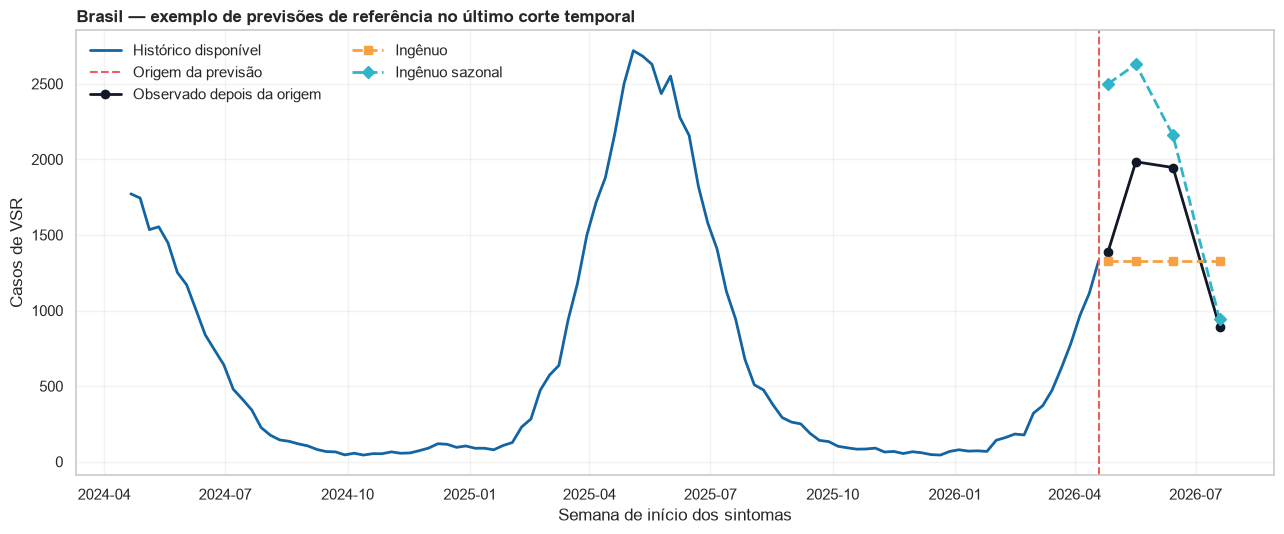


Etapa 21 concluída com sucesso.
Previsões geradas: 2,784
Linhas de auditoria: 1,392

Saídas salvas em:
..\..\execucao_local_vsr\saidas\etapa_21_referencias_simples


,modelo,horizonte_semanas,previsoes_esperadas,previsoes_disponiveis,percentual_disponivel
0,INGENUO,1,348,348,100.0
1,INGENUO,4,348,348,100.0
2,INGENUO,8,348,348,100.0
3,INGENUO,13,348,348,100.0
4,INGENUO_SAZONAL,1,348,348,100.0
5,INGENUO_SAZONAL,4,348,348,100.0
6,INGENUO_SAZONAL,8,348,348,100.0
7,INGENUO_SAZONAL,13,348,348,100.0


In [28]:
# ETAPA 21 — Referências simples de previsão

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

BASE_DIR = Path(
    "../../execucao_local_vsr"
)

ARQUIVO_PAINEL_ORIGINAL = (
    BASE_DIR
    / "dados_tratados"
    / "painel_vsr_semanal_com_maturidade.parquet"
)

ARQUIVO_PAINEL_ETAPA_20 = (
    BASE_DIR
    / "saidas"
    / "etapa_20_preparacao_modelagem"
    / "painel_modelagem_brasil_regioes.parquet"
)

ARQUIVO_CALENDARIO = (
    BASE_DIR
    / "saidas"
    / "etapa_20_preparacao_modelagem"
    / "calendario_validacao_modelagem.csv"
)

DIRETORIO_RESULTADOS = (
    BASE_DIR
    / "saidas"
    / "etapa_21_referencias_simples"
)

DIRETORIO_RESULTADOS.mkdir(parents=True, exist_ok=True)

for arquivo in [
    ARQUIVO_PAINEL_ORIGINAL,
    ARQUIVO_PAINEL_ETAPA_20,
    ARQUIVO_CALENDARIO,
]:
    if not arquivo.exists():
        raise FileNotFoundError(f"Arquivo não encontrado: {arquivo}")


# ------------------------------------------------------------
# Carregamento do painel e das chaves epidemiológicas
# ------------------------------------------------------------

painel_original = pd.read_parquet(ARQUIVO_PAINEL_ORIGINAL)

colunas_necessarias = [
    "nivel",
    "unidade",
    "regiao",
    "semana",
    "ano_epi",
    "semana_epi",
    "casos_vsr",
    "semana_madura_13s",
]

colunas_ausentes = [
    coluna
    for coluna in colunas_necessarias
    if coluna not in painel_original.columns
]

if colunas_ausentes:
    raise KeyError(
        f"Colunas ausentes no painel original: {colunas_ausentes}"
    )

painel = painel_original[colunas_necessarias].copy()

painel = painel.rename(
    columns={
        "semana": "data",
        "semana_madura_13s": "semana_madura",
    }
)

painel["data"] = pd.to_datetime(painel["data"], errors="coerce")
painel["casos_vsr"] = pd.to_numeric(
    painel["casos_vsr"],
    errors="coerce",
)

painel["ano_epi"] = pd.to_numeric(
    painel["ano_epi"],
    errors="coerce",
).astype("Int64")

painel["semana_epi"] = pd.to_numeric(
    painel["semana_epi"],
    errors="coerce",
).astype("Int64")

painel["nivel"] = (
    painel["nivel"].astype("string").str.strip().str.upper()
)

painel["unidade"] = (
    painel["unidade"].astype("string").str.strip().str.upper()
)

painel["regiao"] = (
    painel["regiao"].astype("string").str.strip().str.upper()
)

painel["semana_madura"] = (
    painel["semana_madura"]
    .astype("string")
    .str.strip()
    .str.upper()
    .isin(["1", "TRUE", "T", "SIM", "S"])
)

painel = painel.loc[
    painel["nivel"].isin(["BRASIL", "REGIAO"])
    & painel["semana_madura"]
].copy()

if painel["casos_vsr"].isna().any():
    raise ValueError(
        "Existem valores ausentes de casos_vsr no painel maduro."
    )

if painel[["ano_epi", "semana_epi"]].isna().any().any():
    raise ValueError(
        "Existem chaves epidemiológicas ausentes no painel maduro."
    )

if painel.duplicated(["nivel", "unidade", "data"]).any():
    raise ValueError(
        "Existem duplicidades em nível + unidade + data."
    )

painel = painel.sort_values(
    ["nivel", "unidade", "data"]
).reset_index(drop=True)


# ------------------------------------------------------------
# Confirmação de que a entrada é a mesma validada na Etapa 20
# ------------------------------------------------------------

painel_etapa_20 = pd.read_parquet(ARQUIVO_PAINEL_ETAPA_20)

painel_etapa_20["data"] = pd.to_datetime(
    painel_etapa_20["data"],
    errors="coerce",
)

painel_etapa_20["nivel"] = (
    painel_etapa_20["nivel"]
    .astype("string")
    .str.strip()
    .str.upper()
)

painel_etapa_20["unidade"] = (
    painel_etapa_20["unidade"]
    .astype("string")
    .str.strip()
    .str.upper()
)

comparacao_entrada = painel_etapa_20.merge(
    painel[
        [
            "nivel",
            "unidade",
            "data",
            "casos_vsr",
            "ano_epi",
            "semana_epi",
        ]
    ],
    on=["nivel", "unidade", "data", "casos_vsr"],
    how="outer",
    indicator=True,
)

if not (comparacao_entrada["_merge"] == "both").all():
    raise ValueError(
        "O painel da Etapa 21 não corresponde à entrada validada na Etapa 20."
    )


# ------------------------------------------------------------
# Calendário de validação temporal
# ------------------------------------------------------------

calendario = pd.read_csv(ARQUIVO_CALENDARIO)

calendario["data_origem"] = pd.to_datetime(
    calendario["data_origem"],
    errors="coerce",
)

calendario["data_alvo"] = pd.to_datetime(
    calendario["data_alvo"],
    errors="coerce",
)

calendario["nivel"] = (
    calendario["nivel"].astype("string").str.strip().str.upper()
)

calendario["unidade"] = (
    calendario["unidade"].astype("string").str.strip().str.upper()
)

if calendario[["data_origem", "data_alvo"]].isna().any().any():
    raise ValueError(
        "Existem datas inválidas no calendário de validação."
    )


# ------------------------------------------------------------
# Construção das referências de previsão
# ------------------------------------------------------------

previsoes = []
auditoria = []

for linha in calendario.itertuples(index=False):

    nivel = linha.nivel
    unidade = linha.unidade
    regiao = linha.regiao
    data_origem = linha.data_origem
    data_alvo = linha.data_alvo
    horizonte = linha.horizonte_semanas
    observado = linha.casos_observados_alvo

    serie = painel.loc[
        (painel["nivel"] == nivel)
        & (painel["unidade"] == unidade)
    ].copy()

    treino = serie.loc[
        serie["data"] <= data_origem
    ].copy()

    if treino.empty:
        raise ValueError(
            f"Não há treino disponível para {nivel} - {unidade} "
            f"na origem {data_origem.date()}."
        )

    ultimo_observado = treino.iloc[-1]

    alvo = serie.loc[
        serie["data"] == data_alvo
    ].copy()

    if len(alvo) != 1:
        raise ValueError(
            f"Não foi possível identificar o alvo de {nivel} - {unidade} "
            f"na data {data_alvo.date()}."
        )

    ano_epi_alvo = int(alvo["ano_epi"].iloc[0])
    semana_epi_alvo = int(alvo["semana_epi"].iloc[0])

    referencia_sazonal = treino.loc[
        (treino["ano_epi"] == ano_epi_alvo - 1)
        & (treino["semana_epi"] == semana_epi_alvo)
    ].copy()

    if len(referencia_sazonal) > 1:
        raise ValueError(
            f"Mais de uma referência sazonal encontrada para "
            f"{nivel} - {unidade}, alvo {data_alvo.date()}."
        )

    previsao_ingenua = float(ultimo_observado["casos_vsr"])

    if len(referencia_sazonal) == 1:
        previsao_sazonal = float(
            referencia_sazonal["casos_vsr"].iloc[0]
        )
        data_referencia_sazonal = (
            referencia_sazonal["data"].iloc[0]
        )
        referencia_sazonal_disponivel = True
    else:
        previsao_sazonal = np.nan
        data_referencia_sazonal = pd.NaT
        referencia_sazonal_disponivel = False

    previsoes.extend(
        [
            {
                "nivel": nivel,
                "unidade": unidade,
                "regiao": regiao,
                "modelo": "INGENUO",
                "data_origem": data_origem,
                "horizonte_semanas": horizonte,
                "data_alvo": data_alvo,
                "casos_observados": observado,
                "previsao": previsao_ingenua,
            },
            {
                "nivel": nivel,
                "unidade": unidade,
                "regiao": regiao,
                "modelo": "INGENUO_SAZONAL",
                "data_origem": data_origem,
                "horizonte_semanas": horizonte,
                "data_alvo": data_alvo,
                "casos_observados": observado,
                "previsao": previsao_sazonal,
            },
        ]
    )

    auditoria.append(
        {
            "nivel": nivel,
            "unidade": unidade,
            "regiao": regiao,
            "data_origem": data_origem,
            "horizonte_semanas": horizonte,
            "data_alvo": data_alvo,
            "casos_observados": observado,
            "semanas_treino_efetivas": len(treino),
            "data_ultimo_observado": ultimo_observado["data"],
            "previsao_ingenua": previsao_ingenua,
            "ano_epi_alvo": ano_epi_alvo,
            "semana_epi_alvo": semana_epi_alvo,
            "data_referencia_sazonal": data_referencia_sazonal,
            "referencia_sazonal_disponivel": referencia_sazonal_disponivel,
            "previsao_ingenua_sazonal": previsao_sazonal,
        }
    )

previsoes = pd.DataFrame(previsoes)
auditoria = pd.DataFrame(auditoria)


# ------------------------------------------------------------
# Validações das previsões geradas
# ------------------------------------------------------------

if len(previsoes) != 2 * len(calendario):
    raise ValueError(
        "A quantidade de previsões não corresponde a dois modelos "
        "por linha do calendário."
    )

if previsoes.duplicated(
    [
        "nivel",
        "unidade",
        "modelo",
        "data_origem",
        "horizonte_semanas",
    ]
).any():
    raise ValueError(
        "Foram encontradas previsões duplicadas."
    )

if previsoes.loc[
    previsoes["modelo"] == "INGENUO",
    "previsao"
].isna().any():
    raise ValueError(
        "A referência ingênua possui previsões ausentes."
    )

resumo_disponibilidade = (
    previsoes
    .assign(previsao_disponivel=previsoes["previsao"].notna())
    .groupby(["modelo", "horizonte_semanas"])
    .agg(
        previsoes_esperadas=("previsao", "size"),
        previsoes_disponiveis=("previsao_disponivel", "sum"),
    )
    .reset_index()
)

resumo_disponibilidade["percentual_disponivel"] = (
    100
    * resumo_disponibilidade["previsoes_disponiveis"]
    / resumo_disponibilidade["previsoes_esperadas"]
)


# ------------------------------------------------------------
# Gráfico ilustrativo: último corte temporal do Brasil
# ------------------------------------------------------------

ultimo_corte_brasil = (
    calendario.loc[
        (calendario["nivel"] == "BRASIL")
        & (calendario["unidade"] == "BRASIL"),
        "data_origem",
    ]
    .max()
)

serie_brasil = painel.loc[
    (painel["nivel"] == "BRASIL")
    & (painel["unidade"] == "BRASIL")
].copy()

historico_exemplo = serie_brasil.loc[
    (serie_brasil["data"] >= ultimo_corte_brasil - pd.Timedelta(weeks=104))
    & (serie_brasil["data"] <= ultimo_corte_brasil)
].copy()

exemplo = previsoes.loc[
    (previsoes["nivel"] == "BRASIL")
    & (previsoes["unidade"] == "BRASIL")
    & (previsoes["data_origem"] == ultimo_corte_brasil)
].copy()

previsoes_exemplo = exemplo.pivot(
    index="data_alvo",
    columns="modelo",
    values="previsao",
).reset_index()

observados_exemplo = (
    exemplo[
        ["data_alvo", "casos_observados"]
    ]
    .drop_duplicates()
    .sort_values("data_alvo")
)

fig, ax = plt.subplots(figsize=(13, 5.5))

ax.plot(
    historico_exemplo["data"],
    historico_exemplo["casos_vsr"],
    color="#1264A3",
    linewidth=2,
    label="Histórico disponível",
)

ax.axvline(
    ultimo_corte_brasil,
    color="#E85F5C",
    linestyle="--",
    linewidth=1.5,
    label="Origem da previsão",
)

ax.plot(
    observados_exemplo["data_alvo"],
    observados_exemplo["casos_observados"],
    "o-",
    color="#111827",
    linewidth=2,
    label="Observado depois da origem",
)

ax.plot(
    previsoes_exemplo["data_alvo"],
    previsoes_exemplo["INGENUO"],
    "s--",
    color="#F6A041",
    linewidth=2,
    label="Ingênuo",
)

ax.plot(
    previsoes_exemplo["data_alvo"],
    previsoes_exemplo["INGENUO_SAZONAL"],
    "D--",
    color="#32B4C8",
    linewidth=2,
    label="Ingênuo sazonal",
)

ax.set_title(
    "Brasil — exemplo de previsões de referência no último corte temporal",
    loc="left",
    fontweight="bold",
)

ax.set_xlabel("Semana de início dos sintomas")
ax.set_ylabel("Casos de VSR")
ax.grid(alpha=0.25)
ax.legend(frameon=False, ncol=2)
fig.tight_layout()

fig.savefig(
    DIRETORIO_RESULTADOS
    / "exemplo_previsao_referencias_brasil.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# Salvamento dos resultados
# ------------------------------------------------------------

previsoes.to_csv(
    DIRETORIO_RESULTADOS
    / "previsoes_referencias_simples.csv",
    index=False,
)

auditoria.to_csv(
    DIRETORIO_RESULTADOS
    / "auditoria_referencias_simples.csv",
    index=False,
)

resumo_disponibilidade.to_csv(
    DIRETORIO_RESULTADOS
    / "resumo_disponibilidade_referencias.csv",
    index=False,
)

print("\nEtapa 21 concluída com sucesso.")
print(f"Previsões geradas: {len(previsoes):,}")
print(f"Linhas de auditoria: {len(auditoria):,}")
print(f"\nSaídas salvas em:\n{DIRETORIO_RESULTADOS}")

display(resumo_disponibilidade)

## Etapa 22 — Métricas de erro das referências

Nesta etapa, calcularemos os erros das previsões ingênua e ingênua sazonal para cada série e horizonte de previsão.

O objetivo é comparar as referências de forma justa ao longo de todos os cortes temporais. Serão utilizados MAE, que mede o erro médio em número de casos; RMSE, que dá maior peso aos erros grandes; e MASE, que coloca o erro em uma escala sazonal comparável entre Brasil e regiões.

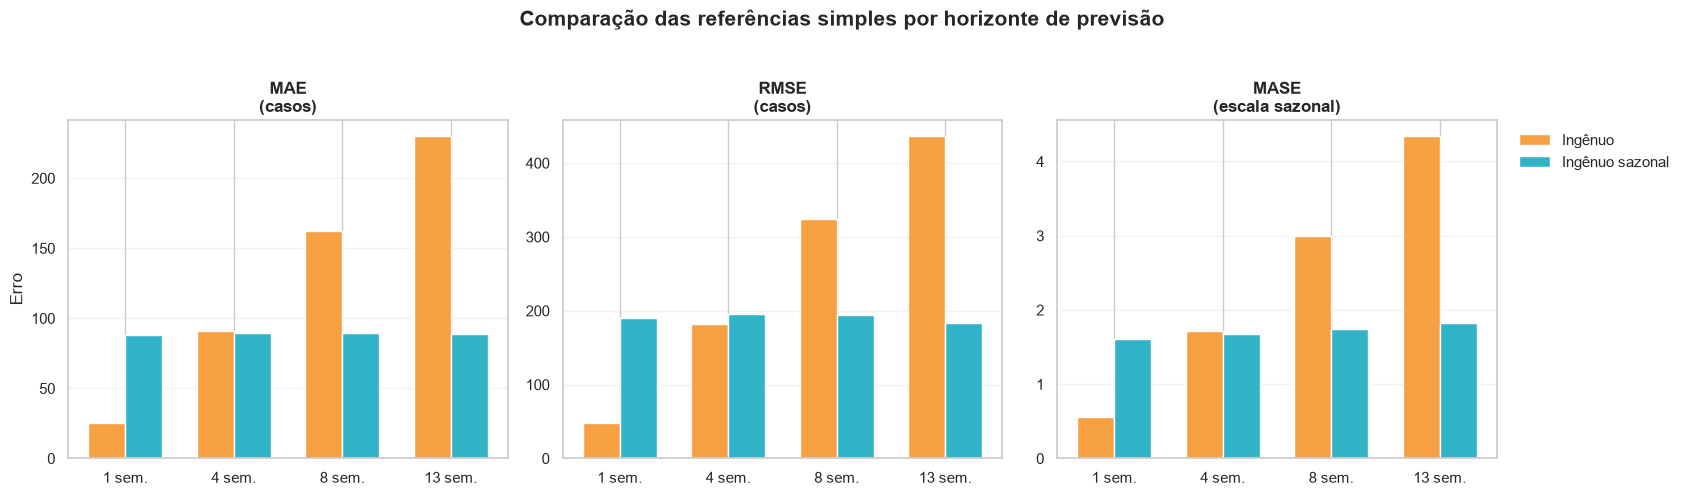


Etapa 22 concluída com sucesso.
Escalas MASE calculadas: 348
Erros individuais calculados: 2,784
Métricas por série: 48
Métricas agregadas: 8

Saídas salvas em:
..\..\execucao_local_vsr\saidas\etapa_22_metricas_referencias


,modelo,horizonte_semanas,avaliacoes,mae,rmse,mase
0,INGENUO,1,348,25.586207,47.652478,0.554340
1,INGENUO_SAZONAL,1,348,87.948276,190.766979,1.610141
2,INGENUO,4,348,91.189655,181.879160,1.719803
3,INGENUO_SAZONAL,4,348,89.701149,195.282642,1.669567
4,INGENUO,8,348,162.155172,323.963289,3.000758
5,INGENUO_SAZONAL,8,348,89.787356,193.847671,1.741190
6,INGENUO,13,348,229.867816,436.168855,4.338041
7,INGENUO_SAZONAL,13,348,89.114943,184.017818,1.822525


,modelo,horizonte_semanas,avaliacoes,mae,rmse,mase,ranking_mae,ranking_rmse,ranking_mase
0,INGENUO,1,348,25.586207,47.652478,0.554340,1,1,1
1,INGENUO_SAZONAL,1,348,87.948276,190.766979,1.610141,2,2,2
2,INGENUO,4,348,91.189655,181.879160,1.719803,2,1,2
3,INGENUO_SAZONAL,4,348,89.701149,195.282642,1.669567,1,2,1
4,INGENUO,8,348,162.155172,323.963289,3.000758,2,2,2
5,INGENUO_SAZONAL,8,348,89.787356,193.847671,1.741190,1,1,1
6,INGENUO,13,348,229.867816,436.168855,4.338041,2,2,2
7,INGENUO_SAZONAL,13,348,89.114943,184.017818,1.822525,1,1,1


In [29]:
# ETAPA 22 — Cálculo das métricas de erro das referências

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

BASE_DIR = Path(
    "../../execucao_local_vsr"
)

ARQUIVO_PAINEL_ORIGINAL = (
    BASE_DIR
    / "dados_tratados"
    / "painel_vsr_semanal_com_maturidade.parquet"
)

ARQUIVO_PREVISOES = (
    BASE_DIR
    / "saidas"
    / "etapa_21_referencias_simples"
    / "previsoes_referencias_simples.csv"
)

DIRETORIO_RESULTADOS = (
    BASE_DIR
    / "saidas"
    / "etapa_22_metricas_referencias"
)

DIRETORIO_RESULTADOS.mkdir(parents=True, exist_ok=True)

for arquivo in [ARQUIVO_PAINEL_ORIGINAL, ARQUIVO_PREVISOES]:
    if not arquivo.exists():
        raise FileNotFoundError(f"Arquivo não encontrado: {arquivo}")


# ------------------------------------------------------------
# Leitura das previsões produzidas na Etapa 21
# ------------------------------------------------------------

previsoes = pd.read_csv(ARQUIVO_PREVISOES)

for coluna in ["data_origem", "data_alvo"]:
    previsoes[coluna] = pd.to_datetime(
        previsoes[coluna],
        errors="coerce",
    )

previsoes["casos_observados"] = pd.to_numeric(
    previsoes["casos_observados"],
    errors="coerce",
)

previsoes["previsao"] = pd.to_numeric(
    previsoes["previsao"],
    errors="coerce",
)

if previsoes[
    ["data_origem", "data_alvo", "casos_observados", "previsao"]
].isna().any().any():
    raise ValueError(
        "Existem valores ausentes nas previsões da Etapa 21."
    )

if len(previsoes) != 2784:
    raise ValueError(
        f"Foram encontradas {len(previsoes):,} previsões. "
        "O esperado é 2.784 previsões."
    )


# ------------------------------------------------------------
# Leitura da base semanal para cálculo da escala do MASE
# ------------------------------------------------------------

painel_original = pd.read_parquet(ARQUIVO_PAINEL_ORIGINAL)

colunas_necessarias = [
    "nivel",
    "unidade",
    "regiao",
    "semana",
    "ano_epi",
    "semana_epi",
    "casos_vsr",
    "semana_madura_13s",
]

colunas_ausentes = [
    coluna
    for coluna in colunas_necessarias
    if coluna not in painel_original.columns
]

if colunas_ausentes:
    raise KeyError(
        f"Colunas ausentes no painel original: {colunas_ausentes}"
    )

painel = painel_original[colunas_necessarias].copy()

painel = painel.rename(
    columns={
        "semana": "data",
        "semana_madura_13s": "semana_madura",
    }
)

painel["data"] = pd.to_datetime(
    painel["data"],
    errors="coerce",
)

painel["casos_vsr"] = pd.to_numeric(
    painel["casos_vsr"],
    errors="coerce",
)

painel["ano_epi"] = pd.to_numeric(
    painel["ano_epi"],
    errors="coerce",
).astype("Int64")

painel["semana_epi"] = pd.to_numeric(
    painel["semana_epi"],
    errors="coerce",
).astype("Int64")

painel["nivel"] = (
    painel["nivel"].astype("string").str.strip().str.upper()
)

painel["unidade"] = (
    painel["unidade"].astype("string").str.strip().str.upper()
)

painel["regiao"] = (
    painel["regiao"].astype("string").str.strip().str.upper()
)

if pd.api.types.is_bool_dtype(painel["semana_madura"]):
    painel["semana_madura"] = painel["semana_madura"].fillna(False)
else:
    painel["semana_madura"] = (
        painel["semana_madura"]
        .astype("string")
        .str.strip()
        .str.upper()
        .isin(["1", "TRUE", "T", "SIM", "S"])
    )

painel = painel.loc[
    painel["nivel"].isin(["BRASIL", "REGIAO"])
    & painel["semana_madura"]
].copy()

if painel["casos_vsr"].isna().any():
    raise ValueError(
        "Existem casos ausentes no painel maduro usado para calcular MASE."
    )

if painel[["ano_epi", "semana_epi"]].isna().any().any():
    raise ValueError(
        "Existem chaves epidemiológicas ausentes no painel maduro."
    )


# ------------------------------------------------------------
# Escala sazonal do MASE para cada origem temporal
# ------------------------------------------------------------

def calcular_escala_mase_sazonal(treino):
    treino = treino.sort_values("data").copy()

    if treino.duplicated(["ano_epi", "semana_epi"]).any():
        raise ValueError(
            "Há duplicidade de chave epidemiológica na série de treino."
        )

    valores_por_semana = {
        (int(linha.ano_epi), int(linha.semana_epi)): float(linha.casos_vsr)
        for linha in treino.itertuples(index=False)
    }

    erros_sazonais = []

    for linha in treino.itertuples(index=False):
        chave_anterior = (
            int(linha.ano_epi) - 1,
            int(linha.semana_epi),
        )

        if chave_anterior in valores_por_semana:
            erro = abs(
                float(linha.casos_vsr)
                - valores_por_semana[chave_anterior]
            )
            erros_sazonais.append(erro)

    if len(erros_sazonais) == 0:
        return np.nan, 0

    return float(np.mean(erros_sazonais)), len(erros_sazonais)


origens = (
    previsoes[
        ["nivel", "unidade", "regiao", "data_origem"]
    ]
    .drop_duplicates()
    .sort_values(["nivel", "unidade", "data_origem"])
)

escalas_mase = []

for linha in origens.itertuples(index=False):

    treino = painel.loc[
        (painel["nivel"] == linha.nivel)
        & (painel["unidade"] == linha.unidade)
        & (painel["data"] <= linha.data_origem)
    ].copy()

    escala, comparacoes_sazonais = calcular_escala_mase_sazonal(
        treino
    )

    escalas_mase.append(
        {
            "nivel": linha.nivel,
            "unidade": linha.unidade,
            "regiao": linha.regiao,
            "data_origem": linha.data_origem,
            "semanas_treino": len(treino),
            "comparacoes_sazonais_treino": comparacoes_sazonais,
            "escala_mase_sazonal": escala,
        }
    )

escalas_mase = pd.DataFrame(escalas_mase)

if escalas_mase["escala_mase_sazonal"].isna().any():
    raise ValueError(
        "Não foi possível calcular a escala sazonal do MASE "
        "para alguma origem temporal."
    )

if (escalas_mase["escala_mase_sazonal"] <= 0).any():
    raise ValueError(
        "Foi encontrada escala MASE menor ou igual a zero."
    )


# ------------------------------------------------------------
# Cálculo dos erros individuais
# ------------------------------------------------------------

erros = previsoes.merge(
    escalas_mase[
        [
            "nivel",
            "unidade",
            "data_origem",
            "semanas_treino",
            "comparacoes_sazonais_treino",
            "escala_mase_sazonal",
        ]
    ],
    on=["nivel", "unidade", "data_origem"],
    how="left",
    validate="many_to_one",
)

if erros["escala_mase_sazonal"].isna().any():
    raise ValueError(
        "Existem previsões sem escala MASE correspondente."
    )

erros["erro"] = (
    erros["previsao"]
    - erros["casos_observados"]
)

erros["erro_absoluto"] = erros["erro"].abs()

erros["erro_quadratico"] = erros["erro"] ** 2

erros["mase_individual"] = (
    erros["erro_absoluto"]
    / erros["escala_mase_sazonal"]
)


# ------------------------------------------------------------
# Métricas por série, modelo e horizonte
# ------------------------------------------------------------

metricas_por_serie = (
    erros
    .groupby(
        [
            "nivel",
            "unidade",
            "regiao",
            "modelo",
            "horizonte_semanas",
        ],
        dropna=False,
    )
    .agg(
        avaliacoes=("erro_absoluto", "size"),
        mae=("erro_absoluto", "mean"),
        rmse=(
            "erro_quadratico",
            lambda valores: float(np.sqrt(np.mean(valores))),
        ),
        mase=("mase_individual", "mean"),
    )
    .reset_index()
)

metricas_agregadas = (
    erros
    .groupby(
        ["modelo", "horizonte_semanas"],
        dropna=False,
    )
    .agg(
        avaliacoes=("erro_absoluto", "size"),
        mae=("erro_absoluto", "mean"),
        rmse=(
            "erro_quadratico",
            lambda valores: float(np.sqrt(np.mean(valores))),
        ),
        mase=("mase_individual", "mean"),
    )
    .reset_index()
)

metricas_agregadas = metricas_agregadas.sort_values(
    ["horizonte_semanas", "modelo"]
).reset_index(drop=True)

ranking_referencias = metricas_agregadas.copy()

ranking_referencias["ranking_mae"] = (
    ranking_referencias
    .groupby("horizonte_semanas")["mae"]
    .rank(method="dense", ascending=True)
    .astype(int)
)

ranking_referencias["ranking_rmse"] = (
    ranking_referencias
    .groupby("horizonte_semanas")["rmse"]
    .rank(method="dense", ascending=True)
    .astype(int)
)

ranking_referencias["ranking_mase"] = (
    ranking_referencias
    .groupby("horizonte_semanas")["mase"]
    .rank(method="dense", ascending=True)
    .astype(int)
)


# ------------------------------------------------------------
# Gráfico comparativo das referências
# ------------------------------------------------------------

metricas_grafico = metricas_agregadas.copy()

modelos = ["INGENUO", "INGENUO_SAZONAL"]
horizontes = [1, 4, 8, 13]

rotulos_modelos = {
    "INGENUO": "Ingênuo",
    "INGENUO_SAZONAL": "Ingênuo sazonal",
}

cores_modelos = {
    "INGENUO": "#F6A041",
    "INGENUO_SAZONAL": "#32B4C8",
}

fig, eixos = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(17, 4.8),
)

metricas_plot = [
    ("mae", "MAE\n(casos)"),
    ("rmse", "RMSE\n(casos)"),
    ("mase", "MASE\n(escala sazonal)"),
]

largura = 0.34
posicoes = np.arange(len(horizontes))

for eixo, (coluna, titulo) in zip(eixos, metricas_plot):

    for indice, modelo in enumerate(modelos):

        valores = (
            metricas_grafico
            .loc[
                metricas_grafico["modelo"] == modelo,
                ["horizonte_semanas", coluna],
            ]
            .set_index("horizonte_semanas")
            .reindex(horizontes)[coluna]
        )

        deslocamento = (
            posicoes
            + (indice - 0.5) * largura
        )

        eixo.bar(
            deslocamento,
            valores,
            width=largura,
            label=rotulos_modelos[modelo],
            color=cores_modelos[modelo],
        )

    eixo.set_title(titulo, fontweight="bold")
    eixo.set_xticks(posicoes)
    eixo.set_xticklabels(
        [f"{h} sem." for h in horizontes]
    )
    eixo.grid(axis="y", alpha=0.25)

eixos[0].set_ylabel("Erro")
eixos[2].legend(
    frameon=False,
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
)

fig.suptitle(
    "Comparação das referências simples por horizonte de previsão",
    fontsize=15,
    fontweight="bold",
    y=1.03,
)

fig.tight_layout()

fig.savefig(
    DIRETORIO_RESULTADOS
    / "comparacao_metricas_referencias.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# Salvamento das saídas
# ------------------------------------------------------------

escalas_mase.to_csv(
    DIRETORIO_RESULTADOS
    / "escalas_mase_por_origem.csv",
    index=False,
)

erros.to_csv(
    DIRETORIO_RESULTADOS
    / "erros_individuais_referencias.csv",
    index=False,
)

metricas_por_serie.to_csv(
    DIRETORIO_RESULTADOS
    / "metricas_por_serie_modelo_horizonte.csv",
    index=False,
)

metricas_agregadas.to_csv(
    DIRETORIO_RESULTADOS
    / "metricas_agregadas_referencias.csv",
    index=False,
)

ranking_referencias.to_csv(
    DIRETORIO_RESULTADOS
    / "ranking_referencias_por_horizonte.csv",
    index=False,
)

print("\nEtapa 22 concluída com sucesso.")
print(f"Escalas MASE calculadas: {len(escalas_mase):,}")
print(f"Erros individuais calculados: {len(erros):,}")
print(f"Métricas por série: {len(metricas_por_serie):,}")
print(f"Métricas agregadas: {len(metricas_agregadas):,}")
print(f"\nSaídas salvas em:\n{DIRETORIO_RESULTADOS}")

display(metricas_agregadas)
display(ranking_referencias)

## Etapa 23 — Modelos ETS com sazonalidade anual

Nesta etapa, ajustaremos modelos de suavização exponencial para Brasil e regiões, utilizando nível, tendência e sazonalidade anual.

O objetivo é verificar se modelos ETS conseguem combinar o comportamento recente da série com o padrão sazonal observado, superando as referências ingênua e ingênua sazonal nos mesmos cortes temporais.

Processando origem 1 de 348 (0.0 minutos decorridos).


Processando origem 20 de 348 (0.5 minutos decorridos).


Processando origem 40 de 348 (1.1 minutos decorridos).


Processando origem 60 de 348 (1.8 minutos decorridos).


Processando origem 80 de 348 (2.4 minutos decorridos).


Processando origem 100 de 348 (3.0 minutos decorridos).


... (10 outputs left out)

Processando origem 320 de 348 (9.1 minutos decorridos).


Processando origem 340 de 348 (9.7 minutos decorridos).


Processando origem 348 de 348 (9.9 minutos decorridos).


C:\Users\joanc\AppData\Local\Temp\ipykernel_16488\557550988.py:478: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  >= ultimo_corte_brasil - pd.Timedelta(weeks=104)


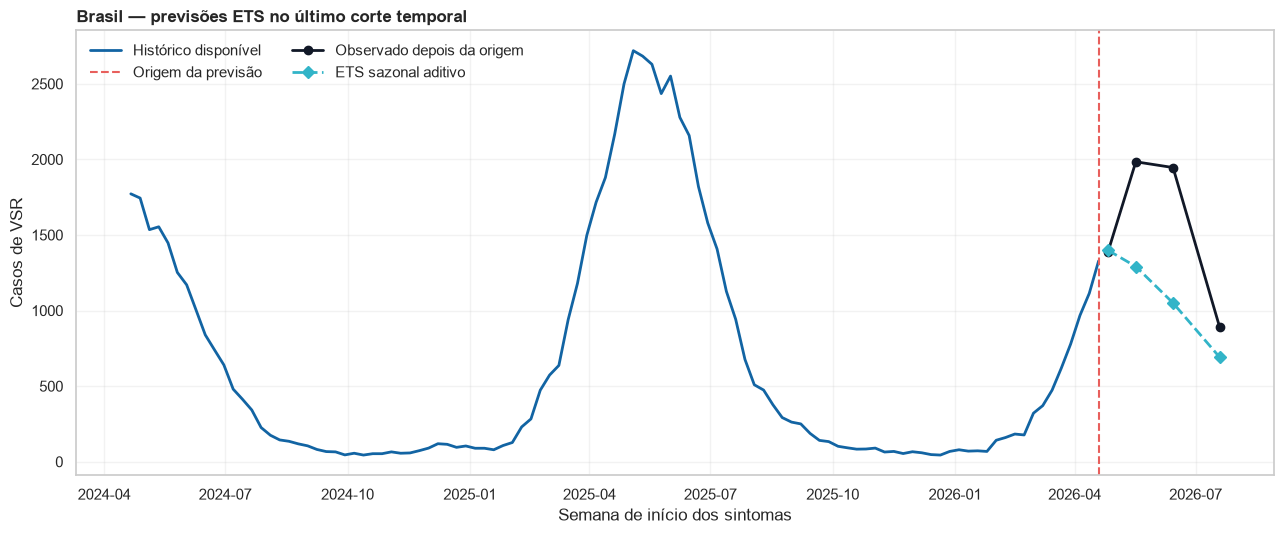


Etapa 23 concluída.
Origens temporais: 348
Ajustes ETS previstos: 1,044
Previsões ETS disponíveis: 1,644

Saídas salvas em:
..\..\execucao_local_vsr\saidas\etapa_23_modelos_ets


status_final,modelo,CONVERGIU,NAO_CONVERGIU_APOS_REAJUSTE
0,ETS_SAZONAL_ADITIVO,314,34
1,ETS_TENDENCIA_ADITIVA,77,271
2,ETS_TENDENCIA_AMORTECIDA,20,328


,modelo,horizonte_semanas,previsoes_disponiveis,previsoes_ajustadas_nao_negativas,previsoes_esperadas,percentual_disponivel
0,ETS_SAZONAL_ADITIVO,1,314,5,348,90.229885
1,ETS_SAZONAL_ADITIVO,4,314,5,348,90.229885
2,ETS_SAZONAL_ADITIVO,8,314,5,348,90.229885
3,ETS_SAZONAL_ADITIVO,13,314,2,348,90.229885
4,ETS_TENDENCIA_ADITIVA,1,77,1,348,22.126437
5,ETS_TENDENCIA_ADITIVA,4,77,1,348,22.126437
6,ETS_TENDENCIA_ADITIVA,8,77,0,348,22.126437
7,ETS_TENDENCIA_ADITIVA,13,77,2,348,22.126437
8,ETS_TENDENCIA_AMORTECIDA,1,20,1,348,5.747126
9,ETS_TENDENCIA_AMORTECIDA,4,20,2,348,5.747126


In [30]:
# ETAPA 23 — Modelos ETS com sazonalidade anual e auditoria de convergência

import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from statsmodels.tools.sm_exceptions import ConvergenceWarning
from statsmodels.tsa.holtwinters import ExponentialSmoothing

BASE_DIR = Path("../../execucao_local_vsr")

ARQUIVO_PAINEL = (
    BASE_DIR
    / "saidas"
    / "etapa_20_preparacao_modelagem"
    / "painel_modelagem_brasil_regioes.parquet"
)

ARQUIVO_CALENDARIO = (
    BASE_DIR
    / "saidas"
    / "etapa_20_preparacao_modelagem"
    / "calendario_validacao_modelagem.csv"
)

DIRETORIO_RESULTADOS = (
    BASE_DIR
    / "saidas"
    / "etapa_23_modelos_ets"
)

DIRETORIO_RESULTADOS.mkdir(parents=True, exist_ok=True)

for arquivo in [ARQUIVO_PAINEL, ARQUIVO_CALENDARIO]:
    if not arquivo.exists():
        raise FileNotFoundError(f"Arquivo não encontrado: {arquivo}")

painel = pd.read_parquet(ARQUIVO_PAINEL)
calendario = pd.read_csv(ARQUIVO_CALENDARIO)

painel["data"] = pd.to_datetime(painel["data"], errors="coerce")
calendario["data_origem"] = pd.to_datetime(
    calendario["data_origem"],
    errors="coerce",
)
calendario["data_alvo"] = pd.to_datetime(
    calendario["data_alvo"],
    errors="coerce",
)

for base in [painel, calendario]:
    base["nivel"] = base["nivel"].astype("string").str.strip().str.upper()
    base["unidade"] = base["unidade"].astype("string").str.strip().str.upper()

painel["casos_vsr"] = pd.to_numeric(
    painel["casos_vsr"],
    errors="coerce",
)

if painel[["data", "casos_vsr"]].isna().any().any():
    raise ValueError("Existem datas ou casos ausentes no painel de modelagem.")

if calendario[
    ["data_origem", "data_alvo", "casos_observados_alvo"]
].isna().any().any():
    raise ValueError("Existem valores ausentes no calendário de validação.")

PERIODO_SAZONAL = 52
HORIZONTES = sorted(calendario["horizonte_semanas"].unique())
HORIZONTE_MAXIMO = int(max(HORIZONTES))

CONFIGURACOES_ETS = {
    "ETS_SAZONAL_ADITIVO": {
        "trend": None,
        "damped_trend": False,
        "seasonal": "add",
    },
    "ETS_TENDENCIA_ADITIVA": {
        "trend": "add",
        "damped_trend": False,
        "seasonal": "add",
    },
    "ETS_TENDENCIA_AMORTECIDA": {
        "trend": "add",
        "damped_trend": True,
        "seasonal": "add",
    },
}

origens = (
    calendario[
        [
            "nivel",
            "unidade",
            "regiao",
            "data_origem",
            "semanas_treino",
        ]
    ]
    .drop_duplicates()
    .sort_values(["nivel", "unidade", "data_origem"])
    .reset_index(drop=True)
)

regularidade = []

for (nivel, unidade), serie in painel.groupby(["nivel", "unidade"]):
    diferencas = (
        serie.sort_values("data")["data"]
        .diff()
        .dt.days
        .dropna()
    )

    regularidade.append(
        {
            "nivel": nivel,
            "unidade": unidade,
            "semanas": len(serie),
            "primeira_semana": serie["data"].min(),
            "ultima_semana": serie["data"].max(),
            "intervalo_minimo_dias": diferencas.min(),
            "intervalo_maximo_dias": diferencas.max(),
            "serie_semanal_regular": diferencas.eq(7).all(),
        }
    )

regularidade = pd.DataFrame(regularidade)

if not regularidade["serie_semanal_regular"].all():
    display(regularidade.loc[~regularidade["serie_semanal_regular"]])
    raise ValueError("Foram encontradas lacunas nas séries semanais.")

def ajustar_ets_com_auditoria(valores_treino, parametros):
    tentativas = [
        {
            "numero_tentativa": 1,
            "otimizador": "padrão",
            "argumentos_fit": {
                "optimized": True,
                "remove_bias": False,
                "use_brute": True,
            },
        },
        {
            "numero_tentativa": 2,
            "otimizador": "L-BFGS-B",
            "argumentos_fit": {
                "optimized": True,
                "remove_bias": False,
                "use_brute": False,
                "method": "L-BFGS-B",
                "minimize_kwargs": {
                    "options": {
                        "maxiter": 2000,
                    }
                },
            },
        },
    ]

    historico = []

    for tentativa in tentativas:
        try:
            modelo = ExponentialSmoothing(
                valores_treino,
                trend=parametros["trend"],
                damped_trend=parametros["damped_trend"],
                seasonal=parametros["seasonal"],
                seasonal_periods=PERIODO_SAZONAL,
                initialization_method="estimated",
            )

            with warnings.catch_warnings(record=True) as avisos:
                warnings.simplefilter("always")
                ajuste = modelo.fit(**tentativa["argumentos_fit"])

            avisos_convergencia = [
                aviso
                for aviso in avisos
                if issubclass(aviso.category, ConvergenceWarning)
            ]

            retorno_otimizador = getattr(ajuste, "mle_retvals", {})
            sucesso_otimizador = np.nan

            if isinstance(retorno_otimizador, dict):
                sucesso_otimizador = retorno_otimizador.get(
                    "success",
                    np.nan,
                )

            convergiu = (
                len(avisos_convergencia) == 0
                and sucesso_otimizador is not False
            )

            mensagens = " | ".join(
                sorted(
                    {
                        str(aviso.message)
                        for aviso in avisos
                    }
                )
            )

            historico.append(
                {
                    "numero_tentativa": tentativa["numero_tentativa"],
                    "otimizador": tentativa["otimizador"],
                    "status_tentativa": (
                        "CONVERGIU"
                        if convergiu
                        else "NAO_CONVERGIU"
                    ),
                    "quantidade_avisos": len(avisos),
                    "quantidade_avisos_convergencia": len(
                        avisos_convergencia
                    ),
                    "sucesso_reportado_otimizador": sucesso_otimizador,
                    "mensagens_avisos": mensagens,
                    "mensagem_erro": None,
                }
            )

            if convergiu:
                return ajuste, historico

        except Exception as erro:
            historico.append(
                {
                    "numero_tentativa": tentativa["numero_tentativa"],
                    "otimizador": tentativa["otimizador"],
                    "status_tentativa": "ERRO",
                    "quantidade_avisos": 0,
                    "quantidade_avisos_convergencia": 0,
                    "sucesso_reportado_otimizador": np.nan,
                    "mensagens_avisos": None,
                    "mensagem_erro": str(erro),
                }
            )

    return None, historico

previsoes_ets = []
auditoria_ets = []
auditoria_tentativas = []

inicio_execucao = time.time()
total_origens = len(origens)

for indice_origem, origem in origens.iterrows():
    nivel = origem["nivel"]
    unidade = origem["unidade"]
    regiao = origem["regiao"]
    data_origem = origem["data_origem"]
    semanas_treino_esperadas = int(origem["semanas_treino"])

    if (
        indice_origem == 0
        or (indice_origem + 1) % 20 == 0
        or (indice_origem + 1) == total_origens
    ):
        minutos = (time.time() - inicio_execucao) / 60
        print(
            f"Processando origem {indice_origem + 1:,} de "
            f"{total_origens:,} "
            f"({minutos:.1f} minutos decorridos)."
        )

    serie = painel.loc[
        (painel["nivel"] == nivel)
        & (painel["unidade"] == unidade)
    ].sort_values("data")

    treino = serie.loc[serie["data"] <= data_origem].copy()

    if len(treino) != semanas_treino_esperadas:
        raise ValueError(
            f"Treino inconsistente em {nivel} - {unidade}, "
            f"origem {data_origem.date()}."
        )

    alvos_origem = calendario.loc[
        (calendario["nivel"] == nivel)
        & (calendario["unidade"] == unidade)
        & (calendario["data_origem"] == data_origem)
    ].sort_values("horizonte_semanas")

    valores_treino = treino["casos_vsr"].astype(float).to_numpy()

    for nome_modelo, parametros in CONFIGURACOES_ETS.items():
        ajuste, tentativas = ajustar_ets_com_auditoria(
            valores_treino,
            parametros,
        )

        for tentativa in tentativas:
            auditoria_tentativas.append(
                {
                    "nivel": nivel,
                    "unidade": unidade,
                    "regiao": regiao,
                    "modelo": nome_modelo,
                    "data_origem": data_origem,
                    "semanas_treino": len(treino),
                    **tentativa,
                }
            )

        if ajuste is None:
            auditoria_ets.append(
                {
                    "nivel": nivel,
                    "unidade": unidade,
                    "regiao": regiao,
                    "modelo": nome_modelo,
                    "data_origem": data_origem,
                    "semanas_treino": len(treino),
                    "status_final": "NAO_CONVERGIU_APOS_REAJUSTE",
                    "tentativa_escolhida": np.nan,
                    "aic": np.nan,
                    "bic": np.nan,
                    "sse": np.nan,
                    "previsao_gerada": False,
                    "mensagem_final": tentativas[-1]["mensagem_erro"],
                }
            )
            continue

        try:
            previsao_completa = np.asarray(
                ajuste.forecast(HORIZONTE_MAXIMO),
                dtype=float,
            )

            if len(previsao_completa) != HORIZONTE_MAXIMO:
                raise ValueError("Quantidade inesperada de horizontes.")

            if not np.isfinite(previsao_completa).all():
                raise ValueError("O ajuste gerou previsão não finita.")

            tentativa_escolhida = [
                item["numero_tentativa"]
                for item in tentativas
                if item["status_tentativa"] == "CONVERGIU"
            ][0]

            auditoria_ets.append(
                {
                    "nivel": nivel,
                    "unidade": unidade,
                    "regiao": regiao,
                    "modelo": nome_modelo,
                    "data_origem": data_origem,
                    "semanas_treino": len(treino),
                    "status_final": "CONVERGIU",
                    "tentativa_escolhida": tentativa_escolhida,
                    "aic": getattr(ajuste, "aic", np.nan),
                    "bic": getattr(ajuste, "bic", np.nan),
                    "sse": getattr(ajuste, "sse", np.nan),
                    "previsao_gerada": True,
                    "mensagem_final": None,
                }
            )

            for alvo in alvos_origem.itertuples(index=False):
                horizonte = int(alvo.horizonte_semanas)
                previsao_bruta = float(
                    previsao_completa[horizonte - 1]
                )

                previsoes_ets.append(
                    {
                        "nivel": nivel,
                        "unidade": unidade,
                        "regiao": regiao,
                        "modelo": nome_modelo,
                        "data_origem": data_origem,
                        "horizonte_semanas": horizonte,
                        "data_alvo": alvo.data_alvo,
                        "casos_observados": alvo.casos_observados_alvo,
                        "previsao_bruta": previsao_bruta,
                        "previsao": max(0.0, previsao_bruta),
                        "previsao_ajustada_nao_negativa": (
                            previsao_bruta < 0
                        ),
                    }
                )

        except Exception as erro:
            auditoria_ets.append(
                {
                    "nivel": nivel,
                    "unidade": unidade,
                    "regiao": regiao,
                    "modelo": nome_modelo,
                    "data_origem": data_origem,
                    "semanas_treino": len(treino),
                    "status_final": "ERRO_NA_PREVISAO",
                    "tentativa_escolhida": np.nan,
                    "aic": np.nan,
                    "bic": np.nan,
                    "sse": np.nan,
                    "previsao_gerada": False,
                    "mensagem_final": str(erro),
                }
            )

previsoes_ets = pd.DataFrame(previsoes_ets)
auditoria_ets = pd.DataFrame(auditoria_ets)
auditoria_tentativas = pd.DataFrame(auditoria_tentativas)

if previsoes_ets.empty:
    raise RuntimeError(
        "Nenhum ajuste ETS convergiu. "
        "Consulte a auditoria de tentativas."
    )

resumo_disponibilidade_ets = (
    previsoes_ets
    .groupby(["modelo", "horizonte_semanas"])
    .agg(
        previsoes_disponiveis=("previsao", "size"),
        previsoes_ajustadas_nao_negativas=(
            "previsao_ajustada_nao_negativa",
            "sum",
        ),
    )
    .reindex(
        pd.MultiIndex.from_product(
            [
                list(CONFIGURACOES_ETS.keys()),
                HORIZONTES,
            ],
            names=["modelo", "horizonte_semanas"],
        ),
        fill_value=0,
    )
    .reset_index()
)

resumo_disponibilidade_ets["previsoes_esperadas"] = len(origens)

resumo_disponibilidade_ets["percentual_disponivel"] = (
    100
    * resumo_disponibilidade_ets["previsoes_disponiveis"]
    / resumo_disponibilidade_ets["previsoes_esperadas"]
)

resumo_convergencia_ets = (
    auditoria_ets
    .groupby(["modelo", "status_final"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

ultimo_corte_brasil = calendario.loc[
    (calendario["nivel"] == "BRASIL")
    & (calendario["unidade"] == "BRASIL"),
    "data_origem",
].max()

serie_brasil = painel.loc[
    (painel["nivel"] == "BRASIL")
    & (painel["unidade"] == "BRASIL")
].copy()

historico_exemplo = serie_brasil.loc[
    (
        serie_brasil["data"]
        >= ultimo_corte_brasil - pd.Timedelta(weeks=104)
    )
    & (serie_brasil["data"] <= ultimo_corte_brasil)
]

observados_exemplo = (
    calendario.loc[
        (calendario["nivel"] == "BRASIL")
        & (calendario["unidade"] == "BRASIL")
        & (calendario["data_origem"] == ultimo_corte_brasil),
        ["data_alvo", "casos_observados_alvo"],
    ]
    .drop_duplicates()
    .sort_values("data_alvo")
)

previsoes_exemplo = previsoes_ets.loc[
    (previsoes_ets["nivel"] == "BRASIL")
    & (previsoes_ets["unidade"] == "BRASIL")
    & (previsoes_ets["data_origem"] == ultimo_corte_brasil)
].copy()

cores_ets = {
    "ETS_SAZONAL_ADITIVO": "#32B4C8",
    "ETS_TENDENCIA_ADITIVA": "#7C3AED",
    "ETS_TENDENCIA_AMORTECIDA": "#F6A041",
}

rotulos_ets = {
    "ETS_SAZONAL_ADITIVO": "ETS sazonal aditivo",
    "ETS_TENDENCIA_ADITIVA": "ETS tendência aditiva",
    "ETS_TENDENCIA_AMORTECIDA": "ETS tendência amortecida",
}

fig, ax = plt.subplots(figsize=(13, 5.5))

ax.plot(
    historico_exemplo["data"],
    historico_exemplo["casos_vsr"],
    color="#1264A3",
    linewidth=2,
    label="Histórico disponível",
)

ax.axvline(
    ultimo_corte_brasil,
    color="#E85F5C",
    linestyle="--",
    linewidth=1.5,
    label="Origem da previsão",
)

ax.plot(
    observados_exemplo["data_alvo"],
    observados_exemplo["casos_observados_alvo"],
    "o-",
    color="#111827",
    linewidth=2,
    label="Observado depois da origem",
)

for modelo, grupo in previsoes_exemplo.groupby("modelo"):
    grupo = grupo.sort_values("data_alvo")

    ax.plot(
        grupo["data_alvo"],
        grupo["previsao"],
        "D--",
        color=cores_ets[modelo],
        linewidth=2,
        label=rotulos_ets[modelo],
    )

ax.set_title(
    "Brasil — previsões ETS no último corte temporal",
    loc="left",
    fontweight="bold",
)
ax.set_xlabel("Semana de início dos sintomas")
ax.set_ylabel("Casos de VSR")
ax.grid(alpha=0.25)
ax.legend(frameon=False, ncol=2)

fig.tight_layout()

fig.savefig(
    DIRETORIO_RESULTADOS / "exemplo_previsoes_ets_brasil.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

regularidade.to_csv(
    DIRETORIO_RESULTADOS / "controle_regularidade_series_ets.csv",
    index=False,
)

pd.DataFrame(
    [
        {
            "modelo": nome,
            "tendencia": parametros["trend"],
            "tendencia_amortecida": parametros["damped_trend"],
            "sazonalidade": parametros["seasonal"],
            "periodo_sazonal": PERIODO_SAZONAL,
        }
        for nome, parametros in CONFIGURACOES_ETS.items()
    ]
).to_csv(
    DIRETORIO_RESULTADOS / "configuracoes_ets.csv",
    index=False,
)

previsoes_ets.to_csv(
    DIRETORIO_RESULTADOS / "previsoes_ets.csv",
    index=False,
)

auditoria_ets.to_csv(
    DIRETORIO_RESULTADOS / "auditoria_ets.csv",
    index=False,
)

auditoria_tentativas.to_csv(
    DIRETORIO_RESULTADOS / "auditoria_tentativas_ets.csv",
    index=False,
)

resumo_disponibilidade_ets.to_csv(
    DIRETORIO_RESULTADOS / "resumo_disponibilidade_ets.csv",
    index=False,
)

resumo_convergencia_ets.to_csv(
    DIRETORIO_RESULTADOS / "resumo_convergencia_ets.csv",
    index=False,
)

print("\nEtapa 23 concluída.")
print(f"Origens temporais: {len(origens):,}")
print(f"Ajustes ETS previstos: {len(origens) * len(CONFIGURACOES_ETS):,}")
print(f"Previsões ETS disponíveis: {len(previsoes_ets):,}")
print(f"\nSaídas salvas em:\n{DIRETORIO_RESULTADOS}")

display(resumo_convergencia_ets)
display(resumo_disponibilidade_ets)

## Etapa 23B — ETS com inicialização sazonal heurística

A etapa 23 mostrou que a regularidade semanal dos dados está adequada, mas que parte dos ajustes ETS com sazonalidade anual não convergiu de forma confiável. Esse problema foi mais frequente quando incluímos tendência e tendência amortecida.

Nesta etapa, manteremos exatamente as mesmas seis séries, os mesmos cortes temporais, os mesmos horizontes de previsão e as mesmas três estruturas ETS. A única mudança será a inicialização heurística dos componentes sazonais.

O objetivo é verificar se a instabilidade anterior foi causada principalmente pela estimação simultânea de muitos estados iniciais — incluindo 52 componentes sazonais — em cortes com histórico ainda relativamente curto.

Ao final, cada ajuste será classificado como convergente, não convergente ou com erro. Um modelo somente será aprovado para a comparação principal de erros se produzir previsões para todos os 348 cortes temporais.

Assim, esta etapa não altera o problema nem escolhe um modelo antecipadamente. Ela testa, de forma controlada, se uma formulação ETS mais parcimoniosa é numericamente estável para as séries de internações por VSR.

Processando origem 1 de 348 (0.0 minutos decorridos).


Processando origem 20 de 348 (0.0 minutos decorridos).


Processando origem 40 de 348 (0.1 minutos decorridos).


Processando origem 60 de 348 (0.2 minutos decorridos).


Processando origem 80 de 348 (0.2 minutos decorridos).


Processando origem 100 de 348 (0.3 minutos decorridos).


... (10 outputs left out)

Processando origem 320 de 348 (0.9 minutos decorridos).


Processando origem 340 de 348 (1.0 minutos decorridos).


Processando origem 348 de 348 (1.0 minutos decorridos).


C:\Users\joanc\AppData\Local\Temp\ipykernel_16488\822146864.py:476: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  >= ultimo_corte_brasil - pd.Timedelta(weeks=104)


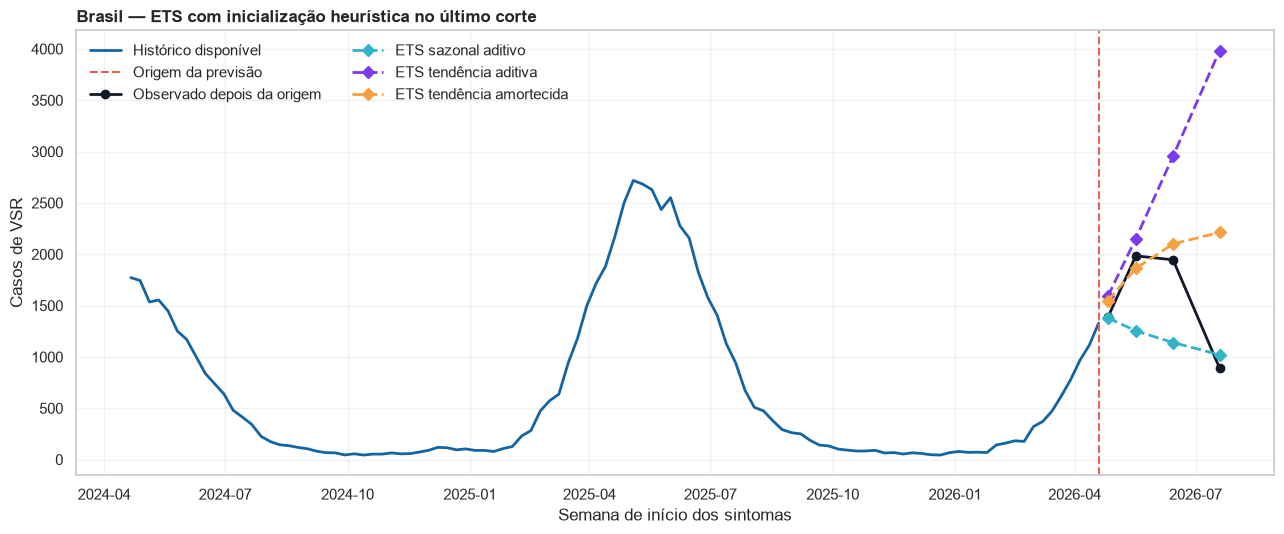


Etapa 23B concluída.
Origens temporais: 348
Ajustes ETS previstos: 1,044
Previsões disponíveis: 4,176

Saídas salvas em:
..\..\execucao_local_vsr\saidas\etapa_23b_ets_inicializacao_heuristica


status_final,modelo,CONVERGIU,ajustes_esperados,modelo_aprovado_para_metricas
0,ETS_SAZONAL_ADITIVO_HEURISTICO,348,348,True
1,ETS_TENDENCIA_ADITIVA_HEURISTICO,348,348,True
2,ETS_TENDENCIA_AMORTECIDA_HEURISTICO,348,348,True


,modelo,horizonte_semanas,previsoes_disponiveis,previsoes_ajustadas_nao_negativas,previsoes_esperadas,percentual_disponivel
0,ETS_SAZONAL_ADITIVO_HEURISTICO,1,348,9,348,100.0
1,ETS_SAZONAL_ADITIVO_HEURISTICO,4,348,10,348,100.0
2,ETS_SAZONAL_ADITIVO_HEURISTICO,8,348,11,348,100.0
3,ETS_SAZONAL_ADITIVO_HEURISTICO,13,348,11,348,100.0
4,ETS_TENDENCIA_ADITIVA_HEURISTICO,1,348,15,348,100.0
5,ETS_TENDENCIA_ADITIVA_HEURISTICO,4,348,45,348,100.0
6,ETS_TENDENCIA_ADITIVA_HEURISTICO,8,348,80,348,100.0
7,ETS_TENDENCIA_ADITIVA_HEURISTICO,13,348,86,348,100.0
8,ETS_TENDENCIA_AMORTECIDA_HEURISTICO,1,348,10,348,100.0
9,ETS_TENDENCIA_AMORTECIDA_HEURISTICO,4,348,21,348,100.0


In [31]:
# ETAPA 23B — ETS com inicialização sazonal heurística

import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from statsmodels.tools.sm_exceptions import ConvergenceWarning
from statsmodels.tsa.holtwinters import ExponentialSmoothing

BASE_DIR = Path(
    "../../execucao_local_vsr"
)

ARQUIVO_PAINEL = (
    BASE_DIR
    / "saidas"
    / "etapa_20_preparacao_modelagem"
    / "painel_modelagem_brasil_regioes.parquet"
)

ARQUIVO_CALENDARIO = (
    BASE_DIR
    / "saidas"
    / "etapa_20_preparacao_modelagem"
    / "calendario_validacao_modelagem.csv"
)

DIRETORIO_RESULTADOS = (
    BASE_DIR
    / "saidas"
    / "etapa_23b_ets_inicializacao_heuristica"
)

DIRETORIO_RESULTADOS.mkdir(parents=True, exist_ok=True)

for arquivo in [ARQUIVO_PAINEL, ARQUIVO_CALENDARIO]:
    if not arquivo.exists():
        raise FileNotFoundError(f"Arquivo não encontrado: {arquivo}")

painel = pd.read_parquet(ARQUIVO_PAINEL)
calendario = pd.read_csv(ARQUIVO_CALENDARIO)

painel["data"] = pd.to_datetime(painel["data"], errors="coerce")
calendario["data_origem"] = pd.to_datetime(
    calendario["data_origem"],
    errors="coerce",
)
calendario["data_alvo"] = pd.to_datetime(
    calendario["data_alvo"],
    errors="coerce",
)

for base in [painel, calendario]:
    base["nivel"] = base["nivel"].astype("string").str.strip().str.upper()
    base["unidade"] = base["unidade"].astype("string").str.strip().str.upper()

painel["casos_vsr"] = pd.to_numeric(
    painel["casos_vsr"],
    errors="coerce",
)

if painel[["data", "casos_vsr"]].isna().any().any():
    raise ValueError("Existem datas ou casos ausentes no painel.")

if calendario[
    ["data_origem", "data_alvo", "casos_observados_alvo"]
].isna().any().any():
    raise ValueError("Existem valores ausentes no calendário.")

PERIODO_SAZONAL = 52
HORIZONTES = sorted(calendario["horizonte_semanas"].unique())
HORIZONTE_MAXIMO = int(max(HORIZONTES))

CONFIGURACOES_ETS = {
    "ETS_SAZONAL_ADITIVO_HEURISTICO": {
        "trend": None,
        "damped_trend": False,
        "seasonal": "add",
    },
    "ETS_TENDENCIA_ADITIVA_HEURISTICO": {
        "trend": "add",
        "damped_trend": False,
        "seasonal": "add",
    },
    "ETS_TENDENCIA_AMORTECIDA_HEURISTICO": {
        "trend": "add",
        "damped_trend": True,
        "seasonal": "add",
    },
}

origens = (
    calendario[
        [
            "nivel",
            "unidade",
            "regiao",
            "data_origem",
            "semanas_treino",
        ]
    ]
    .drop_duplicates()
    .sort_values(["nivel", "unidade", "data_origem"])
    .reset_index(drop=True)
)

regularidade = []

for (nivel, unidade), serie in painel.groupby(["nivel", "unidade"]):
    diferencas = (
        serie.sort_values("data")["data"]
        .diff()
        .dt.days
        .dropna()
    )

    regularidade.append(
        {
            "nivel": nivel,
            "unidade": unidade,
            "semanas": len(serie),
            "primeira_semana": serie["data"].min(),
            "ultima_semana": serie["data"].max(),
            "intervalo_minimo_dias": diferencas.min(),
            "intervalo_maximo_dias": diferencas.max(),
            "serie_semanal_regular": diferencas.eq(7).all(),
        }
    )

regularidade = pd.DataFrame(regularidade)

if not regularidade["serie_semanal_regular"].all():
    display(regularidade.loc[~regularidade["serie_semanal_regular"]])
    raise ValueError("Foram encontradas lacunas nas séries semanais.")

def ajustar_ets_heuristico(valores_treino, parametros):
    tentativas = [
        {
            "numero_tentativa": 1,
            "otimizador": "padrão",
            "argumentos_fit": {
                "optimized": True,
                "remove_bias": False,
                "use_brute": True,
            },
        },
        {
            "numero_tentativa": 2,
            "otimizador": "L-BFGS-B",
            "argumentos_fit": {
                "optimized": True,
                "remove_bias": False,
                "use_brute": False,
                "method": "L-BFGS-B",
                "minimize_kwargs": {
                    "options": {
                        "maxiter": 2000,
                    }
                },
            },
        },
    ]

    historico = []

    for tentativa in tentativas:
        try:
            modelo = ExponentialSmoothing(
                valores_treino,
                trend=parametros["trend"],
                damped_trend=parametros["damped_trend"],
                seasonal=parametros["seasonal"],
                seasonal_periods=PERIODO_SAZONAL,
                initialization_method="heuristic",
            )

            with warnings.catch_warnings(record=True) as avisos:
                warnings.simplefilter("always")
                ajuste = modelo.fit(**tentativa["argumentos_fit"])

            avisos_convergencia = [
                aviso
                for aviso in avisos
                if issubclass(aviso.category, ConvergenceWarning)
            ]

            retorno_otimizador = getattr(ajuste, "mle_retvals", {})
            sucesso_otimizador = np.nan

            if isinstance(retorno_otimizador, dict):
                sucesso_otimizador = retorno_otimizador.get(
                    "success",
                    np.nan,
                )

            convergiu = (
                len(avisos_convergencia) == 0
                and sucesso_otimizador is not False
            )

            mensagens = " | ".join(
                sorted({str(aviso.message) for aviso in avisos})
            )

            historico.append(
                {
                    "numero_tentativa": tentativa["numero_tentativa"],
                    "otimizador": tentativa["otimizador"],
                    "status_tentativa": (
                        "CONVERGIU"
                        if convergiu
                        else "NAO_CONVERGIU"
                    ),
                    "quantidade_avisos": len(avisos),
                    "quantidade_avisos_convergencia": len(
                        avisos_convergencia
                    ),
                    "sucesso_reportado_otimizador": sucesso_otimizador,
                    "mensagens_avisos": mensagens,
                    "mensagem_erro": None,
                }
            )

            if convergiu:
                return ajuste, historico

        except Exception as erro:
            historico.append(
                {
                    "numero_tentativa": tentativa["numero_tentativa"],
                    "otimizador": tentativa["otimizador"],
                    "status_tentativa": "ERRO",
                    "quantidade_avisos": 0,
                    "quantidade_avisos_convergencia": 0,
                    "sucesso_reportado_otimizador": np.nan,
                    "mensagens_avisos": None,
                    "mensagem_erro": str(erro),
                }
            )

    return None, historico

linhas_previsoes = []
linhas_auditoria = []
linhas_tentativas = []

inicio_execucao = time.time()
total_origens = len(origens)

for indice_origem, origem in origens.iterrows():
    nivel = origem["nivel"]
    unidade = origem["unidade"]
    regiao = origem["regiao"]
    data_origem = origem["data_origem"]
    semanas_treino_esperadas = int(origem["semanas_treino"])

    if (
        indice_origem == 0
        or (indice_origem + 1) % 20 == 0
        or (indice_origem + 1) == total_origens
    ):
        minutos = (time.time() - inicio_execucao) / 60

        print(
            f"Processando origem {indice_origem + 1:,} de "
            f"{total_origens:,} "
            f"({minutos:.1f} minutos decorridos)."
        )

    serie = painel.loc[
        (painel["nivel"] == nivel)
        & (painel["unidade"] == unidade)
    ].sort_values("data")

    treino = serie.loc[serie["data"] <= data_origem].copy()

    if len(treino) != semanas_treino_esperadas:
        raise ValueError(
            f"Treino inconsistente em {nivel} - {unidade}, "
            f"origem {data_origem.date()}."
        )

    alvos_origem = calendario.loc[
        (calendario["nivel"] == nivel)
        & (calendario["unidade"] == unidade)
        & (calendario["data_origem"] == data_origem)
    ].sort_values("horizonte_semanas")

    valores_treino = treino["casos_vsr"].astype(float).to_numpy()

    for nome_modelo, parametros in CONFIGURACOES_ETS.items():
        ajuste, tentativas = ajustar_ets_heuristico(
            valores_treino,
            parametros,
        )

        for tentativa in tentativas:
            linhas_tentativas.append(
                {
                    "nivel": nivel,
                    "unidade": unidade,
                    "regiao": regiao,
                    "modelo": nome_modelo,
                    "data_origem": data_origem,
                    "semanas_treino": len(treino),
                    **tentativa,
                }
            )

        if ajuste is None:
            linhas_auditoria.append(
                {
                    "nivel": nivel,
                    "unidade": unidade,
                    "regiao": regiao,
                    "modelo": nome_modelo,
                    "data_origem": data_origem,
                    "semanas_treino": len(treino),
                    "status_final": "NAO_CONVERGIU_APOS_REAJUSTE",
                    "tentativa_escolhida": np.nan,
                    "aic": np.nan,
                    "bic": np.nan,
                    "sse": np.nan,
                    "previsao_gerada": False,
                }
            )
            continue

        try:
            previsao_completa = np.asarray(
                ajuste.forecast(HORIZONTE_MAXIMO),
                dtype=float,
            )

            if len(previsao_completa) != HORIZONTE_MAXIMO:
                raise ValueError("Horizontes retornados incorretamente.")

            if not np.isfinite(previsao_completa).all():
                raise ValueError("Foram geradas previsões não finitas.")

            tentativa_escolhida = [
                item["numero_tentativa"]
                for item in tentativas
                if item["status_tentativa"] == "CONVERGIU"
            ][0]

            linhas_auditoria.append(
                {
                    "nivel": nivel,
                    "unidade": unidade,
                    "regiao": regiao,
                    "modelo": nome_modelo,
                    "data_origem": data_origem,
                    "semanas_treino": len(treino),
                    "status_final": "CONVERGIU",
                    "tentativa_escolhida": tentativa_escolhida,
                    "aic": getattr(ajuste, "aic", np.nan),
                    "bic": getattr(ajuste, "bic", np.nan),
                    "sse": getattr(ajuste, "sse", np.nan),
                    "previsao_gerada": True,
                }
            )

            for alvo in alvos_origem.itertuples(index=False):
                horizonte = int(alvo.horizonte_semanas)
                previsao_bruta = float(
                    previsao_completa[horizonte - 1]
                )

                linhas_previsoes.append(
                    {
                        "nivel": nivel,
                        "unidade": unidade,
                        "regiao": regiao,
                        "modelo": nome_modelo,
                        "data_origem": data_origem,
                        "horizonte_semanas": horizonte,
                        "data_alvo": alvo.data_alvo,
                        "casos_observados": alvo.casos_observados_alvo,
                        "previsao_bruta": previsao_bruta,
                        "previsao": max(0.0, previsao_bruta),
                        "previsao_ajustada_nao_negativa": (
                            previsao_bruta < 0
                        ),
                    }
                )

        except Exception:
            linhas_auditoria.append(
                {
                    "nivel": nivel,
                    "unidade": unidade,
                    "regiao": regiao,
                    "modelo": nome_modelo,
                    "data_origem": data_origem,
                    "semanas_treino": len(treino),
                    "status_final": "ERRO_NA_PREVISAO",
                    "tentativa_escolhida": np.nan,
                    "aic": np.nan,
                    "bic": np.nan,
                    "sse": np.nan,
                    "previsao_gerada": False,
                }
            )

previsoes_ets = pd.DataFrame(linhas_previsoes)
auditoria_ets = pd.DataFrame(linhas_auditoria)
auditoria_tentativas = pd.DataFrame(linhas_tentativas)

resumo_convergencia = (
    auditoria_ets
    .groupby(["modelo", "status_final"])
    .size()
    .unstack(fill_value=0)
    .reindex(list(CONFIGURACOES_ETS.keys()), fill_value=0)
    .rename_axis("modelo")
    .reset_index()
)

resumo_convergencia["ajustes_esperados"] = len(origens)

resumo_convergencia["modelo_aprovado_para_metricas"] = (
    resumo_convergencia.get("CONVERGIU", 0)
    == resumo_convergencia["ajustes_esperados"]
)

resumo_disponibilidade = (
    previsoes_ets
    .groupby(["modelo", "horizonte_semanas"])
    .agg(
        previsoes_disponiveis=("previsao", "size"),
        previsoes_ajustadas_nao_negativas=(
            "previsao_ajustada_nao_negativa",
            "sum",
        ),
    )
    .reindex(
        pd.MultiIndex.from_product(
            [
                list(CONFIGURACOES_ETS.keys()),
                HORIZONTES,
            ],
            names=["modelo", "horizonte_semanas"],
        ),
        fill_value=0,
    )
    .reset_index()
)

resumo_disponibilidade["previsoes_esperadas"] = len(origens)

resumo_disponibilidade["percentual_disponivel"] = (
    100
    * resumo_disponibilidade["previsoes_disponiveis"]
    / resumo_disponibilidade["previsoes_esperadas"]
)

ultimo_corte_brasil = calendario.loc[
    (calendario["nivel"] == "BRASIL")
    & (calendario["unidade"] == "BRASIL"),
    "data_origem",
].max()

serie_brasil = painel.loc[
    (painel["nivel"] == "BRASIL")
    & (painel["unidade"] == "BRASIL")
].copy()

historico_exemplo = serie_brasil.loc[
    (
        serie_brasil["data"]
        >= ultimo_corte_brasil - pd.Timedelta(weeks=104)
    )
    & (serie_brasil["data"] <= ultimo_corte_brasil)
]

observados_exemplo = (
    calendario.loc[
        (calendario["nivel"] == "BRASIL")
        & (calendario["unidade"] == "BRASIL")
        & (calendario["data_origem"] == ultimo_corte_brasil),
        ["data_alvo", "casos_observados_alvo"],
    ]
    .drop_duplicates()
    .sort_values("data_alvo")
)

previsoes_exemplo = previsoes_ets.loc[
    (previsoes_ets["nivel"] == "BRASIL")
    & (previsoes_ets["unidade"] == "BRASIL")
    & (previsoes_ets["data_origem"] == ultimo_corte_brasil)
].copy()

cores = {
    "ETS_SAZONAL_ADITIVO_HEURISTICO": "#32B4C8",
    "ETS_TENDENCIA_ADITIVA_HEURISTICO": "#7C3AED",
    "ETS_TENDENCIA_AMORTECIDA_HEURISTICO": "#F6A041",
}

rotulos = {
    "ETS_SAZONAL_ADITIVO_HEURISTICO": "ETS sazonal aditivo",
    "ETS_TENDENCIA_ADITIVA_HEURISTICO": "ETS tendência aditiva",
    "ETS_TENDENCIA_AMORTECIDA_HEURISTICO": (
        "ETS tendência amortecida"
    ),
}

fig, ax = plt.subplots(figsize=(13, 5.5))

ax.plot(
    historico_exemplo["data"],
    historico_exemplo["casos_vsr"],
    color="#1264A3",
    linewidth=2,
    label="Histórico disponível",
)

ax.axvline(
    ultimo_corte_brasil,
    color="#E85F5C",
    linestyle="--",
    linewidth=1.5,
    label="Origem da previsão",
)

ax.plot(
    observados_exemplo["data_alvo"],
    observados_exemplo["casos_observados_alvo"],
    "o-",
    color="#111827",
    linewidth=2,
    label="Observado depois da origem",
)

for modelo, grupo in previsoes_exemplo.groupby("modelo"):
    grupo = grupo.sort_values("data_alvo")

    ax.plot(
        grupo["data_alvo"],
        grupo["previsao"],
        "D--",
        color=cores[modelo],
        linewidth=2,
        label=rotulos[modelo],
    )

ax.set_title(
    "Brasil — ETS com inicialização heurística no último corte",
    loc="left",
    fontweight="bold",
)
ax.set_xlabel("Semana de início dos sintomas")
ax.set_ylabel("Casos de VSR")
ax.grid(alpha=0.25)
ax.legend(frameon=False, ncol=2)

fig.tight_layout()

fig.savefig(
    DIRETORIO_RESULTADOS
    / "exemplo_previsoes_ets_heuristico_brasil.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

regularidade.to_csv(
    DIRETORIO_RESULTADOS
    / "controle_regularidade_series_ets_heuristico.csv",
    index=False,
)

pd.DataFrame(
    [
        {
            "modelo": nome,
            "tendencia": parametros["trend"],
            "tendencia_amortecida": parametros["damped_trend"],
            "sazonalidade": parametros["seasonal"],
            "periodo_sazonal": PERIODO_SAZONAL,
            "inicializacao": "heuristic",
        }
        for nome, parametros in CONFIGURACOES_ETS.items()
    ]
).to_csv(
    DIRETORIO_RESULTADOS / "configuracoes_ets_heuristico.csv",
    index=False,
)

previsoes_ets.to_csv(
    DIRETORIO_RESULTADOS / "previsoes_ets_heuristico.csv",
    index=False,
)

auditoria_ets.to_csv(
    DIRETORIO_RESULTADOS / "auditoria_ets_heuristico.csv",
    index=False,
)

auditoria_tentativas.to_csv(
    DIRETORIO_RESULTADOS
    / "auditoria_tentativas_ets_heuristico.csv",
    index=False,
)

resumo_convergencia.to_csv(
    DIRETORIO_RESULTADOS
    / "resumo_convergencia_ets_heuristico.csv",
    index=False,
)

resumo_disponibilidade.to_csv(
    DIRETORIO_RESULTADOS
    / "resumo_disponibilidade_ets_heuristico.csv",
    index=False,
)

print("\nEtapa 23B concluída.")
print(f"Origens temporais: {len(origens):,}")
print(
    "Ajustes ETS previstos: "
    f"{len(origens) * len(CONFIGURACOES_ETS):,}"
)
print(f"Previsões disponíveis: {len(previsoes_ets):,}")
print(f"\nSaídas salvas em:\n{DIRETORIO_RESULTADOS}")

display(resumo_convergencia)
display(resumo_disponibilidade)

## Etapa 24 — Comparação entre baselines e modelos ETS

Nesta etapa, compararemos as previsões das duas referências simples e dos três modelos ETS com inicialização heurística.

Todos os modelos serão avaliados nos mesmos cortes temporais, horizontes de 1, 4, 8 e 13 semanas, séries e valores observados. Assim, diferenças de desempenho poderão ser atribuídas aos modelos, e não a mudanças na base ou no período avaliado.

A avaliação usará MAE, RMSE e MASE. As previsões ETS utilizadas serão as previsões operacionais não negativas; a quantidade de previsões corrigidas para zero será registrada separadamente como diagnóstico de plausibilidade.

O objetivo não é escolher o menor número isolado. Um modelo será considerado mais útil se apresentar erro menor ou competitivo, comportamento estável entre horizontes e séries, e previsões coerentes com contagens de internações.

Ao final, teremos uma evidência objetiva para decidir quais estruturas ETS seguem como candidatas e quais devem ser descartadas antes da comparação com modelos SARIMA.

C:\Users\joanc\AppData\Local\Temp\ipykernel_16488\2910380480.py:270: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(calcular_metricas)
C:\Users\joanc\AppData\Local\Temp\ipykernel_16488\2910380480.py:283: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(calcular_metricas)


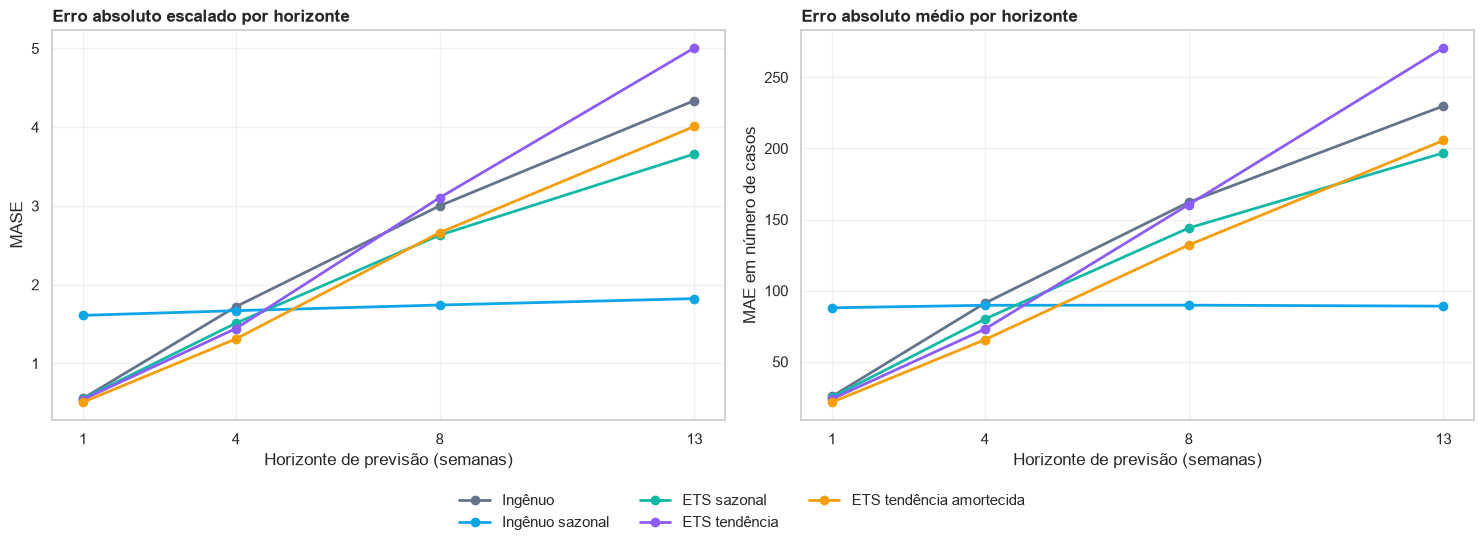


Etapa 24 concluída.
Modelos comparados: 5
Previsões por modelo: 1,392

Saídas salvas em:
..\..\execucao_local_vsr\saidas\etapa_24_comparacao_baselines_ets


,familia_modelo,modelo,previsoes_geradas,origens_temporais,series,horizontes,correcoes_nao_negativas,percentual_correcoes_nao_negativas
0,BASELINE,INGENUO,1392,58,6,4,0,0.000000
1,BASELINE,INGENUO_SAZONAL,1392,58,6,4,0,0.000000
2,ETS,ETS_SAZONAL_ADITIVO_HEURISTICO,1392,58,6,4,41,2.945402
3,ETS,ETS_TENDENCIA_ADITIVA_HEURISTICO,1392,58,6,4,226,16.235632
4,ETS,ETS_TENDENCIA_AMORTECIDA_HEURISTICO,1392,58,6,4,99,7.112069


,horizonte_semanas,modelo,avaliacoes,mae,rmse,mase,viés_medio,ranking_mase
16,1,ETS_TENDENCIA_AMORTECIDA_HEURISTICO,348.0,21.565227,40.001302,0.507297,0.292759,1
12,1,ETS_TENDENCIA_ADITIVA_HEURISTICO,348.0,23.772512,44.254034,0.541387,0.319086,2
8,1,ETS_SAZONAL_ADITIVO_HEURISTICO,348.0,24.976088,45.274636,0.551253,-1.304823,3
0,1,INGENUO,348.0,25.586207,47.652478,0.554340,-1.816092,4
4,1,INGENUO_SAZONAL,348.0,87.948276,190.766979,1.610141,-32.396552,5
17,4,ETS_TENDENCIA_AMORTECIDA_HEURISTICO,348.0,65.500314,144.163056,1.310223,-3.337086,1
13,4,ETS_TENDENCIA_ADITIVA_HEURISTICO,348.0,72.947053,162.871784,1.442180,0.789313,2
9,4,ETS_SAZONAL_ADITIVO_HEURISTICO,348.0,80.028166,169.083053,1.510884,-9.418296,3
5,4,INGENUO_SAZONAL,348.0,89.701149,195.282642,1.669567,-28.793103,4
1,4,INGENUO,348.0,91.189655,181.879160,1.719803,-10.862069,5


In [32]:
# ETAPA 24 — Comparação de baselines e modelos ETS

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

BASE_DIR = Path(
    "../../execucao_local_vsr"
)

DIRETORIO_SAIDAS = BASE_DIR / "saidas"
DIRETORIO_RESULTADOS = (
    BASE_DIR
    / "saidas"
    / "etapa_24_comparacao_baselines_ets"
)

DIRETORIO_RESULTADOS.mkdir(parents=True, exist_ok=True)

def localizar_arquivo(nome_arquivo):
    encontrados = list(DIRETORIO_SAIDAS.rglob(nome_arquivo))

    if len(encontrados) == 0:
        raise FileNotFoundError(
            f"Não foi encontrado o arquivo: {nome_arquivo}"
        )

    if len(encontrados) > 1:
        raise ValueError(
            f"Foi encontrada mais de uma versão de: {nome_arquivo}\n"
            f"{encontrados}"
        )

    return encontrados[0]

ARQUIVO_BASELINES = localizar_arquivo(
    "previsoes_referencias_simples.csv"
)

ARQUIVO_ESCALAS_MASE = localizar_arquivo(
    "escalas_mase_por_origem.csv"
)

ARQUIVO_ETS = localizar_arquivo(
    "previsoes_ets_heuristico.csv"
)

baselines = pd.read_csv(ARQUIVO_BASELINES)
escalas_mase = pd.read_csv(ARQUIVO_ESCALAS_MASE)
ets = pd.read_csv(ARQUIVO_ETS)

for base in [baselines, escalas_mase, ets]:
    for coluna in ["nivel", "unidade"]:
        base[coluna] = (
            base[coluna]
            .astype("string")
            .str.strip()
            .str.upper()
        )

for base in [baselines, escalas_mase, ets]:
    if "data_origem" in base.columns:
        base["data_origem"] = pd.to_datetime(
            base["data_origem"],
            errors="coerce",
        )

if "data_alvo" in baselines.columns:
    baselines["data_alvo"] = pd.to_datetime(
        baselines["data_alvo"],
        errors="coerce",
    )

if "data_alvo" in ets.columns:
    ets["data_alvo"] = pd.to_datetime(
        ets["data_alvo"],
        errors="coerce",
    )

for base in [baselines, ets]:
    base["casos_observados"] = pd.to_numeric(
        base["casos_observados"],
        errors="coerce",
    )

    base["previsao"] = pd.to_numeric(
        base["previsao"],
        errors="coerce",
    )

    base["horizonte_semanas"] = pd.to_numeric(
        base["horizonte_semanas"],
        errors="coerce",
    ).astype("Int64")

escalas_mase["escala_mase_sazonal"] = pd.to_numeric(
    escalas_mase["escala_mase_sazonal"],
    errors="coerce",
)

if ets["previsao_ajustada_nao_negativa"].dtype == object:
    ets["previsao_ajustada_nao_negativa"] = (
        ets["previsao_ajustada_nao_negativa"]
        .astype("string")
        .str.strip()
        .str.lower()
        .eq("true")
    )

baselines["familia_modelo"] = "BASELINE"
ets["familia_modelo"] = "ETS"

colunas_previsao = [
    "nivel",
    "unidade",
    "regiao",
    "modelo",
    "familia_modelo",
    "data_origem",
    "horizonte_semanas",
    "data_alvo",
    "casos_observados",
    "previsao",
]

baselines = baselines[colunas_previsao].copy()

ets = ets.assign(
    previsao_ajustada_nao_negativa=(
        ets["previsao_ajustada_nao_negativa"]
    )
)[
    colunas_previsao
    + ["previsao_ajustada_nao_negativa"]
].copy()

baselines["previsao_ajustada_nao_negativa"] = False

previsoes = pd.concat(
    [baselines, ets],
    ignore_index=True,
)

chaves_previsao = [
    "nivel",
    "unidade",
    "modelo",
    "data_origem",
    "horizonte_semanas",
]

if previsoes.duplicated(chaves_previsao).any():
    raise ValueError("Foram encontradas previsões duplicadas.")

if previsoes[
    ["casos_observados", "previsao"]
].isna().any().any():
    raise ValueError(
        "Foram encontrados valores ausentes nas previsões."
    )

controle_modelos = (
    previsoes
    .groupby(["familia_modelo", "modelo"])
    .agg(
        previsoes_geradas=("previsao", "size"),
        origens_temporais=("data_origem", "nunique"),
        series=("unidade", "nunique"),
        horizontes=("horizonte_semanas", "nunique"),
        correcoes_nao_negativas=(
            "previsao_ajustada_nao_negativa",
            "sum",
        ),
    )
    .reset_index()
)

controle_modelos["percentual_correcoes_nao_negativas"] = (
    100
    * controle_modelos["correcoes_nao_negativas"]
    / controle_modelos["previsoes_geradas"]
)

quantidade_esperada_por_modelo = (
    previsoes[
        ["nivel", "unidade", "data_origem", "horizonte_semanas"]
    ]
    .drop_duplicates()
    .shape[0]
)

if not (
    controle_modelos["previsoes_geradas"]
    == quantidade_esperada_por_modelo
).all():
    display(controle_modelos)

    raise ValueError(
        "Nem todos os modelos possuem a mesma quantidade de previsões."
    )

chaves_escala = [
    "nivel",
    "unidade",
    "data_origem",
]

previsoes = previsoes.merge(
    escalas_mase[
        chaves_escala
        + [
            "semanas_treino",
            "comparacoes_sazonais_treino",
            "escala_mase_sazonal",
        ]
    ],
    on=chaves_escala,
    how="left",
    validate="many_to_one",
)

if previsoes["escala_mase_sazonal"].isna().any():
    raise ValueError(
        "Existem previsões sem escala MASE correspondente."
    )

if (previsoes["escala_mase_sazonal"] <= 0).any():
    raise ValueError(
        "Existem escalas MASE nulas ou negativas."
    )

previsoes["erro"] = (
    previsoes["previsao"]
    - previsoes["casos_observados"]
)

previsoes["erro_absoluto"] = previsoes["erro"].abs()
previsoes["erro_quadratico"] = previsoes["erro"] ** 2

previsoes["erro_absoluto_escalado"] = (
    previsoes["erro_absoluto"]
    / previsoes["escala_mase_sazonal"]
)

def calcular_metricas(grupo):
    return pd.Series(
        {
            "avaliacoes": len(grupo),
            "mae": grupo["erro_absoluto"].mean(),
            "rmse": np.sqrt(grupo["erro_quadratico"].mean()),
            "mase": grupo["erro_absoluto_escalado"].mean(),
            "viés_medio": grupo["erro"].mean(),
        }
    )

metricas_por_serie = (
    previsoes
    .groupby(
        [
            "familia_modelo",
            "modelo",
            "nivel",
            "unidade",
            "horizonte_semanas",
        ]
    )
    .apply(calcular_metricas)
    .reset_index()
)

metricas_agregadas = (
    previsoes
    .groupby(
        [
            "familia_modelo",
            "modelo",
            "horizonte_semanas",
        ]
    )
    .apply(calcular_metricas)
    .reset_index()
)

ranking_modelos = metricas_agregadas.copy()

ranking_modelos["ranking_mase"] = (
    ranking_modelos
    .groupby("horizonte_semanas")["mase"]
    .rank(method="dense", ascending=True)
    .astype(int)
)

ranking_modelos["ranking_mae"] = (
    ranking_modelos
    .groupby("horizonte_semanas")["mae"]
    .rank(method="dense", ascending=True)
    .astype(int)
)

ranking_modelos["ranking_rmse"] = (
    ranking_modelos
    .groupby("horizonte_semanas")["rmse"]
    .rank(method="dense", ascending=True)
    .astype(int)
)

ranking_modelos = ranking_modelos.sort_values(
    [
        "horizonte_semanas",
        "ranking_mase",
        "ranking_mae",
        "ranking_rmse",
    ]
)

correcoes_ets = (
    previsoes.loc[previsoes["familia_modelo"] == "ETS"]
    .groupby(["modelo", "horizonte_semanas"])
    .agg(
        previsoes=("previsao", "size"),
        previsoes_corrigidas=(
            "previsao_ajustada_nao_negativa",
            "sum",
        ),
    )
    .reset_index()
)

correcoes_ets["percentual_corrigido"] = (
    100
    * correcoes_ets["previsoes_corrigidas"]
    / correcoes_ets["previsoes"]
)

ordem_modelos = [
    "INGENUO",
    "INGENUO_SAZONAL",
    "ETS_SAZONAL_ADITIVO_HEURISTICO",
    "ETS_TENDENCIA_ADITIVA_HEURISTICO",
    "ETS_TENDENCIA_AMORTECIDA_HEURISTICO",
]

rotulos_modelos = {
    "INGENUO": "Ingênuo",
    "INGENUO_SAZONAL": "Ingênuo sazonal",
    "ETS_SAZONAL_ADITIVO_HEURISTICO": "ETS sazonal",
    "ETS_TENDENCIA_ADITIVA_HEURISTICO": "ETS tendência",
    "ETS_TENDENCIA_AMORTECIDA_HEURISTICO": (
        "ETS tendência amortecida"
    ),
}

cores_modelos = {
    "INGENUO": "#64748B",
    "INGENUO_SAZONAL": "#0EA5E9",
    "ETS_SAZONAL_ADITIVO_HEURISTICO": "#14B8A6",
    "ETS_TENDENCIA_ADITIVA_HEURISTICO": "#8B5CF6",
    "ETS_TENDENCIA_AMORTECIDA_HEURISTICO": "#F59E0B",
}

fig, eixos = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(15, 5.5),
)

for modelo in ordem_modelos:
    dados = metricas_agregadas.loc[
        metricas_agregadas["modelo"] == modelo
    ].sort_values("horizonte_semanas")

    eixos[0].plot(
        dados["horizonte_semanas"],
        dados["mase"],
        marker="o",
        linewidth=2,
        color=cores_modelos[modelo],
        label=rotulos_modelos[modelo],
    )

    eixos[1].plot(
        dados["horizonte_semanas"],
        dados["mae"],
        marker="o",
        linewidth=2,
        color=cores_modelos[modelo],
        label=rotulos_modelos[modelo],
    )

eixos[0].set_title(
    "Erro absoluto escalado por horizonte",
    loc="left",
    fontweight="bold",
)
eixos[0].set_xlabel("Horizonte de previsão (semanas)")
eixos[0].set_ylabel("MASE")
eixos[0].set_xticks([1, 4, 8, 13])
eixos[0].grid(alpha=0.25)

eixos[1].set_title(
    "Erro absoluto médio por horizonte",
    loc="left",
    fontweight="bold",
)
eixos[1].set_xlabel("Horizonte de previsão (semanas)")
eixos[1].set_ylabel("MAE em número de casos")
eixos[1].set_xticks([1, 4, 8, 13])
eixos[1].grid(alpha=0.25)

handles, labels = eixos[1].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=3,
    frameon=False,
)

fig.tight_layout(rect=[0, 0.10, 1, 1])

fig.savefig(
    DIRETORIO_RESULTADOS
    / "comparacao_baselines_ets_metricas.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

controle_modelos.to_csv(
    DIRETORIO_RESULTADOS
    / "controle_modelos_comparados.csv",
    index=False,
)

previsoes.to_csv(
    DIRETORIO_RESULTADOS
    / "erros_individuais_baselines_ets.csv",
    index=False,
)

metricas_por_serie.to_csv(
    DIRETORIO_RESULTADOS
    / "metricas_por_serie_modelo_horizonte.csv",
    index=False,
)

metricas_agregadas.to_csv(
    DIRETORIO_RESULTADOS
    / "metricas_agregadas_baselines_ets.csv",
    index=False,
)

ranking_modelos.to_csv(
    DIRETORIO_RESULTADOS
    / "ranking_modelos_baselines_ets.csv",
    index=False,
)

correcoes_ets.to_csv(
    DIRETORIO_RESULTADOS
    / "diagnostico_correcoes_nao_negativas_ets.csv",
    index=False,
)

print("\nEtapa 24 concluída.")
print(
    f"Modelos comparados: "
    f"{controle_modelos['modelo'].nunique()}"
)
print(
    f"Previsões por modelo: "
    f"{quantidade_esperada_por_modelo:,}"
)
print(f"\nSaídas salvas em:\n{DIRETORIO_RESULTADOS}")

display(controle_modelos)
display(
    ranking_modelos[
        [
            "horizonte_semanas",
            "modelo",
            "avaliacoes",
            "mae",
            "rmse",
            "mase",
            "viés_medio",
            "ranking_mase",
        ]
    ]
)

## Etapa 25 — Modelos SARIMA com sazonalidade anual

Nesta etapa, ajustaremos modelos SARIMA para Brasil e regiões, utilizando as mesmas séries, cortes temporais e horizontes já empregados nas baselines e nos modelos ETS.

O objetivo é verificar se a modelagem explícita da dependência temporal dos erros, combinada à sazonalidade anual de 52 semanas, melhora as previsões de internações por VSR.

Serão avaliadas duas especificações parcimoniosas. A primeira modela o padrão sazonal e seus erros recentes. A segunda acrescenta uma diferença não sazonal para testar se mudanças de nível entre semanas ajudam a representar a evolução recente da série.

Não utilizaremos uma busca automática ampla de parâmetros. Com 395 semanas por série e sazonalidade anual, testar muitas combinações aumentaria o risco de instabilidade, custo computacional e escolha excessivamente adaptada ao histórico. As duas configurações serão auditadas antes de qualquer comparação de erro.

Processando ajuste 1 de 696 (0.0 minutos decorridos).


Processando ajuste 20 de 696 (3.5 minutos decorridos).


Processando ajuste 40 de 696 (8.2 minutos decorridos).


Processando ajuste 60 de 696 (16.0 minutos decorridos).


Processando ajuste 80 de 696 (19.9 minutos decorridos).


Processando ajuste 100 de 696 (24.3 minutos decorridos).


... (27 outputs left out)

Processando ajuste 660 de 696 (136.0 minutos decorridos).


Processando ajuste 680 de 696 (139.4 minutos decorridos).


Processando ajuste 696 de 696 (143.0 minutos decorridos).


C:\Users\joanc\AppData\Local\Temp\ipykernel_16488\367848799.py:449: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  >= ultimo_corte_brasil - pd.Timedelta(weeks=104)


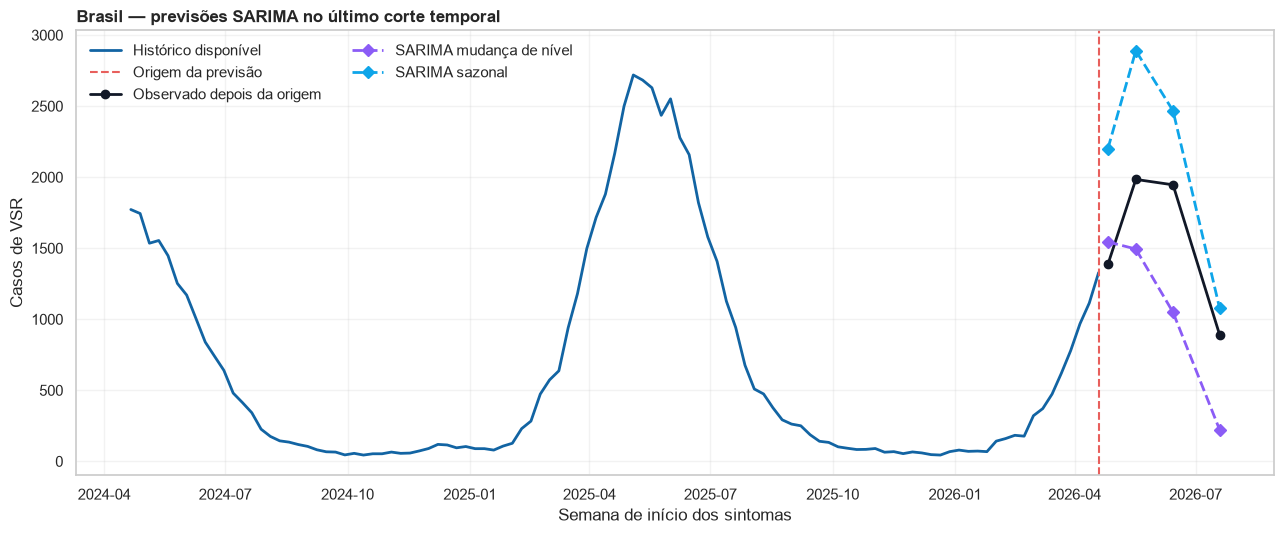


Etapa 25 concluída.
Ajustes SARIMA previstos: 696
Previsões SARIMA disponíveis: 2,276

Saídas salvas em:
..\..\execucao_local_vsr\saidas\etapa_25_modelos_sarima


status_final,modelo,CONVERGIU,NAO_CONVERGIU,ajustes_esperados,modelo_aprovado_para_metricas
0,SARIMA_SAZONAL_MA,289,59,348,False
1,SARIMA_MUDANCA_NIVEL,280,68,348,False


,modelo,horizonte_semanas,previsoes_disponiveis,previsoes_ajustadas_nao_negativas,previsoes_esperadas,percentual_disponivel
0,SARIMA_SAZONAL_MA,1,289,13,348,83.045977
1,SARIMA_SAZONAL_MA,4,289,0,348,83.045977
2,SARIMA_SAZONAL_MA,8,289,0,348,83.045977
3,SARIMA_SAZONAL_MA,13,289,4,348,83.045977
4,SARIMA_MUDANCA_NIVEL,1,280,6,348,80.459770
5,SARIMA_MUDANCA_NIVEL,4,280,6,348,80.459770
6,SARIMA_MUDANCA_NIVEL,8,280,6,348,80.459770
7,SARIMA_MUDANCA_NIVEL,13,280,8,348,80.459770


In [33]:
# ETAPA 25 — Modelos SARIMA com sazonalidade anual

import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from statsmodels.tools.sm_exceptions import ConvergenceWarning
from statsmodels.tsa.statespace.sarimax import SARIMAX

BASE_DIR = Path(
    "../../execucao_local_vsr"
)

ARQUIVO_PAINEL = (
    BASE_DIR
    / "saidas"
    / "etapa_20_preparacao_modelagem"
    / "painel_modelagem_brasil_regioes.parquet"
)

ARQUIVO_CALENDARIO = (
    BASE_DIR
    / "saidas"
    / "etapa_20_preparacao_modelagem"
    / "calendario_validacao_modelagem.csv"
)

DIRETORIO_RESULTADOS = (
    BASE_DIR
    / "saidas"
    / "etapa_25_modelos_sarima"
)

DIRETORIO_RESULTADOS.mkdir(parents=True, exist_ok=True)

for arquivo in [ARQUIVO_PAINEL, ARQUIVO_CALENDARIO]:
    if not arquivo.exists():
        raise FileNotFoundError(f"Arquivo não encontrado: {arquivo}")

painel = pd.read_parquet(ARQUIVO_PAINEL)
calendario = pd.read_csv(ARQUIVO_CALENDARIO)

painel["data"] = pd.to_datetime(painel["data"], errors="coerce")
calendario["data_origem"] = pd.to_datetime(
    calendario["data_origem"],
    errors="coerce",
)
calendario["data_alvo"] = pd.to_datetime(
    calendario["data_alvo"],
    errors="coerce",
)

for base in [painel, calendario]:
    base["nivel"] = base["nivel"].astype("string").str.strip().str.upper()
    base["unidade"] = base["unidade"].astype("string").str.strip().str.upper()

painel["casos_vsr"] = pd.to_numeric(
    painel["casos_vsr"],
    errors="coerce",
)

if painel[["data", "casos_vsr"]].isna().any().any():
    raise ValueError("Existem datas ou casos ausentes no painel.")

if calendario[
    ["data_origem", "data_alvo", "casos_observados_alvo"]
].isna().any().any():
    raise ValueError("Existem valores ausentes no calendário.")

PERIODO_SAZONAL = 52
HORIZONTES = sorted(calendario["horizonte_semanas"].unique())
HORIZONTE_MAXIMO = int(max(HORIZONTES))

CONFIGURACOES_SARIMA = {
    "SARIMA_SAZONAL_MA": {
        "order": (0, 0, 1),
        "seasonal_order": (0, 1, 1, PERIODO_SAZONAL),
    },
    "SARIMA_MUDANCA_NIVEL": {
        "order": (0, 1, 1),
        "seasonal_order": (0, 1, 1, PERIODO_SAZONAL),
    },
}

origens = (
    calendario[
        [
            "nivel",
            "unidade",
            "regiao",
            "data_origem",
            "semanas_treino",
        ]
    ]
    .drop_duplicates()
    .sort_values(["nivel", "unidade", "data_origem"])
    .reset_index(drop=True)
)

regularidade = []

for (nivel, unidade), serie in painel.groupby(["nivel", "unidade"]):
    diferencas = (
        serie.sort_values("data")["data"]
        .diff()
        .dt.days
        .dropna()
    )

    regularidade.append(
        {
            "nivel": nivel,
            "unidade": unidade,
            "semanas": len(serie),
            "primeira_semana": serie["data"].min(),
            "ultima_semana": serie["data"].max(),
            "intervalo_minimo_dias": diferencas.min(),
            "intervalo_maximo_dias": diferencas.max(),
            "serie_semanal_regular": diferencas.eq(7).all(),
        }
    )

regularidade = pd.DataFrame(regularidade)

if not regularidade["serie_semanal_regular"].all():
    display(regularidade.loc[~regularidade["serie_semanal_regular"]])

    raise ValueError(
        "Foram encontradas lacunas nas séries semanais."
    )

def ajustar_sarima(valores_treino, parametros):
    try:
        with warnings.catch_warnings(record=True) as avisos:
            warnings.simplefilter("always")

            modelo = SARIMAX(
                valores_treino,
                order=parametros["order"],
                seasonal_order=parametros["seasonal_order"],
                trend="n",
                enforce_stationarity=False,
                enforce_invertibility=False,
            )

            ajuste = modelo.fit(
                method="lbfgs",
                maxiter=200,
                disp=False,
                warn_convergence=True,
            )

        avisos_convergencia = [
            aviso
            for aviso in avisos
            if issubclass(aviso.category, ConvergenceWarning)
        ]

        retorno_otimizador = getattr(ajuste, "mle_retvals", {})
        convergiu_reportado = np.nan

        if isinstance(retorno_otimizador, dict):
            convergiu_reportado = retorno_otimizador.get(
                "converged",
                np.nan,
            )

        convergiu = (
            len(avisos_convergencia) == 0
            and convergiu_reportado is not False
        )

        mensagens = " | ".join(
            sorted({str(aviso.message) for aviso in avisos})
        )

        return {
            "ajuste": ajuste,
            "convergiu": convergiu,
            "avisos": len(avisos),
            "avisos_convergencia": len(avisos_convergencia),
            "convergiu_reportado": convergiu_reportado,
            "mensagens_avisos": mensagens,
            "erro": None,
        }

    except Exception as erro:
        return {
            "ajuste": None,
            "convergiu": False,
            "avisos": 0,
            "avisos_convergencia": 0,
            "convergiu_reportado": np.nan,
            "mensagens_avisos": None,
            "erro": str(erro),
        }

linhas_previsoes = []
linhas_auditoria = []

inicio_execucao = time.time()
total_ajustes = len(origens) * len(CONFIGURACOES_SARIMA)
ajustes_realizados = 0

for _, origem in origens.iterrows():
    nivel = origem["nivel"]
    unidade = origem["unidade"]
    regiao = origem["regiao"]
    data_origem = origem["data_origem"]
    semanas_treino_esperadas = int(origem["semanas_treino"])

    serie = painel.loc[
        (painel["nivel"] == nivel)
        & (painel["unidade"] == unidade)
    ].sort_values("data")

    treino = serie.loc[serie["data"] <= data_origem].copy()

    if len(treino) != semanas_treino_esperadas:
        raise ValueError(
            f"Treino inconsistente em {nivel} - {unidade}, "
            f"origem {data_origem.date()}."
        )

    alvos_origem = calendario.loc[
        (calendario["nivel"] == nivel)
        & (calendario["unidade"] == unidade)
        & (calendario["data_origem"] == data_origem)
    ].sort_values("horizonte_semanas")

    valores_treino = treino["casos_vsr"].astype(float).to_numpy()

    for nome_modelo, parametros in CONFIGURACOES_SARIMA.items():
        ajustes_realizados += 1

        if (
            ajustes_realizados == 1
            or ajustes_realizados % 20 == 0
            or ajustes_realizados == total_ajustes
        ):
            minutos = (time.time() - inicio_execucao) / 60

            print(
                f"Processando ajuste {ajustes_realizados:,} de "
                f"{total_ajustes:,} "
                f"({minutos:.1f} minutos decorridos)."
            )

        resultado = ajustar_sarima(
            valores_treino,
            parametros,
        )

        ajuste = resultado["ajuste"]

        if ajuste is None or not resultado["convergiu"]:
            linhas_auditoria.append(
                {
                    "nivel": nivel,
                    "unidade": unidade,
                    "regiao": regiao,
                    "modelo": nome_modelo,
                    "data_origem": data_origem,
                    "semanas_treino": len(treino),
                    "status_final": (
                        "NAO_CONVERGIU"
                        if ajuste is not None
                        else "ERRO_AJUSTE"
                    ),
                    "convergiu_reportado": (
                        resultado["convergiu_reportado"]
                    ),
                    "quantidade_avisos": resultado["avisos"],
                    "quantidade_avisos_convergencia": (
                        resultado["avisos_convergencia"]
                    ),
                    "aic": np.nan,
                    "bic": np.nan,
                    "erro_ou_aviso": (
                        resultado["erro"]
                        or resultado["mensagens_avisos"]
                    ),
                    "previsao_gerada": False,
                }
            )
            continue

        try:
            previsao_completa = np.asarray(
                ajuste.forecast(steps=HORIZONTE_MAXIMO),
                dtype=float,
            )

            if len(previsao_completa) != HORIZONTE_MAXIMO:
                raise ValueError(
                    "Quantidade inesperada de horizontes."
                )

            if not np.isfinite(previsao_completa).all():
                raise ValueError(
                    "Foram geradas previsões não finitas."
                )

            linhas_auditoria.append(
                {
                    "nivel": nivel,
                    "unidade": unidade,
                    "regiao": regiao,
                    "modelo": nome_modelo,
                    "data_origem": data_origem,
                    "semanas_treino": len(treino),
                    "status_final": "CONVERGIU",
                    "convergiu_reportado": (
                        resultado["convergiu_reportado"]
                    ),
                    "quantidade_avisos": resultado["avisos"],
                    "quantidade_avisos_convergencia": (
                        resultado["avisos_convergencia"]
                    ),
                    "aic": getattr(ajuste, "aic", np.nan),
                    "bic": getattr(ajuste, "bic", np.nan),
                    "erro_ou_aviso": resultado["mensagens_avisos"],
                    "previsao_gerada": True,
                }
            )

            for alvo in alvos_origem.itertuples(index=False):
                horizonte = int(alvo.horizonte_semanas)
                previsao_bruta = float(
                    previsao_completa[horizonte - 1]
                )

                linhas_previsoes.append(
                    {
                        "nivel": nivel,
                        "unidade": unidade,
                        "regiao": regiao,
                        "modelo": nome_modelo,
                        "data_origem": data_origem,
                        "horizonte_semanas": horizonte,
                        "data_alvo": alvo.data_alvo,
                        "casos_observados": alvo.casos_observados_alvo,
                        "previsao_bruta": previsao_bruta,
                        "previsao": max(0.0, previsao_bruta),
                        "previsao_ajustada_nao_negativa": (
                            previsao_bruta < 0
                        ),
                    }
                )

        except Exception as erro:
            linhas_auditoria.append(
                {
                    "nivel": nivel,
                    "unidade": unidade,
                    "regiao": regiao,
                    "modelo": nome_modelo,
                    "data_origem": data_origem,
                    "semanas_treino": len(treino),
                    "status_final": "ERRO_NA_PREVISAO",
                    "convergiu_reportado": (
                        resultado["convergiu_reportado"]
                    ),
                    "quantidade_avisos": resultado["avisos"],
                    "quantidade_avisos_convergencia": (
                        resultado["avisos_convergencia"]
                    ),
                    "aic": getattr(ajuste, "aic", np.nan),
                    "bic": getattr(ajuste, "bic", np.nan),
                    "erro_ou_aviso": str(erro),
                    "previsao_gerada": False,
                }
            )

previsoes_sarima = pd.DataFrame(linhas_previsoes)
auditoria_sarima = pd.DataFrame(linhas_auditoria)

if previsoes_sarima.empty:
    raise RuntimeError(
        "Nenhum ajuste SARIMA produziu previsão válida."
    )

resumo_convergencia = (
    auditoria_sarima
    .groupby(["modelo", "status_final"])
    .size()
    .unstack(fill_value=0)
    .reindex(list(CONFIGURACOES_SARIMA.keys()), fill_value=0)
    .rename_axis("modelo")
    .reset_index()
)

resumo_convergencia["ajustes_esperados"] = len(origens)

resumo_convergencia["modelo_aprovado_para_metricas"] = (
    resumo_convergencia.get("CONVERGIU", 0)
    == resumo_convergencia["ajustes_esperados"]
)

resumo_disponibilidade = (
    previsoes_sarima
    .groupby(["modelo", "horizonte_semanas"])
    .agg(
        previsoes_disponiveis=("previsao", "size"),
        previsoes_ajustadas_nao_negativas=(
            "previsao_ajustada_nao_negativa",
            "sum",
        ),
    )
    .reindex(
        pd.MultiIndex.from_product(
            [
                list(CONFIGURACOES_SARIMA.keys()),
                HORIZONTES,
            ],
            names=["modelo", "horizonte_semanas"],
        ),
        fill_value=0,
    )
    .reset_index()
)

resumo_disponibilidade["previsoes_esperadas"] = len(origens)

resumo_disponibilidade["percentual_disponivel"] = (
    100
    * resumo_disponibilidade["previsoes_disponiveis"]
    / resumo_disponibilidade["previsoes_esperadas"]
)

ultimo_corte_brasil = calendario.loc[
    (calendario["nivel"] == "BRASIL")
    & (calendario["unidade"] == "BRASIL"),
    "data_origem",
].max()

serie_brasil = painel.loc[
    (painel["nivel"] == "BRASIL")
    & (painel["unidade"] == "BRASIL")
].copy()

historico_exemplo = serie_brasil.loc[
    (
        serie_brasil["data"]
        >= ultimo_corte_brasil - pd.Timedelta(weeks=104)
    )
    & (serie_brasil["data"] <= ultimo_corte_brasil)
]

observados_exemplo = (
    calendario.loc[
        (calendario["nivel"] == "BRASIL")
        & (calendario["unidade"] == "BRASIL")
        & (calendario["data_origem"] == ultimo_corte_brasil),
        ["data_alvo", "casos_observados_alvo"],
    ]
    .drop_duplicates()
    .sort_values("data_alvo")
)

previsoes_exemplo = previsoes_sarima.loc[
    (previsoes_sarima["nivel"] == "BRASIL")
    & (previsoes_sarima["unidade"] == "BRASIL")
    & (previsoes_sarima["data_origem"] == ultimo_corte_brasil)
].copy()

cores = {
    "SARIMA_SAZONAL_MA": "#0EA5E9",
    "SARIMA_MUDANCA_NIVEL": "#8B5CF6",
}

rotulos = {
    "SARIMA_SAZONAL_MA": "SARIMA sazonal",
    "SARIMA_MUDANCA_NIVEL": "SARIMA mudança de nível",
}

fig, ax = plt.subplots(figsize=(13, 5.5))

ax.plot(
    historico_exemplo["data"],
    historico_exemplo["casos_vsr"],
    color="#1264A3",
    linewidth=2,
    label="Histórico disponível",
)

ax.axvline(
    ultimo_corte_brasil,
    color="#E85F5C",
    linestyle="--",
    linewidth=1.5,
    label="Origem da previsão",
)

ax.plot(
    observados_exemplo["data_alvo"],
    observados_exemplo["casos_observados_alvo"],
    "o-",
    color="#111827",
    linewidth=2,
    label="Observado depois da origem",
)

for modelo, grupo in previsoes_exemplo.groupby("modelo"):
    grupo = grupo.sort_values("data_alvo")

    ax.plot(
        grupo["data_alvo"],
        grupo["previsao"],
        "D--",
        color=cores[modelo],
        linewidth=2,
        label=rotulos[modelo],
    )

ax.set_title(
    "Brasil — previsões SARIMA no último corte temporal",
    loc="left",
    fontweight="bold",
)
ax.set_xlabel("Semana de início dos sintomas")
ax.set_ylabel("Casos de VSR")
ax.grid(alpha=0.25)
ax.legend(frameon=False, ncol=2)

fig.tight_layout()

fig.savefig(
    DIRETORIO_RESULTADOS
    / "exemplo_previsoes_sarima_brasil.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

regularidade.to_csv(
    DIRETORIO_RESULTADOS
    / "controle_regularidade_series_sarima.csv",
    index=False,
)

pd.DataFrame(
    [
        {
            "modelo": nome,
            "ordem_nao_sazonal": parametros["order"],
            "ordem_sazonal": parametros["seasonal_order"],
            "periodo_sazonal": PERIODO_SAZONAL,
        }
        for nome, parametros in CONFIGURACOES_SARIMA.items()
    ]
).to_csv(
    DIRETORIO_RESULTADOS
    / "configuracoes_sarima.csv",
    index=False,
)

previsoes_sarima.to_csv(
    DIRETORIO_RESULTADOS / "previsoes_sarima.csv",
    index=False,
)

auditoria_sarima.to_csv(
    DIRETORIO_RESULTADOS / "auditoria_sarima.csv",
    index=False,
)

resumo_convergencia.to_csv(
    DIRETORIO_RESULTADOS
    / "resumo_convergencia_sarima.csv",
    index=False,
)

resumo_disponibilidade.to_csv(
    DIRETORIO_RESULTADOS
    / "resumo_disponibilidade_sarima.csv",
    index=False,
)

print("\nEtapa 25 concluída.")
print(f"Ajustes SARIMA previstos: {total_ajustes:,}")
print(f"Previsões SARIMA disponíveis: {len(previsoes_sarima):,}")
print(f"\nSaídas salvas em:\n{DIRETORIO_RESULTADOS}")

display(resumo_convergencia)
display(resumo_disponibilidade)

## Etapa 25A — Diagnóstico da estabilidade dos modelos SARIMA

Nesta etapa, analisaremos a auditoria produzida pela Etapa 25, sem ajustar novos modelos.

O objetivo é verificar se as falhas de convergência foram pontuais ou sistemáticas, em quais séries e cortes temporais ocorreram e se os modelos produziram previsões incompatíveis com contagens de internações, como valores negativos.

Um modelo só poderá seguir para a comparação principal se gerar previsões válidas para todos os 348 cortes temporais. Essa exigência garante que as métricas de erro sejam calculadas sobre exatamente os mesmos alvos utilizados pelos baselines e pelos modelos ETS.

O resultado desta etapa orientará a Etapa 25B: uma formulação alternativa será considerada somente se houver uma justificativa estatística clara, e não apenas para buscar um resultado numérico mais favorável.

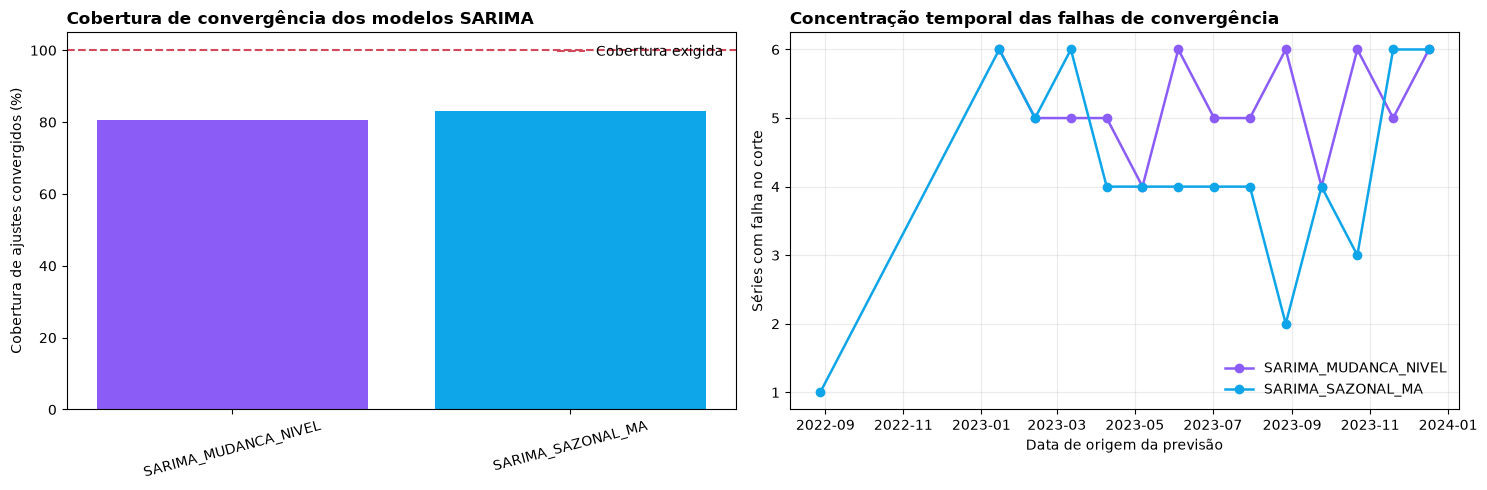

Etapa 25A concluída.
Modelos auditados: 2
Falhas de convergência: 127
Resultados: ..\..\execucao_local_vsr\saidas\etapa_25a_diagnostico_sarima


,modelo,ajustes_realizados,ajustes_convergidos,ajustes_nao_convergidos,primeira_origem,ultima_origem,ajustes_esperados,cobertura_percentual,previsoes_geradas,previsoes_negativas_brutas,previsoes_corrigidas_para_zero,previsoes_esperadas,cobertura_previsoes_percentual,modelo_aprovado_para_metricas,decisao
0,SARIMA_MUDANCA_NIVEL,348,280,68,2021-12-19,2026-04-19,348,80.459770,1120,26,26,1392,80.459770,False,REPROVADO_COBERTURA_INSUFICIENTE
1,SARIMA_SAZONAL_MA,348,289,59,2021-12-19,2026-04-19,348,83.045977,1156,17,17,1392,83.045977,False,REPROVADO_COBERTURA_INSUFICIENTE


In [1]:
# ETAPA 25A — Diagnóstico da estabilidade dos modelos SARIMA

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BASE_DIR = Path(
    "../../execucao_local_vsr"
)

DIRETORIO_ENTRADA = (
    BASE_DIR
    / "saidas"
    / "etapa_25_modelos_sarima"
)

DIRETORIO_RESULTADOS = (
    BASE_DIR
    / "saidas"
    / "etapa_25a_diagnostico_sarima"
)

DIRETORIO_RESULTADOS.mkdir(parents=True, exist_ok=True)

ARQUIVO_AUDITORIA = DIRETORIO_ENTRADA / "auditoria_sarima.csv"
ARQUIVO_PREVISOES = DIRETORIO_ENTRADA / "previsoes_sarima.csv"

for arquivo in [ARQUIVO_AUDITORIA, ARQUIVO_PREVISOES]:
    if not arquivo.exists():
        raise FileNotFoundError(f"Arquivo não encontrado: {arquivo}")

auditoria = pd.read_csv(ARQUIVO_AUDITORIA)
previsoes = pd.read_csv(ARQUIVO_PREVISOES)

for base in [auditoria, previsoes]:
    for coluna in ["nivel", "unidade", "modelo"]:
        base[coluna] = (
            base[coluna]
            .astype("string")
            .str.strip()
            .str.upper()
        )

    if "data_origem" in base.columns:
        base["data_origem"] = pd.to_datetime(
            base["data_origem"],
            errors="coerce",
        )

if "data_alvo" in previsoes.columns:
    previsoes["data_alvo"] = pd.to_datetime(
        previsoes["data_alvo"],
        errors="coerce",
    )

for coluna in [
    "previsao",
    "previsao_bruta",
    "casos_observados",
    "horizonte_semanas",
]:
    previsoes[coluna] = pd.to_numeric(
        previsoes[coluna],
        errors="coerce",
    )

if auditoria["data_origem"].isna().any():
    raise ValueError("Existem datas de origem inválidas na auditoria.")

if previsoes[
    [
        "data_origem",
        "data_alvo",
        "previsao",
        "previsao_bruta",
        "casos_observados",
    ]
].isna().any().any():
    raise ValueError("Existem valores ausentes nas previsões SARIMA.")

if auditoria.duplicated(
    ["nivel", "unidade", "modelo", "data_origem"]
).any():
    raise ValueError("Existem ajustes SARIMA duplicados na auditoria.")

if previsoes.duplicated(
    [
        "nivel",
        "unidade",
        "modelo",
        "data_origem",
        "horizonte_semanas",
    ]
).any():
    raise ValueError("Existem previsões SARIMA duplicadas.")

modelos = sorted(auditoria["modelo"].unique())
AJUSTES_ESPERADOS = 348
HORIZONTES = [1, 4, 8, 13]

resumo_convergencia = (
    auditoria
    .assign(convergiu=auditoria["status_final"].eq("CONVERGIU"))
    .groupby("modelo", as_index=False)
    .agg(
        ajustes_realizados=("status_final", "size"),
        ajustes_convergidos=("convergiu", "sum"),
        ajustes_nao_convergidos=(
            "convergiu",
            lambda valores: int((~valores).sum()),
        ),
        primeira_origem=("data_origem", "min"),
        ultima_origem=("data_origem", "max"),
    )
)

resumo_convergencia["ajustes_esperados"] = AJUSTES_ESPERADOS
resumo_convergencia["cobertura_percentual"] = (
    100
    * resumo_convergencia["ajustes_convergidos"]
    / resumo_convergencia["ajustes_esperados"]
)

resumo_previsoes = (
    previsoes
    .groupby("modelo", as_index=False)
    .agg(
        previsoes_geradas=("previsao", "size"),
        previsoes_negativas_brutas=(
            "previsao_bruta",
            lambda valores: int((valores < 0).sum()),
        ),
        previsoes_corrigidas_para_zero=(
            "previsao_ajustada_nao_negativa",
            "sum",
        ),
    )
)

resumo_previsoes["previsoes_esperadas"] = (
    AJUSTES_ESPERADOS * len(HORIZONTES)
)

resumo_previsoes["cobertura_previsoes_percentual"] = (
    100
    * resumo_previsoes["previsoes_geradas"]
    / resumo_previsoes["previsoes_esperadas"]
)

resumo_decisao = resumo_convergencia.merge(
    resumo_previsoes,
    on="modelo",
    how="left",
    validate="one_to_one",
)

resumo_decisao["modelo_aprovado_para_metricas"] = (
    resumo_decisao["ajustes_convergidos"]
    .eq(AJUSTES_ESPERADOS)
    & resumo_decisao["previsoes_geradas"]
    .eq(AJUSTES_ESPERADOS * len(HORIZONTES))
)

resumo_decisao["decisao"] = np.where(
    resumo_decisao["modelo_aprovado_para_metricas"],
    "APROVADO_PARA_COMPARACAO",
    "REPROVADO_COBERTURA_INSUFICIENTE",
)

falhas = auditoria.loc[
    auditoria["status_final"] != "CONVERGIU"
].copy()

faixas = [0, 156, 208, 260, 312, 400]
rotulos_faixas = [
    "até 156",
    "157 a 208",
    "209 a 260",
    "261 a 312",
    "313 a 400",
]

falhas["faixa_semanas_treino"] = pd.cut(
    falhas["semanas_treino"],
    bins=faixas,
    labels=rotulos_faixas,
    include_lowest=True,
)

falhas_por_data = (
    falhas
    .groupby(
        ["modelo", "data_origem", "semanas_treino"],
        as_index=False,
    )
    .agg(series_com_falha=("unidade", "nunique"))
)

falhas_por_serie = (
    falhas
    .groupby(
        ["modelo", "nivel", "unidade"],
        as_index=False,
    )
    .agg(
        falhas=("status_final", "size"),
        primeira_falha=("data_origem", "min"),
        ultima_falha=("data_origem", "max"),
    )
)

falhas_por_faixa = (
    falhas
    .groupby(
        ["modelo", "faixa_semanas_treino"],
        observed=False,
    )
    .agg(falhas=("status_final", "size"))
    .reset_index()  # as_index=False + categórica falha no pandas 2.x
)

mensagens_falha = (
    falhas
    .groupby(
        ["modelo", "erro_ou_aviso"],
        dropna=False,
        as_index=False,
    )
    .agg(falhas=("status_final", "size"))
    .sort_values(["modelo", "falhas"], ascending=[True, False])
)

correcoes_por_horizonte = (
    previsoes
    .groupby(
        ["modelo", "horizonte_semanas"],
        as_index=False,
    )
    .agg(
        previsoes_geradas=("previsao", "size"),
        previsoes_corrigidas_para_zero=(
            "previsao_ajustada_nao_negativa",
            "sum",
        ),
        menor_previsao_bruta=("previsao_bruta", "min"),
    )
)

correcoes_por_horizonte["percentual_corrigido"] = (
    100
    * correcoes_por_horizonte[
        "previsoes_corrigidas_para_zero"
    ]
    / correcoes_por_horizonte["previsoes_geradas"]
)

fig, eixos = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(15, 5),
)

cores = {
    "SARIMA_SAZONAL_MA": "#0EA5E9",
    "SARIMA_MUDANCA_NIVEL": "#8B5CF6",
}

dados_cobertura = resumo_decisao.sort_values("modelo")

eixos[0].bar(
    dados_cobertura["modelo"],
    dados_cobertura["cobertura_percentual"],
    color=[
        cores.get(modelo, "#64748B")
        for modelo in dados_cobertura["modelo"]
    ],
)

eixos[0].axhline(
    100,
    color="#D1495B",
    linestyle="--",
    linewidth=1.5,
    label="Cobertura exigida",
)

eixos[0].set_ylim(0, 105)
eixos[0].set_ylabel("Cobertura de ajustes convergidos (%)")
eixos[0].set_title(
    "Cobertura de convergência dos modelos SARIMA",
    loc="left",
    fontweight="bold",
)

eixos[0].tick_params(axis="x", rotation=15)
eixos[0].legend(frameon=False)

for modelo, dados in falhas_por_data.groupby("modelo"):
    eixos[1].plot(
        dados["data_origem"],
        dados["series_com_falha"],
        marker="o",
        linewidth=1.8,
        color=cores.get(modelo, "#64748B"),
        label=modelo,
    )

eixos[1].set_title(
    "Concentração temporal das falhas de convergência",
    loc="left",
    fontweight="bold",
)

eixos[1].set_xlabel("Data de origem da previsão")
eixos[1].set_ylabel("Séries com falha no corte")
eixos[1].grid(alpha=0.25)
eixos[1].legend(frameon=False)

fig.tight_layout()

fig.savefig(
    DIRETORIO_RESULTADOS / "diagnostico_estabilidade_sarima.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

resumo_decisao.to_csv(
    DIRETORIO_RESULTADOS / "resumo_decisao_sarima.csv",
    index=False,
)

falhas.to_csv(
    DIRETORIO_RESULTADOS / "falhas_sarima_detalhadas.csv",
    index=False,
)

falhas_por_data.to_csv(
    DIRETORIO_RESULTADOS / "falhas_sarima_por_data.csv",
    index=False,
)

falhas_por_serie.to_csv(
    DIRETORIO_RESULTADOS / "falhas_sarima_por_serie.csv",
    index=False,
)

falhas_por_faixa.to_csv(
    DIRETORIO_RESULTADOS / "falhas_sarima_por_faixa_treino.csv",
    index=False,
)

mensagens_falha.to_csv(
    DIRETORIO_RESULTADOS / "mensagens_falha_sarima.csv",
    index=False,
)

correcoes_por_horizonte.to_csv(
    DIRETORIO_RESULTADOS
    / "diagnostico_previsoes_negativas_sarima.csv",
    index=False,
)

print("Etapa 25A concluída.")
print(f"Modelos auditados: {len(modelos)}")
print(f"Falhas de convergência: {len(falhas):,}")
print(f"Resultados: {DIRETORIO_RESULTADOS}")

display(resumo_decisao)

## Etapa 25B — SARIMAX harmônico com dinâmica de curto prazo

Nesta etapa, testaremos uma alternativa aos modelos SARIMA que apresentaram cobertura insuficiente na Etapa 25.

A sazonalidade anual será representada por termos harmônicos de Fourier, construídos a partir do calendário. Essa escolha substitui a estimação direta de um componente sazonal de 52 semanas por uma curva anual suave, controlada por poucos parâmetros.

Serão utilizados dois pares de termos harmônicos, capazes de representar um pico anual amplo e alguma assimetria. Os desvios de curto prazo em relação a esse padrão sazonal serão modelados por uma estrutura ARMA(1,1).

A variável de casos será transformada por `log1p`, o que permite trabalhar com semanas de zero casos, reduz a influência desproporcional de grandes picos e garante previsões não negativas após a transformação inversa.

A estrutura será mantida fixa antes da avaliação. O modelo somente seguirá para a comparação de erros caso produza previsões válidas para os 348 cortes temporais.

Processando ajuste 1 de 348 (0.0 minutos decorridos).


C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\1309879539.py:358: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  start=data_origem + pd.Timedelta(days=7),
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\1309879539.py:358: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  start=data_origem + pd.Timedelta(days=7),


C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\1309879539.py:358: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  start=data_origem + pd.Timedelta(days=7),
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\1309879539.py:358: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  start=data_origem + pd.Timedelta(days=7),


C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\1309879539.py:358: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  start=data_origem + pd.Timedelta(days=7),


C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\1309879539.py:358: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  start=data_origem + pd.Timedelta(days=7),
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\1309879539.py:358: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  start=data_origem + pd.Timedelta(days=7),


C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\1309879539.py:358: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  start=data_origem + pd.Timedelta(days=7),
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\1309879539.py:358: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  start=data_origem + pd.Timedelta(days=7),


... (261 outputs left out)

C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\1309879539.py:358: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  start=data_origem + pd.Timedelta(days=7),


C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\1309879539.py:358: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  start=data_origem + pd.Timedelta(days=7),


Processando ajuste 348 de 348 (1.3 minutos decorridos).


C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\1309879539.py:358: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  start=data_origem + pd.Timedelta(days=7),
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\1309879539.py:532: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  >= ultimo_corte_brasil - pd.Timedelta(weeks=104)


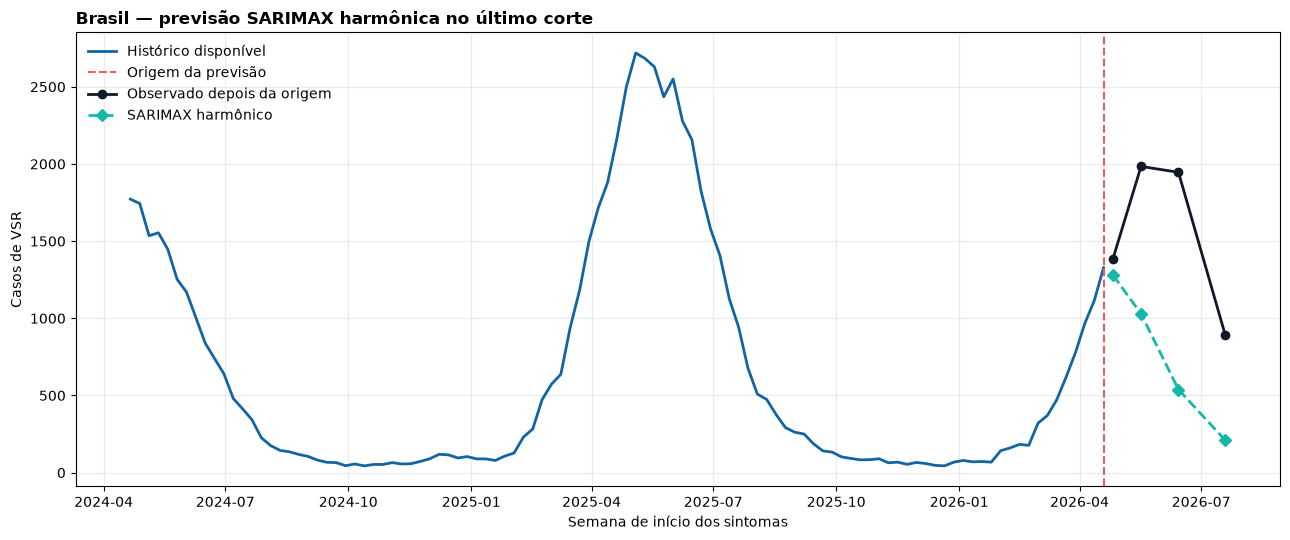

Etapa 25B concluída.
Ajustes previstos: 348
Previsões disponíveis: 1,380
Resultados: ..\..\execucao_local_vsr\saidas\etapa_25b_sarimax_harmonico


status_final,modelo,CONVERGIU,NAO_CONVERGIU,ERRO_AJUSTE,ERRO_NA_PREVISAO,ajustes_esperados,modelo_aprovado_para_metricas
0,SARIMAX_FOURIER2_ARMA11_LOG1P,345,3,0,0,348,False


,modelo,horizonte_semanas,previsoes_disponiveis,previsoes_ajustadas_nao_negativas,previsoes_esperadas,percentual_disponivel
0,SARIMAX_FOURIER2_ARMA11_LOG1P,1,345,0,348,99.137931
1,SARIMAX_FOURIER2_ARMA11_LOG1P,4,345,0,348,99.137931
2,SARIMAX_FOURIER2_ARMA11_LOG1P,8,345,0,348,99.137931
3,SARIMAX_FOURIER2_ARMA11_LOG1P,13,345,0,348,99.137931


In [2]:
# ETAPA 25B — SARIMAX harmônico com Fourier e erros ARMA(1,1)

import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from statsmodels.tools.sm_exceptions import ConvergenceWarning
from statsmodels.tsa.statespace.sarimax import SARIMAX

BASE_DIR = Path(
    "../../execucao_local_vsr"
)

ARQUIVO_PAINEL = (
    BASE_DIR
    / "saidas"
    / "etapa_20_preparacao_modelagem"
    / "painel_modelagem_brasil_regioes.parquet"
)

ARQUIVO_CALENDARIO = (
    BASE_DIR
    / "saidas"
    / "etapa_20_preparacao_modelagem"
    / "calendario_validacao_modelagem.csv"
)

DIRETORIO_RESULTADOS = (
    BASE_DIR
    / "saidas"
    / "etapa_25b_sarimax_harmonico"
)

DIRETORIO_RESULTADOS.mkdir(parents=True, exist_ok=True)

for arquivo in [ARQUIVO_PAINEL, ARQUIVO_CALENDARIO]:
    if not arquivo.exists():
        raise FileNotFoundError(f"Arquivo não encontrado: {arquivo}")

painel = pd.read_parquet(ARQUIVO_PAINEL)
calendario = pd.read_csv(ARQUIVO_CALENDARIO)

painel["data"] = pd.to_datetime(
    painel["data"],
    errors="coerce",
)

calendario["data_origem"] = pd.to_datetime(
    calendario["data_origem"],
    errors="coerce",
)

calendario["data_alvo"] = pd.to_datetime(
    calendario["data_alvo"],
    errors="coerce",
)

for base in [painel, calendario]:
    base["nivel"] = (
        base["nivel"].astype("string").str.strip().str.upper()
    )
    base["unidade"] = (
        base["unidade"].astype("string").str.strip().str.upper()
    )

painel["casos_vsr"] = pd.to_numeric(
    painel["casos_vsr"],
    errors="coerce",
)

if painel[["data", "casos_vsr"]].isna().any().any():
    raise ValueError("Existem datas ou casos ausentes no painel.")

if (painel["casos_vsr"] < 0).any():
    raise ValueError("Existem contagens negativas no painel.")

if calendario[
    ["data_origem", "data_alvo", "casos_observados_alvo"]
].isna().any().any():
    raise ValueError("Existem valores ausentes no calendário.")

HORIZONTES = sorted(
    calendario["horizonte_semanas"].unique()
)

HORIZONTE_MAXIMO = int(max(HORIZONTES))
PERIODO_ANUAL_SEMANAS = 365.25 / 7
NUMERO_HARMONICOS = 2

CONFIGURACAO_MODELO = {
    "modelo": "SARIMAX_FOURIER2_ARMA11_LOG1P",
    "ordem_arma": (1, 0, 1),
    "ordem_sazonal": (0, 0, 0, 0),
    "transformacao": "log1p",
    "harmonicos": NUMERO_HARMONICOS,
    "periodo_anual_semanas": PERIODO_ANUAL_SEMANAS,
}

origens = (
    calendario[
        [
            "nivel",
            "unidade",
            "regiao",
            "data_origem",
            "semanas_treino",
        ]
    ]
    .drop_duplicates()
    .sort_values(["nivel", "unidade", "data_origem"])
    .reset_index(drop=True)
)

regularidade = []

for (nivel, unidade), serie in painel.groupby(["nivel", "unidade"]):
    diferencas = (
        serie
        .sort_values("data")["data"]
        .diff()
        .dropna()
        .dt.days
    )

    regularidade.append(
        {
            "nivel": nivel,
            "unidade": unidade,
            "semanas": len(serie),
            "primeira_semana": serie["data"].min(),
            "ultima_semana": serie["data"].max(),
            "intervalo_minimo_dias": diferencas.min(),
            "intervalo_maximo_dias": diferencas.max(),
            "serie_semanal_regular": diferencas.eq(7).all(),
        }
    )

regularidade = pd.DataFrame(regularidade)

if not regularidade["serie_semanal_regular"].all():
    display(
        regularidade.loc[
            ~regularidade["serie_semanal_regular"]
        ]
    )
    raise ValueError("Foram encontradas lacunas nas séries semanais.")

DATA_BASE = painel["data"].min()

def criar_matriz_fourier(datas):
    indice = pd.DatetimeIndex(pd.to_datetime(datas))

    tempo_semanas = (
        (indice - DATA_BASE).days.to_numpy(dtype=float) / 7
    )

    termos = {}

    for k in range(1, NUMERO_HARMONICOS + 1):
        angulo = (
            2
            * np.pi
            * k
            * tempo_semanas
            / PERIODO_ANUAL_SEMANAS
        )

        termos[f"sen_{k}"] = np.sin(angulo)
        termos[f"cos_{k}"] = np.cos(angulo)

    return pd.DataFrame(termos, index=indice)

def ajustar_sarimax_harmonico(
    valores_treino,
    matriz_fourier_treino,
):
    try:
        with warnings.catch_warnings(record=True) as avisos:
            warnings.simplefilter("always")

            modelo = SARIMAX(
                valores_treino,
                exog=matriz_fourier_treino,
                order=CONFIGURACAO_MODELO["ordem_arma"],
                seasonal_order=CONFIGURACAO_MODELO["ordem_sazonal"],
                trend="c",
                enforce_stationarity=True,
                enforce_invertibility=True,
            )

            ajuste = modelo.fit(
                method="lbfgs",
                maxiter=300,
                disp=False,
                warn_convergence=True,
            )

        avisos_convergencia = [
            aviso
            for aviso in avisos
            if issubclass(aviso.category, ConvergenceWarning)
        ]

        retorno = getattr(ajuste, "mle_retvals", {})
        convergiu_reportado = np.nan

        if isinstance(retorno, dict):
            convergiu_reportado = retorno.get(
                "converged",
                np.nan,
            )

        if isinstance(convergiu_reportado, (bool, np.bool_)):
            convergiu_otimizador = bool(convergiu_reportado)
        else:
            convergiu_otimizador = True

        convergiu = (
            len(avisos_convergencia) == 0
            and convergiu_otimizador
        )

        mensagens = " | ".join(
            sorted({str(aviso.message) for aviso in avisos})
        )

        return {
            "ajuste": ajuste,
            "convergiu": convergiu,
            "convergiu_reportado": convergiu_reportado,
            "quantidade_avisos": len(avisos),
            "quantidade_avisos_convergencia": len(
                avisos_convergencia
            ),
            "mensagens_avisos": mensagens,
            "erro": None,
        }

    except Exception as erro:
        return {
            "ajuste": None,
            "convergiu": False,
            "convergiu_reportado": np.nan,
            "quantidade_avisos": 0,
            "quantidade_avisos_convergencia": 0,
            "mensagens_avisos": None,
            "erro": str(erro),
        }

linhas_previsoes = []
linhas_auditoria = []

inicio_execucao = time.time()
total_ajustes = len(origens)

for indice_origem, origem in origens.iterrows():
    nivel = origem["nivel"]
    unidade = origem["unidade"]
    regiao = origem["regiao"]
    data_origem = origem["data_origem"]
    semanas_treino_esperadas = int(origem["semanas_treino"])

    if (
        indice_origem == 0
        or (indice_origem + 1) % 20 == 0
        or (indice_origem + 1) == total_ajustes
    ):
        minutos = (time.time() - inicio_execucao) / 60

        print(
            f"Processando ajuste {indice_origem + 1:,} de "
            f"{total_ajustes:,} "
            f"({minutos:.1f} minutos decorridos)."
        )

    serie = painel.loc[
        (painel["nivel"] == nivel)
        & (painel["unidade"] == unidade)
    ].sort_values("data")

    treino = serie.loc[
        serie["data"] <= data_origem
    ].copy()

    if len(treino) != semanas_treino_esperadas:
        raise ValueError(
            f"Treino inconsistente em {nivel} - {unidade}, "
            f"origem {data_origem.date()}."
        )

    alvos_origem = calendario.loc[
        (calendario["nivel"] == nivel)
        & (calendario["unidade"] == unidade)
        & (calendario["data_origem"] == data_origem)
    ].sort_values("horizonte_semanas")

    if len(alvos_origem) != len(HORIZONTES):
        raise ValueError(
            f"Quantidade de horizontes incorreta em "
            f"{nivel} - {unidade}, origem {data_origem.date()}."
        )

    valores_treino = np.log1p(
        treino["casos_vsr"].astype(float).to_numpy()
    )

    matriz_treino = criar_matriz_fourier(
        treino["data"]
    )

    resultado = ajustar_sarimax_harmonico(
        valores_treino,
        matriz_treino,
    )

    ajuste = resultado["ajuste"]

    if ajuste is None or not resultado["convergiu"]:
        linhas_auditoria.append(
            {
                "nivel": nivel,
                "unidade": unidade,
                "regiao": regiao,
                "modelo": CONFIGURACAO_MODELO["modelo"],
                "data_origem": data_origem,
                "semanas_treino": len(treino),
                "status_final": (
                    "NAO_CONVERGIU"
                    if ajuste is not None
                    else "ERRO_AJUSTE"
                ),
                "convergiu_reportado": (
                    resultado["convergiu_reportado"]
                ),
                "quantidade_avisos": resultado["quantidade_avisos"],
                "quantidade_avisos_convergencia": (
                    resultado[
                        "quantidade_avisos_convergencia"
                    ]
                ),
                "aic": np.nan,
                "bic": np.nan,
                "erro_ou_aviso": (
                    resultado["erro"]
                    or resultado["mensagens_avisos"]
                ),
                "previsao_gerada": False,
            }
        )
        continue

    try:
        datas_futuras = pd.date_range(
            start=data_origem + pd.Timedelta(days=7),
            periods=HORIZONTE_MAXIMO,
            freq="7D",
        )

        matriz_futura = criar_matriz_fourier(
            datas_futuras
        )

        previsao_log = np.asarray(
            ajuste.get_forecast(
                steps=HORIZONTE_MAXIMO,
                exog=matriz_futura,
            ).predicted_mean,
            dtype=float,
        )

        if (
            len(previsao_log) != HORIZONTE_MAXIMO
            or not np.isfinite(previsao_log).all()
        ):
            raise ValueError("Previsão harmônica inválida.")

        previsao_bruta = np.expm1(previsao_log)

        if not np.isfinite(previsao_bruta).all():
            raise ValueError(
                "A transformação inversa gerou valores inválidos."
            )

        linhas_auditoria.append(
            {
                "nivel": nivel,
                "unidade": unidade,
                "regiao": regiao,
                "modelo": CONFIGURACAO_MODELO["modelo"],
                "data_origem": data_origem,
                "semanas_treino": len(treino),
                "status_final": "CONVERGIU",
                "convergiu_reportado": (
                    resultado["convergiu_reportado"]
                ),
                "quantidade_avisos": resultado["quantidade_avisos"],
                "quantidade_avisos_convergencia": (
                    resultado[
                        "quantidade_avisos_convergencia"
                    ]
                ),
                "aic": getattr(ajuste, "aic", np.nan),
                "bic": getattr(ajuste, "bic", np.nan),
                "erro_ou_aviso": resultado["mensagens_avisos"],
                "previsao_gerada": True,
            }
        )

        for alvo in alvos_origem.itertuples(index=False):
            horizonte = int(alvo.horizonte_semanas)

            valor_bruto = float(
                previsao_bruta[horizonte - 1]
            )

            linhas_previsoes.append(
                {
                    "nivel": nivel,
                    "unidade": unidade,
                    "regiao": regiao,
                    "modelo": CONFIGURACAO_MODELO["modelo"],
                    "data_origem": data_origem,
                    "horizonte_semanas": horizonte,
                    "data_alvo": alvo.data_alvo,
                    "casos_observados": (
                        alvo.casos_observados_alvo
                    ),
                    "previsao_bruta": valor_bruto,
                    "previsao": max(0.0, valor_bruto),
                    "previsao_ajustada_nao_negativa": (
                        valor_bruto < 0
                    ),
                }
            )

    except Exception as erro:
        linhas_auditoria.append(
            {
                "nivel": nivel,
                "unidade": unidade,
                "regiao": regiao,
                "modelo": CONFIGURACAO_MODELO["modelo"],
                "data_origem": data_origem,
                "semanas_treino": len(treino),
                "status_final": "ERRO_NA_PREVISAO",
                "convergiu_reportado": (
                    resultado["convergiu_reportado"]
                ),
                "quantidade_avisos": resultado["quantidade_avisos"],
                "quantidade_avisos_convergencia": (
                    resultado[
                        "quantidade_avisos_convergencia"
                    ]
                ),
                "aic": getattr(ajuste, "aic", np.nan),
                "bic": getattr(ajuste, "bic", np.nan),
                "erro_ou_aviso": str(erro),
                "previsao_gerada": False,
            }
        )

previsoes_harmonicas = pd.DataFrame(linhas_previsoes)
auditoria_harmonica = pd.DataFrame(linhas_auditoria)

if previsoes_harmonicas.empty:
    raise RuntimeError(
        "Nenhum ajuste SARIMAX harmônico produziu previsão válida."
    )

resumo_convergencia = (
    auditoria_harmonica
    .groupby(["modelo", "status_final"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

for status in [
    "CONVERGIU",
    "NAO_CONVERGIU",
    "ERRO_AJUSTE",
    "ERRO_NA_PREVISAO",
]:
    if status not in resumo_convergencia.columns:
        resumo_convergencia[status] = 0

resumo_convergencia["ajustes_esperados"] = total_ajustes
resumo_convergencia["modelo_aprovado_para_metricas"] = (
    resumo_convergencia["CONVERGIU"]
    .eq(total_ajustes)
)

resumo_disponibilidade = (
    previsoes_harmonicas
    .groupby(["modelo", "horizonte_semanas"])
    .agg(
        previsoes_disponiveis=("previsao", "size"),
        previsoes_ajustadas_nao_negativas=(
            "previsao_ajustada_nao_negativa",
            "sum",
        ),
    )
    .reset_index()
)

resumo_disponibilidade["previsoes_esperadas"] = total_ajustes

resumo_disponibilidade["percentual_disponivel"] = (
    100
    * resumo_disponibilidade["previsoes_disponiveis"]
    / resumo_disponibilidade["previsoes_esperadas"]
)

ultimo_corte_brasil = calendario.loc[
    (calendario["nivel"] == "BRASIL")
    & (calendario["unidade"] == "BRASIL"),
    "data_origem",
].max()

serie_brasil = painel.loc[
    (painel["nivel"] == "BRASIL")
    & (painel["unidade"] == "BRASIL")
].copy()

historico_exemplo = serie_brasil.loc[
    (
        serie_brasil["data"]
        >= ultimo_corte_brasil - pd.Timedelta(weeks=104)
    )
    & (serie_brasil["data"] <= ultimo_corte_brasil)
]

observados_exemplo = (
    calendario.loc[
        (calendario["nivel"] == "BRASIL")
        & (calendario["unidade"] == "BRASIL")
        & (calendario["data_origem"] == ultimo_corte_brasil),
        ["data_alvo", "casos_observados_alvo"],
    ]
    .drop_duplicates()
    .sort_values("data_alvo")
)

previsoes_exemplo = previsoes_harmonicas.loc[
    (previsoes_harmonicas["nivel"] == "BRASIL")
    & (previsoes_harmonicas["unidade"] == "BRASIL")
    & (
        previsoes_harmonicas["data_origem"]
        == ultimo_corte_brasil
    )
].sort_values("data_alvo")

fig, ax = plt.subplots(figsize=(13, 5.5))

ax.plot(
    historico_exemplo["data"],
    historico_exemplo["casos_vsr"],
    color="#1264A3",
    linewidth=2,
    label="Histórico disponível",
)

ax.axvline(
    ultimo_corte_brasil,
    color="#E85F5C",
    linestyle="--",
    linewidth=1.5,
    label="Origem da previsão",
)

ax.plot(
    observados_exemplo["data_alvo"],
    observados_exemplo["casos_observados_alvo"],
    "o-",
    color="#111827",
    linewidth=2,
    label="Observado depois da origem",
)

if not previsoes_exemplo.empty:
    ax.plot(
        previsoes_exemplo["data_alvo"],
        previsoes_exemplo["previsao"],
        "D--",
        color="#14B8A6",
        linewidth=2,
        label="SARIMAX harmônico",
    )

ax.set_title(
    "Brasil — previsão SARIMAX harmônica no último corte",
    loc="left",
    fontweight="bold",
)

ax.set_xlabel("Semana de início dos sintomas")
ax.set_ylabel("Casos de VSR")
ax.grid(alpha=0.25)
ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(
    DIRETORIO_RESULTADOS
    / "exemplo_previsao_sarimax_harmonico_brasil.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

regularidade.to_csv(
    DIRETORIO_RESULTADOS
    / "controle_regularidade_sarimax_harmonico.csv",
    index=False,
)

pd.DataFrame([CONFIGURACAO_MODELO]).to_csv(
    DIRETORIO_RESULTADOS
    / "configuracao_sarimax_harmonico.csv",
    index=False,
)

previsoes_harmonicas.to_csv(
    DIRETORIO_RESULTADOS
    / "previsoes_sarimax_harmonico.csv",
    index=False,
)

auditoria_harmonica.to_csv(
    DIRETORIO_RESULTADOS
    / "auditoria_sarimax_harmonico.csv",
    index=False,
)

resumo_convergencia.to_csv(
    DIRETORIO_RESULTADOS
    / "resumo_convergencia_sarimax_harmonico.csv",
    index=False,
)

resumo_disponibilidade.to_csv(
    DIRETORIO_RESULTADOS
    / "resumo_disponibilidade_sarimax_harmonico.csv",
    index=False,
)

print("Etapa 25B concluída.")
print(f"Ajustes previstos: {total_ajustes:,}")
print(
    f"Previsões disponíveis: "
    f"{len(previsoes_harmonicas):,}"
)
print(f"Resultados: {DIRETORIO_RESULTADOS}")

display(resumo_convergencia)
display(resumo_disponibilidade)

## Etapa 26 — Comparação consolidada dos modelos não hierárquicos

Nesta etapa, reuniremos os modelos não hierárquicos que produziram previsões válidas para os mesmos 348 cortes temporais. O objetivo é identificar referências e candidatos promissores antes da etapa de previsão hierárquica.

A comparação será feita com MAE, RMSE, MASE e viés médio. O MASE será o critério principal de seleção porque permite comparar Brasil e regiões em uma escala comum, apesar das diferenças no número de casos.

Serão incluídos os modelos ingênuo, ingênuo sazonal, ETS sazonal aditivo, ETS com tendência amortecida e SARIMAX harmônico. O ETS com tendência aditiva será mantido como resultado histórico, mas não será candidato principal devido à frequência elevada de previsões corrigidas para zero. Os SARIMA clássicos serão excluídos da comparação de erro por cobertura insuficiente.

A escolha não será um único modelo para todos os horizontes. O modelo recomendado poderá variar entre previsão imediata, de curto prazo e de médio prazo, de acordo com o desempenho observado na validação temporal.

In [3]:
# ETAPA 26 — Comparação consolidada dos modelos não hierárquicos

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

BASE_DIR = Path(
    "../../execucao_local_vsr"
)

DIR_BASELINES = (
    BASE_DIR / "saidas" / "etapa_21_referencias_simples"
)

DIR_MASE = (
    BASE_DIR / "saidas" / "etapa_22_metricas_referencias"
)

DIR_ETS = (
    BASE_DIR / "saidas" / "etapa_23b_ets_inicializacao_heuristica"
)

DIR_SARIMA_DIAGNOSTICO = (
    BASE_DIR / "saidas" / "etapa_25a_diagnostico_sarima"
)

DIR_HARMONICO = (
    BASE_DIR / "saidas" / "etapa_25b_sarimax_harmonico"
)

DIR_RESULTADOS = (
    BASE_DIR
    / "saidas"
    / "etapa_26_comparacao_modelos_nao_hierarquicos"
)

DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)

ARQUIVO_BASELINES = (
    DIR_BASELINES / "previsoes_referencias_simples.csv"
)

ARQUIVO_ESCALAS = (
    DIR_MASE / "escalas_mase_por_origem.csv"
)

ARQUIVO_ETS = (
    DIR_ETS / "previsoes_ets_heuristico.csv"
)

ARQUIVO_SARIMA_DIAGNOSTICO = (
    DIR_SARIMA_DIAGNOSTICO / "resumo_decisao_sarima.csv"
)

ARQUIVO_HARMONICO = (
    DIR_HARMONICO / "previsoes_sarimax_harmonico.csv"
)

for arquivo in [
    ARQUIVO_BASELINES,
    ARQUIVO_ESCALAS,
    ARQUIVO_ETS,
    ARQUIVO_SARIMA_DIAGNOSTICO,
    ARQUIVO_HARMONICO,
]:
    if not arquivo.exists():
        raise FileNotFoundError(f"Arquivo não encontrado: {arquivo}")

baselines = pd.read_csv(ARQUIVO_BASELINES)
escalas = pd.read_csv(ARQUIVO_ESCALAS)
ets = pd.read_csv(ARQUIVO_ETS)
sarima_diagnostico = pd.read_csv(ARQUIVO_SARIMA_DIAGNOSTICO)
harmonico = pd.read_csv(ARQUIVO_HARMONICO)

MODELOS_BASELINES = [
    "INGENUO",
    "INGENUO_SAZONAL",
]

MODELOS_ETS = [
    "ETS_SAZONAL_ADITIVO_HEURISTICO",
    "ETS_TENDENCIA_AMORTECIDA_HEURISTICO",
]

MODELO_HARMONICO = (
    "SARIMAX_FOURIER2_ARMA11_LOG1P"
)

ROTULOS = {
    "INGENUO": "Ingênuo",
    "INGENUO_SAZONAL": "Ingênuo sazonal",
    "ETS_SAZONAL_ADITIVO_HEURISTICO": "ETS sazonal",
    "ETS_TENDENCIA_AMORTECIDA_HEURISTICO": (
        "ETS tendência amortecida"
    ),
    "SARIMAX_FOURIER2_ARMA11_LOG1P": (
        "SARIMAX harmônico"
    ),
}

CORES = {
    "INGENUO": "#64748B",
    "INGENUO_SAZONAL": "#0EA5E9",
    "ETS_SAZONAL_ADITIVO_HEURISTICO": "#14B8A6",
    "ETS_TENDENCIA_AMORTECIDA_HEURISTICO": "#F59E0B",
    "SARIMAX_FOURIER2_ARMA11_LOG1P": "#8B5CF6",
}

def padronizar_previsoes(base, familia):
    base = base.copy()

    for coluna in ["nivel", "unidade", "modelo"]:
        base[coluna] = (
            base[coluna]
            .astype("string")
            .str.strip()
            .str.upper()
        )

    for coluna in ["data_origem", "data_alvo"]:
        base[coluna] = pd.to_datetime(
            base[coluna],
            errors="coerce",
        )

    for coluna in [
        "horizonte_semanas",
        "casos_observados",
        "previsao",
    ]:
        base[coluna] = pd.to_numeric(
            base[coluna],
            errors="coerce",
        )

    base["familia_modelo"] = familia

    colunas = [
        "nivel",
        "unidade",
        "regiao",
        "modelo",
        "familia_modelo",
        "data_origem",
        "horizonte_semanas",
        "data_alvo",
        "casos_observados",
        "previsao",
    ]

    return base[colunas].copy()

baselines = padronizar_previsoes(
    baselines.loc[
        baselines["modelo"].isin(MODELOS_BASELINES)
    ],
    "BASELINE",
)

ets = padronizar_previsoes(
    ets.loc[
        ets["modelo"].isin(MODELOS_ETS)
    ],
    "ETS",
)

harmonico = padronizar_previsoes(
    harmonico.loc[
        harmonico["modelo"] == MODELO_HARMONICO
    ],
    "SARIMAX_HARMONICO",
)

previsoes = pd.concat(
    [baselines, ets, harmonico],
    ignore_index=True,
)

for coluna in ["nivel", "unidade"]:
    escalas[coluna] = (
        escalas[coluna]
        .astype("string")
        .str.strip()
        .str.upper()
    )

escalas["data_origem"] = pd.to_datetime(
    escalas["data_origem"],
    errors="coerce",
)

escalas["escala_mase_sazonal"] = pd.to_numeric(
    escalas["escala_mase_sazonal"],
    errors="coerce",
)

MODELOS_ELEGIVEIS = [
    "INGENUO",
    "INGENUO_SAZONAL",
    "ETS_SAZONAL_ADITIVO_HEURISTICO",
    "ETS_TENDENCIA_AMORTECIDA_HEURISTICO",
    "SARIMAX_FOURIER2_ARMA11_LOG1P",
]

CHAVE_PREVISAO = [
    "nivel",
    "unidade",
    "modelo",
    "data_origem",
    "horizonte_semanas",
]

CHAVE_ALVO = [
    "nivel",
    "unidade",
    "data_origem",
    "horizonte_semanas",
    "data_alvo",
]

if set(previsoes["modelo"].unique()) != set(MODELOS_ELEGIVEIS):
    raise ValueError(
        "Os modelos elegíveis não foram encontrados corretamente."
    )

if previsoes.duplicated(CHAVE_PREVISAO).any():
    raise ValueError("Existem previsões duplicadas.")

if previsoes[
    [
        "data_origem",
        "data_alvo",
        "casos_observados",
        "previsao",
    ]
].isna().any().any():
    raise ValueError(
        "Existem valores ausentes nas previsões selecionadas."
    )

if (previsoes["previsao"] < 0).any():
    raise ValueError("Existem previsões negativas.")

matriz_alvos = previsoes.pivot(
    index=CHAVE_ALVO,
    columns="modelo",
    values="casos_observados",
)

if matriz_alvos.isna().any().any():
    raise ValueError(
        "Algum modelo não possui todos os alvos de validação."
    )

if matriz_alvos.nunique(axis=1).gt(1).any():
    raise ValueError(
        "Os valores observados não são idênticos entre os modelos."
    )

controle_cobertura = (
    previsoes
    .groupby(["familia_modelo", "modelo"], as_index=False)
    .agg(
        previsoes_geradas=("previsao", "size"),
        cortes_temporais=("data_origem", "nunique"),
        series=("unidade", "nunique"),
        horizontes=("horizonte_semanas", "nunique"),
    )
)

PREVISOES_ESPERADAS = 1392

controle_cobertura["previsoes_esperadas"] = (
    PREVISOES_ESPERADAS
)

controle_cobertura["cobertura_percentual"] = (
    100
    * controle_cobertura["previsoes_geradas"]
    / controle_cobertura["previsoes_esperadas"]
)

if not (
    controle_cobertura["previsoes_geradas"]
    .eq(PREVISOES_ESPERADAS)
).all():
    display(controle_cobertura)
    raise ValueError(
        "Nem todos os modelos possuem cobertura completa."
    )

previsoes = previsoes.merge(
    escalas[
        [
            "nivel",
            "unidade",
            "data_origem",
            "semanas_treino",
            "comparacoes_sazonais_treino",
            "escala_mase_sazonal",
        ]
    ],
    on=["nivel", "unidade", "data_origem"],
    how="left",
    validate="many_to_one",
)

if previsoes["escala_mase_sazonal"].isna().any():
    raise ValueError(
        "Existem previsões sem escala MASE correspondente."
    )

if (previsoes["escala_mase_sazonal"] <= 0).any():
    raise ValueError(
        "Foram encontradas escalas MASE inválidas."
    )

previsoes["erro"] = (
    previsoes["previsao"]
    - previsoes["casos_observados"]
)

previsoes["erro_absoluto"] = (
    previsoes["erro"].abs()
)

previsoes["erro_quadratico"] = (
    previsoes["erro"] ** 2
)

previsoes["mase_individual"] = (
    previsoes["erro_absoluto"]
    / previsoes["escala_mase_sazonal"]
)

def calcular_metricas(grupo):
    return pd.Series(
        {
            "avaliacoes": len(grupo),
            "mae": grupo["erro_absoluto"].mean(),
            "rmse": np.sqrt(
                grupo["erro_quadratico"].mean()
            ),
            "mase": grupo["mase_individual"].mean(),
            "vies_medio": grupo["erro"].mean(),
        }
    )

metricas_por_serie = (
    previsoes
    .groupby(
        [
            "familia_modelo",
            "modelo",
            "nivel",
            "unidade",
            "horizonte_semanas",
        ]
    )
    .apply(calcular_metricas)
    .reset_index()
)

metricas_agregadas = (
    previsoes
    .groupby(
        [
            "familia_modelo",
            "modelo",
            "horizonte_semanas",
        ]
    )
    .apply(calcular_metricas)
    .reset_index()
)

ranking_modelos = metricas_agregadas.copy()

ranking_modelos["ranking_mase"] = (
    ranking_modelos
    .groupby("horizonte_semanas")["mase"]
    .rank(method="dense", ascending=True)
    .astype(int)
)

ranking_modelos["ranking_mae"] = (
    ranking_modelos
    .groupby("horizonte_semanas")["mae"]
    .rank(method="dense", ascending=True)
    .astype(int)
)

ranking_modelos["ranking_rmse"] = (
    ranking_modelos
    .groupby("horizonte_semanas")["rmse"]
    .rank(method="dense", ascending=True)
    .astype(int)
)

ranking_modelos = ranking_modelos.sort_values(
    [
        "horizonte_semanas",
        "ranking_mase",
        "ranking_mae",
        "ranking_rmse",
    ]
).reset_index(drop=True)

selecao_horizonte = (
    ranking_modelos
    .loc[
        ranking_modelos["ranking_mase"] == 1
    ]
    .sort_values("horizonte_semanas")
    .copy()
)

selecao_horizonte["modelo_recomendado"] = (
    selecao_horizonte["modelo"].map(ROTULOS)
)

selecao_horizonte["criterio"] = (
    "Menor MASE agregado entre modelos não hierárquicos "
    "com cobertura completa"
)

elegibilidade = pd.DataFrame(
    [
        {
            "modelo": "INGENUO",
            "situacao": "INCLUIDO",
            "motivo": (
                "Referência operacional de curto prazo."
            ),
        },
        {
            "modelo": "INGENUO_SAZONAL",
            "situacao": "INCLUIDO",
            "motivo": (
                "Referência sazonal para horizontes médios."
            ),
        },
        {
            "modelo": (
                "ETS_SAZONAL_ADITIVO_HEURISTICO"
            ),
            "situacao": "INCLUIDO",
            "motivo": (
                "Modelo ETS estável com baixa taxa de correção."
            ),
        },
        {
            "modelo": (
                "ETS_TENDENCIA_AMORTECIDA_HEURISTICO"
            ),
            "situacao": "INCLUIDO",
            "motivo": (
                "Melhor ETS no curto prazo."
            ),
        },
        {
            "modelo": (
                "SARIMAX_FOURIER2_ARMA11_LOG1P"
            ),
            "situacao": "INCLUIDO",
            "motivo": (
                "Modelo harmônico estável, com cobertura completa."
            ),
        },
        {
            "modelo": (
                "ETS_TENDENCIA_ADITIVA_HEURISTICO"
            ),
            "situacao": "EXCLUIDO",
            "motivo": (
                "Frequência elevada de previsões corrigidas "
                "para zero e desempenho inferior ao ETS amortecido."
            ),
        },
        {
            "modelo": "SARIMA_SAZONAL_MA",
            "situacao": "EXCLUIDO",
            "motivo": (
                "Cobertura insuficiente de convergência: "
                f"{sarima_diagnostico.loc[sarima_diagnostico['modelo'] == 'SARIMA_SAZONAL_MA', 'cobertura_percentual'].iloc[0]:.1f}%."
            ),
        },
        {
            "modelo": "SARIMA_MUDANCA_NIVEL",
            "situacao": "EXCLUIDO",
            "motivo": (
                "Cobertura insuficiente de convergência: "
                f"{sarima_diagnostico.loc[sarima_diagnostico['modelo'] == 'SARIMA_MUDANCA_NIVEL', 'cobertura_percentual'].iloc[0]:.1f}%."
            ),
        },
    ]
)

ordem_modelos = MODELOS_ELEGIVEIS

fig, eixos = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(16, 5.5),
)

for modelo in ordem_modelos:
    dados = metricas_agregadas.loc[
        metricas_agregadas["modelo"] == modelo
    ].sort_values("horizonte_semanas")

    eixos[0].plot(
        dados["horizonte_semanas"],
        dados["mase"],
        marker="o",
        linewidth=2,
        color=CORES[modelo],
        label=ROTULOS[modelo],
    )

    eixos[1].plot(
        dados["horizonte_semanas"],
        dados["mae"],
        marker="o",
        linewidth=2,
        color=CORES[modelo],
        label=ROTULOS[modelo],
    )

eixos[0].set_title(
    "MASE por horizonte de previsão",
    loc="left",
    fontweight="bold",
)

eixos[0].set_xlabel("Horizonte de previsão (semanas)")
eixos[0].set_ylabel("MASE")
eixos[0].set_xticks([1, 4, 8, 13])
eixos[0].grid(alpha=0.25)

eixos[1].set_title(
    "MAE por horizonte de previsão",
    loc="left",
    fontweight="bold",
)

eixos[1].set_xlabel("Horizonte de previsão (semanas)")
eixos[1].set_ylabel("MAE em número de casos")
eixos[1].set_xticks([1, 4, 8, 13])
eixos[1].grid(alpha=0.25)

handles, labels = eixos[1].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=3,
    frameon=False,
)

fig.tight_layout(rect=[0, 0.12, 1, 1])

fig.savefig(
    DIR_RESULTADOS / "comparacao_modelos_nao_hierarquicos.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

controle_cobertura.to_csv(
    DIR_RESULTADOS / "controle_cobertura_modelos.csv",
    index=False,
)

elegibilidade.to_csv(
    DIR_RESULTADOS / "decisoes_elegibilidade_modelos.csv",
    index=False,
)

previsoes.to_csv(
    DIR_RESULTADOS / "erros_individuais_modelos_elegiveis.csv",
    index=False,
)

metricas_por_serie.to_csv(
    DIR_RESULTADOS
    / "metricas_por_serie_modelo_horizonte.csv",
    index=False,
)

metricas_agregadas.to_csv(
    DIR_RESULTADOS
    / "metricas_agregadas_modelos.csv",
    index=False,
)

ranking_modelos.to_csv(
    DIR_RESULTADOS
    / "ranking_modelos_por_horizonte.csv",
    index=False,
)

selecao_horizonte.to_csv(
    DIR_RESULTADOS
    / "recomendacao_preliminar_por_horizonte.csv",
    index=False,
)

print("Etapa 26 concluída.")
print("Esta é uma recomendação preliminar, anterior à previsão hierárquica.")

print(
    f"Modelos comparados: "
    f"{controle_cobertura['modelo'].nunique()}"
)
print(
    f"Avaliações por modelo: "
    f"{PREVISOES_ESPERADAS:,}"
)
print(f"Resultados: {DIR_RESULTADOS}")

display(controle_cobertura)
display(
    selecao_horizonte[
        [
            "horizonte_semanas",
            "modelo_recomendado",
            "mae",
            "rmse",
            "mase",
            "vies_medio",
        ]
    ]
)

ValueError: Algum modelo não possui todos os alvos de validação.

## Etapa 27 — Estrutura e validação da hierarquia geográfica

Nesta etapa, prepararemos a estrutura geográfica das previsões: 27 Unidades da Federação, 5 regiões e Brasil.

A hierarquia é importante porque uma previsão nacional deve ser coerente com as previsões regionais e estaduais. Por exemplo, a previsão para o Brasil deve ser igual à soma das previsões das cinco regiões e também à soma das previsões das 27 UFs.

Ainda não faremos reconciliação nem escolheremos um modelo final. Primeiro verificaremos se os dados históricos respeitam exatamente essa estrutura, criaremos a matriz de agregação e expandiremos o calendário de validação para todos os 33 nós geográficos.

As UFs intermitentes serão mantidas nesta estrutura. Elas não serão tratadas como séries densas nos modelos individuais, mas são necessárias para avaliar métodos hierárquicos como bottom-up e reconciliação.

In [4]:
# ETAPA 27 — Estrutura e validação da hierarquia geográfica

from pathlib import Path
from zipfile import ZipFile

import numpy as np
import pandas as pd
from IPython.display import display

BASE_DIR = Path(
    "../../execucao_local_vsr"
)

ARQUIVO_PAINEL = (
    BASE_DIR
    / "dados_tratados"
    / "painel_vsr_semanal_com_maturidade.parquet"
)

ARQUIVO_CALENDARIO = (
    BASE_DIR
    / "saidas"
    / "etapa_19_validacao_temporal"
    / "calendario_validacao_temporal.csv"
)

DIR_RESULTADOS = (
    BASE_DIR
    / "saidas"
    / "etapa_27_estrutura_hierarquica"
)

DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)

for arquivo in [ARQUIVO_PAINEL, ARQUIVO_CALENDARIO]:
    if not arquivo.exists():
        raise FileNotFoundError(
            f"Arquivo necessário não encontrado: {arquivo}"
        )

painel = pd.read_parquet(ARQUIVO_PAINEL)
calendario_original = pd.read_csv(ARQUIVO_CALENDARIO)

painel["semana"] = pd.to_datetime(
    painel["semana"],
    errors="coerce",
)

for coluna in [
    "data_inicio_treino",
    "data_origem",
    "data_alvo",
]:
    calendario_original[coluna] = pd.to_datetime(
        calendario_original[coluna],
        errors="coerce",
    )

if painel["semana"].isna().any():
    raise ValueError("O painel possui semanas inválidas.")

if calendario_original[
    [
        "data_inicio_treino",
        "data_origem",
        "data_alvo",
    ]
].isna().any().any():
    raise ValueError("O calendário possui datas inválidas.")

painel_modelagem = (
    painel.loc[
        painel["semana_madura_13s"].fillna(False)
    ]
    .copy()
)

painel_modelagem["casos_vsr"] = pd.to_numeric(
    painel_modelagem["casos_vsr"],
    errors="coerce",
)

if painel_modelagem["casos_vsr"].isna().any():
    raise ValueError(
        "Existem casos ausentes nas semanas maduras."
    )

ufs = sorted(
    painel_modelagem.loc[
        painel_modelagem["nivel"] == "UF",
        "unidade",
    ].unique()
)

regioes = [
    "NORTE",
    "NORDESTE",
    "CENTRO_OESTE",
    "SUDESTE",
    "SUL",
]

uf_para_regiao = (
    painel_modelagem.loc[
        painel_modelagem["nivel"] == "UF",
        ["unidade", "regiao"],
    ]
    .drop_duplicates()
    .set_index("unidade")["regiao"]
    .to_dict()
)

if len(ufs) != 27:
    raise ValueError(
        f"Foram encontradas {len(ufs)} UFs; o esperado era 27."
    )

if set(uf_para_regiao.values()) != set(regioes):
    raise ValueError(
        "As cinco regiões esperadas não foram encontradas."
    )

nos_uf = pd.DataFrame(
    {
        "nivel": "UF",
        "unidade": ufs,
        "regiao": [uf_para_regiao[uf] for uf in ufs],
        "tipo_no": "FOLHA",
    }
)

nos_regiao = pd.DataFrame(
    {
        "nivel": "REGIAO",
        "unidade": regioes,
        "regiao": regioes,
        "tipo_no": "AGREGADO",
    }
)

no_brasil = pd.DataFrame(
    {
        "nivel": ["BRASIL"],
        "unidade": ["BRASIL"],
        "regiao": ["BRASIL"],
        "tipo_no": ["RAIZ"],
    }
)

estrutura_nos = pd.concat(
    [no_brasil, nos_regiao, nos_uf],
    ignore_index=True,
)

estrutura_nos["ordem_no"] = range(
    1,
    len(estrutura_nos) + 1,
)

if len(estrutura_nos) != 33:
    raise ValueError(
        "A hierarquia deveria possuir 33 nós."
    )

matriz_somatoria = pd.DataFrame(
    0,
    index=estrutura_nos.index,
    columns=ufs,
    dtype=int,
)

for indice, no in estrutura_nos.iterrows():
    if no["nivel"] == "BRASIL":
        matriz_somatoria.loc[indice, ufs] = 1

    elif no["nivel"] == "REGIAO":
        ufs_regiao = [
            uf for uf in ufs
            if uf_para_regiao[uf] == no["unidade"]
        ]
        matriz_somatoria.loc[indice, ufs_regiao] = 1

    else:
        matriz_somatoria.loc[indice, no["unidade"]] = 1

matriz_somatoria.insert(
    0,
    "unidade",
    estrutura_nos["unidade"],
)

matriz_somatoria.insert(
    0,
    "nivel",
    estrutura_nos["nivel"],
)

chave_painel = ["nivel", "unidade", "semana"]

if painel_modelagem.duplicated(chave_painel).any():
    raise ValueError(
        "Há duplicidades na chave do painel hierárquico."
    )

semanas_maduras = sorted(
    painel_modelagem["semana"].unique()
)

contagem_nos_por_semana = (
    painel_modelagem
    .groupby("semana")["unidade"]
    .nunique()
)

if not contagem_nos_por_semana.eq(33).all():
    raise ValueError(
        "Nem todas as semanas maduras possuem os 33 nós."
    )

painel_uf = (
    painel_modelagem.loc[
        painel_modelagem["nivel"] == "UF"
    ]
    .copy()
)

soma_ufs_brasil = (
    painel_uf
    .groupby("semana", as_index=False)["casos_vsr"]
    .sum()
    .rename(columns={"casos_vsr": "soma_ufs"})
)

brasil_observado = (
    painel_modelagem.loc[
        painel_modelagem["nivel"] == "BRASIL",
        ["semana", "casos_vsr"],
    ]
    .rename(columns={"casos_vsr": "brasil_observado"})
)

validacao_brasil = soma_ufs_brasil.merge(
    brasil_observado,
    on="semana",
    how="inner",
)

validacao_brasil["diferenca"] = (
    validacao_brasil["soma_ufs"]
    - validacao_brasil["brasil_observado"]
)

validacoes_regioes = []

for regiao in regioes:
    soma_ufs_regiao = (
        painel_uf.loc[
            painel_uf["regiao"] == regiao
        ]
        .groupby("semana", as_index=False)["casos_vsr"]
        .sum()
        .rename(columns={"casos_vsr": "soma_ufs"})
    )

    regiao_observada = (
        painel_modelagem.loc[
            (
                painel_modelagem["nivel"] == "REGIAO"
            )
            & (
                painel_modelagem["unidade"] == regiao
            ),
            ["semana", "casos_vsr"],
        ]
        .rename(columns={"casos_vsr": "regiao_observada"})
    )

    comparacao = soma_ufs_regiao.merge(
        regiao_observada,
        on="semana",
        how="inner",
    )

    comparacao["diferenca"] = (
        comparacao["soma_ufs"]
        - comparacao["regiao_observada"]
    )

    validacoes_regioes.append(
        {
            "nivel_agregado": "REGIAO",
            "unidade": regiao,
            "semanas_comparadas": len(comparacao),
            "diferenca_absoluta_maxima": float(
                comparacao["diferenca"].abs().max()
            ),
            "semanas_com_diferenca": int(
                comparacao["diferenca"].ne(0).sum()
            ),
        }
    )

validacao_hierarquia = pd.DataFrame(
    [
        {
            "nivel_agregado": "BRASIL",
            "unidade": "BRASIL",
            "semanas_comparadas": len(validacao_brasil),
            "diferenca_absoluta_maxima": float(
                validacao_brasil["diferenca"].abs().max()
            ),
            "semanas_com_diferenca": int(
                validacao_brasil["diferenca"].ne(0).sum()
            ),
        },
        *validacoes_regioes,
    ]
)

if validacao_hierarquia[
    "semanas_com_diferenca"
].sum() != 0:
    raise ValueError(
        "A hierarquia histórica não é perfeitamente coerente."
    )

origens_validacao = (
    calendario_original[
        [
            "data_inicio_treino",
            "data_origem",
            "semanas_treino",
            "horizonte_semanas",
            "data_alvo",
        ]
    ]
    .drop_duplicates()
    .sort_values(
        ["data_origem", "horizonte_semanas"]
    )
    .reset_index(drop=True)
)

if len(origens_validacao) != 232:
    raise ValueError(
        "O calendário deveria possuir 232 combinações "
        "de origem e horizonte."
    )

calendario_hierarquico = (
    estrutura_nos[
        [
            "nivel",
            "unidade",
            "regiao",
            "tipo_no",
        ]
    ]
    .merge(
        origens_validacao,
        how="cross",
    )
)

alvos_observados = (
    painel_modelagem[
        [
            "nivel",
            "unidade",
            "semana",
            "casos_vsr",
        ]
    ]
    .rename(
        columns={
            "semana": "data_alvo",
            "casos_vsr": "casos_observados_alvo",
        }
    )
)

calendario_hierarquico = calendario_hierarquico.merge(
    alvos_observados,
    on=[
        "nivel",
        "unidade",
        "data_alvo",
    ],
    how="left",
)

chave_calendario = [
    "nivel",
    "unidade",
    "data_origem",
    "horizonte_semanas",
]

if calendario_hierarquico.duplicated(
    chave_calendario
).any():
    raise ValueError(
        "Há duplicidades no calendário hierárquico."
    )

if calendario_hierarquico[
    "casos_observados_alvo"
].isna().any():
    raise ValueError(
        "Existem alvos ausentes no calendário hierárquico."
    )

if len(calendario_hierarquico) != 7656:
    raise ValueError(
        "O calendário hierárquico deveria conter "
        "7.656 previsões por modelo."
    )

perfil_ufs = (
    painel_modelagem.loc[
        painel_modelagem["nivel"] == "UF"
    ]
    .groupby(
        ["unidade", "regiao"],
        as_index=False,
    )
    .agg(
        semanas_maduras=(
            "semana",
            "nunique",
        ),
        total_casos=("casos_vsr", "sum"),
        media_semanal=("casos_vsr", "mean"),
        semanas_zero=(
            "casos_vsr",
            lambda serie: int(serie.eq(0).sum()),
        ),
    )
)

perfil_ufs["percentual_semanas_zero"] = (
    100
    * perfil_ufs["semanas_zero"]
    / perfil_ufs["semanas_maduras"]
)

resumo_hierarquia = pd.DataFrame(
    [
        {
            "nos_total": len(estrutura_nos),
            "nos_uf": int(
                (estrutura_nos["nivel"] == "UF").sum()
            ),
            "nos_regiao": int(
                (estrutura_nos["nivel"] == "REGIAO").sum()
            ),
            "nos_brasil": int(
                (estrutura_nos["nivel"] == "BRASIL").sum()
            ),
            "semanas_maduras": len(semanas_maduras),
            "linhas_painel_hierarquico": len(
                painel_modelagem
            ),
            "origens_horizontes": len(
                origens_validacao
            ),
            "previsoes_por_modelo": len(
                calendario_hierarquico
            ),
            "diferencas_hierarquicas": int(
                validacao_hierarquia[
                    "semanas_com_diferenca"
                ].sum()
            ),
        }
    ]
)

estrutura_nos.to_csv(
    DIR_RESULTADOS / "estrutura_nos_hierarquia.csv",
    index=False,
)

matriz_somatoria.to_csv(
    DIR_RESULTADOS / "matriz_somatoria_hierarquia.csv",
    index=False,
)

validacao_hierarquia.to_csv(
    DIR_RESULTADOS / "validacao_hierarquia_historica.csv",
    index=False,
)

painel_modelagem.to_parquet(
    DIR_RESULTADOS
    / "painel_hierarquia_modelagem.parquet",
    index=False,
)

calendario_hierarquico.to_csv(
    DIR_RESULTADOS
    / "calendario_validacao_hierarquica.csv",
    index=False,
)

perfil_ufs.to_csv(
    DIR_RESULTADOS / "perfil_ufs_hierarquia.csv",
    index=False,
)

resumo_hierarquia.to_csv(
    DIR_RESULTADOS / "resumo_hierarquia_modelagem.csv",
    index=False,
)

ARQUIVO_ZIP = (
    BASE_DIR
    / "saidas"
    / "etapa_27_estrutura_hierarquica.zip"
)

with ZipFile(
    ARQUIVO_ZIP,
    "w",
) as arquivo_zip:
    for arquivo in DIR_RESULTADOS.iterdir():
        arquivo_zip.write(
            arquivo,
            arcname=arquivo.name,
        )

print("Etapa 27 concluída.")
print(f"Nós hierárquicos: {len(estrutura_nos)}")
print(f"Semanas maduras: {len(semanas_maduras)}")
print(
    "Previsões exigidas por modelo: "
    f"{len(calendario_hierarquico):,}"
)
print(
    "Diferenças encontradas na hierarquia: "
    f"{int(validacao_hierarquia['semanas_com_diferenca'].sum())}"
)
print(f"Resultados: {DIR_RESULTADOS}")

display(resumo_hierarquia)
display(validacao_hierarquia)
display(perfil_ufs.sort_values(
    "percentual_semanas_zero",
    ascending=False,
))

Etapa 27 concluída.
Nós hierárquicos: 33
Semanas maduras: 395
Previsões exigidas por modelo: 7,656
Diferenças encontradas na hierarquia: 0
Resultados: ..\..\execucao_local_vsr\saidas\etapa_27_estrutura_hierarquica


,nos_total,nos_uf,nos_regiao,nos_brasil,semanas_maduras,linhas_painel_hierarquico,origens_horizontes,previsoes_por_modelo,diferencas_hierarquicas
0,33,27,5,1,395,13035,232,7656,0


,nivel_agregado,unidade,semanas_comparadas,diferenca_absoluta_maxima,semanas_com_diferenca
0,BRASIL,BRASIL,395,0.0,0
1,REGIAO,NORTE,395,0.0,0
2,REGIAO,NORDESTE,395,0.0,0
3,REGIAO,CENTRO_OESTE,395,0.0,0
4,REGIAO,SUDESTE,395,0.0,0
5,REGIAO,SUL,395,0.0,0


,unidade,regiao,semanas_maduras,total_casos,media_semanal,semanas_zero,percentual_semanas_zero
16,PI,NORDESTE,395,310.0,0.784810,299,75.696203
12,MT,CENTRO_OESTE,395,848.0,2.146835,296,74.936709
26,TO,NORTE,395,505.0,1.278481,278,70.379747
1,AL,NORDESTE,395,686.0,1.736709,277,70.126582
20,RO,NORTE,395,638.0,1.615190,266,67.341772
3,AP,NORTE,395,1213.0,3.070886,262,66.329114
9,MA,NORDESTE,395,1359.0,3.440506,242,61.265823
21,RR,NORTE,395,877.0,2.220253,239,60.506329
19,RN,NORDESTE,395,1291.0,3.268354,236,59.746835
14,PB,NORDESTE,395,2630.0,6.658228,227,57.468354


## Etapa 28 — Previsões-base para a hierarquia geográfica

Nesta etapa, geraremos previsões-base para os 33 nós da hierarquia: Brasil, cinco regiões e 27 UFs.

Previsões-base ainda não são reconciliadas. Cada nível poderá utilizar a política mais adequada à sua disponibilidade de dados: Brasil e regiões usarão os modelos não hierárquicos com melhor desempenho por horizonte, enquanto as UFs iniciarão com a referência sazonal, mais estável para séries intermitentes.

O objetivo é obter um conjunto completo de previsões e medir o grau de incoerência inicial entre UFs, regiões e Brasil. Nas etapas seguintes, essas previsões serão reconciliadas por métodos hierárquicos.

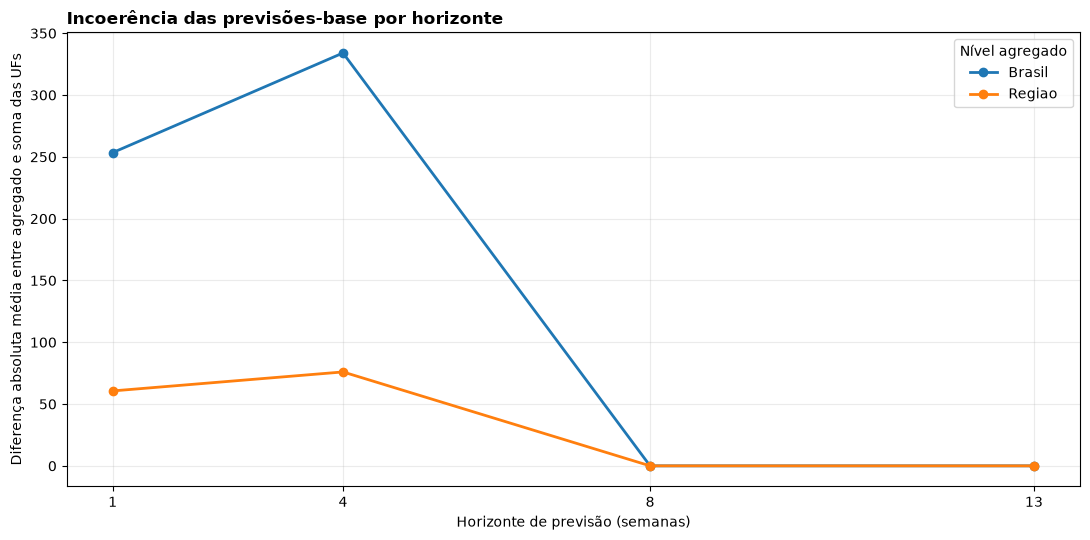

Etapa 28 concluída.
Previsões-base geradas: 7,656
Previsões esperadas por método hierárquico: 7,656
Previsões-base negativas: 0
Resultados: ..\..\execucao_local_vsr\saidas\etapa_28_previsoes_base_hierarquicas


,nivel,modelo_base,horizonte_semanas,previsoes_esperadas,previsoes_disponiveis,previsoes_negativas,percentual_disponivel
0,BRASIL,ETS_TENDENCIA_AMORTECIDA_HEURISTICO,1,58,58,0,100.0
1,BRASIL,ETS_TENDENCIA_AMORTECIDA_HEURISTICO,4,58,58,0,100.0
2,BRASIL,INGENUO_SAZONAL,8,58,58,0,100.0
3,BRASIL,INGENUO_SAZONAL,13,58,58,0,100.0
4,REGIAO,ETS_TENDENCIA_AMORTECIDA_HEURISTICO,1,290,290,0,100.0
5,REGIAO,ETS_TENDENCIA_AMORTECIDA_HEURISTICO,4,290,290,0,100.0
6,REGIAO,INGENUO_SAZONAL,8,290,290,0,100.0
7,REGIAO,INGENUO_SAZONAL,13,290,290,0,100.0
8,UF,INGENUO_SAZONAL_UF,1,1566,1566,0,100.0
9,UF,INGENUO_SAZONAL_UF,4,1566,1566,0,100.0


,nivel,modelo_base,politica_base,horizonte_semanas,nos,previsoes
0,BRASIL,ETS_TENDENCIA_AMORTECIDA_HEURISTICO,ETS_AMORTECIDO_AGREGADOS_CURTO,1,1,58
1,BRASIL,ETS_TENDENCIA_AMORTECIDA_HEURISTICO,ETS_AMORTECIDO_AGREGADOS_CURTO,4,1,58
2,BRASIL,INGENUO_SAZONAL,INGENUO_SAZONAL_AGREGADOS_LONGO,8,1,58
3,BRASIL,INGENUO_SAZONAL,INGENUO_SAZONAL_AGREGADOS_LONGO,13,1,58
4,REGIAO,ETS_TENDENCIA_AMORTECIDA_HEURISTICO,ETS_AMORTECIDO_AGREGADOS_CURTO,1,5,290
5,REGIAO,ETS_TENDENCIA_AMORTECIDA_HEURISTICO,ETS_AMORTECIDO_AGREGADOS_CURTO,4,5,290
6,REGIAO,INGENUO_SAZONAL,INGENUO_SAZONAL_AGREGADOS_LONGO,8,5,290
7,REGIAO,INGENUO_SAZONAL,INGENUO_SAZONAL_AGREGADOS_LONGO,13,5,290
8,UF,INGENUO_SAZONAL_UF,INGENUO_SAZONAL_UFS,1,27,1566
9,UF,INGENUO_SAZONAL_UF,INGENUO_SAZONAL_UFS,4,27,1566


,nivel_agregado,horizonte_semanas,comparacoes,diferenca_media,mae_incoerencia,diferenca_absoluta_maxima,previsoes_ja_coerentes,percentual_ja_coerente
0,BRASIL,1,58,98.554314,253.409544,1490.221455,0,0.000000
1,BRASIL,4,58,75.392199,334.033349,2165.926169,0,0.000000
2,BRASIL,8,58,0.000000,0.000000,0.000000,58,100.000000
3,BRASIL,13,58,0.000000,0.000000,0.000000,58,100.000000
4,REGIAO,1,290,19.516310,60.618158,829.298989,1,0.344828
5,REGIAO,4,290,15.468781,75.980889,1104.079075,0,0.000000
6,REGIAO,8,290,0.000000,0.000000,0.000000,290,100.000000
7,REGIAO,13,290,0.000000,0.000000,0.000000,290,100.000000


In [5]:
# ETAPA 28 — Previsões-base para a hierarquia geográfica

from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

BASE_DIR = Path(
    "../../execucao_local_vsr"
)

DIR_HIERARQUIA = (
    BASE_DIR
    / "saidas"
    / "etapa_27_estrutura_hierarquica"
)

DIR_BASELINES = (
    BASE_DIR
    / "saidas"
    / "etapa_21_referencias_simples"
)

DIR_ETS = (
    BASE_DIR
    / "saidas"
    / "etapa_23b_ets_inicializacao_heuristica"
)

DIR_RESULTADOS = (
    BASE_DIR
    / "saidas"
    / "etapa_28_previsoes_base_hierarquicas"
)

DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)

ARQUIVO_PAINEL = (
    DIR_HIERARQUIA
    / "painel_hierarquia_modelagem.parquet"
)

ARQUIVO_CALENDARIO = (
    DIR_HIERARQUIA
    / "calendario_validacao_hierarquica.csv"
)

ARQUIVO_BASELINES = (
    DIR_BASELINES
    / "previsoes_referencias_simples.csv"
)

ARQUIVO_ETS = (
    DIR_ETS
    / "previsoes_ets_heuristico.csv"
)

for arquivo in [
    ARQUIVO_PAINEL,
    ARQUIVO_CALENDARIO,
    ARQUIVO_BASELINES,
    ARQUIVO_ETS,
]:
    if not arquivo.exists():
        raise FileNotFoundError(
            f"Arquivo necessário não encontrado: {arquivo}"
        )

painel = pd.read_parquet(ARQUIVO_PAINEL)
calendario = pd.read_csv(ARQUIVO_CALENDARIO)
baselines = pd.read_csv(ARQUIVO_BASELINES)
ets = pd.read_csv(ARQUIVO_ETS)

for base in [painel, calendario, baselines, ets]:
    for coluna in ["nivel", "unidade", "regiao"]:
        if coluna in base.columns:
            base[coluna] = (
                base[coluna]
                .astype("string")
                .str.strip()
                .str.upper()
            )

for coluna in ["semana"]:
    if coluna in painel.columns:
        painel[coluna] = pd.to_datetime(
            painel[coluna],
            errors="coerce",
        )

for base in [calendario, baselines, ets]:
    for coluna in ["data_origem", "data_alvo"]:
        if coluna in base.columns:
            base[coluna] = pd.to_datetime(
                base[coluna],
                errors="coerce",
            )

for base in [painel, calendario, baselines, ets]:
    for coluna in [
        "casos_vsr",
        "casos_observados",
        "casos_observados_alvo",
        "previsao",
        "horizonte_semanas",
        "ano_epi",
        "semana_epi",
    ]:
        if coluna in base.columns:
            base[coluna] = pd.to_numeric(
                base[coluna],
                errors="coerce",
            )

if painel["casos_vsr"].isna().any():
    raise ValueError(
        "O painel hierárquico possui casos ausentes."
    )

if calendario[
    [
        "data_origem",
        "data_alvo",
        "casos_observados_alvo",
    ]
].isna().any().any():
    raise ValueError(
        "O calendário hierárquico possui valores ausentes."
    )

CHAVE = [
    "nivel",
    "unidade",
    "data_origem",
    "horizonte_semanas",
    "data_alvo",
]

if calendario.duplicated(CHAVE).any():
    raise ValueError(
        "O calendário hierárquico possui chaves duplicadas."
    )

calendario_agregados = calendario.loc[
    calendario["nivel"].isin(["BRASIL", "REGIAO"])
].copy()

calendario_ufs = calendario.loc[
    calendario["nivel"] == "UF"
].copy()

baselines_sazonal = (
    baselines.loc[
        baselines["modelo"] == "INGENUO_SAZONAL"
    ]
    .copy()
)

ets_amortecido = (
    ets.loc[
        ets["modelo"]
        == "ETS_TENDENCIA_AMORTECIDA_HEURISTICO"
    ]
    .copy()
)

for base in [baselines_sazonal, ets_amortecido]:
    if base.duplicated(CHAVE).any():
        raise ValueError(
            "Há duplicidades nas previsões agregadas."
        )

colunas_previsao = CHAVE + ["previsao"]

ets_amortecido = ets_amortecido[
    colunas_previsao
].rename(
    columns={"previsao": "previsao_ets"}
)

baselines_sazonal = baselines_sazonal[
    colunas_previsao
].rename(
    columns={"previsao": "previsao_sazonal"}
)

agregados_curto = (
    calendario_agregados.loc[
        calendario_agregados[
            "horizonte_semanas"
        ].isin([1, 4])
    ]
    .merge(
        ets_amortecido,
        on=CHAVE,
        how="left",
    )
)

agregados_longo = (
    calendario_agregados.loc[
        calendario_agregados[
            "horizonte_semanas"
        ].isin([8, 13])
    ]
    .merge(
        baselines_sazonal,
        on=CHAVE,
        how="left",
    )
)

if agregados_curto["previsao_ets"].isna().any():
    raise ValueError(
        "Há previsões ETS ausentes para Brasil ou regiões."
    )

if agregados_longo["previsao_sazonal"].isna().any():
    raise ValueError(
        "Há previsões sazonais ausentes para Brasil ou regiões."
    )

agregados_curto["previsao"] = (
    agregados_curto["previsao_ets"]
)

agregados_curto["modelo_base"] = (
    "ETS_TENDENCIA_AMORTECIDA_HEURISTICO"
)

agregados_curto["familia_modelo"] = "ETS"

agregados_curto["politica_base"] = (
    "ETS_AMORTECIDO_AGREGADOS_CURTO"
)

agregados_curto["data_referencia_sazonal"] = pd.NaT

agregados_longo["previsao"] = (
    agregados_longo["previsao_sazonal"]
)

agregados_longo["modelo_base"] = (
    "INGENUO_SAZONAL"
)

agregados_longo["familia_modelo"] = "BASELINE"

agregados_longo["politica_base"] = (
    "INGENUO_SAZONAL_AGREGADOS_LONGO"
)

agregados_longo["data_referencia_sazonal"] = pd.NaT

previsoes_agregadas = pd.concat(
    [agregados_curto, agregados_longo],
    ignore_index=True,
)

campos_alvo = (
    painel[
        [
            "nivel",
            "unidade",
            "semana",
            "ano_epi",
            "semana_epi",
        ]
    ]
    .rename(
        columns={
            "semana": "data_alvo",
            "ano_epi": "ano_epi_alvo",
            "semana_epi": "semana_epi_alvo",
        }
    )
)

referencias_ufs = (
    painel.loc[
        painel["nivel"] == "UF",
        [
            "unidade",
            "semana",
            "ano_epi",
            "semana_epi",
            "casos_vsr",
        ],
    ]
    .rename(
        columns={
            "semana": "data_referencia_sazonal",
            "ano_epi": "ano_epi_referencia",
            "semana_epi": "semana_epi_referencia",
            "casos_vsr": "previsao",
        }
    )
)

previsoes_ufs = calendario_ufs.merge(
    campos_alvo,
    on=[
        "nivel",
        "unidade",
        "data_alvo",
    ],
    how="left",
)

previsoes_ufs["ano_epi_referencia"] = (
    previsoes_ufs["ano_epi_alvo"] - 1
)

previsoes_ufs = previsoes_ufs.merge(
    referencias_ufs,
    on=[
        "unidade",
        "ano_epi_referencia",
    ],
    how="left",
)

previsoes_ufs = previsoes_ufs.loc[
    previsoes_ufs[
        "semana_epi_alvo"
    ].eq(
        previsoes_ufs[
            "semana_epi_referencia"
        ]
    )
].copy()

if len(previsoes_ufs) != len(calendario_ufs):
    raise ValueError(
        "A referência sazonal não foi encontrada "
        "para todas as previsões estaduais."
    )

if (
    previsoes_ufs["data_referencia_sazonal"]
    > previsoes_ufs["data_origem"]
).any():
    raise ValueError(
        "Uma referência sazonal estadual usa "
        "informação posterior à origem."
    )

if previsoes_ufs["previsao"].isna().any():
    raise ValueError(
        "Há previsões sazonais ausentes para UFs."
    )

previsoes_ufs["modelo_base"] = (
    "INGENUO_SAZONAL_UF"
)

previsoes_ufs["familia_modelo"] = "BASELINE"

previsoes_ufs["politica_base"] = (
    "INGENUO_SAZONAL_UFS"
)

colunas_finais = [
    "nivel",
    "unidade",
    "regiao",
    "tipo_no",
    "data_inicio_treino",
    "data_origem",
    "semanas_treino",
    "horizonte_semanas",
    "data_alvo",
    "casos_observados_alvo",
    "modelo_base",
    "familia_modelo",
    "politica_base",
    "data_referencia_sazonal",
    "previsao",
]

previsoes_base = pd.concat(
    [
        previsoes_agregadas[colunas_finais],
        previsoes_ufs[colunas_finais],
    ],
    ignore_index=True,
)

previsoes_base = previsoes_base.rename(
    columns={
        "casos_observados_alvo": "casos_observados",
    }
)

if len(previsoes_base) != len(calendario):
    raise ValueError(
        "A quantidade de previsões-base não "
        "corresponde ao calendário hierárquico."
    )

if previsoes_base.duplicated(CHAVE).any():
    raise ValueError(
        "Há previsões-base duplicadas."
    )

if previsoes_base[
    [
        "casos_observados",
        "previsao",
    ]
].isna().any().any():
    raise ValueError(
        "Há valores ausentes nas previsões-base."
    )

if (previsoes_base["previsao"] < 0).any():
    raise ValueError(
        "Há previsões-base negativas."
    )

previsoes_base["erro"] = (
    previsoes_base["previsao"]
    - previsoes_base["casos_observados"]
)

previsoes_base["erro_absoluto"] = (
    previsoes_base["erro"].abs()
)

chave_agregacao = [
    "data_origem",
    "horizonte_semanas",
    "data_alvo",
]

soma_ufs = (
    previsoes_base.loc[
        previsoes_base["nivel"] == "UF"
    ]
    .groupby(
        chave_agregacao,
        as_index=False,
    )["previsao"]
    .sum()
    .rename(columns={"previsao": "soma_ufs"})
)

previsao_brasil = (
    previsoes_base.loc[
        previsoes_base["nivel"] == "BRASIL",
        chave_agregacao + ["previsao"],
    ]
    .rename(columns={"previsao": "previsao_agregada"})
)

coerencia_brasil = soma_ufs.merge(
    previsao_brasil,
    on=chave_agregacao,
    how="inner",
)

coerencia_brasil["nivel_agregado"] = "BRASIL"
coerencia_brasil["unidade"] = "BRASIL"
coerencia_brasil["diferenca"] = (
    coerencia_brasil["previsao_agregada"]
    - coerencia_brasil["soma_ufs"]
)

soma_ufs_regiao = (
    previsoes_base.loc[
        previsoes_base["nivel"] == "UF"
    ]
    .groupby(
        chave_agregacao + ["regiao"],
        as_index=False,
    )["previsao"]
    .sum()
    .rename(columns={"previsao": "soma_ufs"})
)

previsao_regiao = (
    previsoes_base.loc[
        previsoes_base["nivel"] == "REGIAO",
        chave_agregacao + ["unidade", "previsao"],
    ]
    .rename(
        columns={
            "unidade": "regiao",
            "previsao": "previsao_agregada",
        }
    )
)

coerencia_regioes = soma_ufs_regiao.merge(
    previsao_regiao,
    on=chave_agregacao + ["regiao"],
    how="inner",
)

coerencia_regioes["nivel_agregado"] = "REGIAO"
coerencia_regioes["unidade"] = (
    coerencia_regioes["regiao"]
)

coerencia_regioes["diferenca"] = (
    coerencia_regioes["previsao_agregada"]
    - coerencia_regioes["soma_ufs"]
)

colunas_coerencia = [
    "nivel_agregado",
    "unidade",
    "data_origem",
    "horizonte_semanas",
    "data_alvo",
    "previsao_agregada",
    "soma_ufs",
    "diferenca",
]

coerencia = pd.concat(
    [
        coerencia_brasil[colunas_coerencia],
        coerencia_regioes[colunas_coerencia],
    ],
    ignore_index=True,
)

coerencia["diferenca_absoluta"] = (
    coerencia["diferenca"].abs()
)

resumo_coerencia = (
    coerencia
    .groupby(
        [
            "nivel_agregado",
            "horizonte_semanas",
        ],
        as_index=False,
    )
    .agg(
        comparacoes=("diferenca", "size"),
        diferenca_media=("diferenca", "mean"),
        mae_incoerencia=(
            "diferenca_absoluta",
            "mean",
        ),
        diferenca_absoluta_maxima=(
            "diferenca_absoluta",
            "max",
        ),
        previsoes_ja_coerentes=(
            "diferenca_absoluta",
            lambda serie: int(
                np.isclose(
                    serie,
                    0,
                ).sum()
            ),
        ),
    )
)

resumo_coerencia[
    "percentual_ja_coerente"
] = (
    100
    * resumo_coerencia[
        "previsoes_ja_coerentes"
    ]
    / resumo_coerencia["comparacoes"]
)

auditoria = (
    previsoes_base
    .assign(
        previsao_disponivel=(
            previsoes_base["previsao"].notna()
        )
    )
    .groupby(
        [
            "nivel",
            "modelo_base",
            "horizonte_semanas",
        ],
        as_index=False,
    )
    .agg(
        previsoes_esperadas=(
            "previsao",
            "size",
        ),
        previsoes_disponiveis=(
            "previsao_disponivel",
            "sum",
        ),
        previsoes_negativas=(
            "previsao",
            lambda serie: int(
                serie.lt(0).sum()
            ),
        ),
    )
)

auditoria["percentual_disponivel"] = (
    100
    * auditoria["previsoes_disponiveis"]
    / auditoria["previsoes_esperadas"]
)

resumo_politica = (
    previsoes_base
    .groupby(
        [
            "nivel",
            "modelo_base",
            "politica_base",
            "horizonte_semanas",
        ],
        as_index=False,
    )
    .agg(
        nos=("unidade", "nunique"),
        previsoes=("previsao", "size"),
    )
)

fig, ax = plt.subplots(figsize=(11, 5.5))

for nivel, dados in resumo_coerencia.groupby(
    "nivel_agregado"
):
    ax.plot(
        dados["horizonte_semanas"],
        dados["mae_incoerencia"],
        marker="o",
        linewidth=2,
        label=nivel.title(),
    )

ax.set_title(
    "Incoerência das previsões-base por horizonte",
    loc="left",
    fontweight="bold",
)

ax.set_xlabel("Horizonte de previsão (semanas)")
ax.set_ylabel(
    "Diferença absoluta média entre agregado e soma das UFs"
)

ax.set_xticks([1, 4, 8, 13])
ax.legend(title="Nível agregado")
ax.grid(alpha=0.25)

fig.tight_layout()

fig.savefig(
    DIR_RESULTADOS
    / "incoerencia_previsoes_base.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

previsoes_base.to_csv(
    DIR_RESULTADOS
    / "previsoes_base_hierarquicas.csv",
    index=False,
)

auditoria.to_csv(
    DIR_RESULTADOS
    / "auditoria_previsoes_base_hierarquicas.csv",
    index=False,
)

resumo_politica.to_csv(
    DIR_RESULTADOS
    / "resumo_politica_previsoes_base.csv",
    index=False,
)

coerencia.to_csv(
    DIR_RESULTADOS
    / "coerencia_previsoes_base.csv",
    index=False,
)

resumo_coerencia.to_csv(
    DIR_RESULTADOS
    / "resumo_coerencia_previsoes_base.csv",
    index=False,
)

ARQUIVO_ZIP = (
    BASE_DIR
    / "saidas"
    / "etapa_28_previsoes_base_hierarquicas.zip"
)

with ZipFile(
    ARQUIVO_ZIP,
    "w",
) as arquivo_zip:
    for arquivo in DIR_RESULTADOS.iterdir():
        arquivo_zip.write(
            arquivo,
            arcname=arquivo.name,
        )

print("Etapa 28 concluída.")
print(f"Previsões-base geradas: {len(previsoes_base):,}")
print(
    "Previsões esperadas por método hierárquico: "
    f"{len(calendario):,}"
)
print(
    "Previsões-base negativas: "
    f"{int((previsoes_base['previsao'] < 0).sum())}"
)
print(f"Resultados: {DIR_RESULTADOS}")

display(auditoria)
display(resumo_politica)
display(resumo_coerencia)

## Etapa 29 — Comparação das referências simples nas UFs

Nesta etapa, avaliaremos as referências ingênua e ingênua sazonal nas 27 Unidades da Federação.

A Etapa 28 utilizou a referência sazonal nas UFs apenas como política inicial para construir previsões-base. Isso não demonstrou que ela é a melhor escolha estadual.

Agora, as duas referências serão avaliadas com os mesmos 58 cortes temporais e quatro horizontes usados em todo o estudo. A comparação será feita por UF e também por grupo de intermitência, para verificar se o melhor método depende da proporção de semanas sem casos confirmados.

O resultado definirá a previsão-base estadual usada nas comparações hierárquicas posteriores.

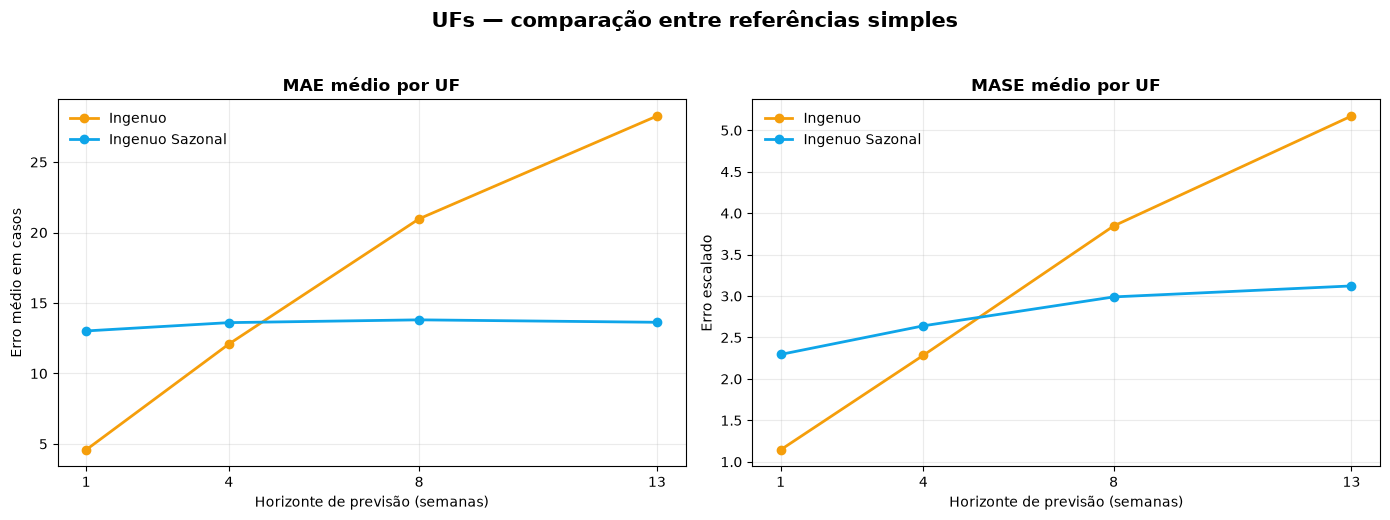

Etapa 29 concluída.
Previsões avaliadas: 12,528
Escalas MASE estaduais: 1,566
UFs comparadas: 27
Resultados: ..\..\execucao_local_vsr\saidas\etapa_29_referencias_ufs


,modelo,horizonte_semanas,ufs_avaliadas,mae_medio_ufs,rmse_medio_ufs,mase_medio_ufs,mediana_mase_ufs,ranking_mase
0,INGENUO,1,27,4.583653,7.737299,1.144810,0.783092,1
1,INGENUO,4,27,12.086845,20.260719,2.285409,2.041658,1
2,INGENUO,8,27,20.973180,33.396887,3.845417,3.578404,2
3,INGENUO,13,27,28.265006,42.411463,5.172278,4.497243,2
4,INGENUO_SAZONAL,1,27,13.017241,22.785273,2.295625,2.058179,2
5,INGENUO_SAZONAL,4,27,13.606641,23.767055,2.640867,2.184988,2
6,INGENUO_SAZONAL,8,27,13.804598,23.780137,2.989635,2.351786,1
7,INGENUO_SAZONAL,13,27,13.631545,23.131749,3.122231,2.457291,1


,horizonte_semanas,modelo_vencedor_mase,ufs_vencidas
0,1,INGENUO,27
1,4,INGENUO,22
2,4,INGENUO_SAZONAL,5
3,8,INGENUO,2
4,8,INGENUO_SAZONAL,25
5,13,INGENUO_SAZONAL,27


,grupo_intermitencia,modelo,horizonte_semanas,ufs_avaliadas,mae_medio_ufs,mase_medio_ufs,mediana_mase_ufs
0,DENSA,INGENUO,1,8,9.202586,0.552111,0.592269
4,DENSA,INGENUO_SAZONAL,1,8,29.540948,1.638085,1.493163
8,INTERMEDIARIA,INGENUO,1,6,4.454023,0.828601,0.810655
12,INTERMEDIARIA,INGENUO_SAZONAL,1,6,11.204023,1.983563,2.007340
16,INTERMITENTE,INGENUO,1,13,1.801061,1.655491,1.673413
20,INTERMITENTE,INGENUO_SAZONAL,1,13,3.685676,2.844294,3.025349
1,DENSA,INGENUO,4,8,27.827586,1.567556,1.473332
5,DENSA,INGENUO_SAZONAL,4,8,30.170259,1.717144,1.499853
9,INTERMEDIARIA,INGENUO,4,6,10.083333,1.806245,1.992725
13,INTERMEDIARIA,INGENUO_SAZONAL,4,6,11.704023,2.071752,1.997400


In [6]:
# ETAPA 29 — Comparação das referências simples nas UFs

from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

BASE_DIR = Path(
    "../../execucao_local_vsr"
)

DIR_HIERARQUIA = (
    BASE_DIR
    / "saidas"
    / "etapa_27_estrutura_hierarquica"
)

DIR_PREVISOES_BASE = (
    BASE_DIR
    / "saidas"
    / "etapa_28_previsoes_base_hierarquicas"
)

DIR_RESULTADOS = (
    BASE_DIR
    / "saidas"
    / "etapa_29_referencias_ufs"
)

DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)

ARQUIVO_PAINEL = (
    DIR_HIERARQUIA
    / "painel_hierarquia_modelagem.parquet"
)

ARQUIVO_CALENDARIO = (
    DIR_HIERARQUIA
    / "calendario_validacao_hierarquica.csv"
)

ARQUIVO_PERFIL_UFS = (
    DIR_HIERARQUIA
    / "perfil_ufs_hierarquia.csv"
)

ARQUIVO_PREVISOES_BASE = (
    DIR_PREVISOES_BASE
    / "previsoes_base_hierarquicas.csv"
)

for arquivo in [
    ARQUIVO_PAINEL,
    ARQUIVO_CALENDARIO,
    ARQUIVO_PERFIL_UFS,
    ARQUIVO_PREVISOES_BASE,
]:
    if not arquivo.exists():
        raise FileNotFoundError(
            f"Arquivo necessário não encontrado: {arquivo}"
        )

painel = pd.read_parquet(ARQUIVO_PAINEL)
calendario = pd.read_csv(ARQUIVO_CALENDARIO)
perfil_ufs = pd.read_csv(ARQUIVO_PERFIL_UFS)
previsoes_base = pd.read_csv(ARQUIVO_PREVISOES_BASE)

for base in [
    painel,
    calendario,
    perfil_ufs,
    previsoes_base,
]:
    for coluna in ["nivel", "unidade", "regiao"]:
        if coluna in base.columns:
            base[coluna] = (
                base[coluna]
                .astype("string")
                .str.strip()
                .str.upper()
            )

painel["semana"] = pd.to_datetime(
    painel["semana"],
    errors="coerce",
)

for base in [
    calendario,
    previsoes_base,
]:
    for coluna in ["data_origem", "data_alvo"]:
        if coluna in base.columns:
            base[coluna] = pd.to_datetime(
                base[coluna],
                errors="coerce",
            )

for base in [
    painel,
    calendario,
    perfil_ufs,
    previsoes_base,
]:
    for coluna in [
        "casos_vsr",
        "casos_observados",
        "casos_observados_alvo",
        "previsao",
        "horizonte_semanas",
        "ano_epi",
        "semana_epi",
        "percentual_semanas_zero",
    ]:
        if coluna in base.columns:
            base[coluna] = pd.to_numeric(
                base[coluna],
                errors="coerce",
            )

painel_ufs = painel.loc[
    painel["nivel"] == "UF"
].copy()

calendario_ufs = calendario.loc[
    calendario["nivel"] == "UF"
].copy()

sazonal_ufs = previsoes_base.loc[
    previsoes_base["nivel"] == "UF"
].copy()

CHAVE = [
    "nivel",
    "unidade",
    "data_origem",
    "horizonte_semanas",
    "data_alvo",
]

if len(calendario_ufs) != 6264:
    raise ValueError(
        "O calendário deveria possuir 6.264 previsões estaduais."
    )

if calendario_ufs.duplicated(CHAVE).any():
    raise ValueError(
        "Há duplicidades no calendário estadual."
    )

if painel_ufs.duplicated(
    ["unidade", "semana"]
).any():
    raise ValueError(
        "Há duplicidades no painel semanal das UFs."
    )

if painel_ufs["casos_vsr"].isna().any():
    raise ValueError(
        "Há casos ausentes no painel estadual."
    )

if sazonal_ufs.duplicated(CHAVE).any():
    raise ValueError(
        "Há duplicidades nas previsões sazonais estaduais."
    )

if sazonal_ufs["previsao"].isna().any():
    raise ValueError(
        "Há previsões sazonais estaduais ausentes."
    )

origens_ufs = (
    calendario_ufs[
        [
            "unidade",
            "regiao",
            "data_origem",
        ]
    ]
    .drop_duplicates()
    .sort_values(
        [
            "unidade",
            "data_origem",
        ]
    )
    .reset_index(drop=True)
)

def calcular_escala_mase_sazonal(treino):
    treino = treino.sort_values("semana").copy()

    valores_por_semana = {
        (
            int(linha.ano_epi),
            int(linha.semana_epi),
        ): float(linha.casos_vsr)
        for linha in treino.itertuples(index=False)
    }

    erros_sazonais = []

    for linha in treino.itertuples(index=False):
        chave_anterior = (
            int(linha.ano_epi) - 1,
            int(linha.semana_epi),
        )

        if chave_anterior in valores_por_semana:
            erro = abs(
                float(linha.casos_vsr)
                - valores_por_semana[
                    chave_anterior
                ]
            )

            erros_sazonais.append(erro)

    if len(erros_sazonais) == 0:
        return np.nan, 0

    return float(np.mean(erros_sazonais)), len(
        erros_sazonais
    )

escalas_mase = []
previsoes_ingenuas = []

series_ufs = {
    unidade: dados.sort_values("semana").copy()
    for unidade, dados in painel_ufs.groupby("unidade")
}

for linha in origens_ufs.itertuples(index=False):

    serie = series_ufs[linha.unidade]

    treino = serie.loc[
        serie["semana"] <= linha.data_origem
    ].copy()

    if treino.empty:
        raise ValueError(
            "Não existe treino para "
            f"{linha.unidade} em "
            f"{linha.data_origem.date()}."
        )

    escala, comparacoes_sazonais = (
        calcular_escala_mase_sazonal(treino)
    )

    escalas_mase.append(
        {
            "nivel": "UF",
            "unidade": linha.unidade,
            "regiao": linha.regiao,
            "data_origem": linha.data_origem,
            "semanas_treino": len(treino),
            "comparacoes_sazonais_treino": (
                comparacoes_sazonais
            ),
            "escala_mase_sazonal": escala,
        }
    )

    previsoes_ingenuas.append(
        {
            "nivel": "UF",
            "unidade": linha.unidade,
            "data_origem": linha.data_origem,
            "previsao_ingenua": float(
                treino.iloc[-1]["casos_vsr"]
            ),
        }
    )

escalas_mase = pd.DataFrame(escalas_mase)

previsoes_ingenuas = pd.DataFrame(
    previsoes_ingenuas
)

if escalas_mase[
    "escala_mase_sazonal"
].isna().any():
    raise ValueError(
        "Não foi possível calcular MASE "
        "para alguma UF/origem."
    )

if (
    escalas_mase[
        "escala_mase_sazonal"
    ] <= 0
).any():
    raise ValueError(
        "Foi encontrada escala MASE "
        "menor ou igual a zero."
    )

previsoes_ingenuas = calendario_ufs.merge(
    previsoes_ingenuas,
    on=[
        "nivel",
        "unidade",
        "data_origem",
    ],
    how="left",
)

previsoes_ingenuas = previsoes_ingenuas.rename(
    columns={
        "previsao_ingenua": "previsao",
    }
)

previsoes_ingenuas["modelo"] = "INGENUO"

previsoes_sazonais = sazonal_ufs[
    [
        "nivel",
        "unidade",
        "regiao",
        "data_origem",
        "horizonte_semanas",
        "data_alvo",
        "casos_observados",
        "previsao",
        "data_referencia_sazonal",
    ]
].copy()

previsoes_sazonais["modelo"] = (
    "INGENUO_SAZONAL"
)

previsoes_ingenuas = previsoes_ingenuas[
    [
        "nivel",
        "unidade",
        "regiao",
        "data_origem",
        "horizonte_semanas",
        "data_alvo",
        "casos_observados_alvo",
        "previsao",
        "modelo",
    ]
].rename(
    columns={
        "casos_observados_alvo": "casos_observados",
    }
)

previsoes_ingenuas[
    "data_referencia_sazonal"
] = pd.NaT

previsoes = pd.concat(
    [
        previsoes_ingenuas,
        previsoes_sazonais,
    ],
    ignore_index=True,
)

if len(previsoes) != 12528:
    raise ValueError(
        "A quantidade de previsões deveria ser 12.528."
    )

if previsoes.duplicated(
    CHAVE[:-1] + ["modelo"]
).any():
    raise ValueError(
        "Há previsões duplicadas "
        "por modelo estadual."
    )

if previsoes[
    [
        "casos_observados",
        "previsao",
    ]
].isna().any().any():
    raise ValueError(
        "Há previsões estaduais ausentes."
    )

if (previsoes["previsao"] < 0).any():
    raise ValueError(
        "Há previsões estaduais negativas."
    )

erros = previsoes.merge(
    escalas_mase[
        [
            "nivel",
            "unidade",
            "data_origem",
            "semanas_treino",
            "comparacoes_sazonais_treino",
            "escala_mase_sazonal",
        ]
    ],
    on=[
        "nivel",
        "unidade",
        "data_origem",
    ],
    how="left",
    validate="many_to_one",
)

if erros["escala_mase_sazonal"].isna().any():
    raise ValueError(
        "Há previsões sem escala MASE."
    )

erros["erro"] = (
    erros["previsao"]
    - erros["casos_observados"]
)

erros["erro_absoluto"] = erros["erro"].abs()

erros["erro_quadratico"] = erros["erro"] ** 2

erros["mase_individual"] = (
    erros["erro_absoluto"]
    / erros["escala_mase_sazonal"]
)

metricas_por_uf = (
    erros
    .groupby(
        [
            "unidade",
            "regiao",
            "modelo",
            "horizonte_semanas",
        ],
        as_index=False,
    )
    .agg(
        avaliacoes=("erro_absoluto", "size"),
        mae=("erro_absoluto", "mean"),
        rmse=(
            "erro_quadratico",
            lambda valores: float(
                np.sqrt(np.mean(valores))
            ),
        ),
        mase=("mase_individual", "mean"),
    )
)

metricas_macro = (
    metricas_por_uf
    .groupby(
        [
            "modelo",
            "horizonte_semanas",
        ],
        as_index=False,
    )
    .agg(
        ufs_avaliadas=("unidade", "nunique"),
        mae_medio_ufs=("mae", "mean"),
        rmse_medio_ufs=("rmse", "mean"),
        mase_medio_ufs=("mase", "mean"),
        mediana_mase_ufs=("mase", "median"),
    )
)

metricas_macro["ranking_mase"] = (
    metricas_macro
    .groupby("horizonte_semanas")[
        "mase_medio_ufs"
    ]
    .rank(
        method="dense",
        ascending=True,
    )
    .astype(int)
)

def classificar_intermitencia(percentual_zero):
    if percentual_zero > 50:
        return "INTERMITENTE"
    if percentual_zero > 25:
        return "INTERMEDIARIA"
    return "DENSA"

perfil_ufs["grupo_intermitencia"] = (
    perfil_ufs[
        "percentual_semanas_zero"
    ]
    .apply(classificar_intermitencia)
)

metricas_por_uf = metricas_por_uf.merge(
    perfil_ufs[
        [
            "unidade",
            "grupo_intermitencia",
            "percentual_semanas_zero",
        ]
    ],
    on="unidade",
    how="left",
    validate="many_to_one",
)

metricas_por_intermitencia = (
    metricas_por_uf
    .groupby(
        [
            "grupo_intermitencia",
            "modelo",
            "horizonte_semanas",
        ],
        as_index=False,
    )
    .agg(
        ufs_avaliadas=("unidade", "nunique"),
        mae_medio_ufs=("mae", "mean"),
        mase_medio_ufs=("mase", "mean"),
        mediana_mase_ufs=("mase", "median"),
    )
)

comparacao_ufs = metricas_por_uf.pivot(
    index=[
        "unidade",
        "regiao",
        "horizonte_semanas",
        "grupo_intermitencia",
        "percentual_semanas_zero",
    ],
    columns="modelo",
    values="mase",
).reset_index()

comparacao_ufs.columns.name = None

comparacao_ufs["modelo_vencedor_mase"] = np.where(
    comparacao_ufs["INGENUO"]
    <= comparacao_ufs["INGENUO_SAZONAL"],
    "INGENUO",
    "INGENUO_SAZONAL",
)

comparacao_ufs["diferenca_mase_sazonal_menos_ingenuo"] = (
    comparacao_ufs["INGENUO_SAZONAL"]
    - comparacao_ufs["INGENUO"]
)

resumo_vencedores = (
    comparacao_ufs
    .groupby(
        [
            "horizonte_semanas",
            "modelo_vencedor_mase",
        ],
        as_index=False,
    )
    .agg(
        ufs_vencidas=("unidade", "nunique")
    )
)

fig, eixos = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(14, 5),
)

ordem_horizontes = [1, 4, 8, 13]

for modelo, cor in [
    ("INGENUO", "#F59E0B"),
    ("INGENUO_SAZONAL", "#0EA5E9"),
]:
    dados = (
        metricas_macro.loc[
            metricas_macro["modelo"] == modelo
        ]
        .set_index("horizonte_semanas")
        .reindex(ordem_horizontes)
    )

    eixos[0].plot(
        ordem_horizontes,
        dados["mae_medio_ufs"],
        marker="o",
        linewidth=2,
        label=modelo.replace("_", " ").title(),
        color=cor,
    )

    eixos[1].plot(
        ordem_horizontes,
        dados["mase_medio_ufs"],
        marker="o",
        linewidth=2,
        label=modelo.replace("_", " ").title(),
        color=cor,
    )

eixos[0].set_title(
    "MAE médio por UF",
    fontweight="bold",
)

eixos[0].set_ylabel("Erro médio em casos")

eixos[1].set_title(
    "MASE médio por UF",
    fontweight="bold",
)

eixos[1].set_ylabel("Erro escalado")

for eixo in eixos:
    eixo.set_xlabel("Horizonte de previsão (semanas)")
    eixo.set_xticks(ordem_horizontes)
    eixo.grid(alpha=0.25)
    eixo.legend(frameon=False)

fig.suptitle(
    "UFs — comparação entre referências simples",
    fontsize=15,
    fontweight="bold",
    y=1.03,
)

fig.tight_layout()

fig.savefig(
    DIR_RESULTADOS
    / "comparacao_referencias_ufs.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

previsoes.to_csv(
    DIR_RESULTADOS
    / "previsoes_referencias_ufs.csv",
    index=False,
)

escalas_mase.to_csv(
    DIR_RESULTADOS
    / "escalas_mase_ufs_por_origem.csv",
    index=False,
)

erros.to_csv(
    DIR_RESULTADOS
    / "erros_individuais_referencias_ufs.csv",
    index=False,
)

metricas_por_uf.to_csv(
    DIR_RESULTADOS
    / "metricas_por_uf_modelo_horizonte.csv",
    index=False,
)

metricas_macro.to_csv(
    DIR_RESULTADOS
    / "metricas_macro_referencias_ufs.csv",
    index=False,
)

metricas_por_intermitencia.to_csv(
    DIR_RESULTADOS
    / "metricas_por_intermitencia_referencias_ufs.csv",
    index=False,
)

comparacao_ufs.to_csv(
    DIR_RESULTADOS
    / "comparacao_mase_por_uf.csv",
    index=False,
)

resumo_vencedores.to_csv(
    DIR_RESULTADOS
    / "resumo_vencedores_ufs.csv",
    index=False,
)

ARQUIVO_ZIP = (
    BASE_DIR
    / "saidas"
    / "etapa_29_referencias_ufs.zip"
)

with ZipFile(
    ARQUIVO_ZIP,
    "w",
) as arquivo_zip:
    for arquivo in DIR_RESULTADOS.iterdir():
        arquivo_zip.write(
            arquivo,
            arcname=arquivo.name,
        )

print("Etapa 29 concluída.")
print(
    "Previsões avaliadas: "
    f"{len(previsoes):,}"
)
print(
    "Escalas MASE estaduais: "
    f"{len(escalas_mase):,}"
)
print(
    "UFs comparadas: "
    f"{metricas_por_uf['unidade'].nunique()}"
)
print(f"Resultados: {DIR_RESULTADOS}")

display(metricas_macro)
display(resumo_vencedores)
display(
    metricas_por_intermitencia.sort_values(
        [
            "horizonte_semanas",
            "grupo_intermitencia",
            "mase_medio_ufs",
        ]
    )
)

## Etapa 30 — Reconstrução das previsões-base hierárquicas

Nesta etapa, reconstruiremos as previsões-base para Brasil, regiões e UFs usando as políticas validadas nas etapas anteriores.

Para Brasil e regiões, manteremos ETS com tendência amortecida em um e quatro semanas, e a referência sazonal em oito e 13 semanas.

Para as UFs, usaremos a referência ingênua em um e quatro semanas e a referência sazonal em oito e 13 semanas. Essa regra foi definida após a comparação formal da Etapa 29.

O objetivo é obter uma nova versão das previsões-base, completa e auditada, que será usada nos métodos de reconciliação hierárquica.

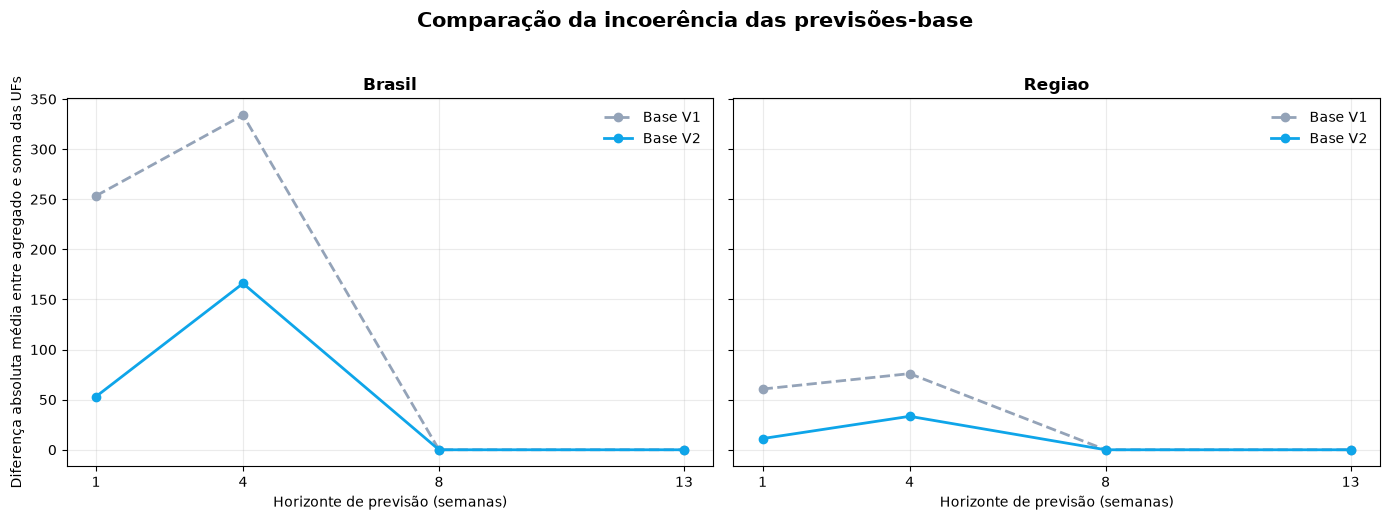

Etapa 30 concluída.
Previsões-base V2: 7,656
Previsões negativas: 0
Resultados: ..\..\execucao_local_vsr\saidas\etapa_30_previsoes_base_hierarquicas_v2


,nivel,modelo_base,horizonte_semanas,previsoes_esperadas,previsoes_disponiveis,previsoes_negativas,percentual_disponivel
0,BRASIL,ETS_TENDENCIA_AMORTECIDA_HEURISTICO,1,58,58,0,100.0
1,BRASIL,ETS_TENDENCIA_AMORTECIDA_HEURISTICO,4,58,58,0,100.0
2,BRASIL,INGENUO_SAZONAL,8,58,58,0,100.0
3,BRASIL,INGENUO_SAZONAL,13,58,58,0,100.0
4,REGIAO,ETS_TENDENCIA_AMORTECIDA_HEURISTICO,1,290,290,0,100.0
5,REGIAO,ETS_TENDENCIA_AMORTECIDA_HEURISTICO,4,290,290,0,100.0
6,REGIAO,INGENUO_SAZONAL,8,290,290,0,100.0
7,REGIAO,INGENUO_SAZONAL,13,290,290,0,100.0
8,UF,INGENUO,1,1566,1566,0,100.0
9,UF,INGENUO,4,1566,1566,0,100.0


,nivel,modelo_base,politica_base,horizonte_semanas,nos,previsoes,mae
0,BRASIL,ETS_TENDENCIA_AMORTECIDA_HEURISTICO,ETS_AMORTECIDO_AGREGADOS_CURTO,1,1,58,49.421366
1,BRASIL,ETS_TENDENCIA_AMORTECIDA_HEURISTICO,ETS_AMORTECIDO_AGREGADOS_CURTO,4,1,58,176.102473
2,BRASIL,INGENUO_SAZONAL,INGENUO_SAZONAL_AGREGADOS_LONGO,8,1,58,247.896552
3,BRASIL,INGENUO_SAZONAL,INGENUO_SAZONAL_AGREGADOS_LONGO,13,1,58,236.741379
4,REGIAO,ETS_TENDENCIA_AMORTECIDA_HEURISTICO,ETS_AMORTECIDO_AGREGADOS_CURTO,1,5,290,15.994000
5,REGIAO,ETS_TENDENCIA_AMORTECIDA_HEURISTICO,ETS_AMORTECIDO_AGREGADOS_CURTO,4,5,290,43.379882
6,REGIAO,INGENUO_SAZONAL,INGENUO_SAZONAL_AGREGADOS_LONGO,8,5,290,58.165517
7,REGIAO,INGENUO_SAZONAL,INGENUO_SAZONAL_AGREGADOS_LONGO,13,5,290,59.589655
8,UF,INGENUO,INGENUO_UFS_CURTO,1,27,1566,4.583653
9,UF,INGENUO,INGENUO_UFS_CURTO,4,27,1566,12.086845


,nivel_agregado,horizonte_semanas,comparacoes,diferenca_media,mae_incoerencia,diferenca_absoluta_maxima,previsoes_ja_coerentes,percentual_ja_coerente
0,BRASIL,1,58,6.812935,53.117520,220.360236,0,0.000000
1,BRASIL,4,58,21.599095,166.022672,667.969210,0,0.000000
2,BRASIL,8,58,0.000000,0.000000,0.000000,58,100.000000
3,BRASIL,13,58,0.000000,0.000000,0.000000,58,100.000000
4,REGIAO,1,290,1.168034,11.172959,105.894715,3,1.034483
5,REGIAO,4,290,4.710160,33.387778,378.091920,2,0.689655
6,REGIAO,8,290,0.000000,0.000000,0.000000,290,100.000000
7,REGIAO,13,290,0.000000,0.000000,0.000000,290,100.000000


,nivel_agregado,horizonte_semanas,comparacoes_v1,diferenca_media_v1,mae_incoerencia_v1,diferenca_absoluta_maxima_v1,previsoes_ja_coerentes_v1,percentual_ja_coerente_v1,comparacoes_v2,diferenca_media_v2,mae_incoerencia_v2,diferenca_absoluta_maxima_v2,previsoes_ja_coerentes_v2,percentual_ja_coerente_v2,reducao_mae_incoerencia
0,BRASIL,1,58,98.554314,253.409544,1490.221455,0,0.000000,58,6.812935,53.117520,220.360236,0,0.000000,200.292025
1,BRASIL,4,58,75.392199,334.033349,2165.926169,0,0.000000,58,21.599095,166.022672,667.969210,0,0.000000,168.010677
2,BRASIL,8,58,0.000000,0.000000,0.000000,58,100.000000,58,0.000000,0.000000,0.000000,58,100.000000,0.000000
3,BRASIL,13,58,0.000000,0.000000,0.000000,58,100.000000,58,0.000000,0.000000,0.000000,58,100.000000,0.000000
4,REGIAO,1,290,19.516310,60.618158,829.298989,1,0.344828,290,1.168034,11.172959,105.894715,3,1.034483,49.445199
5,REGIAO,4,290,15.468781,75.980889,1104.079075,0,0.000000,290,4.710160,33.387778,378.091920,2,0.689655,42.593111
6,REGIAO,8,290,0.000000,0.000000,0.000000,290,100.000000,290,0.000000,0.000000,0.000000,290,100.000000,0.000000
7,REGIAO,13,290,0.000000,0.000000,0.000000,290,100.000000,290,0.000000,0.000000,0.000000,290,100.000000,0.000000


In [7]:
# ETAPA 30 — Reconstrução das previsões-base hierárquicas

from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

BASE_DIR = Path(
    "../../execucao_local_vsr"
)

DIR_HIERARQUIA = (
    BASE_DIR
    / "saidas"
    / "etapa_27_estrutura_hierarquica"
)

DIR_BASE_V1 = (
    BASE_DIR
    / "saidas"
    / "etapa_28_previsoes_base_hierarquicas"
)

DIR_BASELINES = (
    BASE_DIR
    / "saidas"
    / "etapa_21_referencias_simples"
)

DIR_ETS = (
    BASE_DIR
    / "saidas"
    / "etapa_23b_ets_inicializacao_heuristica"
)

DIR_REFERENCIAS_UF = (
    BASE_DIR
    / "saidas"
    / "etapa_29_referencias_ufs"
)

DIR_RESULTADOS = (
    BASE_DIR
    / "saidas"
    / "etapa_30_previsoes_base_hierarquicas_v2"
)

DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)

ARQUIVO_CALENDARIO = (
    DIR_HIERARQUIA
    / "calendario_validacao_hierarquica.csv"
)

ARQUIVO_BASE_V1 = (
    DIR_BASE_V1
    / "resumo_coerencia_previsoes_base.csv"
)

ARQUIVO_BASELINES = (
    DIR_BASELINES
    / "previsoes_referencias_simples.csv"
)

ARQUIVO_ETS = (
    DIR_ETS
    / "previsoes_ets_heuristico.csv"
)

ARQUIVO_REFERENCIAS_UF = (
    DIR_REFERENCIAS_UF
    / "previsoes_referencias_ufs.csv"
)

for arquivo in [
    ARQUIVO_CALENDARIO,
    ARQUIVO_BASE_V1,
    ARQUIVO_BASELINES,
    ARQUIVO_ETS,
    ARQUIVO_REFERENCIAS_UF,
]:
    if not arquivo.exists():
        raise FileNotFoundError(
            f"Arquivo necessário não encontrado: {arquivo}"
        )

calendario = pd.read_csv(ARQUIVO_CALENDARIO)
resumo_coerencia_v1 = pd.read_csv(ARQUIVO_BASE_V1)
baselines = pd.read_csv(ARQUIVO_BASELINES)
ets = pd.read_csv(ARQUIVO_ETS)
referencias_uf = pd.read_csv(
    ARQUIVO_REFERENCIAS_UF
)

for base in [
    calendario,
    baselines,
    ets,
    referencias_uf,
]:
    for coluna in ["nivel", "unidade", "regiao"]:
        if coluna in base.columns:
            base[coluna] = (
                base[coluna]
                .astype("string")
                .str.strip()
                .str.upper()
            )

for base in [
    calendario,
    baselines,
    ets,
    referencias_uf,
]:
    for coluna in ["data_origem", "data_alvo"]:
        if coluna in base.columns:
            base[coluna] = pd.to_datetime(
                base[coluna],
                errors="coerce",
            )

for base in [
    calendario,
    baselines,
    ets,
    referencias_uf,
]:
    for coluna in [
        "casos_observados",
        "casos_observados_alvo",
        "previsao",
        "horizonte_semanas",
    ]:
        if coluna in base.columns:
            base[coluna] = pd.to_numeric(
                base[coluna],
                errors="coerce",
            )

CHAVE = [
    "nivel",
    "unidade",
    "data_origem",
    "horizonte_semanas",
    "data_alvo",
]

if calendario.duplicated(CHAVE).any():
    raise ValueError(
        "Há duplicidades no calendário hierárquico."
    )

if len(calendario) != 7656:
    raise ValueError(
        "O calendário deveria possuir 7.656 linhas."
    )

calendario_agregados = calendario.loc[
    calendario["nivel"].isin(["BRASIL", "REGIAO"])
].copy()

calendario_ufs = calendario.loc[
    calendario["nivel"] == "UF"
].copy()

ets_amortecido = ets.loc[
    ets["modelo"]
    == "ETS_TENDENCIA_AMORTECIDA_HEURISTICO"
].copy()

sazonal_agregados = baselines.loc[
    baselines["modelo"] == "INGENUO_SAZONAL"
].copy()

ingenuo_ufs = referencias_uf.loc[
    referencias_uf["modelo"] == "INGENUO"
].copy()

sazonal_ufs = referencias_uf.loc[
    referencias_uf["modelo"] == "INGENUO_SAZONAL"
].copy()

for base in [
    ets_amortecido,
    sazonal_agregados,
    ingenuo_ufs,
    sazonal_ufs,
]:
    if base.duplicated(CHAVE).any():
        raise ValueError(
            "Uma das fontes possui previsões duplicadas."
        )

def selecionar_previsoes(
    calendario_origem,
    fonte,
    horizontes,
    modelo_base,
    familia_modelo,
    politica_base,
):
    selecao = calendario_origem.loc[
        calendario_origem[
            "horizonte_semanas"
        ].isin(horizontes)
    ].copy()

    fonte = fonte[
        CHAVE + ["previsao"]
    ].copy()

    selecao = selecao.merge(
        fonte,
        on=CHAVE,
        how="left",
        validate="one_to_one",
    )

    if selecao["previsao"].isna().any():
        raise ValueError(
            "Há previsões ausentes na política "
            f"{politica_base}."
        )

    selecao["modelo_base"] = modelo_base
    selecao["familia_modelo"] = familia_modelo
    selecao["politica_base"] = politica_base

    return selecao

agregados_curto = selecionar_previsoes(
    calendario_agregados,
    ets_amortecido,
    [1, 4],
    "ETS_TENDENCIA_AMORTECIDA_HEURISTICO",
    "ETS",
    "ETS_AMORTECIDO_AGREGADOS_CURTO",
)

agregados_longo = selecionar_previsoes(
    calendario_agregados,
    sazonal_agregados,
    [8, 13],
    "INGENUO_SAZONAL",
    "BASELINE",
    "INGENUO_SAZONAL_AGREGADOS_LONGO",
)

ufs_curto = selecionar_previsoes(
    calendario_ufs,
    ingenuo_ufs,
    [1, 4],
    "INGENUO",
    "BASELINE",
    "INGENUO_UFS_CURTO",
)

ufs_longo = selecionar_previsoes(
    calendario_ufs,
    sazonal_ufs,
    [8, 13],
    "INGENUO_SAZONAL",
    "BASELINE",
    "INGENUO_SAZONAL_UFS_LONGO",
)

previsoes_base_v2 = pd.concat(
    [
        agregados_curto,
        agregados_longo,
        ufs_curto,
        ufs_longo,
    ],
    ignore_index=True,
)

previsoes_base_v2 = previsoes_base_v2.rename(
    columns={
        "casos_observados_alvo": "casos_observados",
    }
)

if len(previsoes_base_v2) != len(calendario):
    raise ValueError(
        "A quantidade de previsões-base V2 "
        "não corresponde ao calendário."
    )

if previsoes_base_v2.duplicated(CHAVE).any():
    raise ValueError(
        "Há previsões-base V2 duplicadas."
    )

if previsoes_base_v2[
    [
        "casos_observados",
        "previsao",
    ]
].isna().any().any():
    raise ValueError(
        "Há valores ausentes nas previsões-base V2."
    )

if (previsoes_base_v2["previsao"] < 0).any():
    raise ValueError(
        "Há previsões-base V2 negativas."
    )

previsoes_base_v2["erro"] = (
    previsoes_base_v2["previsao"]
    - previsoes_base_v2["casos_observados"]
)

previsoes_base_v2["erro_absoluto"] = (
    previsoes_base_v2["erro"].abs()
)

chave_agregacao = [
    "data_origem",
    "horizonte_semanas",
    "data_alvo",
]

soma_ufs = (
    previsoes_base_v2.loc[
        previsoes_base_v2["nivel"] == "UF"
    ]
    .groupby(
        chave_agregacao,
        as_index=False,
    )["previsao"]
    .sum()
    .rename(columns={"previsao": "soma_ufs"})
)

previsao_brasil = (
    previsoes_base_v2.loc[
        previsoes_base_v2["nivel"] == "BRASIL",
        chave_agregacao + ["previsao"],
    ]
    .rename(columns={"previsao": "previsao_agregada"})
)

coerencia_brasil = soma_ufs.merge(
    previsao_brasil,
    on=chave_agregacao,
    how="inner",
)

coerencia_brasil["nivel_agregado"] = "BRASIL"
coerencia_brasil["unidade"] = "BRASIL"
coerencia_brasil["diferenca"] = (
    coerencia_brasil["previsao_agregada"]
    - coerencia_brasil["soma_ufs"]
)

soma_ufs_regiao = (
    previsoes_base_v2.loc[
        previsoes_base_v2["nivel"] == "UF"
    ]
    .groupby(
        chave_agregacao + ["regiao"],
        as_index=False,
    )["previsao"]
    .sum()
    .rename(columns={"previsao": "soma_ufs"})
)

previsao_regiao = (
    previsoes_base_v2.loc[
        previsoes_base_v2["nivel"] == "REGIAO",
        chave_agregacao + ["unidade", "previsao"],
    ]
    .rename(
        columns={
            "unidade": "regiao",
            "previsao": "previsao_agregada",
        }
    )
)

coerencia_regioes = soma_ufs_regiao.merge(
    previsao_regiao,
    on=chave_agregacao + ["regiao"],
    how="inner",
)

coerencia_regioes["nivel_agregado"] = "REGIAO"
coerencia_regioes["unidade"] = (
    coerencia_regioes["regiao"]
)

coerencia_regioes["diferenca"] = (
    coerencia_regioes["previsao_agregada"]
    - coerencia_regioes["soma_ufs"]
)

colunas_coerencia = [
    "nivel_agregado",
    "unidade",
    "data_origem",
    "horizonte_semanas",
    "data_alvo",
    "previsao_agregada",
    "soma_ufs",
    "diferenca",
]

coerencia_v2 = pd.concat(
    [
        coerencia_brasil[colunas_coerencia],
        coerencia_regioes[colunas_coerencia],
    ],
    ignore_index=True,
)

coerencia_v2["diferenca_absoluta"] = (
    coerencia_v2["diferenca"].abs()
)

resumo_coerencia_v2 = (
    coerencia_v2
    .groupby(
        [
            "nivel_agregado",
            "horizonte_semanas",
        ],
        as_index=False,
    )
    .agg(
        comparacoes=("diferenca", "size"),
        diferenca_media=("diferenca", "mean"),
        mae_incoerencia=(
            "diferenca_absoluta",
            "mean",
        ),
        diferenca_absoluta_maxima=(
            "diferenca_absoluta",
            "max",
        ),
        previsoes_ja_coerentes=(
            "diferenca_absoluta",
            lambda serie: int(
                np.isclose(serie, 0).sum()
            ),
        ),
    )
)

resumo_coerencia_v2[
    "percentual_ja_coerente"
] = (
    100
    * resumo_coerencia_v2[
        "previsoes_ja_coerentes"
    ]
    / resumo_coerencia_v2["comparacoes"]
)

comparacao_coerencia = resumo_coerencia_v1.merge(
    resumo_coerencia_v2,
    on=[
        "nivel_agregado",
        "horizonte_semanas",
    ],
    suffixes=("_v1", "_v2"),
    validate="one_to_one",
)

comparacao_coerencia[
    "reducao_mae_incoerencia"
] = (
    comparacao_coerencia[
        "mae_incoerencia_v1"
    ]
    - comparacao_coerencia[
        "mae_incoerencia_v2"
    ]
)

auditoria = (
    previsoes_base_v2
    .assign(
        previsao_disponivel=(
            previsoes_base_v2["previsao"].notna()
        )
    )
    .groupby(
        [
            "nivel",
            "modelo_base",
            "horizonte_semanas",
        ],
        as_index=False,
    )
    .agg(
        previsoes_esperadas=(
            "previsao",
            "size",
        ),
        previsoes_disponiveis=(
            "previsao_disponivel",
            "sum",
        ),
        previsoes_negativas=(
            "previsao",
            lambda serie: int(
                serie.lt(0).sum()
            ),
        ),
    )
)

auditoria["percentual_disponivel"] = (
    100
    * auditoria["previsoes_disponiveis"]
    / auditoria["previsoes_esperadas"]
)

resumo_politica = (
    previsoes_base_v2
    .groupby(
        [
            "nivel",
            "modelo_base",
            "politica_base",
            "horizonte_semanas",
        ],
        as_index=False,
    )
    .agg(
        nos=("unidade", "nunique"),
        previsoes=("previsao", "size"),
        mae=("erro_absoluto", "mean"),
    )
)

fig, eixos = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(14, 5),
    sharey=True,
)

for eixo, nivel in zip(
    eixos,
    ["BRASIL", "REGIAO"],
):
    dados = comparacao_coerencia.loc[
        comparacao_coerencia["nivel_agregado"] == nivel
    ].sort_values("horizonte_semanas")

    eixo.plot(
        dados["horizonte_semanas"],
        dados["mae_incoerencia_v1"],
        marker="o",
        linestyle="--",
        linewidth=2,
        label="Base V1",
        color="#94A3B8",
    )

    eixo.plot(
        dados["horizonte_semanas"],
        dados["mae_incoerencia_v2"],
        marker="o",
        linewidth=2,
        label="Base V2",
        color="#0EA5E9",
    )

    eixo.set_title(
        nivel.title(),
        fontweight="bold",
    )

    eixo.set_xlabel(
        "Horizonte de previsão (semanas)"
    )

    eixo.set_xticks([1, 4, 8, 13])
    eixo.grid(alpha=0.25)
    eixo.legend(frameon=False)

eixos[0].set_ylabel(
    "Diferença absoluta média entre agregado e soma das UFs"
)

fig.suptitle(
    "Comparação da incoerência das previsões-base",
    fontsize=15,
    fontweight="bold",
    y=1.03,
)

fig.tight_layout()

fig.savefig(
    DIR_RESULTADOS
    / "comparacao_incoerencia_base_v1_v2.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

previsoes_base_v2.to_csv(
    DIR_RESULTADOS
    / "previsoes_base_hierarquicas_v2.csv",
    index=False,
)

auditoria.to_csv(
    DIR_RESULTADOS
    / "auditoria_previsoes_base_hierarquicas_v2.csv",
    index=False,
)

resumo_politica.to_csv(
    DIR_RESULTADOS
    / "resumo_politica_previsoes_base_v2.csv",
    index=False,
)

coerencia_v2.to_csv(
    DIR_RESULTADOS
    / "coerencia_previsoes_base_v2.csv",
    index=False,
)

resumo_coerencia_v2.to_csv(
    DIR_RESULTADOS
    / "resumo_coerencia_previsoes_base_v2.csv",
    index=False,
)

comparacao_coerencia.to_csv(
    DIR_RESULTADOS
    / "comparacao_incoerencia_base_v1_v2.csv",
    index=False,
)

ARQUIVO_ZIP = (
    BASE_DIR
    / "saidas"
    / "etapa_30_previsoes_base_hierarquicas_v2.zip"
)

with ZipFile(
    ARQUIVO_ZIP,
    "w",
) as arquivo_zip:
    for arquivo in DIR_RESULTADOS.iterdir():
        arquivo_zip.write(
            arquivo,
            arcname=arquivo.name,
        )

print("Etapa 30 concluída.")
print(
    "Previsões-base V2: "
    f"{len(previsoes_base_v2):,}"
)
print(
    "Previsões negativas: "
    f"{int((previsoes_base_v2['previsao'] < 0).sum())}"
)
print(f"Resultados: {DIR_RESULTADOS}")

display(auditoria)
display(resumo_politica)
display(resumo_coerencia_v2)
display(comparacao_coerencia)

## Etapa 31 — Reconciliação hierárquica bottom-up

Nesta etapa, aplicaremos o método bottom-up. As previsões das 27 UFs serão mantidas e somadas para formar previsões das cinco regiões e do Brasil.

O método garante coerência geográfica por construção: a previsão nacional será igual à soma das previsões estaduais, e cada região será igual à soma das UFs que a compõem.

A avaliação mostrará se a coerência obtida pelo bottom-up melhora ou piora a precisão de Brasil e regiões em relação às previsões-base diretas.

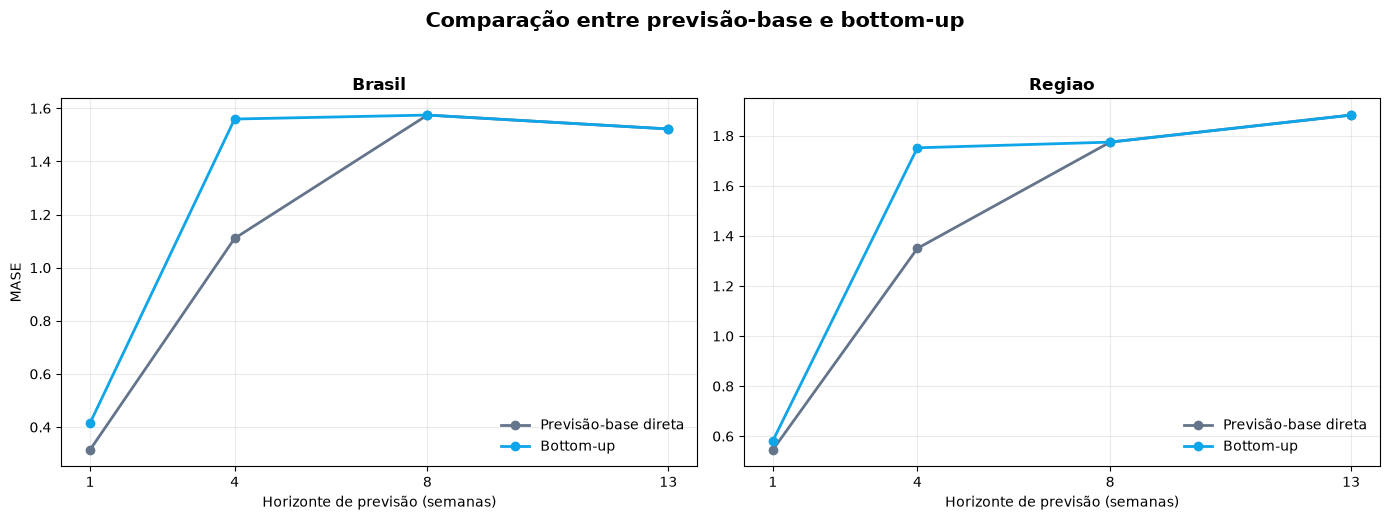

Etapa 31 concluída.
Previsões reconciliadas: 7,656
Coerência máxima encontrada: 0.000000
Resultados: ..\..\execucao_local_vsr\saidas\etapa_31_reconciliacao_bottom_up


,nivel_agregado,unidade,comparacoes,diferenca_absoluta_maxima,comparacoes_coerentes,percentual_coerente
0,BRASIL,BRASIL,232,0.0,232,100.0
1,REGIAO,CENTRO_OESTE,232,0.0,232,100.0
2,REGIAO,NORDESTE,232,0.0,232,100.0
3,REGIAO,NORTE,232,0.0,232,100.0
4,REGIAO,SUDESTE,232,0.0,232,100.0
5,REGIAO,SUL,232,0.0,232,100.0


,nivel,horizonte_semanas,mae_BASE_V2,mae_BOTTOM_UP,rmse_BASE_V2,rmse_BOTTOM_UP,mase_BASE_V2,mase_BOTTOM_UP,delta_mae_bottom_up_menos_base,delta_rmse_bottom_up_menos_base,delta_mase_bottom_up_menos_base
0,BRASIL,1,49.421366,66.310345,76.061587,95.458783,0.314634,0.415409,16.888978,19.397197,0.100775
1,BRASIL,4,176.102473,253.448276,290.842676,379.276762,1.110469,1.559690,77.345803,88.434086,0.449221
2,BRASIL,8,247.896552,247.896552,397.367111,397.367111,1.574582,1.574582,0.000000,0.000000,0.000000
3,BRASIL,13,236.741379,236.741379,371.797614,371.797614,1.522343,1.522343,0.000000,0.000000,0.000000
4,REGIAO,1,15.994000,17.441379,27.623395,30.040547,0.545830,0.582126,1.447380,2.417152,0.036296
5,REGIAO,4,43.379882,58.737931,89.563897,104.526849,1.350174,1.751825,15.358049,14.962952,0.401651
6,REGIAO,8,58.165517,58.165517,116.241900,116.241900,1.774511,1.774511,0.000000,0.000000,0.000000
7,REGIAO,13,59.589655,59.589655,113.966556,113.966556,1.882562,1.882562,0.000000,0.000000,0.000000
8,UF,1,4.583653,4.583653,9.533098,9.533098,1.144810,1.144810,0.000000,0.000000,0.000000
9,UF,4,12.086845,12.086845,29.069521,29.069521,2.285409,2.285409,0.000000,0.000000,0.000000


,nivel,horizonte_semanas,previsoes,previsoes_ausentes,previsoes_negativas
0,BRASIL,1,58,0,0
1,BRASIL,4,58,0,0
2,BRASIL,8,58,0,0
3,BRASIL,13,58,0,0
4,REGIAO,1,290,0,0
5,REGIAO,4,290,0,0
6,REGIAO,8,290,0,0
7,REGIAO,13,290,0,0
8,UF,1,1566,0,0
9,UF,4,1566,0,0


In [8]:
# ETAPA 31 — Reconciliação hierárquica bottom-up

from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

BASE_DIR = Path(
    "../../execucao_local_vsr"
)

DIR_BASE_V2 = (
    BASE_DIR
    / "saidas"
    / "etapa_30_previsoes_base_hierarquicas_v2"
)

DIR_MASE_AGREGADOS = (
    BASE_DIR
    / "saidas"
    / "etapa_22_metricas_referencias"
)

DIR_MASE_UFS = (
    BASE_DIR
    / "saidas"
    / "etapa_29_referencias_ufs"
)

DIR_RESULTADOS = (
    BASE_DIR
    / "saidas"
    / "etapa_31_reconciliacao_bottom_up"
)

DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)

ARQUIVO_BASE_V2 = (
    DIR_BASE_V2
    / "previsoes_base_hierarquicas_v2.csv"
)

ARQUIVO_ESCALAS_AGREGADOS = (
    DIR_MASE_AGREGADOS
    / "escalas_mase_por_origem.csv"
)

ARQUIVO_ESCALAS_UFS = (
    DIR_MASE_UFS
    / "escalas_mase_ufs_por_origem.csv"
)

for arquivo in [
    ARQUIVO_BASE_V2,
    ARQUIVO_ESCALAS_AGREGADOS,
    ARQUIVO_ESCALAS_UFS,
]:
    if not arquivo.exists():
        raise FileNotFoundError(
            f"Arquivo necessário não encontrado: {arquivo}"
        )

base_v2 = pd.read_csv(ARQUIVO_BASE_V2)
escalas_agregados = pd.read_csv(
    ARQUIVO_ESCALAS_AGREGADOS
)
escalas_ufs = pd.read_csv(
    ARQUIVO_ESCALAS_UFS
)

for base in [
    base_v2,
    escalas_agregados,
    escalas_ufs,
]:
    for coluna in ["nivel", "unidade", "regiao"]:
        if coluna in base.columns:
            base[coluna] = (
                base[coluna]
                .astype("string")
                .str.strip()
                .str.upper()
            )

for base in [
    base_v2,
    escalas_agregados,
    escalas_ufs,
]:
    if "data_origem" in base.columns:
        base["data_origem"] = pd.to_datetime(
            base["data_origem"],
            errors="coerce",
        )

for base in [base_v2]:
    if "data_alvo" in base.columns:
        base["data_alvo"] = pd.to_datetime(
            base["data_alvo"],
            errors="coerce",
        )

for base in [
    base_v2,
    escalas_agregados,
    escalas_ufs,
]:
    for coluna in [
        "casos_observados",
        "previsao",
        "horizonte_semanas",
        "escala_mase_sazonal",
    ]:
        if coluna in base.columns:
            base[coluna] = pd.to_numeric(
                base[coluna],
                errors="coerce",
            )

CHAVE = [
    "nivel",
    "unidade",
    "data_origem",
    "horizonte_semanas",
    "data_alvo",
]

CHAVE_AGREGACAO = [
    "data_origem",
    "horizonte_semanas",
    "data_alvo",
]

if len(base_v2) != 7656:
    raise ValueError(
        "A base V2 deveria possuir 7.656 previsões."
    )

if base_v2.duplicated(CHAVE).any():
    raise ValueError(
        "Há previsões duplicadas na base V2."
    )

if base_v2[
    [
        "casos_observados",
        "previsao",
    ]
].isna().any().any():
    raise ValueError(
        "A base V2 possui valores ausentes."
    )

if (base_v2["previsao"] < 0).any():
    raise ValueError(
        "A base V2 possui previsões negativas."
    )

previsoes = base_v2.copy()

previsoes["previsao_base"] = (
    previsoes["previsao"]
)

soma_ufs_brasil = (
    previsoes.loc[
        previsoes["nivel"] == "UF"
    ]
    .groupby(
        CHAVE_AGREGACAO,
        as_index=False,
    )["previsao_base"]
    .sum()
    .rename(
        columns={
            "previsao_base": "previsao_bottom_up_brasil"
        }
    )
)

soma_ufs_regioes = (
    previsoes.loc[
        previsoes["nivel"] == "UF"
    ]
    .groupby(
        CHAVE_AGREGACAO + ["regiao"],
        as_index=False,
    )["previsao_base"]
    .sum()
    .rename(
        columns={
            "previsao_base": "previsao_bottom_up_regiao"
        }
    )
)

previsoes = previsoes.merge(
    soma_ufs_brasil,
    on=CHAVE_AGREGACAO,
    how="left",
    validate="many_to_one",
)

previsoes = previsoes.merge(
    soma_ufs_regioes,
    on=CHAVE_AGREGACAO + ["regiao"],
    how="left",
    validate="many_to_one",
)

previsoes["previsao_reconciliada"] = (
    previsoes["previsao_base"]
)

mascara_brasil = previsoes["nivel"] == "BRASIL"

mascara_regiao = previsoes["nivel"] == "REGIAO"

previsoes.loc[
    mascara_brasil,
    "previsao_reconciliada",
] = previsoes.loc[
    mascara_brasil,
    "previsao_bottom_up_brasil",
]

previsoes.loc[
    mascara_regiao,
    "previsao_reconciliada",
] = previsoes.loc[
    mascara_regiao,
    "previsao_bottom_up_regiao",
]

if previsoes[
    "previsao_reconciliada"
].isna().any():
    raise ValueError(
        "Há previsões bottom-up ausentes."
    )

if (
    previsoes["previsao_reconciliada"] < 0
).any():
    raise ValueError(
        "Foram encontradas previsões bottom-up negativas."
    )

previsoes["erro_base"] = (
    previsoes["previsao_base"]
    - previsoes["casos_observados"]
)

previsoes["erro_bottom_up"] = (
    previsoes["previsao_reconciliada"]
    - previsoes["casos_observados"]
)

previsoes["erro_absoluto_base"] = (
    previsoes["erro_base"].abs()
)

previsoes["erro_absoluto_bottom_up"] = (
    previsoes["erro_bottom_up"].abs()
)

previsoes["erro_quadratico_base"] = (
    previsoes["erro_base"] ** 2
)

previsoes["erro_quadratico_bottom_up"] = (
    previsoes["erro_bottom_up"] ** 2
)

previsoes["metodo_reconciliacao"] = "BOTTOM_UP"

validacao_brasil = (
    previsoes.loc[
        previsoes["nivel"] == "BRASIL",
        CHAVE_AGREGACAO + ["previsao_reconciliada"],
    ]
    .merge(
        soma_ufs_brasil,
        on=CHAVE_AGREGACAO,
        how="inner",
    )
)

validacao_brasil["diferenca"] = (
    validacao_brasil["previsao_reconciliada"]
    - validacao_brasil["previsao_bottom_up_brasil"]
)

validacoes_regioes = []

for regiao in sorted(
    previsoes.loc[
        previsoes["nivel"] == "REGIAO",
        "unidade",
    ].unique()
):
    previsao_regiao = previsoes.loc[
        (
            previsoes["nivel"] == "REGIAO"
        )
        & (
            previsoes["unidade"] == regiao
        ),
        CHAVE_AGREGACAO + ["previsao_reconciliada"],
    ]

    soma_regiao = soma_ufs_regioes.loc[
        soma_ufs_regioes["regiao"] == regiao,
        CHAVE_AGREGACAO + [
            "previsao_bottom_up_regiao"
        ],
    ]

    comparacao = previsao_regiao.merge(
        soma_regiao,
        on=CHAVE_AGREGACAO,
        how="inner",
    )

    comparacao["diferenca"] = (
        comparacao["previsao_reconciliada"]
        - comparacao["previsao_bottom_up_regiao"]
    )

    validacoes_regioes.append(
        {
            "nivel_agregado": "REGIAO",
            "unidade": regiao,
            "comparacoes": len(comparacao),
            "diferenca_absoluta_maxima": float(
                comparacao["diferenca"].abs().max()
            ),
            "comparacoes_coerentes": int(
                np.isclose(
                    comparacao["diferenca"],
                    0,
                ).sum()
            ),
        }
    )

validacao_coerencia = pd.DataFrame(
    [
        {
            "nivel_agregado": "BRASIL",
            "unidade": "BRASIL",
            "comparacoes": len(validacao_brasil),
            "diferenca_absoluta_maxima": float(
                validacao_brasil[
                    "diferenca"
                ].abs().max()
            ),
            "comparacoes_coerentes": int(
                np.isclose(
                    validacao_brasil["diferenca"],
                    0,
                ).sum()
            ),
        },
        *validacoes_regioes,
    ]
)

validacao_coerencia[
    "percentual_coerente"
] = (
    100
    * validacao_coerencia[
        "comparacoes_coerentes"
    ]
    / validacao_coerencia["comparacoes"]
)

if not np.isclose(
    validacao_coerencia[
        "diferenca_absoluta_maxima"
    ],
    0,
).all():
    raise ValueError(
        "A reconciliação bottom-up não ficou coerente."
    )

escalas = pd.concat(
    [
        escalas_agregados,
        escalas_ufs,
    ],
    ignore_index=True,
)

escalas = escalas[
    [
        "nivel",
        "unidade",
        "data_origem",
        "escala_mase_sazonal",
    ]
].copy()

if escalas.duplicated(
    [
        "nivel",
        "unidade",
        "data_origem",
    ]
).any():
    raise ValueError(
        "Há escalas MASE duplicadas."
    )

previsoes = previsoes.merge(
    escalas,
    on=[
        "nivel",
        "unidade",
        "data_origem",
    ],
    how="left",
    validate="many_to_one",
)

if previsoes[
    "escala_mase_sazonal"
].isna().any():
    raise ValueError(
        "Há previsões sem escala MASE."
    )

if (
    previsoes["escala_mase_sazonal"] <= 0
).any():
    raise ValueError(
        "Há escala MASE menor ou igual a zero."
    )

previsoes["mase_individual_base"] = (
    previsoes["erro_absoluto_base"]
    / previsoes["escala_mase_sazonal"]
)

previsoes["mase_individual_bottom_up"] = (
    previsoes["erro_absoluto_bottom_up"]
    / previsoes["escala_mase_sazonal"]
)

def calcular_metricas(base, estrategia):
    if estrategia == "BASE_V2":
        erro_absoluto = "erro_absoluto_base"
        erro_quadratico = "erro_quadratico_base"
        mase = "mase_individual_base"
    else:
        erro_absoluto = "erro_absoluto_bottom_up"
        erro_quadratico = "erro_quadratico_bottom_up"
        mase = "mase_individual_bottom_up"

    resultado = (
        base
        .groupby(
            [
                "nivel",
                "horizonte_semanas",
            ],
            as_index=False,
        )
        .agg(
            avaliacoes=(erro_absoluto, "size"),
            mae=(erro_absoluto, "mean"),
            rmse=(
                erro_quadratico,
                lambda valores: float(
                    np.sqrt(np.mean(valores))
                ),
            ),
            mase=(mase, "mean"),
        )
    )

    resultado["estrategia"] = estrategia

    return resultado

metricas_base = calcular_metricas(
    previsoes,
    "BASE_V2",
)

metricas_bottom_up = calcular_metricas(
    previsoes,
    "BOTTOM_UP",
)

metricas_comparadas = pd.concat(
    [
        metricas_base,
        metricas_bottom_up,
    ],
    ignore_index=True,
)

comparacao_metricas = metricas_comparadas.pivot(
    index=[
        "nivel",
        "horizonte_semanas",
    ],
    columns="estrategia",
    values=[
        "mae",
        "rmse",
        "mase",
    ],
).reset_index()

comparacao_metricas.columns = [
    "_".join(
        [
            str(parte)
            for parte in coluna
            if parte != ""
        ]
    ).rstrip("_")
    for coluna in comparacao_metricas.columns
]

for metrica in ["mae", "rmse", "mase"]:
    comparacao_metricas[
        f"delta_{metrica}_bottom_up_menos_base"
    ] = (
        comparacao_metricas[
            f"{metrica}_BOTTOM_UP"
        ]
        - comparacao_metricas[
            f"{metrica}_BASE_V2"
        ]
    )

auditoria = (
    previsoes
    .groupby(
        [
            "nivel",
            "horizonte_semanas",
        ],
        as_index=False,
    )
    .agg(
        previsoes=("previsao_reconciliada", "size"),
        previsoes_ausentes=(
            "previsao_reconciliada",
            lambda serie: int(serie.isna().sum()),
        ),
        previsoes_negativas=(
            "previsao_reconciliada",
            lambda serie: int(serie.lt(0).sum()),
        ),
    )
)

previsoes.to_csv(
    DIR_RESULTADOS
    / "previsoes_bottom_up.csv",
    index=False,
)

validacao_coerencia.to_csv(
    DIR_RESULTADOS
    / "validacao_coerencia_bottom_up.csv",
    index=False,
)

metricas_comparadas.to_csv(
    DIR_RESULTADOS
    / "metricas_base_v2_e_bottom_up.csv",
    index=False,
)

comparacao_metricas.to_csv(
    DIR_RESULTADOS
    / "comparacao_base_v2_bottom_up.csv",
    index=False,
)

auditoria.to_csv(
    DIR_RESULTADOS
    / "auditoria_bottom_up.csv",
    index=False,
)

fig, eixos = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(14, 5),
)

for eixo, nivel in zip(
    eixos,
    ["BRASIL", "REGIAO"],
):
    dados = comparacao_metricas.loc[
        comparacao_metricas["nivel"] == nivel
    ].sort_values("horizonte_semanas")

    eixo.plot(
        dados["horizonte_semanas"],
        dados["mase_BASE_V2"],
        marker="o",
        linewidth=2,
        label="Previsão-base direta",
        color="#64748B",
    )

    eixo.plot(
        dados["horizonte_semanas"],
        dados["mase_BOTTOM_UP"],
        marker="o",
        linewidth=2,
        label="Bottom-up",
        color="#0EA5E9",
    )

    eixo.set_title(
        nivel.title(),
        fontweight="bold",
    )

    eixo.set_xlabel(
        "Horizonte de previsão (semanas)"
    )

    eixo.set_xticks([1, 4, 8, 13])
    eixo.grid(alpha=0.25)
    eixo.legend(frameon=False)

eixos[0].set_ylabel("MASE")

fig.suptitle(
    "Comparação entre previsão-base e bottom-up",
    fontsize=15,
    fontweight="bold",
    y=1.03,
)

fig.tight_layout()

try:
    fig.savefig(
        DIR_RESULTADOS
        / "comparacao_base_v2_bottom_up.png",
        dpi=120,
    )
except Exception as erro_grafico:
    print(
        "Os arquivos tabulares foram salvos, mas "
        "a imagem não pôde ser gravada:"
    )
    print(erro_grafico)

plt.show()
plt.close(fig)

ARQUIVO_ZIP = (
    BASE_DIR
    / "saidas"
    / "etapa_31_reconciliacao_bottom_up.zip"
)

with ZipFile(
    ARQUIVO_ZIP,
    "w",
) as arquivo_zip:
    for arquivo in DIR_RESULTADOS.iterdir():
        if arquivo.is_file():
            arquivo_zip.write(
                arquivo,
                arcname=arquivo.name,
            )

print("Etapa 31 concluída.")
print(
    "Previsões reconciliadas: "
    f"{len(previsoes):,}"
)
print(
    "Coerência máxima encontrada: "
    f"{validacao_coerencia['diferenca_absoluta_maxima'].max():.6f}"
)
print(f"Resultados: {DIR_RESULTADOS}")

display(validacao_coerencia)
display(comparacao_metricas)
display(auditoria)

## Etapa 32 — Reconciliação top-down com proporções históricas

Nesta etapa, aplicaremos métodos top-down. A previsão direta do Brasil será preservada e distribuída para regiões e UFs por proporções estimadas somente com dados disponíveis até cada origem temporal.

Serão comparadas duas versões: uma com participação histórica global e outra com participação sazonal, calculada a partir da mesma semana epidemiológica de anos anteriores.

As previsões resultantes serão coerentes por construção. A avaliação mostrará se preservar a informação nacional melhora a previsão dos agregados e se a distribuição para as UFs permanece útil.

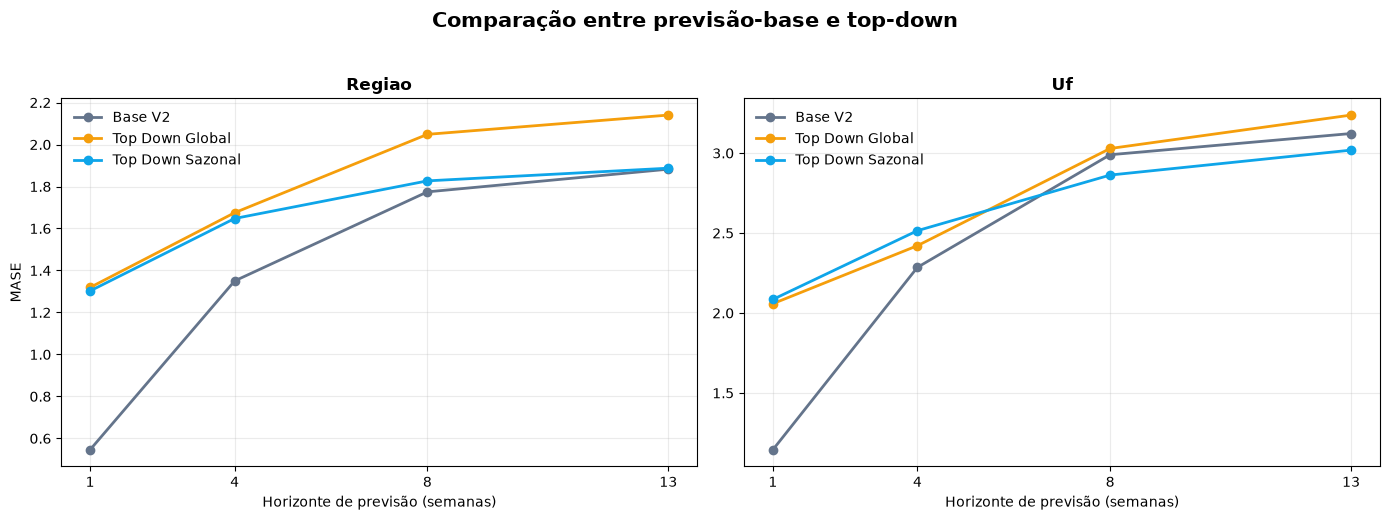

Etapa 32 concluída.
Previsões top-down geradas: 15,312
Previsões por método: 7,656
Resultados: ..\..\execucao_local_vsr\saidas\etapa_32_reconciliacao_top_down


,nivel_agregado,metodo_reconciliacao,comparacoes,diferenca_absoluta_maxima,comparacoes_coerentes,percentual_coerente
0,BRASIL,TOP_DOWN_GLOBAL,232,5.684342e-14,232,100.0
1,BRASIL,TOP_DOWN_SAZONAL,232,1.136868e-13,232,100.0
2,REGIAO,TOP_DOWN_GLOBAL,1160,0.000000e+00,1160,100.0
3,REGIAO,TOP_DOWN_SAZONAL,1160,0.000000e+00,1160,100.0


,nivel,horizonte_semanas,mae_BASE_V2,mae_TOP_DOWN_GLOBAL,mae_TOP_DOWN_SAZONAL,rmse_BASE_V2,rmse_TOP_DOWN_GLOBAL,rmse_TOP_DOWN_SAZONAL,mase_BASE_V2,mase_TOP_DOWN_GLOBAL,mase_TOP_DOWN_SAZONAL,delta_top_down_global_menos_base_mae,delta_top_down_sazonal_menos_base_mae,delta_top_down_global_menos_base_rmse,delta_top_down_sazonal_menos_base_rmse,delta_top_down_global_menos_base_mase,delta_top_down_sazonal_menos_base_mase
0,BRASIL,1,49.421366,49.421366,49.421366,76.061587,76.061587,76.061587,0.314634,0.314634,0.314634,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,BRASIL,4,176.102473,176.102473,176.102473,290.842676,290.842676,290.842676,1.110469,1.110469,1.110469,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,BRASIL,8,247.896552,247.896552,247.896552,397.367111,397.367111,397.367111,1.574582,1.574582,1.574582,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,BRASIL,13,236.741379,236.741379,236.741379,371.797614,371.797614,371.797614,1.522343,1.522343,1.522343,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,REGIAO,1,15.994000,37.923533,36.265928,27.623395,65.645307,69.349430,0.545830,1.319119,1.302464,21.929534,20.271928,38.021912,41.726035,0.773290,0.756635
5,REGIAO,4,43.379882,54.120177,51.764855,89.563897,103.194704,101.843771,1.350174,1.675233,1.647615,10.740295,8.384973,13.630807,12.279875,0.325059,0.297441
6,REGIAO,8,58.165517,59.317068,58.211353,116.241900,109.558260,114.792878,1.774511,2.048574,1.826884,1.151550,0.045835,-6.683640,-1.449022,0.274063,0.052373
7,REGIAO,13,59.589655,60.848769,58.023580,113.966556,107.976371,112.042077,1.882562,2.140379,1.887345,1.259113,-1.566075,-5.990185,-1.924479,0.257817,0.004784
8,UF,1,4.583653,10.168029,9.609575,9.533098,24.698148,21.785633,1.144810,2.058156,2.084825,5.584376,5.025922,15.165050,12.252535,0.913346,0.940015
9,UF,4,12.086845,12.549723,12.253243,29.069521,34.516975,31.427150,2.285409,2.420875,2.514832,0.462877,0.166397,5.447454,2.357629,0.135466,0.229424


,metodo_reconciliacao,nivel,horizonte_semanas,previsoes,previsoes_ausentes,previsoes_negativas
0,TOP_DOWN_GLOBAL,BRASIL,1,58,0,0
1,TOP_DOWN_GLOBAL,BRASIL,4,58,0,0
2,TOP_DOWN_GLOBAL,BRASIL,8,58,0,0
3,TOP_DOWN_GLOBAL,BRASIL,13,58,0,0
4,TOP_DOWN_GLOBAL,REGIAO,1,290,0,0
5,TOP_DOWN_GLOBAL,REGIAO,4,290,0,0
6,TOP_DOWN_GLOBAL,REGIAO,8,290,0,0
7,TOP_DOWN_GLOBAL,REGIAO,13,290,0,0
8,TOP_DOWN_GLOBAL,UF,1,1566,0,0
9,TOP_DOWN_GLOBAL,UF,4,1566,0,0


In [9]:
# ETAPA 32 — Reconciliação top-down com proporções históricas

from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

BASE_DIR = Path(
    "../../execucao_local_vsr"
)

DIR_HIERARQUIA = (
    BASE_DIR
    / "saidas"
    / "etapa_27_estrutura_hierarquica"
)

DIR_BASE_V2 = (
    BASE_DIR
    / "saidas"
    / "etapa_30_previsoes_base_hierarquicas_v2"
)

DIR_MASE_AGREGADOS = (
    BASE_DIR
    / "saidas"
    / "etapa_22_metricas_referencias"
)

DIR_MASE_UFS = (
    BASE_DIR
    / "saidas"
    / "etapa_29_referencias_ufs"
)

DIR_RESULTADOS = (
    BASE_DIR
    / "saidas"
    / "etapa_32_reconciliacao_top_down"
)

DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)

ARQUIVO_PAINEL = (
    DIR_HIERARQUIA
    / "painel_hierarquia_modelagem.parquet"
)

ARQUIVO_BASE_V2 = (
    DIR_BASE_V2
    / "previsoes_base_hierarquicas_v2.csv"
)

ARQUIVO_ESCALAS_AGREGADOS = (
    DIR_MASE_AGREGADOS
    / "escalas_mase_por_origem.csv"
)

ARQUIVO_ESCALAS_UFS = (
    DIR_MASE_UFS
    / "escalas_mase_ufs_por_origem.csv"
)

for arquivo in [
    ARQUIVO_PAINEL,
    ARQUIVO_BASE_V2,
    ARQUIVO_ESCALAS_AGREGADOS,
    ARQUIVO_ESCALAS_UFS,
]:
    if not arquivo.exists():
        raise FileNotFoundError(
            f"Arquivo necessário não encontrado: {arquivo}"
        )

painel = pd.read_parquet(ARQUIVO_PAINEL)
base_v2 = pd.read_csv(ARQUIVO_BASE_V2)
escalas_agregados = pd.read_csv(
    ARQUIVO_ESCALAS_AGREGADOS
)
escalas_ufs = pd.read_csv(
    ARQUIVO_ESCALAS_UFS
)

for base in [
    painel,
    base_v2,
    escalas_agregados,
    escalas_ufs,
]:
    for coluna in ["nivel", "unidade", "regiao"]:
        if coluna in base.columns:
            base[coluna] = (
                base[coluna]
                .astype("string")
                .str.strip()
                .str.upper()
            )

painel["semana"] = pd.to_datetime(
    painel["semana"],
    errors="coerce",
)

for base in [
    base_v2,
    escalas_agregados,
    escalas_ufs,
]:
    if "data_origem" in base.columns:
        base["data_origem"] = pd.to_datetime(
            base["data_origem"],
            errors="coerce",
        )

if "data_alvo" in base_v2.columns:
    base_v2["data_alvo"] = pd.to_datetime(
        base_v2["data_alvo"],
        errors="coerce",
    )

for base in [
    painel,
    base_v2,
    escalas_agregados,
    escalas_ufs,
]:
    for coluna in [
        "casos_vsr",
        "casos_observados",
        "previsao",
        "horizonte_semanas",
        "ano_epi",
        "semana_epi",
        "escala_mase_sazonal",
    ]:
        if coluna in base.columns:
            base[coluna] = pd.to_numeric(
                base[coluna],
                errors="coerce",
            )

CHAVE = [
    "nivel",
    "unidade",
    "data_origem",
    "horizonte_semanas",
    "data_alvo",
]

CHAVE_AGREGACAO = [
    "data_origem",
    "horizonte_semanas",
    "data_alvo",
]

if len(base_v2) != 7656:
    raise ValueError(
        "A base V2 deveria possuir 7.656 previsões."
    )

if base_v2.duplicated(CHAVE).any():
    raise ValueError(
        "Há previsões duplicadas na base V2."
    )

painel_ufs = painel.loc[
    painel["nivel"] == "UF"
].copy()

painel_brasil = painel.loc[
    painel["nivel"] == "BRASIL"
].copy()

ufs = sorted(painel_ufs["unidade"].unique())

regiao_por_uf = (
    painel_ufs[
        ["unidade", "regiao"]
    ]
    .drop_duplicates()
    .set_index("unidade")["regiao"]
    .to_dict()
)

origens_brasil = (
    base_v2.loc[
        base_v2["nivel"] == "BRASIL",
        [
            "data_origem",
            "horizonte_semanas",
            "data_alvo",
            "previsao",
        ],
    ]
    .rename(columns={"previsao": "previsao_brasil_base"})
    .sort_values(
        [
            "data_origem",
            "horizonte_semanas",
        ]
    )
    .reset_index(drop=True)
)

if len(origens_brasil) != 232:
    raise ValueError(
        "São esperadas 232 previsões nacionais."
    )

alvos_brasil = painel_brasil[
    [
        "semana",
        "ano_epi",
        "semana_epi",
    ]
].rename(
    columns={
        "semana": "data_alvo",
        "ano_epi": "ano_epi_alvo",
        "semana_epi": "semana_epi_alvo",
    }
)

origens_brasil = origens_brasil.merge(
    alvos_brasil,
    on="data_alvo",
    how="left",
    validate="many_to_one",
)

if origens_brasil[
    [
        "ano_epi_alvo",
        "semana_epi_alvo",
    ]
].isna().any().any():
    raise ValueError(
        "Não foi possível identificar a semana epidemiológica do alvo."
    )

registros_top_down = []
auditoria_proporcoes = []

for linha in origens_brasil.itertuples(index=False):

    treino_ufs = painel_ufs.loc[
        painel_ufs["semana"] <= linha.data_origem
    ].copy()

    total_global = treino_ufs["casos_vsr"].sum()

    if total_global <= 0:
        raise ValueError(
            "O total histórico estadual não pode ser zero."
        )

    proporcao_global = (
        treino_ufs
        .groupby("unidade")["casos_vsr"]
        .sum()
        / total_global
    ).reindex(ufs, fill_value=0.0)

    treino_sazonal = treino_ufs.loc[
        (
            treino_ufs["ano_epi"]
            < linha.ano_epi_alvo
        )
        & (
            treino_ufs["semana_epi"]
            == linha.semana_epi_alvo
        )
    ].copy()

    total_sazonal = treino_sazonal["casos_vsr"].sum()

    if total_sazonal > 0:
        proporcao_sazonal = (
            treino_sazonal
            .groupby("unidade")["casos_vsr"]
            .sum()
            / total_sazonal
        ).reindex(ufs, fill_value=0.0)

        fonte_sazonal = "SAZONAL_HISTORICO"

    else:
        proporcao_sazonal = proporcao_global.copy()

        fonte_sazonal = "FALLBACK_GLOBAL"

    metodos = [
        (
            "TOP_DOWN_GLOBAL",
            "GLOBAL_HISTORICO",
            proporcao_global,
        ),
        (
            "TOP_DOWN_SAZONAL",
            fonte_sazonal,
            proporcao_sazonal,
        ),
    ]

    for metodo, fonte, proporcoes in metodos:

        if not np.isclose(proporcoes.sum(), 1):
            raise ValueError(
                "As proporções top-down não somam 1."
            )

        previsoes_uf = (
            linha.previsao_brasil_base
            * proporcoes
        )

        previsoes_regiao = (
            previsoes_uf
            .groupby(
                [
                    regiao_por_uf[uf]
                    for uf in previsoes_uf.index
                ]
            )
            .sum()
        )

        registros_top_down.append(
            {
                "nivel": "BRASIL",
                "unidade": "BRASIL",
                "data_origem": linha.data_origem,
                "horizonte_semanas": linha.horizonte_semanas,
                "data_alvo": linha.data_alvo,
                "metodo_reconciliacao": metodo,
                "fonte_proporcao": fonte,
                "previsao_reconciliada": (
                    linha.previsao_brasil_base
                ),
            }
        )

        for regiao, previsao_regiao in (
            previsoes_regiao.items()
        ):
            registros_top_down.append(
                {
                    "nivel": "REGIAO",
                    "unidade": regiao,
                    "data_origem": linha.data_origem,
                    "horizonte_semanas": (
                        linha.horizonte_semanas
                    ),
                    "data_alvo": linha.data_alvo,
                    "metodo_reconciliacao": metodo,
                    "fonte_proporcao": fonte,
                    "previsao_reconciliada": previsao_regiao,
                }
            )

        for uf, previsao_uf in previsoes_uf.items():
            registros_top_down.append(
                {
                    "nivel": "UF",
                    "unidade": uf,
                    "data_origem": linha.data_origem,
                    "horizonte_semanas": (
                        linha.horizonte_semanas
                    ),
                    "data_alvo": linha.data_alvo,
                    "metodo_reconciliacao": metodo,
                    "fonte_proporcao": fonte,
                    "previsao_reconciliada": previsao_uf,
                }
            )

        auditoria_proporcoes.append(
            {
                "metodo_reconciliacao": metodo,
                "fonte_proporcao": fonte,
                "data_origem": linha.data_origem,
                "horizonte_semanas": (
                    linha.horizonte_semanas
                ),
                "data_alvo": linha.data_alvo,
                "semanas_treino_ufs": (
                    treino_ufs["semana"].nunique()
                ),
                "observacoes_sazonais": len(
                    treino_sazonal
                ),
                "soma_proporcoes": proporcoes.sum(),
                "ufs_com_proporcao_zero": int(
                    proporcoes.eq(0).sum()
                ),
                "proporcao_minima": proporcoes.min(),
                "proporcao_maxima": proporcoes.max(),
            }
        )

previsoes_top_down = pd.DataFrame(
    registros_top_down
)

auditoria_proporcoes = pd.DataFrame(
    auditoria_proporcoes
)

if len(previsoes_top_down) != 15312:
    raise ValueError(
        "São esperadas 15.312 previsões top-down."
    )

if previsoes_top_down.duplicated(
    CHAVE + ["metodo_reconciliacao"]
).any():
    raise ValueError(
        "Há previsões top-down duplicadas."
    )

metadados_base = base_v2[
    [
        "nivel",
        "unidade",
        "regiao",
        "tipo_no",
        "data_inicio_treino",
        "data_origem",
        "semanas_treino",
        "horizonte_semanas",
        "data_alvo",
        "casos_observados",
        "previsao",
    ]
].rename(columns={"previsao": "previsao_base"})

previsoes_top_down = previsoes_top_down.merge(
    metadados_base,
    on=CHAVE,
    how="left",
    validate="many_to_one",
)

if previsoes_top_down[
    [
        "casos_observados",
        "previsao_base",
    ]
].isna().any().any():
    raise ValueError(
        "Há metadados ausentes nas previsões top-down."
    )

if (
    previsoes_top_down[
        "previsao_reconciliada"
    ] < 0
).any():
    raise ValueError(
        "Há previsões top-down negativas."
    )

previsoes_top_down["erro_base"] = (
    previsoes_top_down["previsao_base"]
    - previsoes_top_down["casos_observados"]
)

previsoes_top_down["erro_top_down"] = (
    previsoes_top_down["previsao_reconciliada"]
    - previsoes_top_down["casos_observados"]
)

previsoes_top_down["erro_absoluto_base"] = (
    previsoes_top_down["erro_base"].abs()
)

previsoes_top_down["erro_absoluto_top_down"] = (
    previsoes_top_down["erro_top_down"].abs()
)

previsoes_top_down["erro_quadratico_base"] = (
    previsoes_top_down["erro_base"] ** 2
)

previsoes_top_down["erro_quadratico_top_down"] = (
    previsoes_top_down["erro_top_down"] ** 2
)

soma_ufs_brasil = (
    previsoes_top_down.loc[
        previsoes_top_down["nivel"] == "UF"
    ]
    .groupby(
        CHAVE_AGREGACAO + [
            "metodo_reconciliacao",
        ],
        as_index=False,
    )["previsao_reconciliada"]
    .sum()
    .rename(
        columns={
            "previsao_reconciliada": "soma_ufs"
        }
    )
)

previsao_brasil = (
    previsoes_top_down.loc[
        previsoes_top_down["nivel"] == "BRASIL",
        CHAVE_AGREGACAO + [
            "metodo_reconciliacao",
            "previsao_reconciliada",
        ],
    ]
    .rename(
        columns={
            "previsao_reconciliada": (
                "previsao_brasil"
            )
        }
    )
)

validacao_brasil = soma_ufs_brasil.merge(
    previsao_brasil,
    on=CHAVE_AGREGACAO + [
        "metodo_reconciliacao",
    ],
    how="inner",
)

validacao_brasil["diferenca"] = (
    validacao_brasil["previsao_brasil"]
    - validacao_brasil["soma_ufs"]
)

soma_ufs_regiao = (
    previsoes_top_down.loc[
        previsoes_top_down["nivel"] == "UF"
    ]
    .groupby(
        CHAVE_AGREGACAO + [
            "regiao",
            "metodo_reconciliacao",
        ],
        as_index=False,
    )["previsao_reconciliada"]
    .sum()
    .rename(
        columns={
            "previsao_reconciliada": "soma_ufs"
        }
    )
)

previsao_regiao = (
    previsoes_top_down.loc[
        previsoes_top_down["nivel"] == "REGIAO",
        CHAVE_AGREGACAO + [
            "unidade",
            "metodo_reconciliacao",
            "previsao_reconciliada",
        ],
    ]
    .rename(
        columns={
            "unidade": "regiao",
            "previsao_reconciliada": (
                "previsao_regiao"
            ),
        }
    )
)

validacao_regioes = soma_ufs_regiao.merge(
    previsao_regiao,
    on=CHAVE_AGREGACAO + [
        "regiao",
        "metodo_reconciliacao",
    ],
    how="inner",
)

validacao_regioes["diferenca"] = (
    validacao_regioes["previsao_regiao"]
    - validacao_regioes["soma_ufs"]
)

validacao_coerencia = pd.concat(
    [
        pd.DataFrame(
            {
                "nivel_agregado": "BRASIL",
                "metodo_reconciliacao": (
                    validacao_brasil[
                        "metodo_reconciliacao"
                    ]
                ),
                "comparacoes": 1,
                "diferenca_absoluta": (
                    validacao_brasil[
                        "diferenca"
                    ].abs()
                ),
            }
        ),
        pd.DataFrame(
            {
                "nivel_agregado": "REGIAO",
                "metodo_reconciliacao": (
                    validacao_regioes[
                        "metodo_reconciliacao"
                    ]
                ),
                "comparacoes": 1,
                "diferenca_absoluta": (
                    validacao_regioes[
                        "diferenca"
                    ].abs()
                ),
            }
        ),
    ],
    ignore_index=True,
)

validacao_coerencia = (
    validacao_coerencia
    .groupby(
        [
            "nivel_agregado",
            "metodo_reconciliacao",
        ],
        as_index=False,
    )
    .agg(
        comparacoes=("comparacoes", "sum"),
        diferenca_absoluta_maxima=(
            "diferenca_absoluta",
            "max",
        ),
        comparacoes_coerentes=(
            "diferenca_absoluta",
            lambda serie: int(
                np.isclose(serie, 0).sum()
            ),
        ),
    )
)

validacao_coerencia[
    "percentual_coerente"
] = (
    100
    * validacao_coerencia[
        "comparacoes_coerentes"
    ]
    / validacao_coerencia["comparacoes"]
)

if not np.isclose(
    validacao_coerencia[
        "diferenca_absoluta_maxima"
    ],
    0,
).all():
    raise ValueError(
        "A reconciliação top-down não ficou coerente."
    )

escalas = pd.concat(
    [
        escalas_agregados,
        escalas_ufs,
    ],
    ignore_index=True,
)

escalas = escalas[
    [
        "nivel",
        "unidade",
        "data_origem",
        "escala_mase_sazonal",
    ]
].copy()

if escalas.duplicated(
    [
        "nivel",
        "unidade",
        "data_origem",
    ]
).any():
    raise ValueError(
        "Há escalas MASE duplicadas."
    )

previsoes_top_down = previsoes_top_down.merge(
    escalas,
    on=[
        "nivel",
        "unidade",
        "data_origem",
    ],
    how="left",
    validate="many_to_one",
)

if previsoes_top_down[
    "escala_mase_sazonal"
].isna().any():
    raise ValueError(
        "Há previsões top-down sem escala MASE."
    )

previsoes_top_down["mase_individual_base"] = (
    previsoes_top_down["erro_absoluto_base"]
    / previsoes_top_down["escala_mase_sazonal"]
)

previsoes_top_down["mase_individual_top_down"] = (
    previsoes_top_down["erro_absoluto_top_down"]
    / previsoes_top_down["escala_mase_sazonal"]
)

def calcular_metricas(base, estrategia):
    if estrategia == "BASE_V2":
        erro_absoluto = "erro_absoluto_base"
        erro_quadratico = "erro_quadratico_base"
        mase = "mase_individual_base"
    else:
        erro_absoluto = "erro_absoluto_top_down"
        erro_quadratico = "erro_quadratico_top_down"
        mase = "mase_individual_top_down"

    resultado = (
        base
        .groupby(
            [
                "nivel",
                "horizonte_semanas",
            ],
            as_index=False,
        )
        .agg(
            avaliacoes=(erro_absoluto, "size"),
            mae=(erro_absoluto, "mean"),
            rmse=(
                erro_quadratico,
                lambda valores: float(
                    np.sqrt(np.mean(valores))
                ),
            ),
            mase=(mase, "mean"),
        )
    )

    resultado["estrategia"] = estrategia

    return resultado

metricas_base = calcular_metricas(
    previsoes_top_down.loc[
        previsoes_top_down[
            "metodo_reconciliacao"
        ] == "TOP_DOWN_GLOBAL"
    ].copy(),
    "BASE_V2",
)

metricas_global = calcular_metricas(
    previsoes_top_down.loc[
        previsoes_top_down[
            "metodo_reconciliacao"
        ] == "TOP_DOWN_GLOBAL"
    ].copy(),
    "TOP_DOWN_GLOBAL",
)

metricas_sazonal = calcular_metricas(
    previsoes_top_down.loc[
        previsoes_top_down[
            "metodo_reconciliacao"
        ] == "TOP_DOWN_SAZONAL"
    ].copy(),
    "TOP_DOWN_SAZONAL",
)

metricas_comparadas = pd.concat(
    [
        metricas_base,
        metricas_global,
        metricas_sazonal,
    ],
    ignore_index=True,
)

comparacao_metricas = metricas_comparadas.pivot(
    index=[
        "nivel",
        "horizonte_semanas",
    ],
    columns="estrategia",
    values=[
        "mae",
        "rmse",
        "mase",
    ],
).reset_index()

comparacao_metricas.columns = [
    "_".join(
        [
            str(parte)
            for parte in coluna
            if parte != ""
        ]
    ).rstrip("_")
    for coluna in comparacao_metricas.columns
]

for metrica in ["mae", "rmse", "mase"]:
    for metodo in [
        "TOP_DOWN_GLOBAL",
        "TOP_DOWN_SAZONAL",
    ]:
        comparacao_metricas[
            f"delta_{metodo.lower()}_menos_base_{metrica}"
        ] = (
            comparacao_metricas[
                f"{metrica}_{metodo}"
            ]
            - comparacao_metricas[
                f"{metrica}_BASE_V2"
            ]
        )

auditoria = (
    previsoes_top_down
    .groupby(
        [
            "metodo_reconciliacao",
            "nivel",
            "horizonte_semanas",
        ],
        as_index=False,
    )
    .agg(
        previsoes=(
            "previsao_reconciliada",
            "size",
        ),
        previsoes_ausentes=(
            "previsao_reconciliada",
            lambda serie: int(
                serie.isna().sum()
            ),
        ),
        previsoes_negativas=(
            "previsao_reconciliada",
            lambda serie: int(
                serie.lt(0).sum()
            ),
        ),
    )
)

previsoes_top_down.to_csv(
    DIR_RESULTADOS
    / "previsoes_top_down.csv",
    index=False,
)

auditoria_proporcoes.to_csv(
    DIR_RESULTADOS
    / "auditoria_proporcoes_top_down.csv",
    index=False,
)

validacao_coerencia.to_csv(
    DIR_RESULTADOS
    / "validacao_coerencia_top_down.csv",
    index=False,
)

metricas_comparadas.to_csv(
    DIR_RESULTADOS
    / "metricas_base_v2_e_top_down.csv",
    index=False,
)

comparacao_metricas.to_csv(
    DIR_RESULTADOS
    / "comparacao_base_v2_top_down.csv",
    index=False,
)

auditoria.to_csv(
    DIR_RESULTADOS
    / "auditoria_top_down.csv",
    index=False,
)

fig, eixos = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(14, 5),
)

for eixo, nivel in zip(
    eixos,
    ["REGIAO", "UF"],
):
    dados = comparacao_metricas.loc[
        comparacao_metricas["nivel"] == nivel
    ].sort_values("horizonte_semanas")

    for metodo, cor in [
        ("BASE_V2", "#64748B"),
        ("TOP_DOWN_GLOBAL", "#F59E0B"),
        ("TOP_DOWN_SAZONAL", "#0EA5E9"),
    ]:
        eixo.plot(
            dados["horizonte_semanas"],
            dados[f"mase_{metodo}"],
            marker="o",
            linewidth=2,
            label=metodo.replace("_", " ").title(),
            color=cor,
        )

    eixo.set_title(
        nivel.title(),
        fontweight="bold",
    )

    eixo.set_xlabel(
        "Horizonte de previsão (semanas)"
    )

    eixo.set_xticks([1, 4, 8, 13])
    eixo.grid(alpha=0.25)
    eixo.legend(frameon=False)

eixos[0].set_ylabel("MASE")

fig.suptitle(
    "Comparação entre previsão-base e top-down",
    fontsize=15,
    fontweight="bold",
    y=1.03,
)

fig.tight_layout()

try:
    fig.savefig(
        DIR_RESULTADOS
        / "comparacao_base_v2_top_down.png",
        dpi=120,
    )
except Exception as erro_grafico:
    print(
        "Os arquivos tabulares foram salvos, mas "
        "a imagem não pôde ser gravada:"
    )
    print(erro_grafico)

plt.show()
plt.close(fig)

ARQUIVO_ZIP = (
    BASE_DIR
    / "saidas"
    / "etapa_32_reconciliacao_top_down.zip"
)

with ZipFile(
    ARQUIVO_ZIP,
    "w",
) as arquivo_zip:
    for arquivo in DIR_RESULTADOS.iterdir():
        if arquivo.is_file():
            arquivo_zip.write(
                arquivo,
                arcname=arquivo.name,
            )

print("Etapa 32 concluída.")
print(
    "Previsões top-down geradas: "
    f"{len(previsoes_top_down):,}"
)
print(
    "Previsões por método: "
    f"{len(previsoes_top_down) // 2:,}"
)
print(f"Resultados: {DIR_RESULTADOS}")

display(validacao_coerencia)
display(comparacao_metricas)
display(auditoria)

## Etapa 33 — Reconciliação estrutural ponderada

Nesta etapa, aplicaremos uma reconciliação hierárquica por mínimos quadrados ponderados com escala estrutural.

O método utiliza simultaneamente as previsões-base de Brasil, regiões e UFs. Em vez de confiar integralmente em um único nível, ele ajusta as previsões de modo a respeitar a soma geográfica, penalizando ajustes grandes de acordo com o tamanho estrutural de cada nó.

A reconciliação será avaliada nos mesmos cortes temporais. Previsões negativas, caso ocorram, serão apenas auditadas; elas não serão truncadas, pois truncar após a reconciliação quebraria a coerência hierárquica.

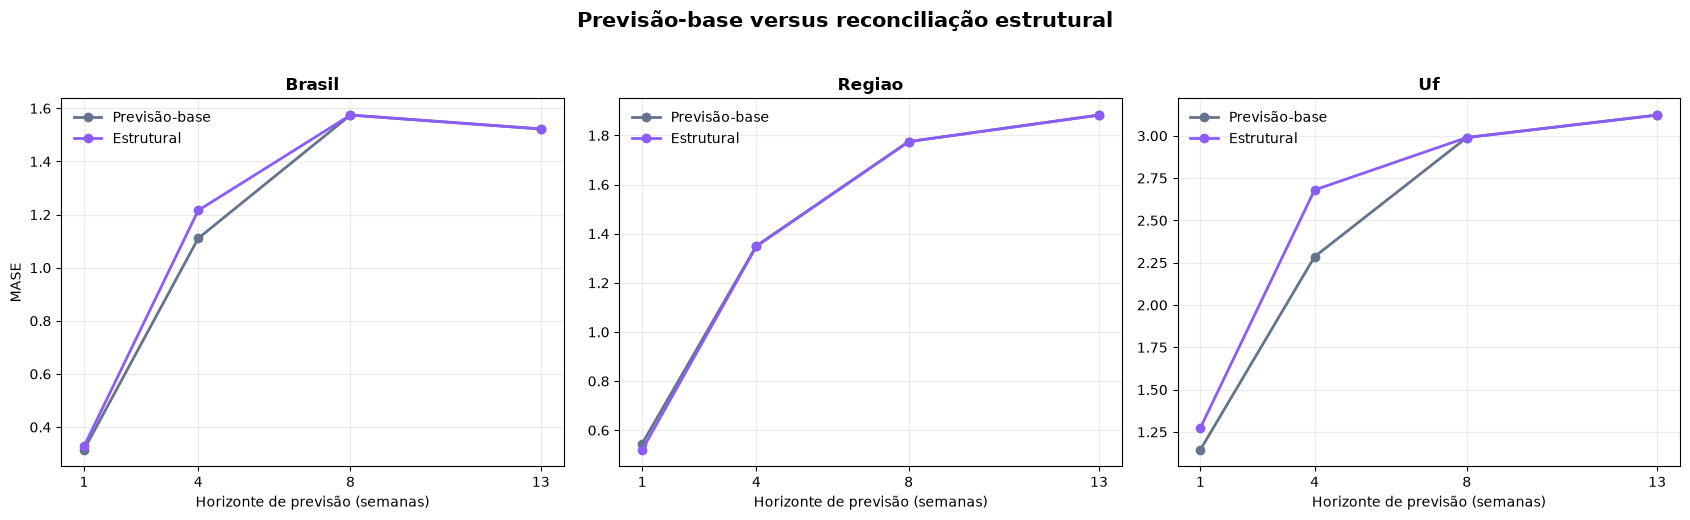

Etapa 33 concluída.
Previsões reconciliadas: 7,656
Previsões negativas brutas: 1139
Resultados: ..\..\execucao_local_vsr\saidas\etapa_33_reconciliacao_estrutural


,nos_hierarquicos,ufs_folha,posto_matriz_s,condicao_matriz_interna,erro_maximo_projecao,peso_estrutural_minimo,peso_estrutural_maximo
0,33,27,27,3.0,1.693090e-15,1.0,27.0


,nivel_agregado,comparacoes,diferenca_absoluta_maxima,comparacoes_coerentes,percentual_coerente
0,BRASIL,232,4.547474e-13,232,100.0
1,REGIAO,1160,3.410605e-13,1160,100.0


,nivel,horizonte_semanas,mae_BASE_V2,mae_ESTRUTURAL_WLS,rmse_BASE_V2,rmse_ESTRUTURAL_WLS,mase_BASE_V2,mase_ESTRUTURAL_WLS,delta_estrutural_menos_base_mae,delta_estrutural_menos_base_rmse,delta_estrutural_menos_base_mase
0,BRASIL,1,49.421366,51.239817,76.061587,74.421461,0.314634,0.327650,1.818450e+00,-1.640126e+00,1.301617e-02
1,BRASIL,4,176.102473,193.237030,290.842676,304.145337,1.110469,1.215575,1.713456e+01,1.330266e+01,1.051064e-01
2,BRASIL,8,247.896552,247.896552,397.367111,397.367111,1.574582,1.574582,0.000000e+00,0.000000e+00,0.000000e+00
3,BRASIL,13,236.741379,236.741379,371.797614,371.797614,1.522343,1.522343,2.842171e-14,-5.684342e-14,0.000000e+00
4,REGIAO,1,15.994000,15.108038,27.623395,26.519019,0.545830,0.520643,-8.859611e-01,-1.104377e+00,-2.518680e-02
5,REGIAO,4,43.379882,45.617408,89.563897,89.674285,1.350174,1.348721,2.237526e+00,1.103879e-01,-1.453224e-03
6,REGIAO,8,58.165517,58.165517,116.241900,116.241900,1.774511,1.774511,0.000000e+00,1.421085e-14,0.000000e+00
7,REGIAO,13,59.589655,59.589655,113.966556,113.966556,1.882562,1.882562,1.421085e-14,2.842171e-14,0.000000e+00
8,UF,1,4.583653,4.427829,9.533098,9.066225,1.144810,1.274332,-1.558233e-01,-4.668726e-01,1.295220e-01
9,UF,4,12.086845,11.076815,29.069521,26.818602,2.285409,2.679692,-1.010031e+00,-2.250919e+00,3.942832e-01


,nivel,horizonte_semanas,previsoes,previsoes_ausentes,previsoes_negativas_brutas,menor_previsao
0,BRASIL,1,58,0,0,4.125225e+01
1,BRASIL,4,58,0,0,2.754516e+01
2,BRASIL,8,58,0,0,4.800000e+01
3,BRASIL,13,58,0,0,4.500000e+01
4,REGIAO,1,290,0,9,-1.104437e+00
5,REGIAO,4,290,0,17,-1.650149e+01
6,REGIAO,8,290,0,4,-4.218847e-14
7,REGIAO,13,290,0,6,-5.950795e-14
8,UF,1,1566,0,248,-7.892231e+00
9,UF,4,1566,0,316,-2.500037e+01


In [10]:
# ETAPA 33 — Reconciliação estrutural ponderada

from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

BASE_DIR = Path(
    "../../execucao_local_vsr"
)

DIR_HIERARQUIA = (
    BASE_DIR
    / "saidas"
    / "etapa_27_estrutura_hierarquica"
)

DIR_BASE_V2 = (
    BASE_DIR
    / "saidas"
    / "etapa_30_previsoes_base_hierarquicas_v2"
)

DIR_MASE_AGREGADOS = (
    BASE_DIR
    / "saidas"
    / "etapa_22_metricas_referencias"
)

DIR_MASE_UFS = (
    BASE_DIR
    / "saidas"
    / "etapa_29_referencias_ufs"
)

DIR_RESULTADOS = (
    BASE_DIR
    / "saidas"
    / "etapa_33_reconciliacao_estrutural"
)

DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)

ARQUIVO_BASE_V2 = (
    DIR_BASE_V2
    / "previsoes_base_hierarquicas_v2.csv"
)

ARQUIVO_MATRIZ_S = (
    DIR_HIERARQUIA
    / "matriz_somatoria_hierarquia.csv"
)

ARQUIVO_ESCALAS_AGREGADOS = (
    DIR_MASE_AGREGADOS
    / "escalas_mase_por_origem.csv"
)

ARQUIVO_ESCALAS_UFS = (
    DIR_MASE_UFS
    / "escalas_mase_ufs_por_origem.csv"
)

for arquivo in [
    ARQUIVO_BASE_V2,
    ARQUIVO_MATRIZ_S,
    ARQUIVO_ESCALAS_AGREGADOS,
    ARQUIVO_ESCALAS_UFS,
]:
    if not arquivo.exists():
        raise FileNotFoundError(
            f"Arquivo necessário não encontrado: {arquivo}"
        )

base_v2 = pd.read_csv(ARQUIVO_BASE_V2)
matriz_s = pd.read_csv(ARQUIVO_MATRIZ_S)
escalas_agregados = pd.read_csv(
    ARQUIVO_ESCALAS_AGREGADOS
)
escalas_ufs = pd.read_csv(
    ARQUIVO_ESCALAS_UFS
)

for base in [
    base_v2,
    matriz_s,
    escalas_agregados,
    escalas_ufs,
]:
    for coluna in ["nivel", "unidade", "regiao"]:
        if coluna in base.columns:
            base[coluna] = (
                base[coluna]
                .astype("string")
                .str.strip()
                .str.upper()
            )

for base in [
    base_v2,
    escalas_agregados,
    escalas_ufs,
]:
    if "data_origem" in base.columns:
        base["data_origem"] = pd.to_datetime(
            base["data_origem"],
            errors="coerce",
        )

if "data_alvo" in base_v2.columns:
    base_v2["data_alvo"] = pd.to_datetime(
        base_v2["data_alvo"],
        errors="coerce",
    )

for base in [
    base_v2,
    escalas_agregados,
    escalas_ufs,
]:
    for coluna in [
        "casos_observados",
        "previsao",
        "horizonte_semanas",
        "escala_mase_sazonal",
    ]:
        if coluna in base.columns:
            base[coluna] = pd.to_numeric(
                base[coluna],
                errors="coerce",
            )

CHAVE = [
    "nivel",
    "unidade",
    "data_origem",
    "horizonte_semanas",
    "data_alvo",
]

CHAVE_AGREGACAO = [
    "data_origem",
    "horizonte_semanas",
    "data_alvo",
]

if len(base_v2) != 7656:
    raise ValueError(
        "A base V2 deveria possuir 7.656 previsões."
    )

if base_v2.duplicated(CHAVE).any():
    raise ValueError(
        "Há previsões duplicadas na base V2."
    )

if base_v2[
    [
        "casos_observados",
        "previsao",
    ]
].isna().any().any():
    raise ValueError(
        "Há valores ausentes na base V2."
    )

if (base_v2["previsao"] < 0).any():
    raise ValueError(
        "A base V2 possui previsões negativas."
    )

COLUNAS_IDENTIFICACAO = [
    "nivel",
    "unidade",
]

ufs = [
    coluna
    for coluna in matriz_s.columns
    if coluna not in COLUNAS_IDENTIFICACAO
]

S = matriz_s[ufs].to_numpy(dtype=float)

ordem_nos = pd.MultiIndex.from_frame(
    matriz_s[
        [
            "nivel",
            "unidade",
        ]
    ]
)

n_nos, n_ufs = S.shape

if n_nos != 33 or n_ufs != 27:
    raise ValueError(
        "A matriz hierárquica deveria ter 33 nós e 27 UFs."
    )

if np.linalg.matrix_rank(S) != 27:
    raise ValueError(
        "A matriz de agregação não possui posto completo."
    )

peso_estrutural = S.sum(axis=1)

W_inv = np.diag(1 / peso_estrutural)

matriz_interna = (
    S.T
    @ W_inv
    @ S
)

G = (
    np.linalg.pinv(matriz_interna)
    @ S.T
    @ W_inv
)

P = S @ G

erro_projecao = np.max(
    np.abs(
        P @ S
        - S
    )
)

if erro_projecao > 1e-10:
    raise ValueError(
        "A matriz de reconciliação não preserva a estrutura."
    )

diagnostico_matriz = pd.DataFrame(
    [
        {
            "nos_hierarquicos": n_nos,
            "ufs_folha": n_ufs,
            "posto_matriz_s": int(
                np.linalg.matrix_rank(S)
            ),
            "condicao_matriz_interna": float(
                np.linalg.cond(matriz_interna)
            ),
            "erro_maximo_projecao": float(
                erro_projecao
            ),
            "peso_estrutural_minimo": float(
                peso_estrutural.min()
            ),
            "peso_estrutural_maximo": float(
                peso_estrutural.max()
            ),
        }
    ]
)

pesos_nos = matriz_s[
    [
        "nivel",
        "unidade",
    ]
].copy()

pesos_nos["peso_estrutural"] = (
    peso_estrutural
)

grupos_previsao = base_v2.groupby(
    CHAVE_AGREGACAO,
    sort=False,
)

registros = []

for chave_grupo, grupo in grupos_previsao:

    grupo_ordenado = (
        grupo
        .set_index(
            [
                "nivel",
                "unidade",
            ],
            drop=False,
        )
        .reindex(ordem_nos)
    )

    if len(grupo_ordenado) != n_nos:
        raise ValueError(
            "Um corte temporal não possui todos os 33 nós."
        )

    if grupo_ordenado["previsao"].isna().any():
        raise ValueError(
            "Há previsão-base ausente em um corte temporal."
        )

    vetor_base = (
        grupo_ordenado["previsao"]
        .to_numpy(dtype=float)
    )

    vetor_reconciliado = P @ vetor_base

    grupo_ordenado["previsao_base"] = vetor_base

    grupo_ordenado[
        "previsao_reconciliada"
    ] = vetor_reconciliado

    grupo_ordenado[
        "metodo_reconciliacao"
    ] = "ESTRUTURAL_WLS"

    registros.append(grupo_ordenado)

previsoes = pd.concat(
    registros,
    ignore_index=True,
)

if len(previsoes) != 7656:
    raise ValueError(
        "A reconciliação deveria produzir 7.656 previsões."
    )

if previsoes.duplicated(CHAVE).any():
    raise ValueError(
        "Há previsões estruturais duplicadas."
    )

if previsoes[
    "previsao_reconciliada"
].isna().any():
    raise ValueError(
        "Há previsões estruturais ausentes."
    )

previsoes["erro_base"] = (
    previsoes["previsao_base"]
    - previsoes["casos_observados"]
)

previsoes["erro_estrutural"] = (
    previsoes["previsao_reconciliada"]
    - previsoes["casos_observados"]
)

previsoes["erro_absoluto_base"] = (
    previsoes["erro_base"].abs()
)

previsoes["erro_absoluto_estrutural"] = (
    previsoes["erro_estrutural"].abs()
)

previsoes["erro_quadratico_base"] = (
    previsoes["erro_base"] ** 2
)

previsoes["erro_quadratico_estrutural"] = (
    previsoes["erro_estrutural"] ** 2
)

soma_ufs_brasil = (
    previsoes.loc[
        previsoes["nivel"] == "UF"
    ]
    .groupby(
        CHAVE_AGREGACAO,
        as_index=False,
    )["previsao_reconciliada"]
    .sum()
    .rename(
        columns={
            "previsao_reconciliada": "soma_ufs"
        }
    )
)

previsao_brasil = (
    previsoes.loc[
        previsoes["nivel"] == "BRASIL",
        CHAVE_AGREGACAO + [
            "previsao_reconciliada",
        ],
    ]
    .rename(
        columns={
            "previsao_reconciliada": (
                "previsao_brasil"
            )
        }
    )
)

validacao_brasil = soma_ufs_brasil.merge(
    previsao_brasil,
    on=CHAVE_AGREGACAO,
    how="inner",
)

validacao_brasil["diferenca"] = (
    validacao_brasil["previsao_brasil"]
    - validacao_brasil["soma_ufs"]
)

soma_ufs_regiao = (
    previsoes.loc[
        previsoes["nivel"] == "UF"
    ]
    .groupby(
        CHAVE_AGREGACAO + ["regiao"],
        as_index=False,
    )["previsao_reconciliada"]
    .sum()
    .rename(
        columns={
            "previsao_reconciliada": "soma_ufs"
        }
    )
)

previsao_regiao = (
    previsoes.loc[
        previsoes["nivel"] == "REGIAO",
        CHAVE_AGREGACAO + [
            "unidade",
            "previsao_reconciliada",
        ],
    ]
    .rename(
        columns={
            "unidade": "regiao",
            "previsao_reconciliada": (
                "previsao_regiao"
            ),
        }
    )
)

validacao_regioes = soma_ufs_regiao.merge(
    previsao_regiao,
    on=CHAVE_AGREGACAO + ["regiao"],
    how="inner",
)

validacao_regioes["diferenca"] = (
    validacao_regioes["previsao_regiao"]
    - validacao_regioes["soma_ufs"]
)

validacao_coerencia = pd.concat(
    [
        pd.DataFrame(
            {
                "nivel_agregado": "BRASIL",
                "comparacoes": 1,
                "diferenca_absoluta": (
                    validacao_brasil[
                        "diferenca"
                    ].abs()
                ),
            }
        ),
        pd.DataFrame(
            {
                "nivel_agregado": "REGIAO",
                "comparacoes": 1,
                "diferenca_absoluta": (
                    validacao_regioes[
                        "diferenca"
                    ].abs()
                ),
            }
        ),
    ],
    ignore_index=True,
)

validacao_coerencia = (
    validacao_coerencia
    .groupby(
        "nivel_agregado",
        as_index=False,
    )
    .agg(
        comparacoes=("comparacoes", "sum"),
        diferenca_absoluta_maxima=(
            "diferenca_absoluta",
            "max",
        ),
        comparacoes_coerentes=(
            "diferenca_absoluta",
            lambda serie: int(
                np.isclose(serie, 0).sum()
            ),
        ),
    )
)

validacao_coerencia[
    "percentual_coerente"
] = (
    100
    * validacao_coerencia[
        "comparacoes_coerentes"
    ]
    / validacao_coerencia["comparacoes"]
)

if not np.isclose(
    validacao_coerencia[
        "diferenca_absoluta_maxima"
    ],
    0,
    atol=1e-8,
).all():
    raise ValueError(
        "A reconciliação estrutural não ficou coerente."
    )

escalas = pd.concat(
    [
        escalas_agregados,
        escalas_ufs,
    ],
    ignore_index=True,
)

escalas = escalas[
    [
        "nivel",
        "unidade",
        "data_origem",
        "escala_mase_sazonal",
    ]
].copy()

if escalas.duplicated(
    [
        "nivel",
        "unidade",
        "data_origem",
    ]
).any():
    raise ValueError(
        "Há escalas MASE duplicadas."
    )

previsoes = previsoes.merge(
    escalas,
    on=[
        "nivel",
        "unidade",
        "data_origem",
    ],
    how="left",
    validate="many_to_one",
)

if previsoes[
    "escala_mase_sazonal"
].isna().any():
    raise ValueError(
        "Há previsões sem escala MASE."
    )

previsoes["mase_individual_base"] = (
    previsoes["erro_absoluto_base"]
    / previsoes["escala_mase_sazonal"]
)

previsoes[
    "mase_individual_estrutural"
] = (
    previsoes["erro_absoluto_estrutural"]
    / previsoes["escala_mase_sazonal"]
)

def calcular_metricas(base, estrategia):
    if estrategia == "BASE_V2":
        erro_absoluto = "erro_absoluto_base"
        erro_quadratico = "erro_quadratico_base"
        mase = "mase_individual_base"
    else:
        erro_absoluto = (
            "erro_absoluto_estrutural"
        )
        erro_quadratico = (
            "erro_quadratico_estrutural"
        )
        mase = "mase_individual_estrutural"

    resultado = (
        base
        .groupby(
            [
                "nivel",
                "horizonte_semanas",
            ],
            as_index=False,
        )
        .agg(
            avaliacoes=(erro_absoluto, "size"),
            mae=(erro_absoluto, "mean"),
            rmse=(
                erro_quadratico,
                lambda valores: float(
                    np.sqrt(np.mean(valores))
                ),
            ),
            mase=(mase, "mean"),
        )
    )

    resultado["estrategia"] = estrategia

    return resultado

metricas_base = calcular_metricas(
    previsoes,
    "BASE_V2",
)

metricas_estrutural = calcular_metricas(
    previsoes,
    "ESTRUTURAL_WLS",
)

metricas_comparadas = pd.concat(
    [
        metricas_base,
        metricas_estrutural,
    ],
    ignore_index=True,
)

comparacao_metricas = metricas_comparadas.pivot(
    index=[
        "nivel",
        "horizonte_semanas",
    ],
    columns="estrategia",
    values=[
        "mae",
        "rmse",
        "mase",
    ],
).reset_index()

comparacao_metricas.columns = [
    "_".join(
        [
            str(parte)
            for parte in coluna
            if parte != ""
        ]
    ).rstrip("_")
    for coluna in comparacao_metricas.columns
]

for metrica in ["mae", "rmse", "mase"]:
    comparacao_metricas[
        f"delta_estrutural_menos_base_{metrica}"
    ] = (
        comparacao_metricas[
            f"{metrica}_ESTRUTURAL_WLS"
        ]
        - comparacao_metricas[
            f"{metrica}_BASE_V2"
        ]
    )

auditoria = (
    previsoes
    .groupby(
        [
            "nivel",
            "horizonte_semanas",
        ],
        as_index=False,
    )
    .agg(
        previsoes=(
            "previsao_reconciliada",
            "size",
        ),
        previsoes_ausentes=(
            "previsao_reconciliada",
            lambda serie: int(
                serie.isna().sum()
            ),
        ),
        previsoes_negativas_brutas=(
            "previsao_reconciliada",
            lambda serie: int(
                serie.lt(0).sum()
            ),
        ),
        menor_previsao=(
            "previsao_reconciliada",
            "min",
        ),
    )
)

previsoes.to_csv(
    DIR_RESULTADOS
    / "previsoes_reconciliacao_estrutural.csv",
    index=False,
)

diagnostico_matriz.to_csv(
    DIR_RESULTADOS
    / "diagnostico_matriz_estrutural.csv",
    index=False,
)

pesos_nos.to_csv(
    DIR_RESULTADOS
    / "pesos_estruturais_nos.csv",
    index=False,
)

pd.DataFrame(
    P,
    index=[
        f"{nivel}_{unidade}"
        for nivel, unidade in matriz_s[
            [
                "nivel",
                "unidade",
            ]
        ].itertuples(
            index=False,
            name=None,
        )
    ],
    columns=[
        f"{nivel}_{unidade}"
        for nivel, unidade in matriz_s[
            [
                "nivel",
                "unidade",
            ]
        ].itertuples(
            index=False,
            name=None,
        )
    ],
).to_csv(
    DIR_RESULTADOS
    / "matriz_projecao_estrutural.csv"
)

validacao_coerencia.to_csv(
    DIR_RESULTADOS
    / "validacao_coerencia_estrutural.csv",
    index=False,
)

metricas_comparadas.to_csv(
    DIR_RESULTADOS
    / "metricas_base_v2_e_estrutural.csv",
    index=False,
)

comparacao_metricas.to_csv(
    DIR_RESULTADOS
    / "comparacao_base_v2_estrutural.csv",
    index=False,
)

auditoria.to_csv(
    DIR_RESULTADOS
    / "auditoria_reconciliacao_estrutural.csv",
    index=False,
)

fig, eixos = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(17, 5),
)

for eixo, nivel in zip(
    eixos,
    ["BRASIL", "REGIAO", "UF"],
):
    dados = comparacao_metricas.loc[
        comparacao_metricas["nivel"] == nivel
    ].sort_values("horizonte_semanas")

    eixo.plot(
        dados["horizonte_semanas"],
        dados["mase_BASE_V2"],
        marker="o",
        linewidth=2,
        label="Previsão-base",
        color="#64748B",
    )

    eixo.plot(
        dados["horizonte_semanas"],
        dados["mase_ESTRUTURAL_WLS"],
        marker="o",
        linewidth=2,
        label="Estrutural",
        color="#8B5CF6",
    )

    eixo.set_title(
        nivel.title(),
        fontweight="bold",
    )

    eixo.set_xlabel(
        "Horizonte de previsão (semanas)"
    )

    eixo.set_xticks([1, 4, 8, 13])
    eixo.grid(alpha=0.25)
    eixo.legend(frameon=False)

eixos[0].set_ylabel("MASE")

fig.suptitle(
    "Previsão-base versus reconciliação estrutural",
    fontsize=15,
    fontweight="bold",
    y=1.03,
)

fig.tight_layout()

try:
    fig.savefig(
        DIR_RESULTADOS
        / "comparacao_base_v2_estrutural.png",
        dpi=120,
    )
except Exception as erro_grafico:
    print(
        "Os arquivos tabulares foram salvos, mas "
        "a imagem não pôde ser gravada:"
    )
    print(erro_grafico)

plt.show()
plt.close(fig)

ARQUIVO_ZIP = (
    BASE_DIR
    / "saidas"
    / "etapa_33_reconciliacao_estrutural.zip"
)

with ZipFile(
    ARQUIVO_ZIP,
    "w",
) as arquivo_zip:
    for arquivo in DIR_RESULTADOS.iterdir():
        if arquivo.is_file():
            arquivo_zip.write(
                arquivo,
                arcname=arquivo.name,
            )

print("Etapa 33 concluída.")
print(
    "Previsões reconciliadas: "
    f"{len(previsoes):,}"
)
print(
    "Previsões negativas brutas: "
    f"{int((previsoes['previsao_reconciliada'] < 0).sum())}"
)
print(f"Resultados: {DIR_RESULTADOS}")

display(diagnostico_matriz)
display(validacao_coerencia)
display(comparacao_metricas)
display(auditoria)

## Etapa 34 — Calibração temporal prévia para MinT

Antes de aplicar MinT, precisamos estimar como os erros das previsões-base se comportam conjuntamente entre Brasil, regiões e UFs.

A matriz de covariância não será estimada com os erros da avaliação formal. Isso evitará que o método aprenda com os mesmos alvos usados posteriormente para avaliar seu desempenho.

Serão utilizados todos os cortes semanais historicamente viáveis antes do primeiro corte formal de validação. Cada corte terá pelo menos 104 semanas de treinamento, requisito necessário para o ETS sazonal utilizado em Brasil e regiões. Além disso, até mesmo o alvo de 13 semanas precisará ocorrer antes do início da avaliação formal.

Em cada corte, repetiremos exatamente a política da Base V2: ETS com tendência amortecida para Brasil e regiões em uma e quatro semanas; referência sazonal nesses níveis em oito e 13 semanas; referência ingênua para UFs em uma e quatro semanas; e referência sazonal para UFs em oito e 13 semanas.

A calibração produzirá vetores de erro para os 33 nós da hierarquia e para cada horizonte. Na próxima etapa, esses vetores serão usados para estimar uma covariância com shrinkage e aplicar MinT de forma estável.

A calibração ocorre no período pandêmico de 2020 e 2021. Por isso, a estabilidade da covariância e a intensidade do shrinkage serão auditadas antes de qualquer recomendação.

Ajuste ETS 1 de 234 (0.0 minutos).


C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\2878170130.py:119: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  + pd.Timedelta(
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\2878170130.py:126: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  - pd.Timedelta(
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\2878170130.py:145: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  + pd.Timedelta(weeks=max(HORIZONTES))
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\2878170130.py:354: Deprec

C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\2878170130.py:354: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  + pd.Timedelta(weeks=horizonte)
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\2878170130.py:386: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  - pd.Timedelta(
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\2878170130.py:354: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  + pd.Timedelta(weeks=horizonte)
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\2878170130.py:3

C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\2878170130.py:354: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  + pd.Timedelta(weeks=horizonte)
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\2878170130.py:386: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  - pd.Timedelta(
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\2878170130.py:354: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  + pd.Timedelta(weeks=horizonte)
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\2878170130.py:3

C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\2878170130.py:354: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  + pd.Timedelta(weeks=horizonte)
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\2878170130.py:386: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  - pd.Timedelta(
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\2878170130.py:354: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  + pd.Timedelta(weeks=horizonte)
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\2878170130.py:3

C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\2878170130.py:354: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  + pd.Timedelta(weeks=horizonte)
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\2878170130.py:386: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  - pd.Timedelta(
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\2878170130.py:354: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  + pd.Timedelta(weeks=horizonte)
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\2878170130.py:3

... (59 outputs left out)

Ajuste ETS 234 de 234 (0.2 minutos).


C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\2878170130.py:354: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  + pd.Timedelta(weeks=horizonte)
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\2878170130.py:386: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  - pd.Timedelta(
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\2878170130.py:354: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  + pd.Timedelta(weeks=horizonte)
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\2878170130.py:3

C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\2878170130.py:354: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  + pd.Timedelta(weeks=horizonte)
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\2878170130.py:386: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  - pd.Timedelta(
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\2878170130.py:354: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  + pd.Timedelta(weeks=horizonte)
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\2878170130.py:3

C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\2878170130.py:354: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  + pd.Timedelta(weeks=horizonte)
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\2878170130.py:386: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  - pd.Timedelta(
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\2878170130.py:354: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  + pd.Timedelta(weeks=horizonte)
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\2878170130.py:3

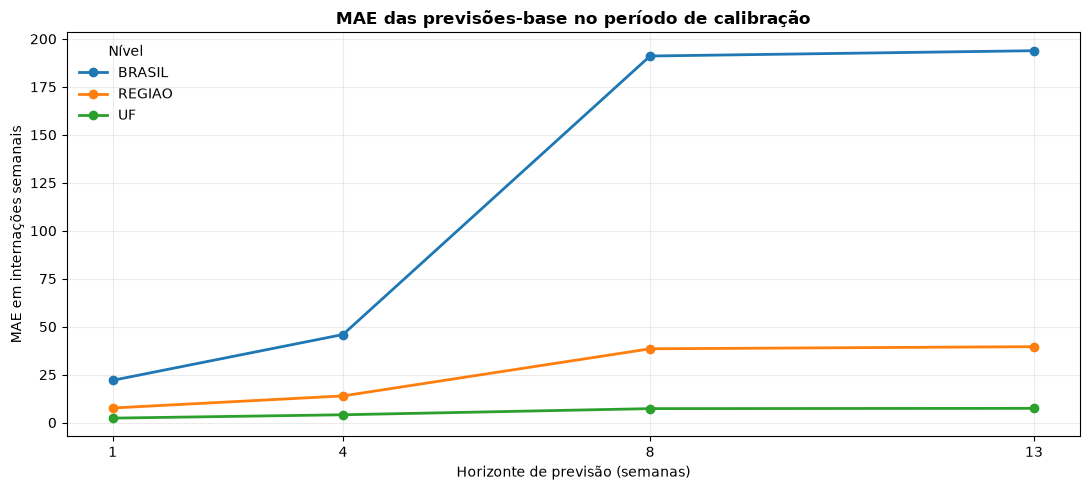

Etapa 34 concluída.
Origens de calibração: 39
Previsões de calibração: 5,148
Último alvo da calibração: 2021-12-12
Primeira origem formal: 2021-12-19
Resultados: ..\..\execucao_local_vsr\saidas\etapa_34_calibracao_temporal_mint


,origens_calibracao,horizontes,nos_hierarquicos,previsoes_geradas,primeira_origem_calibracao,ultima_origem_calibracao,ultimo_alvo_calibracao,primeira_origem_avaliacao_formal,ajustes_ets_esperados,ajustes_ets_convergidos
0,39,"1, 4, 8, 13",33,5148,2020-12-20,2021-09-12,2021-12-12,2021-12-19,234,234


,nivel,horizonte_semanas,modelo_base,previsoes,mae,rmse
0,BRASIL,1,ETS_TENDENCIA_AMORTECIDA_HEURISTICO,39,22.034663,30.716626
1,BRASIL,4,ETS_TENDENCIA_AMORTECIDA_HEURISTICO,39,45.910905,57.521599
2,BRASIL,8,INGENUO_SAZONAL,39,191.076923,196.139014
3,BRASIL,13,INGENUO_SAZONAL,39,193.846154,199.542297
4,REGIAO,1,ETS_TENDENCIA_AMORTECIDA_HEURISTICO,195,7.610063,11.611788
5,REGIAO,4,ETS_TENDENCIA_AMORTECIDA_HEURISTICO,195,13.905867,23.864709
6,REGIAO,8,INGENUO_SAZONAL,195,38.471795,58.231721
7,REGIAO,13,INGENUO_SAZONAL,195,39.579487,60.052285
8,UF,1,INGENUO,1053,2.334283,5.194233
9,UF,4,INGENUO,1053,4.081671,12.260623


,nivel,unidade,regiao,data_origem,semanas_treino,tentativa,convergiu,avisos_convergencia,sucesso_otimizador,erro
0,BRASIL,BRASIL,BRASIL,2020-12-20,104,PADRAO,True,0,True,None
1,BRASIL,BRASIL,BRASIL,2020-12-27,105,PADRAO,True,0,True,None
2,BRASIL,BRASIL,BRASIL,2021-01-03,106,PADRAO,True,0,True,None
3,BRASIL,BRASIL,BRASIL,2021-01-10,107,PADRAO,True,0,True,None
4,BRASIL,BRASIL,BRASIL,2021-01-17,108,PADRAO,True,0,True,None
...,...,...,...,...,...,...,...,...,...,...
229,REGIAO,SUL,SUL,2021-08-15,138,PADRAO,True,0,True,None
230,REGIAO,SUL,SUL,2021-08-22,139,PADRAO,True,0,True,None
231,REGIAO,SUL,SUL,2021-08-29,140,PADRAO,True,0,True,None
232,REGIAO,SUL,SUL,2021-09-05,141,PADRAO,True,0,True,None


In [11]:
# ETAPA 34 — Calibração temporal prévia para MinT

import time
import warnings
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from statsmodels.tools.sm_exceptions import ConvergenceWarning
from statsmodels.tsa.holtwinters import ExponentialSmoothing

BASE_DIR = Path(
    "../../execucao_local_vsr"
)

DIR_HIERARQUIA = (
    BASE_DIR
    / "saidas"
    / "etapa_27_estrutura_hierarquica"
)

DIR_RESULTADOS = (
    BASE_DIR
    / "saidas"
    / "etapa_34_calibracao_temporal_mint"
)

DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)

ARQUIVO_PAINEL = (
    DIR_HIERARQUIA
    / "painel_hierarquia_modelagem.parquet"
)

ARQUIVO_ESTRUTURA = (
    DIR_HIERARQUIA
    / "estrutura_nos_hierarquia.csv"
)

ARQUIVO_CALENDARIO_FORMAL = (
    DIR_HIERARQUIA
    / "calendario_validacao_hierarquica.csv"
)

for arquivo in [
    ARQUIVO_PAINEL,
    ARQUIVO_ESTRUTURA,
    ARQUIVO_CALENDARIO_FORMAL,
]:
    if not arquivo.exists():
        raise FileNotFoundError(
            f"Arquivo necessário não encontrado: {arquivo}"
        )

painel = pd.read_parquet(ARQUIVO_PAINEL)
estrutura = pd.read_csv(ARQUIVO_ESTRUTURA)
calendario_formal = pd.read_csv(
    ARQUIVO_CALENDARIO_FORMAL
)

for base in [
    painel,
    estrutura,
    calendario_formal,
]:
    for coluna in ["nivel", "unidade", "regiao"]:
        if coluna in base.columns:
            base[coluna] = (
                base[coluna]
                .astype("string")
                .str.strip()
                .str.upper()
            )

painel["semana"] = pd.to_datetime(
    painel["semana"],
    errors="coerce",
)

calendario_formal["data_origem"] = pd.to_datetime(
    calendario_formal["data_origem"],
    errors="coerce",
)

painel["casos_vsr"] = pd.to_numeric(
    painel["casos_vsr"],
    errors="coerce",
)

if painel[["semana", "casos_vsr"]].isna().any().any():
    raise ValueError(
        "O painel hierárquico possui datas ou casos ausentes."
    )

if calendario_formal["data_origem"].isna().any():
    raise ValueError(
        "O calendário formal possui origens inválidas."
    )

estrutura = estrutura.sort_values(
    "ordem_no"
).reset_index(drop=True)

HORIZONTES = [1, 4, 8, 13]
PERIODO_SAZONAL = 52
SEMANAS_MINIMAS_ETS = 104

primeira_semana = painel["semana"].min()

primeira_origem_formal = (
    calendario_formal["data_origem"].min()
)

primeira_origem_calibracao = (
    primeira_semana
    + pd.Timedelta(
        weeks=SEMANAS_MINIMAS_ETS - 1
    )
)

ultima_origem_calibracao = (
    primeira_origem_formal
    - pd.Timedelta(
        weeks=max(HORIZONTES) + 1
    )
)

origens_calibracao = pd.date_range(
    start=primeira_origem_calibracao,
    end=ultima_origem_calibracao,
    freq="W-SUN",
)

if len(origens_calibracao) != 39:
    raise ValueError(
        "Eram esperadas 39 origens de calibração. "
        f"Foram encontradas: {len(origens_calibracao)}."
    )

if (
    origens_calibracao.max()
    + pd.Timedelta(weeks=max(HORIZONTES))
    >= primeira_origem_formal
):
    raise ValueError(
        "A calibração alcançou a avaliação formal."
    )

def ajustar_ets_amortecido(valores_treino):
    tentativas = [
        {
            "nome": "PADRAO",
            "argumentos": {
                "optimized": True,
                "remove_bias": False,
                "use_brute": True,
            },
        },
        {
            "nome": "L_BFGS_B",
            "argumentos": {
                "optimized": True,
                "remove_bias": False,
                "use_brute": False,
                "method": "L-BFGS-B",
                "minimize_kwargs": {
                    "options": {"maxiter": 2000}
                },
            },
        },
    ]

    auditoria = []

    for tentativa in tentativas:
        try:
            modelo = ExponentialSmoothing(
                valores_treino,
                trend="add",
                damped_trend=True,
                seasonal="add",
                seasonal_periods=PERIODO_SAZONAL,
                initialization_method="heuristic",
            )

            with warnings.catch_warnings(record=True) as avisos:
                warnings.simplefilter("always")
                ajuste = modelo.fit(**tentativa["argumentos"])

            avisos_convergencia = [
                aviso
                for aviso in avisos
                if issubclass(
                    aviso.category,
                    ConvergenceWarning,
                )
            ]

            retorno = getattr(ajuste, "mle_retvals", {})
            sucesso = np.nan

            if isinstance(retorno, dict):
                sucesso = retorno.get("success", np.nan)

            convergiu = (
                len(avisos_convergencia) == 0
                and sucesso is not False
            )

            auditoria.append(
                {
                    "tentativa": tentativa["nome"],
                    "convergiu": convergiu,
                    "avisos_convergencia": len(
                        avisos_convergencia
                    ),
                    "sucesso_otimizador": sucesso,
                    "erro": None,
                }
            )

            if convergiu:
                return ajuste, auditoria

        except Exception as erro:
            auditoria.append(
                {
                    "tentativa": tentativa["nome"],
                    "convergiu": False,
                    "avisos_convergencia": np.nan,
                    "sucesso_otimizador": np.nan,
                    "erro": str(erro),
                }
            )

    return None, auditoria

registros = []
auditoria_ets = []

inicio = time.time()

nos_agregados = estrutura.loc[
    estrutura["nivel"].isin(
        ["BRASIL", "REGIAO"]
    )
]

total_ajustes_ets = (
    len(nos_agregados)
    * len(origens_calibracao)
)

ajuste_atual = 0

for no in estrutura.itertuples(index=False):
    nivel = no.nivel
    unidade = no.unidade
    regiao = no.regiao

    serie = (
        painel.loc[
            (painel["nivel"] == nivel)
            & (painel["unidade"] == unidade)
        ]
        .sort_values("semana")
        .copy()
    )

    if len(serie) != 395:
        raise ValueError(
            f"Série incompleta: {nivel} - {unidade}."
        )

    valores_por_data = (
        serie.set_index("semana")["casos_vsr"]
    )

    for data_origem in origens_calibracao:
        treino = serie.loc[
            serie["semana"] <= data_origem
        ].copy()

        if len(treino) < SEMANAS_MINIMAS_ETS:
            raise ValueError(
                "Treino insuficiente para ETS em "
                f"{nivel} - {unidade}."
            )

        previsoes_ets = None

        if nivel in ["BRASIL", "REGIAO"]:
            ajuste_atual += 1

            if (
                ajuste_atual == 1
                or ajuste_atual % 25 == 0
                or ajuste_atual == total_ajustes_ets
            ):
                minutos = (
                    time.time() - inicio
                ) / 60

                print(
                    f"Ajuste ETS {ajuste_atual:,} de "
                    f"{total_ajustes_ets:,} "
                    f"({minutos:.1f} minutos)."
                )

            ajuste, tentativas = ajustar_ets_amortecido(
                treino["casos_vsr"]
                .astype(float)
                .to_numpy()
            )

            for tentativa in tentativas:
                auditoria_ets.append(
                    {
                        "nivel": nivel,
                        "unidade": unidade,
                        "regiao": regiao,
                        "data_origem": data_origem,
                        "semanas_treino": len(treino),
                        **tentativa,
                    }
                )

            if ajuste is None:
                raise RuntimeError(
                    "ETS não convergiu na calibração para "
                    f"{nivel} - {unidade}, "
                    f"{data_origem.date()}."
                )

            previsoes_ets = np.asarray(
                ajuste.forecast(max(HORIZONTES)),
                dtype=float,
            )

            if (
                len(previsoes_ets) != max(HORIZONTES)
                or not np.isfinite(previsoes_ets).all()
            ):
                raise ValueError(
                    "ETS retornou previsões inválidas."
                )

        for horizonte in HORIZONTES:
            data_alvo = (
                data_origem
                + pd.Timedelta(weeks=horizonte)
            )

            if data_alvo not in valores_por_data.index:
                raise ValueError(
                    "Alvo não encontrado em "
                    f"{nivel} - {unidade}: "
                    f"{data_alvo.date()}."
                )

            observado = float(
                valores_por_data.loc[data_alvo]
            )

            if (
                nivel in ["BRASIL", "REGIAO"]
                and horizonte in [1, 4]
            ):
                previsao_bruta = float(
                    previsoes_ets[horizonte - 1]
                )
                previsao = max(0.0, previsao_bruta)
                modelo = (
                    "ETS_TENDENCIA_AMORTECIDA_HEURISTICO"
                )
                politica = (
                    "ETS_AMORTECIDO_AGREGADOS_CURTO"
                )

            elif horizonte in [8, 13]:
                data_sazonal = (
                    data_alvo
                    - pd.Timedelta(
                        weeks=PERIODO_SAZONAL
                    )
                )

                if data_sazonal not in valores_por_data.index:
                    raise ValueError(
                        "Referência sazonal não encontrada "
                        f"em {nivel} - {unidade}."
                    )

                previsao_bruta = float(
                    valores_por_data.loc[data_sazonal]
                )
                previsao = previsao_bruta
                modelo = "INGENUO_SAZONAL"

                if nivel in ["BRASIL", "REGIAO"]:
                    politica = (
                        "INGENUO_SAZONAL_AGREGADOS_LONGO"
                    )
                else:
                    politica = (
                        "INGENUO_SAZONAL_UFS_LONGO"
                    )

            else:
                previsao_bruta = float(
                    treino["casos_vsr"].iloc[-1]
                )
                previsao = previsao_bruta
                modelo = "INGENUO"
                politica = "INGENUO_UFS_CURTO"

            registros.append(
                {
                    "nivel": nivel,
                    "unidade": unidade,
                    "regiao": regiao,
                    "data_origem": data_origem,
                    "horizonte_semanas": horizonte,
                    "data_alvo": data_alvo,
                    "casos_observados": observado,
                    "previsao_bruta": previsao_bruta,
                    "previsao": previsao,
                    "modelo_base": modelo,
                    "politica_base": politica,
                    "erro": previsao - observado,
                    "erro_absoluto": abs(
                        previsao - observado
                    ),
                }
            )

previsoes_calibracao = (
    pd.DataFrame(registros)
    .sort_values(
        [
            "data_origem",
            "horizonte_semanas",
            "nivel",
            "unidade",
        ]
    )
    .reset_index(drop=True)
)

auditoria_ets = pd.DataFrame(auditoria_ets)

CHAVE = [
    "nivel",
    "unidade",
    "data_origem",
    "horizonte_semanas",
    "data_alvo",
]

quantidade_esperada = (
    len(estrutura)
    * len(origens_calibracao)
    * len(HORIZONTES)
)

if len(previsoes_calibracao) != quantidade_esperada:
    raise ValueError(
        "Quantidade incorreta de previsões na calibração."
    )

if previsoes_calibracao.duplicated(CHAVE).any():
    raise ValueError(
        "Há previsões duplicadas na calibração."
    )

if previsoes_calibracao[
    [
        "casos_observados",
        "previsao",
        "erro",
    ]
].isna().any().any():
    raise ValueError(
        "Há valores ausentes na calibração."
    )

if (previsoes_calibracao["previsao"] < 0).any():
    raise ValueError(
        "Há previsões negativas na base de calibração."
    )

if len(auditoria_ets) == 0:
    raise ValueError(
        "A auditoria ETS não foi produzida."
    )

if not auditoria_ets["convergiu"].any():
    raise ValueError(
        "Nenhum ajuste ETS convergiu na calibração."
    )

previsoes_calibracao["no_hierarquico"] = (
    previsoes_calibracao["nivel"]
    + "_"
    + previsoes_calibracao["unidade"]
)

ordem_nos = (
    estrutura["nivel"]
    + "_"
    + estrutura["unidade"]
).tolist()

vetores_erros = (
    previsoes_calibracao
    .pivot(
        index=[
            "data_origem",
            "horizonte_semanas",
        ],
        columns="no_hierarquico",
        values="erro",
    )
    .reindex(columns=ordem_nos)
    .reset_index()
)

if vetores_erros.shape != (
    len(origens_calibracao)
    * len(HORIZONTES),
    len(ordem_nos) + 2,
):
    raise ValueError(
        "A matriz de erros possui dimensão inesperada."
    )

if vetores_erros.isna().any().any():
    raise ValueError(
        "Há erros ausentes nos vetores de calibração."
    )

resumo_calibracao = pd.DataFrame(
    [
        {
            "origens_calibracao": len(
                origens_calibracao
            ),
            "horizontes": ", ".join(
                map(str, HORIZONTES)
            ),
            "nos_hierarquicos": len(estrutura),
            "previsoes_geradas": len(
                previsoes_calibracao
            ),
            "primeira_origem_calibracao": (
                origens_calibracao.min()
            ),
            "ultima_origem_calibracao": (
                origens_calibracao.max()
            ),
            "ultimo_alvo_calibracao": (
                previsoes_calibracao[
                    "data_alvo"
                ].max()
            ),
            "primeira_origem_avaliacao_formal": (
                primeira_origem_formal
            ),
            "ajustes_ets_esperados": total_ajustes_ets,
            "ajustes_ets_convergidos": int(
                auditoria_ets["convergiu"].sum()
            ),
        }
    ]
)

metricas_calibracao = (
    previsoes_calibracao
    .groupby(
        [
            "nivel",
            "horizonte_semanas",
            "modelo_base",
        ],
        as_index=False,
    )
    .agg(
        previsoes=("erro", "size"),
        mae=("erro_absoluto", "mean"),
        rmse=(
            "erro",
            lambda valores: float(
                np.sqrt(np.mean(valores ** 2))
            ),
        ),
    )
)

metricas_grafico = (
    previsoes_calibracao
    .groupby(
        [
            "nivel",
            "horizonte_semanas",
        ],
        as_index=False,
    )
    .agg(
        mae=("erro_absoluto", "mean")
    )
)

fig, eixo = plt.subplots(figsize=(11, 5))

for nivel, grupo in metricas_grafico.groupby(
    "nivel"
):
    dados = grupo.sort_values(
        "horizonte_semanas"
    )

    eixo.plot(
        dados["horizonte_semanas"],
        dados["mae"],
        marker="o",
        linewidth=2,
        label=nivel,
    )

eixo.set_title(
    "MAE das previsões-base no período de calibração",
    fontweight="bold",
)
eixo.set_xlabel("Horizonte de previsão (semanas)")
eixo.set_ylabel("MAE em internações semanais")
eixo.set_xticks(HORIZONTES)
eixo.grid(alpha=0.25)
eixo.legend(title="Nível", frameon=False)

fig.tight_layout()

fig.savefig(
    DIR_RESULTADOS
    / "mae_base_periodo_calibracao_mint.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()

previsoes_calibracao.to_csv(
    DIR_RESULTADOS
    / "previsoes_calibracao_mint.csv",
    index=False,
)

vetores_erros.to_csv(
    DIR_RESULTADOS
    / "vetores_erros_calibracao_mint.csv",
    index=False,
)

auditoria_ets.to_csv(
    DIR_RESULTADOS
    / "auditoria_ets_calibracao_mint.csv",
    index=False,
)

resumo_calibracao.to_csv(
    DIR_RESULTADOS
    / "resumo_calibracao_mint.csv",
    index=False,
)

metricas_calibracao.to_csv(
    DIR_RESULTADOS
    / "metricas_base_calibracao_mint.csv",
    index=False,
)

ARQUIVO_ZIP = (
    BASE_DIR
    / "saidas"
    / "etapa_34_calibracao_temporal_mint.zip"
)

with ZipFile(ARQUIVO_ZIP, "w") as arquivo_zip:
    for arquivo in DIR_RESULTADOS.iterdir():
        arquivo_zip.write(
            arquivo,
            arcname=arquivo.name,
        )

print("Etapa 34 concluída.")
print(
    "Origens de calibração: "
    f"{len(origens_calibracao)}"
)
print(
    "Previsões de calibração: "
    f"{len(previsoes_calibracao):,}"
)
print(
    "Último alvo da calibração: "
    f"{previsoes_calibracao['data_alvo'].max().date()}"
)
print(
    "Primeira origem formal: "
    f"{primeira_origem_formal.date()}"
)
print(
    "Resultados: "
    f"{DIR_RESULTADOS}"
)

display(resumo_calibracao)
display(metricas_calibracao)
display(auditoria_ets)

## Etapa 35 — Reconciliação MinT com shrinkage

Nesta etapa, aplicaremos MinT, um método de reconciliação que combina previsões de Brasil, regiões e UFs conforme a incerteza histórica observada em cada nível.

A etapa 34 mostrou que a covariância bruta dos erros não pode ser invertida diretamente: há poucos vetores de erro em relação aos 33 nós, forte correlação entre níveis geográficos e uma UF com variância histórica nula durante a calibração.

Por isso, a covariância será regularizada por shrinkage OAS. Em termos simples, o método reduz correlações estimadas de forma instável, mas preserva a escala de erro observada em cada série. Para nós cuja variância foi nula ou muito pequena, será aplicado um piso de escala definido pelo décimo percentil das escalas positivas do mesmo horizonte.

Cada horizonte terá sua própria matriz de covariância e sua própria matriz de reconciliação. O grau de shrinkage será determinado exclusivamente pelos 39 vetores históricos da calibração, sem usar os erros da avaliação formal.

As previsões negativas não serão truncadas. Elas serão auditadas porque truncar após MinT quebraria a coerência entre UFs, regiões e Brasil.

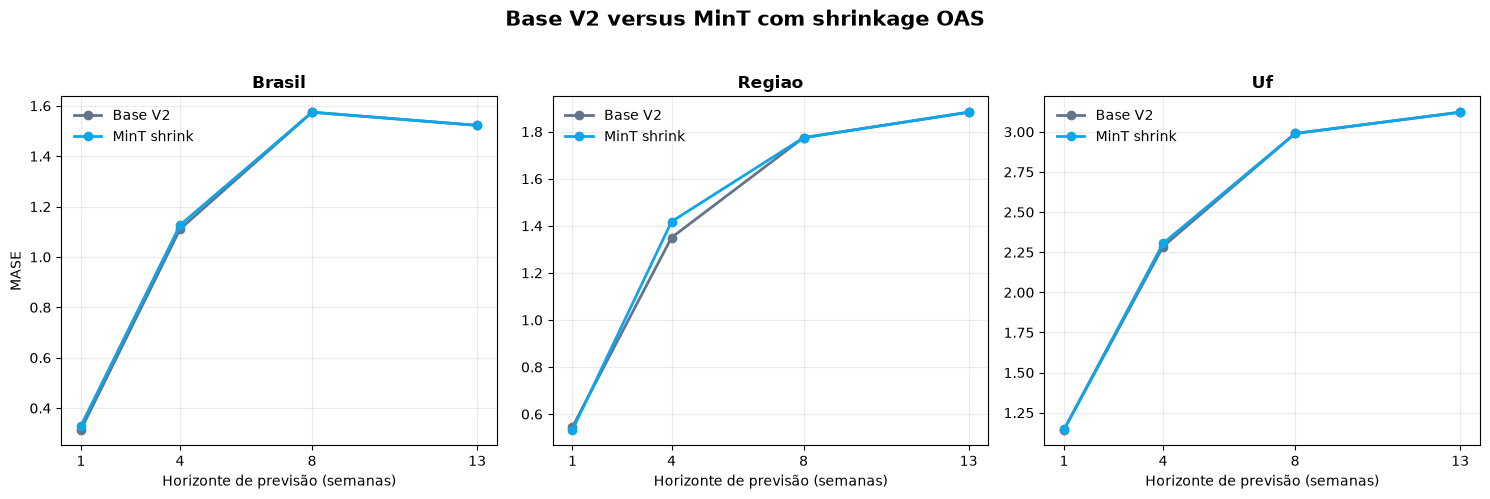

Etapa 35 concluída.
Previsões MinT: 7,656
Previsões negativas: 1264
Resultados: ..\..\execucao_local_vsr\saidas\etapa_35_reconciliacao_mint_shrink


,horizonte_semanas,vetores_calibracao,nos_hierarquicos,posto_covariancia_bruta,shrinkage_oas,piso_desvio_erro,nos_com_piso_desvio,menor_autovalor_w,maior_autovalor_w,condicao_covariancia_w,condicao_matriz_interna,erro_maximo_projecao
0,1,39,33,32,0.529121,0.477837,5,0.107280,1004.233900,9360.857991,1727.570280,2.092770e-14
1,4,39,33,32,0.376684,0.604972,5,0.123896,5433.378488,43854.177362,11563.839065,1.674216e-13
2,8,39,33,26,0.238559,0.426599,5,0.038763,6039.524267,155807.366813,61379.843920,2.624567e-13
3,13,39,33,26,0.240699,0.606941,5,0.078225,6457.171716,82546.610610,31631.679048,8.637535e-14


,nivel_agregado,comparacoes,diferenca_absoluta_maxima,comparacoes_coerentes,percentual_coerente
0,BRASIL,232,9.094947e-13,232,100.0
1,REGIAO,1160,4.547474e-13,1160,100.0


,nivel,horizonte_semanas,mae_BASE_V2,mae_MINT_OAS_SHRINK,rmse_BASE_V2,rmse_MINT_OAS_SHRINK,mase_BASE_V2,mase_MINT_OAS_SHRINK,delta_mint_menos_base_mae,delta_mint_menos_base_rmse,delta_mint_menos_base_mase
0,BRASIL,1,49.421366,51.669145,76.061587,74.230540,0.314634,0.330381,2.247779e+00,-1.831046e+00,1.574733e-02
1,BRASIL,4,176.102473,177.419233,290.842676,290.704497,1.110469,1.126716,1.316760e+00,-1.381785e-01,1.624703e-02
2,BRASIL,8,247.896552,247.896552,397.367111,397.367111,1.574582,1.574582,-3.126388e-13,-9.094947e-13,-1.110223e-15
3,BRASIL,13,236.741379,236.741379,371.797614,371.797614,1.522343,1.522343,3.126388e-13,1.023182e-12,2.220446e-15
4,REGIAO,1,15.994000,15.320954,27.623395,26.776812,0.545830,0.534212,-6.730461e-01,-8.465839e-01,-1.161805e-02
5,REGIAO,4,43.379882,46.598369,89.563897,92.542416,1.350174,1.417936,3.218487e+00,2.978519e+00,6.776164e-02
6,REGIAO,8,58.165517,58.165517,116.241900,116.241900,1.774511,1.774511,6.394885e-14,8.526513e-14,1.998401e-15
7,REGIAO,13,59.589655,59.589655,113.966556,113.966556,1.882562,1.882562,8.526513e-14,1.847411e-13,2.442491e-15
8,UF,1,4.583653,4.442971,9.533098,9.228161,1.144810,1.145652,-1.406813e-01,-3.049361e-01,8.412814e-04
9,UF,4,12.086845,12.160102,29.069521,31.716799,2.285409,2.305160,7.325629e-02,2.647278e+00,1.975141e-02


,nivel,horizonte_semanas,previsoes,previsoes_ausentes,previsoes_negativas_brutas,menor_previsao
0,BRASIL,1,58,0,0,4.119746e+01
1,BRASIL,4,58,0,0,1.802328e+01
2,BRASIL,8,58,0,0,4.800000e+01
3,BRASIL,13,58,0,0,4.500000e+01
4,REGIAO,1,290,0,5,-4.827135e+00
5,REGIAO,4,290,0,18,-6.933613e+01
6,REGIAO,8,290,0,2,-4.973799e-14
7,REGIAO,13,290,0,7,-2.176037e-14
8,UF,1,1566,0,270,-8.212374e+00
9,UF,4,1566,0,311,-1.275927e+02


In [12]:
# ETAPA 35 — Reconciliação MinT com shrinkage OAS

from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

BASE_DIR = Path(
    "../../execucao_local_vsr"
)

DIR_HIERARQUIA = (
    BASE_DIR
    / "saidas"
    / "etapa_27_estrutura_hierarquica"
)

DIR_BASE_V2 = (
    BASE_DIR
    / "saidas"
    / "etapa_30_previsoes_base_hierarquicas_v2"
)

DIR_CALIBRACAO = (
    BASE_DIR
    / "saidas"
    / "etapa_34_calibracao_temporal_mint"
)

DIR_MASE_AGREGADOS = (
    BASE_DIR
    / "saidas"
    / "etapa_22_metricas_referencias"
)

DIR_MASE_UFS = (
    BASE_DIR
    / "saidas"
    / "etapa_29_referencias_ufs"
)

DIR_RESULTADOS = (
    BASE_DIR
    / "saidas"
    / "etapa_35_reconciliacao_mint_shrink"
)

DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)

ARQUIVO_BASE_V2 = (
    DIR_BASE_V2
    / "previsoes_base_hierarquicas_v2.csv"
)

ARQUIVO_ESTRUTURA = (
    DIR_HIERARQUIA
    / "estrutura_nos_hierarquia.csv"
)

ARQUIVO_MATRIZ_S = (
    DIR_HIERARQUIA
    / "matriz_somatoria_hierarquia.csv"
)

ARQUIVO_ERROS_CALIBRACAO = (
    DIR_CALIBRACAO
    / "vetores_erros_calibracao_mint.csv"
)

ARQUIVO_ESCALAS_AGREGADOS = (
    DIR_MASE_AGREGADOS
    / "escalas_mase_por_origem.csv"
)

ARQUIVO_ESCALAS_UFS = (
    DIR_MASE_UFS
    / "escalas_mase_ufs_por_origem.csv"
)

for arquivo in [
    ARQUIVO_BASE_V2,
    ARQUIVO_ESTRUTURA,
    ARQUIVO_MATRIZ_S,
    ARQUIVO_ERROS_CALIBRACAO,
    ARQUIVO_ESCALAS_AGREGADOS,
    ARQUIVO_ESCALAS_UFS,
]:
    if not arquivo.exists():
        raise FileNotFoundError(
            f"Arquivo necessário não encontrado: {arquivo}"
        )

base_v2 = pd.read_csv(ARQUIVO_BASE_V2)
estrutura = pd.read_csv(ARQUIVO_ESTRUTURA)
matriz_s = pd.read_csv(ARQUIVO_MATRIZ_S)
erros_calibracao = pd.read_csv(
    ARQUIVO_ERROS_CALIBRACAO
)
escalas_agregados = pd.read_csv(
    ARQUIVO_ESCALAS_AGREGADOS
)
escalas_ufs = pd.read_csv(
    ARQUIVO_ESCALAS_UFS
)

for base in [
    base_v2,
    estrutura,
    matriz_s,
    escalas_agregados,
    escalas_ufs,
]:
    for coluna in ["nivel", "unidade", "regiao"]:
        if coluna in base.columns:
            base[coluna] = (
                base[coluna]
                .astype("string")
                .str.strip()
                .str.upper()
            )

for base in [
    base_v2,
    escalas_agregados,
    escalas_ufs,
]:
    if "data_origem" in base.columns:
        base["data_origem"] = pd.to_datetime(
            base["data_origem"],
            errors="coerce",
        )

if "data_alvo" in base_v2.columns:
    base_v2["data_alvo"] = pd.to_datetime(
        base_v2["data_alvo"],
        errors="coerce",
    )

for base in [
    base_v2,
    escalas_agregados,
    escalas_ufs,
]:
    for coluna in [
        "casos_observados",
        "previsao",
        "horizonte_semanas",
        "escala_mase_sazonal",
    ]:
        if coluna in base.columns:
            base[coluna] = pd.to_numeric(
                base[coluna],
                errors="coerce",
            )

estrutura = estrutura.sort_values(
    "ordem_no"
).reset_index(drop=True)

estrutura["no_hierarquico"] = (
    estrutura["nivel"]
    + "_"
    + estrutura["unidade"]
)

ordem_nos = estrutura[
    "no_hierarquico"
].tolist()

matriz_s["no_hierarquico"] = (
    matriz_s["nivel"]
    + "_"
    + matriz_s["unidade"]
)

matriz_s = (
    matriz_s
    .set_index("no_hierarquico")
    .reindex(ordem_nos)
)

if matriz_s.isna().any().any():
    raise ValueError(
        "A matriz de agregação não corresponde "
        "à estrutura dos nós."
    )

COLUNAS_IDENTIFICACAO = [
    "nivel",
    "unidade",
]

ufs = [
    coluna
    for coluna in matriz_s.columns
    if coluna not in COLUNAS_IDENTIFICACAO
]

S = matriz_s[ufs].to_numpy(dtype=float)

if S.shape != (33, 27):
    raise ValueError(
        "A matriz S deveria possuir 33 nós e 27 UFs."
    )

if np.linalg.matrix_rank(S) != 27:
    raise ValueError(
        "A matriz S não possui posto completo."
    )

HORIZONTES = [1, 4, 8, 13]

CHAVE = [
    "nivel",
    "unidade",
    "data_origem",
    "horizonte_semanas",
    "data_alvo",
]

CHAVE_AGREGACAO = [
    "data_origem",
    "horizonte_semanas",
    "data_alvo",
]

if len(base_v2) != 7656:
    raise ValueError(
        "A Base V2 deveria possuir 7.656 previsões."
    )

if base_v2.duplicated(CHAVE).any():
    raise ValueError(
        "Há previsões duplicadas na Base V2."
    )

if base_v2[
    [
        "casos_observados",
        "previsao",
    ]
].isna().any().any():
    raise ValueError(
        "Há valores ausentes na Base V2."
    )

if (base_v2["previsao"] < 0).any():
    raise ValueError(
        "A Base V2 possui previsões negativas."
    )

colunas_erros = [
    coluna
    for coluna in erros_calibracao.columns
    if coluna not in [
        "data_origem",
        "horizonte_semanas",
    ]
]

if colunas_erros != ordem_nos:
    raise ValueError(
        "A ordem dos erros de calibração não "
        "corresponde à ordem da hierarquia."
    )

if erros_calibracao.shape != (156, 35):
    raise ValueError(
        "A matriz de erros de calibração deveria "
        "possuir 156 linhas e 35 colunas."
    )

if erros_calibracao[
    colunas_erros
].isna().any().any():
    raise ValueError(
        "Há erros ausentes na calibração."
    )

matrizes_projecao = {}
diagnosticos = []
escalas_erros = []
linhas_matrizes = []

for horizonte in HORIZONTES:
    erros_horizonte = erros_calibracao.loc[
        erros_calibracao["horizonte_semanas"]
        == horizonte,
        colunas_erros,
    ].to_numpy(dtype=float)

    n_vetores, n_nos = erros_horizonte.shape

    if (n_vetores, n_nos) != (39, 33):
        raise ValueError(
            "Dimensão inesperada de erros no "
            f"horizonte {horizonte}."
        )

    desvios_brutos = erros_horizonte.std(
        axis=0,
        ddof=1,
    )

    desvios_positivos = desvios_brutos[
        desvios_brutos > 1e-12
    ]

    if len(desvios_positivos) == 0:
        raise ValueError(
            "Não há variância positiva suficiente "
            f"no horizonte {horizonte}."
        )

    piso_desvio = float(
        np.quantile(desvios_positivos, 0.10)
    )

    desvios_ajustados = np.maximum(
        desvios_brutos,
        piso_desvio,
    )

    erros_padronizados = (
        erros_horizonte
        / desvios_ajustados
    )

    erros_padronizados = (
        erros_padronizados
        - erros_padronizados.mean(
            axis=0,
            keepdims=True,
        )
    )

    covariancia_padronizada = (
        erros_padronizados.T
        @ erros_padronizados
        / n_vetores
    )

    media_diagonal = float(
        np.trace(covariancia_padronizada)
        / n_nos
    )

    media_quadrados = float(
        np.mean(covariancia_padronizada ** 2)
    )

    denominador_oas = (
        (n_vetores + 1)
        * (
            media_quadrados
            - (
                media_diagonal ** 2
                / n_nos
            )
        )
    )

    if denominador_oas <= 1e-15:
        shrinkage_oas = 1.0
    else:
        shrinkage_oas = float(
            np.clip(
                (
                    media_quadrados
                    + media_diagonal ** 2
                )
                / denominador_oas,
                0.0,
                1.0,
            )
        )

    covariancia_shrink = (
        (1.0 - shrinkage_oas)
        * covariancia_padronizada
        + shrinkage_oas
        * media_diagonal
        * np.eye(n_nos)
    )

    W = (
        np.diag(desvios_ajustados)
        @ covariancia_shrink
        @ np.diag(desvios_ajustados)
    )

    W = (W + W.T) / 2

    autovalores_w = np.linalg.eigvalsh(W)

    if autovalores_w.min() <= 0:
        raise ValueError(
            "A covariância regularizada não ficou "
            f"positiva definida no horizonte {horizonte}."
        )

    W_inversa = np.linalg.inv(W)

    matriz_interna = (
        S.T
        @ W_inversa
        @ S
    )

    G = np.linalg.solve(
        matriz_interna,
        S.T @ W_inversa,
    )

    P = S @ G

    erro_projecao = float(
        np.max(
            np.abs(
                P @ S
                - S
            )
        )
    )

    if erro_projecao > 1e-8:
        raise ValueError(
            "A projeção MinT não preservou a hierarquia "
            f"no horizonte {horizonte}."
        )

    matrizes_projecao[horizonte] = P

    diagnosticos.append(
        {
            "horizonte_semanas": horizonte,
            "vetores_calibracao": n_vetores,
            "nos_hierarquicos": n_nos,
            "posto_covariancia_bruta": int(
                np.linalg.matrix_rank(
                    covariancia_padronizada
                )
            ),
            "shrinkage_oas": shrinkage_oas,
            "piso_desvio_erro": piso_desvio,
            "nos_com_piso_desvio": int(
                (desvios_brutos < piso_desvio).sum()
            ),
            "menor_autovalor_w": float(
                autovalores_w.min()
            ),
            "maior_autovalor_w": float(
                autovalores_w.max()
            ),
            "condicao_covariancia_w": float(
                np.linalg.cond(W)
            ),
            "condicao_matriz_interna": float(
                np.linalg.cond(matriz_interna)
            ),
            "erro_maximo_projecao": erro_projecao,
        }
    )

    for indice, no_hierarquico in enumerate(
        ordem_nos
    ):
        escalas_erros.append(
            {
                "horizonte_semanas": horizonte,
                "no_hierarquico": no_hierarquico,
                "desvio_erro_bruto": float(
                    desvios_brutos[indice]
                ),
                "desvio_erro_ajustado": float(
                    desvios_ajustados[indice]
                ),
                "recebeu_piso": bool(
                    desvios_brutos[indice]
                    < piso_desvio
                ),
            }
        )

    for indice_linha, no_linha in enumerate(
        ordem_nos
    ):
        for indice_coluna, no_coluna in enumerate(
            ordem_nos
        ):
            linhas_matrizes.append(
                {
                    "horizonte_semanas": horizonte,
                    "no_linha": no_linha,
                    "no_coluna": no_coluna,
                    "coeficiente_projecao": float(
                        P[
                            indice_linha,
                            indice_coluna,
                        ]
                    ),
                }
            )

diagnosticos = pd.DataFrame(diagnosticos)
escalas_erros = pd.DataFrame(escalas_erros)
matrizes_projecao_longas = pd.DataFrame(
    linhas_matrizes
)

grupos_previsao = base_v2.groupby(
    CHAVE_AGREGACAO,
    sort=False,
)

registros = []

for chave_grupo, grupo in grupos_previsao:
    horizonte = int(
        chave_grupo[
            CHAVE_AGREGACAO.index(
                "horizonte_semanas"
            )
        ]
    )

    grupo = grupo.copy()

    grupo["no_hierarquico"] = (
        grupo["nivel"]
        + "_"
        + grupo["unidade"]
    )

    grupo_ordenado = (
        grupo
        .set_index(
            "no_hierarquico",
            drop=False,
        )
        .reindex(ordem_nos)
    )

    if len(grupo_ordenado) != 33:
        raise ValueError(
            "Um corte não possui todos os 33 nós."
        )

    if grupo_ordenado["previsao"].isna().any():
        raise ValueError(
            "Há previsão-base ausente em um corte."
        )

    vetor_base = (
        grupo_ordenado["previsao"]
        .to_numpy(dtype=float)
    )

    vetor_mint = (
        matrizes_projecao[horizonte]
        @ vetor_base
    )

    grupo_ordenado["previsao_base"] = vetor_base

    grupo_ordenado[
        "previsao_reconciliada"
    ] = vetor_mint

    grupo_ordenado[
        "metodo_reconciliacao"
    ] = "MINT_OAS_SHRINK"

    registros.append(
        grupo_ordenado.reset_index(drop=True)
    )

previsoes = pd.concat(
    registros,
    ignore_index=True,
)

if len(previsoes) != 7656:
    raise ValueError(
        "MinT deveria gerar 7.656 previsões."
    )

if previsoes.duplicated(CHAVE).any():
    raise ValueError(
        "Há previsões MinT duplicadas."
    )

if previsoes[
    "previsao_reconciliada"
].isna().any():
    raise ValueError(
        "Há previsões MinT ausentes."
    )

previsoes["erro_base"] = (
    previsoes["previsao_base"]
    - previsoes["casos_observados"]
)

previsoes["erro_mint"] = (
    previsoes["previsao_reconciliada"]
    - previsoes["casos_observados"]
)

previsoes["erro_absoluto_base"] = (
    previsoes["erro_base"].abs()
)

previsoes["erro_absoluto_mint"] = (
    previsoes["erro_mint"].abs()
)

previsoes["erro_quadratico_base"] = (
    previsoes["erro_base"] ** 2
)

previsoes["erro_quadratico_mint"] = (
    previsoes["erro_mint"] ** 2
)

soma_ufs_brasil = (
    previsoes.loc[
        previsoes["nivel"] == "UF"
    ]
    .groupby(
        CHAVE_AGREGACAO,
        as_index=False,
    )["previsao_reconciliada"]
    .sum()
    .rename(
        columns={
            "previsao_reconciliada": "soma_ufs"
        }
    )
)

previsao_brasil = (
    previsoes.loc[
        previsoes["nivel"] == "BRASIL",
        CHAVE_AGREGACAO + [
            "previsao_reconciliada",
        ],
    ]
    .rename(
        columns={
            "previsao_reconciliada": "previsao_brasil"
        }
    )
)

validacao_brasil = soma_ufs_brasil.merge(
    previsao_brasil,
    on=CHAVE_AGREGACAO,
    how="inner",
)

validacao_brasil["diferenca"] = (
    validacao_brasil["previsao_brasil"]
    - validacao_brasil["soma_ufs"]
)

soma_ufs_regiao = (
    previsoes.loc[
        previsoes["nivel"] == "UF"
    ]
    .groupby(
        CHAVE_AGREGACAO + ["regiao"],
        as_index=False,
    )["previsao_reconciliada"]
    .sum()
    .rename(
        columns={
            "previsao_reconciliada": "soma_ufs"
        }
    )
)

previsao_regiao = (
    previsoes.loc[
        previsoes["nivel"] == "REGIAO",
        CHAVE_AGREGACAO + [
            "unidade",
            "previsao_reconciliada",
        ],
    ]
    .rename(
        columns={
            "unidade": "regiao",
            "previsao_reconciliada": "previsao_regiao",
        }
    )
)

validacao_regioes = soma_ufs_regiao.merge(
    previsao_regiao,
    on=CHAVE_AGREGACAO + ["regiao"],
    how="inner",
)

validacao_regioes["diferenca"] = (
    validacao_regioes["previsao_regiao"]
    - validacao_regioes["soma_ufs"]
)

validacao_coerencia = pd.concat(
    [
        pd.DataFrame(
            {
                "nivel_agregado": "BRASIL",
                "comparacoes": 1,
                "diferenca_absoluta": (
                    validacao_brasil[
                        "diferenca"
                    ].abs()
                ),
            }
        ),
        pd.DataFrame(
            {
                "nivel_agregado": "REGIAO",
                "comparacoes": 1,
                "diferenca_absoluta": (
                    validacao_regioes[
                        "diferenca"
                    ].abs()
                ),
            }
        ),
    ],
    ignore_index=True,
)

validacao_coerencia = (
    validacao_coerencia
    .groupby(
        "nivel_agregado",
        as_index=False,
    )
    .agg(
        comparacoes=("comparacoes", "sum"),
        diferenca_absoluta_maxima=(
            "diferenca_absoluta",
            "max",
        ),
        comparacoes_coerentes=(
            "diferenca_absoluta",
            lambda serie: int(
                np.isclose(serie, 0).sum()
            ),
        ),
    )
)

validacao_coerencia[
    "percentual_coerente"
] = (
    100
    * validacao_coerencia[
        "comparacoes_coerentes"
    ]
    / validacao_coerencia["comparacoes"]
)

if not np.isclose(
    validacao_coerencia[
        "diferenca_absoluta_maxima"
    ],
    0,
    atol=1e-8,
).all():
    raise ValueError(
        "As previsões MinT não ficaram coerentes."
    )

escalas = pd.concat(
    [
        escalas_agregados,
        escalas_ufs,
    ],
    ignore_index=True,
)

escalas = escalas[
    [
        "nivel",
        "unidade",
        "data_origem",
        "escala_mase_sazonal",
    ]
].copy()

if escalas.duplicated(
    [
        "nivel",
        "unidade",
        "data_origem",
    ]
).any():
    raise ValueError(
        "Há escalas MASE duplicadas."
    )

if (escalas["escala_mase_sazonal"] <= 0).any():
    raise ValueError(
        "Há escalas MASE não positivas."
    )

previsoes = previsoes.merge(
    escalas,
    on=[
        "nivel",
        "unidade",
        "data_origem",
    ],
    how="left",
    validate="many_to_one",
)

if previsoes[
    "escala_mase_sazonal"
].isna().any():
    raise ValueError(
        "Há previsões MinT sem escala MASE."
    )

previsoes["mase_individual_base"] = (
    previsoes["erro_absoluto_base"]
    / previsoes["escala_mase_sazonal"]
)

previsoes["mase_individual_mint"] = (
    previsoes["erro_absoluto_mint"]
    / previsoes["escala_mase_sazonal"]
)

def calcular_metricas(base, estrategia):
    if estrategia == "BASE_V2":
        coluna_erro_absoluto = (
            "erro_absoluto_base"
        )
        coluna_erro_quadratico = (
            "erro_quadratico_base"
        )
        coluna_mase = "mase_individual_base"
    else:
        coluna_erro_absoluto = (
            "erro_absoluto_mint"
        )
        coluna_erro_quadratico = (
            "erro_quadratico_mint"
        )
        coluna_mase = "mase_individual_mint"

    resultado = (
        base
        .groupby(
            [
                "nivel",
                "horizonte_semanas",
            ],
            as_index=False,
        )
        .agg(
            avaliacoes=(
                coluna_erro_absoluto,
                "size",
            ),
            mae=(
                coluna_erro_absoluto,
                "mean",
            ),
            rmse=(
                coluna_erro_quadratico,
                lambda valores: float(
                    np.sqrt(np.mean(valores))
                ),
            ),
            mase=(coluna_mase, "mean"),
        )
    )

    resultado["estrategia"] = estrategia

    return resultado

metricas_base = calcular_metricas(
    previsoes,
    "BASE_V2",
)

metricas_mint = calcular_metricas(
    previsoes,
    "MINT_OAS_SHRINK",
)

metricas_comparadas = pd.concat(
    [
        metricas_base,
        metricas_mint,
    ],
    ignore_index=True,
)

comparacao_metricas = metricas_comparadas.pivot(
    index=[
        "nivel",
        "horizonte_semanas",
    ],
    columns="estrategia",
    values=[
        "mae",
        "rmse",
        "mase",
    ],
).reset_index()

comparacao_metricas.columns = [
    "_".join(
        [
            str(parte)
            for parte in coluna
            if parte != ""
        ]
    ).rstrip("_")
    for coluna in comparacao_metricas.columns
]

for metrica in ["mae", "rmse", "mase"]:
    comparacao_metricas[
        f"delta_mint_menos_base_{metrica}"
    ] = (
        comparacao_metricas[
            f"{metrica}_MINT_OAS_SHRINK"
        ]
        - comparacao_metricas[
            f"{metrica}_BASE_V2"
        ]
    )

auditoria = (
    previsoes
    .groupby(
        [
            "nivel",
            "horizonte_semanas",
        ],
        as_index=False,
    )
    .agg(
        previsoes=(
            "previsao_reconciliada",
            "size",
        ),
        previsoes_ausentes=(
            "previsao_reconciliada",
            lambda serie: int(
                serie.isna().sum()
            ),
        ),
        previsoes_negativas_brutas=(
            "previsao_reconciliada",
            lambda serie: int(
                serie.lt(0).sum()
            ),
        ),
        menor_previsao=(
            "previsao_reconciliada",
            "min",
        ),
    )
)

fig, eixos = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(15, 4.8),
    sharey=False,
)

for eixo, nivel in zip(
    eixos,
    ["BRASIL", "REGIAO", "UF"],
):
    dados = comparacao_metricas.loc[
        comparacao_metricas["nivel"] == nivel
    ].sort_values("horizonte_semanas")

    eixo.plot(
        dados["horizonte_semanas"],
        dados["mase_BASE_V2"],
        marker="o",
        linewidth=2,
        label="Base V2",
        color="#64748B",
    )

    eixo.plot(
        dados["horizonte_semanas"],
        dados["mase_MINT_OAS_SHRINK"],
        marker="o",
        linewidth=2,
        label="MinT shrink",
        color="#0EA5E9",
    )

    eixo.set_title(
        nivel.title(),
        fontweight="bold",
    )

    eixo.set_xlabel(
        "Horizonte de previsão (semanas)"
    )

    eixo.set_xticks(HORIZONTES)
    eixo.grid(alpha=0.25)
    eixo.legend(frameon=False)

eixos[0].set_ylabel("MASE")

fig.suptitle(
    "Base V2 versus MinT com shrinkage OAS",
    fontsize=15,
    fontweight="bold",
    y=1.03,
)

fig.tight_layout()

fig.savefig(
    DIR_RESULTADOS
    / "comparacao_base_v2_mint_shrink.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

previsoes.to_csv(
    DIR_RESULTADOS
    / "previsoes_mint_shrink.csv",
    index=False,
)

diagnosticos.to_csv(
    DIR_RESULTADOS
    / "diagnostico_covariancia_mint.csv",
    index=False,
)

escalas_erros.to_csv(
    DIR_RESULTADOS
    / "escalas_erros_mint.csv",
    index=False,
)

matrizes_projecao_longas.to_csv(
    DIR_RESULTADOS
    / "matrizes_projecao_mint.csv",
    index=False,
)

validacao_coerencia.to_csv(
    DIR_RESULTADOS
    / "validacao_coerencia_mint.csv",
    index=False,
)

metricas_comparadas.to_csv(
    DIR_RESULTADOS
    / "metricas_base_v2_e_mint.csv",
    index=False,
)

comparacao_metricas.to_csv(
    DIR_RESULTADOS
    / "comparacao_base_v2_mint.csv",
    index=False,
)

auditoria.to_csv(
    DIR_RESULTADOS
    / "auditoria_mint.csv",
    index=False,
)

ARQUIVO_ZIP = (
    BASE_DIR
    / "saidas"
    / "etapa_35_reconciliacao_mint_shrink.zip"
)

with ZipFile(ARQUIVO_ZIP, "w") as arquivo_zip:
    for arquivo in DIR_RESULTADOS.iterdir():
        arquivo_zip.write(
            arquivo,
            arcname=arquivo.name,
        )

print("Etapa 35 concluída.")
print(
    "Previsões MinT: "
    f"{len(previsoes):,}"
)
print(
    "Previsões negativas: "
    f"{int((previsoes['previsao_reconciliada'] < 0).sum())}"
)
print(f"Resultados: {DIR_RESULTADOS}")

display(diagnosticos)
display(validacao_coerencia)
display(comparacao_metricas)
display(auditoria)

## Etapa 36 — MinT com restrição de não negatividade

A etapa anterior demonstrou que MinT com shrinkage produz previsões coerentes, mas pode gerar valores negativos para algumas UFs e regiões em horizontes curtos. Como internações não podem ser negativas, esses valores inviabilizam o uso operacional direto do método.

Nesta etapa, a restrição de não negatividade será incluída na própria reconciliação. Em vez de ajustar uma previsão negativa após o cálculo, estimaremos diretamente as previsões das 27 UFs sob a condição de que todas sejam maiores ou iguais a zero. Brasil e regiões serão obtidos pela soma dessas previsões estaduais.

O método preserva a mesma matriz de covariância regularizada da Etapa 35, os mesmos 58 cortes temporais e os mesmos horizontes. A única diferença é a restrição matemática aplicada às previsões das folhas da hierarquia.

O objetivo é verificar se conseguimos manter coerência geográfica, previsões operacionalmente viáveis e desempenho competitivo sem modificar artificialmente os resultados após a reconciliação.

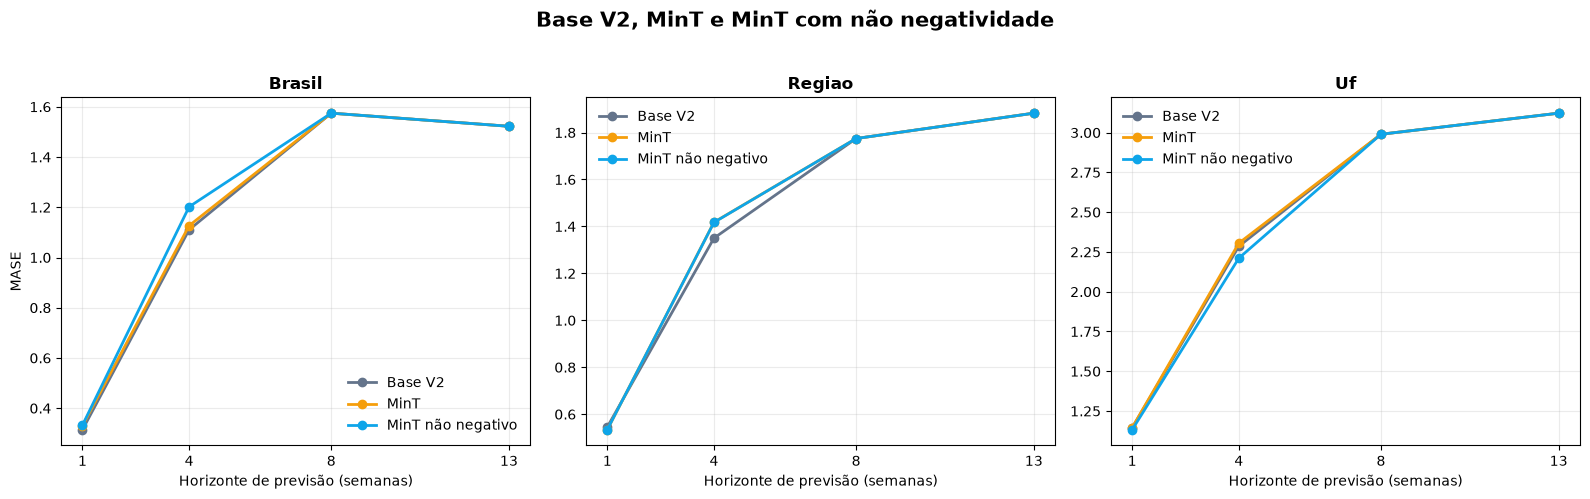

Etapa 36 concluída.
Previsões MinT não negativas: 7,656
Previsões negativas finais: 0
Resultados: ..\..\execucao_local_vsr\saidas\etapa_36_mint_nao_negativo


,horizonte_semanas,shrinkage_oas,piso_desvio_erro,condicao_covariancia_w,condicao_matriz_interna,erro_maximo_projecao
0,1,0.529121,0.477837,9360.857991,1727.570280,2.092770e-14
1,4,0.376684,0.604972,43854.177362,11563.839065,1.674216e-13
2,8,0.238559,0.426599,155807.366813,61379.843920,2.624567e-13
3,13,0.240699,0.606941,82546.610610,31631.679048,8.637535e-14


,horizonte_semanas,cortes,restricoes_ativas,otimizacoes_convergidas,media_iteracoes,aumento_medio_custo,maior_aumento_custo
0,1,58,48,58,8.620690,4.830303e-02,4.518384e-01
1,4,58,53,58,8.051724,1.423183e+00,1.854621e+01
2,8,58,0,58,0.000000,3.926406e-27,1.454204e-25
3,13,58,0,58,0.000000,4.986189e-28,1.549137e-26


,nivel_agregado,comparacoes,diferenca_absoluta_maxima,comparacoes_coerentes,percentual_coerente
0,BRASIL,232,8.635936e-11,232,100.0
1,REGIAO,1160,8.635426e-11,1160,100.0


,nivel,horizonte_semanas,mae_BASE_V2,mae_MINT_OAS_NAO_NEGATIVO,mae_MINT_OAS_SHRINK,rmse_BASE_V2,rmse_MINT_OAS_NAO_NEGATIVO,rmse_MINT_OAS_SHRINK,mase_BASE_V2,mase_MINT_OAS_NAO_NEGATIVO,mase_MINT_OAS_SHRINK
0,BRASIL,1,49.421366,52.154583,51.669145,76.061587,74.606449,74.230540,0.314634,0.332735,0.330381
1,BRASIL,4,176.102473,190.497413,177.419233,290.842676,299.065193,290.704497,1.110469,1.201840,1.126716
2,BRASIL,8,247.896552,247.896552,247.896552,397.367111,397.367111,397.367111,1.574582,1.574582,1.574582
3,BRASIL,13,236.741379,236.741379,236.741379,371.797614,371.797614,371.797614,1.522343,1.522343,1.522343
4,REGIAO,1,15.994000,15.307056,15.320954,27.623395,26.766943,26.776812,0.545830,0.534567,0.534212
5,REGIAO,4,43.379882,46.114476,46.598369,89.563897,92.135977,92.542416,1.350174,1.417267,1.417936
6,REGIAO,8,58.165517,58.165517,58.165517,116.241900,116.241900,116.241900,1.774511,1.774511,1.774511
7,REGIAO,13,59.589655,59.589655,59.589655,113.966556,113.966556,113.966556,1.882562,1.882562,1.882562
8,UF,1,4.583653,4.410348,4.442971,9.533098,9.215682,9.228161,1.144810,1.132874,1.145652
9,UF,4,12.086845,11.497610,12.160102,29.069521,30.790787,31.716799,2.285409,2.210773,2.305160


,nivel,horizonte_semanas,previsoes,previsoes_ausentes,previsoes_negativas,menor_previsao
0,BRASIL,1,58,0,0,42.288771
1,BRASIL,4,58,0,0,39.910514
2,BRASIL,8,58,0,0,48.000000
3,BRASIL,13,58,0,0,45.000000
4,REGIAO,1,290,0,0,0.005026
5,REGIAO,4,290,0,0,0.000000
6,REGIAO,8,290,0,0,0.000000
7,REGIAO,13,290,0,0,0.000000
8,UF,1,1566,0,0,0.000000
9,UF,4,1566,0,0,0.000000


In [13]:
# ETAPA 36 — MinT com restrição de não negatividade

from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import lsq_linear

BASE_DIR = Path(
    "../../execucao_local_vsr"
)

DIR_HIERARQUIA = (
    BASE_DIR
    / "saidas"
    / "etapa_27_estrutura_hierarquica"
)

DIR_BASE_V2 = (
    BASE_DIR
    / "saidas"
    / "etapa_30_previsoes_base_hierarquicas_v2"
)

DIR_CALIBRACAO = (
    BASE_DIR
    / "saidas"
    / "etapa_34_calibracao_temporal_mint"
)

DIR_MINT = (
    BASE_DIR
    / "saidas"
    / "etapa_35_reconciliacao_mint_shrink"
)

DIR_MASE_AGREGADOS = (
    BASE_DIR
    / "saidas"
    / "etapa_22_metricas_referencias"
)

DIR_MASE_UFS = (
    BASE_DIR
    / "saidas"
    / "etapa_29_referencias_ufs"
)

DIR_RESULTADOS = (
    BASE_DIR
    / "saidas"
    / "etapa_36_mint_nao_negativo"
)

DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)

ARQUIVO_BASE_V2 = (
    DIR_BASE_V2
    / "previsoes_base_hierarquicas_v2.csv"
)

ARQUIVO_ESTRUTURA = (
    DIR_HIERARQUIA
    / "estrutura_nos_hierarquia.csv"
)

ARQUIVO_MATRIZ_S = (
    DIR_HIERARQUIA
    / "matriz_somatoria_hierarquia.csv"
)

ARQUIVO_ERROS_CALIBRACAO = (
    DIR_CALIBRACAO
    / "vetores_erros_calibracao_mint.csv"
)

ARQUIVO_MINT_SEM_RESTRICAO = (
    DIR_MINT
    / "previsoes_mint_shrink.csv"
)

ARQUIVO_ESCALAS_AGREGADOS = (
    DIR_MASE_AGREGADOS
    / "escalas_mase_por_origem.csv"
)

ARQUIVO_ESCALAS_UFS = (
    DIR_MASE_UFS
    / "escalas_mase_ufs_por_origem.csv"
)

for arquivo in [
    ARQUIVO_BASE_V2,
    ARQUIVO_ESTRUTURA,
    ARQUIVO_MATRIZ_S,
    ARQUIVO_ERROS_CALIBRACAO,
    ARQUIVO_MINT_SEM_RESTRICAO,
    ARQUIVO_ESCALAS_AGREGADOS,
    ARQUIVO_ESCALAS_UFS,
]:
    if not arquivo.exists():
        raise FileNotFoundError(
            f"Arquivo necessário não encontrado: {arquivo}"
        )

base_v2 = pd.read_csv(ARQUIVO_BASE_V2)
estrutura = pd.read_csv(ARQUIVO_ESTRUTURA)
matriz_s = pd.read_csv(ARQUIVO_MATRIZ_S)
erros_calibracao = pd.read_csv(
    ARQUIVO_ERROS_CALIBRACAO
)
mint_sem_restricao = pd.read_csv(
    ARQUIVO_MINT_SEM_RESTRICAO
)
escalas_agregados = pd.read_csv(
    ARQUIVO_ESCALAS_AGREGADOS
)
escalas_ufs = pd.read_csv(
    ARQUIVO_ESCALAS_UFS
)

for base in [
    base_v2,
    estrutura,
    matriz_s,
    mint_sem_restricao,
    escalas_agregados,
    escalas_ufs,
]:
    for coluna in ["nivel", "unidade", "regiao"]:
        if coluna in base.columns:
            base[coluna] = (
                base[coluna]
                .astype("string")
                .str.strip()
                .str.upper()
            )

for base in [
    base_v2,
    mint_sem_restricao,
    escalas_agregados,
    escalas_ufs,
]:
    for coluna in ["data_origem", "data_alvo"]:
        if coluna in base.columns:
            base[coluna] = pd.to_datetime(
                base[coluna],
                errors="coerce",
            )

for base in [
    base_v2,
    mint_sem_restricao,
    escalas_agregados,
    escalas_ufs,
]:
    for coluna in [
        "casos_observados",
        "previsao",
        "previsao_reconciliada",
        "horizonte_semanas",
        "escala_mase_sazonal",
    ]:
        if coluna in base.columns:
            base[coluna] = pd.to_numeric(
                base[coluna],
                errors="coerce",
            )

estrutura = estrutura.sort_values(
    "ordem_no"
).reset_index(drop=True)

estrutura["no_hierarquico"] = (
    estrutura["nivel"]
    + "_"
    + estrutura["unidade"]
)

ordem_nos = estrutura[
    "no_hierarquico"
].tolist()

matriz_s["no_hierarquico"] = (
    matriz_s["nivel"]
    + "_"
    + matriz_s["unidade"]
)

matriz_s = (
    matriz_s
    .set_index("no_hierarquico")
    .reindex(ordem_nos)
)

if matriz_s.isna().any().any():
    raise ValueError(
        "A matriz de agregação não corresponde "
        "à estrutura da hierarquia."
    )

COLUNAS_IDENTIFICACAO = [
    "nivel",
    "unidade",
]

ufs = [
    coluna
    for coluna in matriz_s.columns
    if coluna not in COLUNAS_IDENTIFICACAO
]

S = matriz_s[ufs].to_numpy(dtype=float)

if S.shape != (33, 27):
    raise ValueError(
        "A matriz S deveria possuir 33 nós e 27 UFs."
    )

if np.linalg.matrix_rank(S) != 27:
    raise ValueError(
        "A matriz S não possui posto completo."
    )

HORIZONTES = [1, 4, 8, 13]

CHAVE = [
    "nivel",
    "unidade",
    "data_origem",
    "horizonte_semanas",
    "data_alvo",
]

CHAVE_AGREGACAO = [
    "data_origem",
    "horizonte_semanas",
    "data_alvo",
]

if len(base_v2) != 7656:
    raise ValueError(
        "A Base V2 deveria possuir 7.656 previsões."
    )

if base_v2.duplicated(CHAVE).any():
    raise ValueError(
        "Há previsões duplicadas na Base V2."
    )

if base_v2[
    [
        "casos_observados",
        "previsao",
    ]
].isna().any().any():
    raise ValueError(
        "Há valores ausentes na Base V2."
    )

if (base_v2["previsao"] < 0).any():
    raise ValueError(
        "A Base V2 possui previsões negativas."
    )

colunas_erros = [
    coluna
    for coluna in erros_calibracao.columns
    if coluna not in [
        "data_origem",
        "horizonte_semanas",
    ]
]

if colunas_erros != ordem_nos:
    raise ValueError(
        "A ordem dos erros de calibração não "
        "corresponde à estrutura hierárquica."
    )

if erros_calibracao.shape != (156, 35):
    raise ValueError(
        "A calibração deveria possuir 156 vetores."
    )

if erros_calibracao[
    colunas_erros
].isna().any().any():
    raise ValueError(
        "Há valores ausentes nos erros de calibração."
    )

matrizes_g = {}
matrizes_p = {}
matrizes_lsq = {}
diagnosticos_covariancia = []

for horizonte in HORIZONTES:
    erros_horizonte = erros_calibracao.loc[
        erros_calibracao["horizonte_semanas"]
        == horizonte,
        colunas_erros,
    ].to_numpy(dtype=float)

    n_vetores, n_nos = erros_horizonte.shape

    desvios_brutos = erros_horizonte.std(
        axis=0,
        ddof=1,
    )

    desvios_positivos = desvios_brutos[
        desvios_brutos > 1e-12
    ]

    piso_desvio = float(
        np.quantile(desvios_positivos, 0.10)
    )

    desvios_ajustados = np.maximum(
        desvios_brutos,
        piso_desvio,
    )

    erros_padronizados = (
        erros_horizonte
        / desvios_ajustados
    )

    erros_padronizados = (
        erros_padronizados
        - erros_padronizados.mean(
            axis=0,
            keepdims=True,
        )
    )

    covariancia_padronizada = (
        erros_padronizados.T
        @ erros_padronizados
        / n_vetores
    )

    media_diagonal = float(
        np.trace(covariancia_padronizada)
        / n_nos
    )

    media_quadrados = float(
        np.mean(covariancia_padronizada ** 2)
    )

    denominador_oas = (
        (n_vetores + 1)
        * (
            media_quadrados
            - (
                media_diagonal ** 2
                / n_nos
            )
        )
    )

    if denominador_oas <= 1e-15:
        shrinkage_oas = 1.0
    else:
        shrinkage_oas = float(
            np.clip(
                (
                    media_quadrados
                    + media_diagonal ** 2
                )
                / denominador_oas,
                0.0,
                1.0,
            )
        )

    covariancia_shrink = (
        (1.0 - shrinkage_oas)
        * covariancia_padronizada
        + shrinkage_oas
        * media_diagonal
        * np.eye(n_nos)
    )

    W = (
        np.diag(desvios_ajustados)
        @ covariancia_shrink
        @ np.diag(desvios_ajustados)
    )

    W = (W + W.T) / 2

    if np.linalg.eigvalsh(W).min() <= 0:
        raise ValueError(
            "A covariância MinT não ficou positiva definida."
        )

    W_inversa = np.linalg.inv(W)

    matriz_interna = (
        S.T
        @ W_inversa
        @ S
    )

    G = np.linalg.solve(
        matriz_interna,
        S.T @ W_inversa,
    )

    P = S @ G

    erro_projecao = float(
        np.max(np.abs(P @ S - S))
    )

    if erro_projecao > 1e-8:
        raise ValueError(
            "A projeção MinT não preservou a hierarquia."
        )

    fator_cholesky = np.linalg.cholesky(
        W_inversa
    ).T

    A_lsq = fator_cholesky @ S

    matrizes_g[horizonte] = G
    matrizes_p[horizonte] = P
    matrizes_lsq[horizonte] = A_lsq

    diagnosticos_covariancia.append(
        {
            "horizonte_semanas": horizonte,
            "shrinkage_oas": shrinkage_oas,
            "piso_desvio_erro": piso_desvio,
            "condicao_covariancia_w": float(
                np.linalg.cond(W)
            ),
            "condicao_matriz_interna": float(
                np.linalg.cond(matriz_interna)
            ),
            "erro_maximo_projecao": erro_projecao,
        }
    )

diagnosticos_covariancia = pd.DataFrame(
    diagnosticos_covariancia
)

mint_sem_restricao = mint_sem_restricao[
    CHAVE + ["previsao_reconciliada"]
].rename(
    columns={
        "previsao_reconciliada": (
            "previsao_mint_sem_restricao"
        )
    }
)

if len(mint_sem_restricao) != 7656:
    raise ValueError(
        "A etapa 35 não possui 7.656 previsões."
    )

if mint_sem_restricao.duplicated(CHAVE).any():
    raise ValueError(
        "Há previsões MinT sem restrição duplicadas."
    )

registros = []
auditoria_otimizacao = []

for chave_grupo, grupo in base_v2.groupby(
    CHAVE_AGREGACAO,
    sort=False,
):
    data_origem, horizonte, data_alvo = chave_grupo
    horizonte = int(horizonte)

    grupo = grupo.copy()

    grupo["no_hierarquico"] = (
        grupo["nivel"]
        + "_"
        + grupo["unidade"]
    )

    grupo_ordenado = (
        grupo
        .set_index(
            "no_hierarquico",
            drop=False,
        )
        .reindex(ordem_nos)
    )

    if len(grupo_ordenado) != 33:
        raise ValueError(
            "Um corte temporal não possui os 33 nós."
        )

    vetor_base = (
        grupo_ordenado["previsao"]
        .to_numpy(dtype=float)
    )

    G = matrizes_g[horizonte]
    P = matrizes_p[horizonte]
    A_lsq = matrizes_lsq[horizonte]

    previsao_mint_sem_restricao_calculada = (
        P @ vetor_base
    )

    folhas_sem_restricao = G @ vetor_base

    menor_folha_sem_restricao = float(
        folhas_sem_restricao.min()
    )

    vetor_objetivo_lsq = (
        A_lsq @ folhas_sem_restricao
    )

    custo_sem_restricao = float(
        0.5
        * np.sum(
            (
                A_lsq
                @ folhas_sem_restricao
                - vetor_objetivo_lsq
            ) ** 2
        )
    )

    restricao_ativa = (
        menor_folha_sem_restricao < -1e-8
    )

    if not restricao_ativa:
        folhas_nao_negativas = np.maximum(
            folhas_sem_restricao,
            0.0,
        )

        status_otimizacao = (
            "SOLUCAO_SEM_RESTRICAO_JA_VIAVEL"
        )

        sucesso_otimizacao = True
        iteracoes = 0
        optimalidade = 0.0
        mensagem_otimizacao = (
            "A solução MinT sem restrição já era viável."
        )

    else:
        resultado = lsq_linear(
            A_lsq,
            vetor_objetivo_lsq,
            bounds=(0.0, np.inf),
            method="trf",
            tol=1e-10,
            max_iter=2000,
            lsmr_tol="auto",
            verbose=0,
        )

        folhas_nao_negativas = resultado.x

        status_otimizacao = (
            "RESTRICAO_NAO_NEGATIVIDADE_ATIVA"
        )

        sucesso_otimizacao = bool(resultado.success)
        iteracoes = int(
            resultado.nit
            if resultado.nit is not None
            else 0
        )

        optimalidade = float(resultado.optimality)
        mensagem_otimizacao = str(resultado.message)

        if not sucesso_otimizacao:
            raise RuntimeError(
                "A otimização não negativa não convergiu em "
                f"{data_origem.date()}, horizonte {horizonte}."
            )

    if (folhas_nao_negativas < -1e-8).any():
        raise ValueError(
            "A solução possui folhas negativas relevantes."
        )

    folhas_nao_negativas = np.maximum(
        folhas_nao_negativas,
        0.0,
    )

    previsao_nao_negativa = (
        S @ folhas_nao_negativas
    )

    custo_nao_negativo = float(
        0.5
        * np.sum(
            (
                A_lsq
                @ folhas_nao_negativas
                - vetor_objetivo_lsq
            ) ** 2
        )
    )

    if custo_nao_negativo + 1e-8 < custo_sem_restricao:
        raise ValueError(
            "A solução restrita ficou melhor que a "
            "solução sem restrição, o que é impossível."
        )

    grupo_ordenado["previsao_base"] = vetor_base

    grupo_ordenado[
        "previsao_mint_sem_restricao_calculada"
    ] = previsao_mint_sem_restricao_calculada

    grupo_ordenado[
        "previsao_reconciliada"
    ] = previsao_nao_negativa

    grupo_ordenado[
        "metodo_reconciliacao"
    ] = "MINT_OAS_NAO_NEGATIVO"

    registros.append(
        grupo_ordenado.reset_index(drop=True)
    )

    auditoria_otimizacao.append(
        {
            "data_origem": data_origem,
            "horizonte_semanas": horizonte,
            "data_alvo": data_alvo,
            "restricao_ativa": restricao_ativa,
            "status_otimizacao": status_otimizacao,
            "sucesso_otimizacao": sucesso_otimizacao,
            "iteracoes": iteracoes,
            "optimalidade": optimalidade,
            "menor_folha_sem_restricao": (
                menor_folha_sem_restricao
            ),
            "menor_folha_nao_negativa": float(
                folhas_nao_negativas.min()
            ),
            "custo_sem_restricao": custo_sem_restricao,
            "custo_nao_negativo": custo_nao_negativo,
            "aumento_custo_restricao": (
                custo_nao_negativo
                - custo_sem_restricao
            ),
            "mensagem_otimizacao": mensagem_otimizacao,
        }
    )

previsoes = pd.concat(
    registros,
    ignore_index=True,
)

auditoria_otimizacao = pd.DataFrame(
    auditoria_otimizacao
)

if len(previsoes) != 7656:
    raise ValueError(
        "MinT não negativo deveria gerar 7.656 previsões."
    )

if previsoes.duplicated(CHAVE).any():
    raise ValueError(
        "Há previsões MinT não negativas duplicadas."
    )

if previsoes[
    "previsao_reconciliada"
].isna().any():
    raise ValueError(
        "Há previsões MinT não negativas ausentes."
    )

previsoes = previsoes.merge(
    mint_sem_restricao,
    on=CHAVE,
    how="left",
    validate="one_to_one",
)

if previsoes[
    "previsao_mint_sem_restricao"
].isna().any():
    raise ValueError(
        "Não foi possível recuperar o MinT sem restrição."
    )

diferenca_reproducao_mint = float(
    np.max(
        np.abs(
            previsoes[
                "previsao_mint_sem_restricao_calculada"
            ]
            - previsoes[
                "previsao_mint_sem_restricao"
            ]
        )
    )
)

if diferenca_reproducao_mint > 1e-8:
    raise ValueError(
        "A reconstrução do MinT sem restrição "
        "não reproduziu a Etapa 35."
    )

if (previsoes["previsao_reconciliada"] < -1e-8).any():
    raise ValueError(
        "A reconciliação não negativa gerou valores negativos."
    )

previsoes.loc[
    previsoes["previsao_reconciliada"].abs() < 1e-10,
    "previsao_reconciliada",
] = 0.0

previsoes["erro_base"] = (
    previsoes["previsao_base"]
    - previsoes["casos_observados"]
)

previsoes["erro_mint_sem_restricao"] = (
    previsoes["previsao_mint_sem_restricao"]
    - previsoes["casos_observados"]
)

previsoes["erro_mint_nao_negativo"] = (
    previsoes["previsao_reconciliada"]
    - previsoes["casos_observados"]
)

previsoes["erro_absoluto_base"] = (
    previsoes["erro_base"].abs()
)

previsoes["erro_absoluto_mint_sem_restricao"] = (
    previsoes[
        "erro_mint_sem_restricao"
    ].abs()
)

previsoes["erro_absoluto_mint_nao_negativo"] = (
    previsoes[
        "erro_mint_nao_negativo"
    ].abs()
)

previsoes["erro_quadratico_base"] = (
    previsoes["erro_base"] ** 2
)

previsoes["erro_quadratico_mint_sem_restricao"] = (
    previsoes[
        "erro_mint_sem_restricao"
    ] ** 2
)

previsoes["erro_quadratico_mint_nao_negativo"] = (
    previsoes[
        "erro_mint_nao_negativo"
    ] ** 2
)

soma_ufs_brasil = (
    previsoes.loc[
        previsoes["nivel"] == "UF"
    ]
    .groupby(
        CHAVE_AGREGACAO,
        as_index=False,
    )["previsao_reconciliada"]
    .sum()
    .rename(
        columns={
            "previsao_reconciliada": "soma_ufs"
        }
    )
)

previsao_brasil = (
    previsoes.loc[
        previsoes["nivel"] == "BRASIL",
        CHAVE_AGREGACAO + [
            "previsao_reconciliada",
        ],
    ]
    .rename(
        columns={
            "previsao_reconciliada": "previsao_brasil"
        }
    )
)

validacao_brasil = soma_ufs_brasil.merge(
    previsao_brasil,
    on=CHAVE_AGREGACAO,
    how="inner",
)

validacao_brasil["diferenca"] = (
    validacao_brasil["previsao_brasil"]
    - validacao_brasil["soma_ufs"]
)

soma_ufs_regiao = (
    previsoes.loc[
        previsoes["nivel"] == "UF"
    ]
    .groupby(
        CHAVE_AGREGACAO + ["regiao"],
        as_index=False,
    )["previsao_reconciliada"]
    .sum()
    .rename(
        columns={
            "previsao_reconciliada": "soma_ufs"
        }
    )
)

previsao_regiao = (
    previsoes.loc[
        previsoes["nivel"] == "REGIAO",
        CHAVE_AGREGACAO + [
            "unidade",
            "previsao_reconciliada",
        ],
    ]
    .rename(
        columns={
            "unidade": "regiao",
            "previsao_reconciliada": "previsao_regiao",
        }
    )
)

validacao_regioes = soma_ufs_regiao.merge(
    previsao_regiao,
    on=CHAVE_AGREGACAO + ["regiao"],
    how="inner",
)

validacao_regioes["diferenca"] = (
    validacao_regioes["previsao_regiao"]
    - validacao_regioes["soma_ufs"]
)

validacao_coerencia = pd.concat(
    [
        pd.DataFrame(
            {
                "nivel_agregado": "BRASIL",
                "comparacoes": 1,
                "diferenca_absoluta": (
                    validacao_brasil[
                        "diferenca"
                    ].abs()
                ),
            }
        ),
        pd.DataFrame(
            {
                "nivel_agregado": "REGIAO",
                "comparacoes": 1,
                "diferenca_absoluta": (
                    validacao_regioes[
                        "diferenca"
                    ].abs()
                ),
            }
        ),
    ],
    ignore_index=True,
)

validacao_coerencia = (
    validacao_coerencia
    .groupby(
        "nivel_agregado",
        as_index=False,
    )
    .agg(
        comparacoes=("comparacoes", "sum"),
        diferenca_absoluta_maxima=(
            "diferenca_absoluta",
            "max",
        ),
        comparacoes_coerentes=(
            "diferenca_absoluta",
            lambda serie: int(
                np.isclose(serie, 0).sum()
            ),
        ),
    )
)

validacao_coerencia[
    "percentual_coerente"
] = (
    100
    * validacao_coerencia[
        "comparacoes_coerentes"
    ]
    / validacao_coerencia["comparacoes"]
)

if not np.isclose(
    validacao_coerencia[
        "diferenca_absoluta_maxima"
    ],
    0,
    atol=1e-8,
).all():
    raise ValueError(
        "A reconciliação não negativa não ficou coerente."
    )

escalas = pd.concat(
    [
        escalas_agregados,
        escalas_ufs,
    ],
    ignore_index=True,
)

escalas = escalas[
    [
        "nivel",
        "unidade",
        "data_origem",
        "escala_mase_sazonal",
    ]
].copy()

if escalas.duplicated(
    [
        "nivel",
        "unidade",
        "data_origem",
    ]
).any():
    raise ValueError(
        "Há escalas MASE duplicadas."
    )

if (escalas["escala_mase_sazonal"] <= 0).any():
    raise ValueError(
        "Há escalas MASE não positivas."
    )

previsoes = previsoes.merge(
    escalas,
    on=[
        "nivel",
        "unidade",
        "data_origem",
    ],
    how="left",
    validate="many_to_one",
)

if previsoes[
    "escala_mase_sazonal"
].isna().any():
    raise ValueError(
        "Há previsões sem escala MASE."
    )

previsoes["mase_individual_base"] = (
    previsoes["erro_absoluto_base"]
    / previsoes["escala_mase_sazonal"]
)

previsoes[
    "mase_individual_mint_sem_restricao"
] = (
    previsoes[
        "erro_absoluto_mint_sem_restricao"
    ]
    / previsoes["escala_mase_sazonal"]
)

previsoes[
    "mase_individual_mint_nao_negativo"
] = (
    previsoes[
        "erro_absoluto_mint_nao_negativo"
    ]
    / previsoes["escala_mase_sazonal"]
)

def calcular_metricas(base, estrategia):
    mapa = {
        "BASE_V2": (
            "erro_absoluto_base",
            "erro_quadratico_base",
            "mase_individual_base",
        ),
        "MINT_OAS_SHRINK": (
            "erro_absoluto_mint_sem_restricao",
            "erro_quadratico_mint_sem_restricao",
            "mase_individual_mint_sem_restricao",
        ),
        "MINT_OAS_NAO_NEGATIVO": (
            "erro_absoluto_mint_nao_negativo",
            "erro_quadratico_mint_nao_negativo",
            "mase_individual_mint_nao_negativo",
        ),
    }

    coluna_absoluta, coluna_quadratica, coluna_mase = (
        mapa[estrategia]
    )

    resultado = (
        base
        .groupby(
            [
                "nivel",
                "horizonte_semanas",
            ],
            as_index=False,
        )
        .agg(
            avaliacoes=(coluna_absoluta, "size"),
            mae=(coluna_absoluta, "mean"),
            rmse=(
                coluna_quadratica,
                lambda valores: float(
                    np.sqrt(np.mean(valores))
                ),
            ),
            mase=(coluna_mase, "mean"),
        )
    )

    resultado["estrategia"] = estrategia

    return resultado

metricas = pd.concat(
    [
        calcular_metricas(previsoes, "BASE_V2"),
        calcular_metricas(
            previsoes,
            "MINT_OAS_SHRINK",
        ),
        calcular_metricas(
            previsoes,
            "MINT_OAS_NAO_NEGATIVO",
        ),
    ],
    ignore_index=True,
)

comparacao_metricas = metricas.pivot(
    index=[
        "nivel",
        "horizonte_semanas",
    ],
    columns="estrategia",
    values=[
        "mae",
        "rmse",
        "mase",
    ],
).reset_index()

comparacao_metricas.columns = [
    "_".join(
        [
            str(parte)
            for parte in coluna
            if parte != ""
        ]
    ).rstrip("_")
    for coluna in comparacao_metricas.columns
]

auditoria_previsoes = (
    previsoes
    .groupby(
        [
            "nivel",
            "horizonte_semanas",
        ],
        as_index=False,
    )
    .agg(
        previsoes=(
            "previsao_reconciliada",
            "size",
        ),
        previsoes_ausentes=(
            "previsao_reconciliada",
            lambda serie: int(
                serie.isna().sum()
            ),
        ),
        previsoes_negativas=(
            "previsao_reconciliada",
            lambda serie: int(
                serie.lt(-1e-8).sum()
            ),
        ),
        menor_previsao=(
            "previsao_reconciliada",
            "min",
        ),
    )
)

resumo_otimizacao = (
    auditoria_otimizacao
    .groupby(
        "horizonte_semanas",
        as_index=False,
    )
    .agg(
        cortes=("data_origem", "size"),
        restricoes_ativas=(
            "restricao_ativa",
            "sum",
        ),
        otimizacoes_convergidas=(
            "sucesso_otimizacao",
            "sum",
        ),
        media_iteracoes=("iteracoes", "mean"),
        aumento_medio_custo=(
            "aumento_custo_restricao",
            "mean",
        ),
        maior_aumento_custo=(
            "aumento_custo_restricao",
            "max",
        ),
    )
)

fig, eixos = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(16, 4.8),
    sharey=False,
)

for eixo, nivel in zip(
    eixos,
    ["BRASIL", "REGIAO", "UF"],
):
    dados = comparacao_metricas.loc[
        comparacao_metricas["nivel"] == nivel
    ].sort_values("horizonte_semanas")

    eixo.plot(
        dados["horizonte_semanas"],
        dados["mase_BASE_V2"],
        marker="o",
        linewidth=2,
        label="Base V2",
        color="#64748B",
    )

    eixo.plot(
        dados["horizonte_semanas"],
        dados["mase_MINT_OAS_SHRINK"],
        marker="o",
        linewidth=2,
        label="MinT",
        color="#F59E0B",
    )

    eixo.plot(
        dados["horizonte_semanas"],
        dados[
            "mase_MINT_OAS_NAO_NEGATIVO"
        ],
        marker="o",
        linewidth=2,
        label="MinT não negativo",
        color="#0EA5E9",
    )

    eixo.set_title(
        nivel.title(),
        fontweight="bold",
    )

    eixo.set_xlabel(
        "Horizonte de previsão (semanas)"
    )

    eixo.set_xticks(HORIZONTES)
    eixo.grid(alpha=0.25)
    eixo.legend(frameon=False)

eixos[0].set_ylabel("MASE")

fig.suptitle(
    "Base V2, MinT e MinT com não negatividade",
    fontsize=15,
    fontweight="bold",
    y=1.03,
)

fig.tight_layout()

fig.savefig(
    DIR_RESULTADOS
    / "comparacao_base_mint_mint_nao_negativo.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

previsoes.to_csv(
    DIR_RESULTADOS
    / "previsoes_mint_nao_negativo.csv",
    index=False,
)

diagnosticos_covariancia.to_csv(
    DIR_RESULTADOS
    / "diagnostico_covariancia_mint_nao_negativo.csv",
    index=False,
)

auditoria_otimizacao.to_csv(
    DIR_RESULTADOS
    / "auditoria_otimizacao_mint_nao_negativo.csv",
    index=False,
)

resumo_otimizacao.to_csv(
    DIR_RESULTADOS
    / "resumo_otimizacao_mint_nao_negativo.csv",
    index=False,
)

validacao_coerencia.to_csv(
    DIR_RESULTADOS
    / "validacao_coerencia_mint_nao_negativo.csv",
    index=False,
)

metricas.to_csv(
    DIR_RESULTADOS
    / "metricas_base_mint_mint_nao_negativo.csv",
    index=False,
)

comparacao_metricas.to_csv(
    DIR_RESULTADOS
    / "comparacao_base_mint_mint_nao_negativo.csv",
    index=False,
)

auditoria_previsoes.to_csv(
    DIR_RESULTADOS
    / "auditoria_previsoes_mint_nao_negativo.csv",
    index=False,
)

ARQUIVO_ZIP = (
    BASE_DIR
    / "saidas"
    / "etapa_36_mint_nao_negativo.zip"
)

with ZipFile(ARQUIVO_ZIP, "w") as arquivo_zip:
    for arquivo in DIR_RESULTADOS.iterdir():
        arquivo_zip.write(
            arquivo,
            arcname=arquivo.name,
        )

print("Etapa 36 concluída.")
print(
    "Previsões MinT não negativas: "
    f"{len(previsoes):,}"
)
print(
    "Previsões negativas finais: "
    f"{int((previsoes['previsao_reconciliada'] < -1e-8).sum())}"
)
print(f"Resultados: {DIR_RESULTADOS}")

display(diagnosticos_covariancia)
display(resumo_otimizacao)
display(validacao_coerencia)
display(comparacao_metricas)
display(auditoria_previsoes)

## Etapa 37 — Comparação consolidada e política hierárquica proposta

Nesta etapa, reuniremos todos os métodos hierárquicos avaliados: Base V2, bottom-up, top-down global, top-down sazonal, WLS estrutural, MinT com shrinkage e MinT com não negatividade.

A comparação será feita separadamente para Brasil, regiões e UFs nos horizontes de 1, 4, 8 e 13 semanas. Além de MAE, RMSE e MASE, serão avaliadas duas condições operacionais: coerência geográfica e ausência de previsões negativas.

A etapa também construirá uma política hierárquica proposta. Para uma e quatro semanas, ela utilizará MinT não negativo, pois é coerente, operacionalmente viável e melhora as previsões das UFs. Para oito e 13 semanas, utilizará a Base V2, pois ela já é coerente, não negativa e sazonalmente estável.

Essa política será uma recomendação baseada nesta validação. Ela não será apresentada como teste externo independente, pois os mesmos cortes temporais foram utilizados para comparar os métodos.

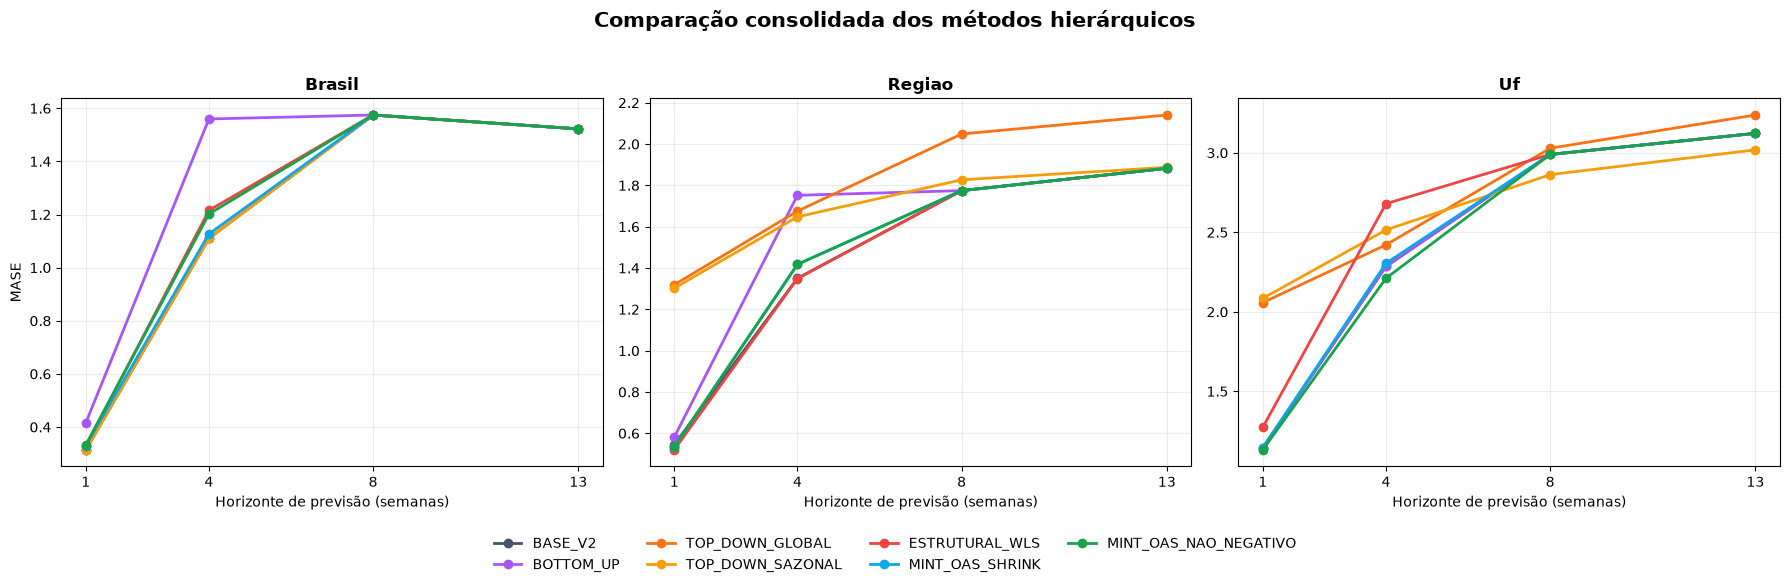

Etapa 37 concluída.
Métodos comparados: 7
Previsões consolidadas: 53,592
Previsões da política proposta: 7,656
Resultados: ..\..\execucao_local_vsr\saidas\etapa_37_comparacao_final_hierarquica


,horizonte_semanas,metodo_proposto,motivo
0,1,MINT_OAS_NAO_NEGATIVO,"Coerente, não negativo e melhor desempenho nas..."
1,4,MINT_OAS_NAO_NEGATIVO,"Coerente, não negativo e melhora as UFs; Brasi..."
2,8,BASE_V2,"Já é coerente, não negativo e sazonalmente est..."
3,13,BASE_V2,"Já é coerente, não negativo e sazonalmente est..."


,estrategia,horizonte_semanas,previsoes_negativas_totais,menor_previsao_global,percentual_coerente_BRASIL,percentual_coerente_REGIAO,diferenca_absoluta_maxima_BRASIL,diferenca_absoluta_maxima_REGIAO,coerente_brasil,coerente_regioes,operacionalmente_viavel
0,BASE_V2,1,0,0.000000e+00,0.0,1.034483,2.203602e+02,1.058947e+02,False,False,False
1,BASE_V2,4,0,0.000000e+00,0.0,0.689655,6.679692e+02,3.780919e+02,False,False,False
2,BASE_V2,8,0,0.000000e+00,100.0,100.000000,0.000000e+00,0.000000e+00,True,True,True
3,BASE_V2,13,0,0.000000e+00,100.0,100.000000,0.000000e+00,0.000000e+00,True,True,True
4,BOTTOM_UP,1,0,0.000000e+00,100.0,100.000000,0.000000e+00,0.000000e+00,True,True,True
5,BOTTOM_UP,4,0,0.000000e+00,100.0,100.000000,0.000000e+00,0.000000e+00,True,True,True
6,BOTTOM_UP,8,0,0.000000e+00,100.0,100.000000,0.000000e+00,0.000000e+00,True,True,True
7,BOTTOM_UP,13,0,0.000000e+00,100.0,100.000000,0.000000e+00,0.000000e+00,True,True,True
8,ESTRUTURAL_WLS,1,257,-7.892231e+00,100.0,100.000000,4.547474e-13,3.410605e-13,True,True,False
9,ESTRUTURAL_WLS,4,333,-2.500037e+01,100.0,100.000000,4.547474e-13,2.273737e-13,True,True,False


,nivel,horizonte_semanas,avaliacoes,mae,rmse,mase
0,BRASIL,1,58,52.154583,74.606449,0.332735
1,BRASIL,4,58,190.497413,299.065193,1.201840
2,BRASIL,8,58,247.896552,397.367111,1.574582
3,BRASIL,13,58,236.741379,371.797614,1.522343
4,REGIAO,1,290,15.307056,26.766943,0.534567
5,REGIAO,4,290,46.114476,92.135977,1.417267
6,REGIAO,8,290,58.165517,116.241900,1.774511
7,REGIAO,13,290,59.589655,113.966556,1.882562
8,UF,1,1566,4.410348,9.215682,1.132874
9,UF,4,1566,11.497610,30.790787,2.210773


,estrategia,nivel_agregado,horizonte_semanas,comparacoes,diferenca_absoluta_maxima,comparacoes_coerentes,percentual_coerente
0,POLITICA_HIERARQUICA_PROPOSTA,BRASIL,1,58,5.866241e-11,58,100.0
1,POLITICA_HIERARQUICA_PROPOSTA,BRASIL,4,58,8.635936e-11,58,100.0
2,POLITICA_HIERARQUICA_PROPOSTA,BRASIL,8,58,0.000000e+00,58,100.0
3,POLITICA_HIERARQUICA_PROPOSTA,BRASIL,13,58,0.000000e+00,58,100.0
4,POLITICA_HIERARQUICA_PROPOSTA,REGIAO,1,290,5.866951e-11,290,100.0
5,POLITICA_HIERARQUICA_PROPOSTA,REGIAO,4,290,8.635426e-11,290,100.0
6,POLITICA_HIERARQUICA_PROPOSTA,REGIAO,8,290,0.000000e+00,290,100.0
7,POLITICA_HIERARQUICA_PROPOSTA,REGIAO,13,290,0.000000e+00,290,100.0


In [14]:
# ETAPA 37 — Comparação consolidada e política hierárquica proposta

from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

BASE_DIR = Path(
    "../../execucao_local_vsr"
)

DIR_BASE_V2 = (
    BASE_DIR
    / "saidas"
    / "etapa_30_previsoes_base_hierarquicas_v2"
)

DIR_BOTTOM_UP = (
    BASE_DIR
    / "saidas"
    / "etapa_31_reconciliacao_bottom_up"
)

DIR_TOP_DOWN = (
    BASE_DIR
    / "saidas"
    / "etapa_32_reconciliacao_top_down"
)

DIR_ESTRUTURAL = (
    BASE_DIR
    / "saidas"
    / "etapa_33_reconciliacao_estrutural"
)

DIR_MINT = (
    BASE_DIR
    / "saidas"
    / "etapa_35_reconciliacao_mint_shrink"
)

DIR_MINT_NN = (
    BASE_DIR
    / "saidas"
    / "etapa_36_mint_nao_negativo"
)

DIR_MASE_AGREGADOS = (
    BASE_DIR
    / "saidas"
    / "etapa_22_metricas_referencias"
)

DIR_MASE_UFS = (
    BASE_DIR
    / "saidas"
    / "etapa_29_referencias_ufs"
)

DIR_RESULTADOS = (
    BASE_DIR
    / "saidas"
    / "etapa_37_comparacao_final_hierarquica"
)

DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)

ARQUIVO_BASE_V2 = (
    DIR_BASE_V2
    / "previsoes_base_hierarquicas_v2.csv"
)

ARQUIVO_BOTTOM_UP = (
    DIR_BOTTOM_UP
    / "previsoes_bottom_up.csv"
)

ARQUIVO_TOP_DOWN = (
    DIR_TOP_DOWN
    / "previsoes_top_down.csv"
)

ARQUIVO_ESTRUTURAL = (
    DIR_ESTRUTURAL
    / "previsoes_reconciliacao_estrutural.csv"
)

ARQUIVO_MINT = (
    DIR_MINT
    / "previsoes_mint_shrink.csv"
)

ARQUIVO_MINT_NN = (
    DIR_MINT_NN
    / "previsoes_mint_nao_negativo.csv"
)

ARQUIVO_ESCALAS_AGREGADOS = (
    DIR_MASE_AGREGADOS
    / "escalas_mase_por_origem.csv"
)

ARQUIVO_ESCALAS_UFS = (
    DIR_MASE_UFS
    / "escalas_mase_ufs_por_origem.csv"
)

for arquivo in [
    ARQUIVO_BASE_V2,
    ARQUIVO_BOTTOM_UP,
    ARQUIVO_TOP_DOWN,
    ARQUIVO_ESTRUTURAL,
    ARQUIVO_MINT,
    ARQUIVO_MINT_NN,
    ARQUIVO_ESCALAS_AGREGADOS,
    ARQUIVO_ESCALAS_UFS,
]:
    if not arquivo.exists():
        raise FileNotFoundError(
            f"Arquivo necessário não encontrado: {arquivo}"
        )

CHAVE = [
    "nivel",
    "unidade",
    "data_origem",
    "horizonte_semanas",
    "data_alvo",
]

CHAVE_AGREGACAO = [
    "data_origem",
    "horizonte_semanas",
    "data_alvo",
]

HORIZONTES = [1, 4, 8, 13]

METODOS_ORDEM = [
    "BASE_V2",
    "BOTTOM_UP",
    "TOP_DOWN_GLOBAL",
    "TOP_DOWN_SAZONAL",
    "ESTRUTURAL_WLS",
    "MINT_OAS_SHRINK",
    "MINT_OAS_NAO_NEGATIVO",
]

def padronizar_base(base):
    base = base.copy()

    for coluna in ["nivel", "unidade", "regiao"]:
        if coluna in base.columns:
            base[coluna] = (
                base[coluna]
                .astype("string")
                .str.strip()
                .str.upper()
            )

    for coluna in ["data_origem", "data_alvo"]:
        if coluna in base.columns:
            base[coluna] = pd.to_datetime(
                base[coluna],
                errors="coerce",
            )

    for coluna in [
        "casos_observados",
        "previsao",
        "previsao_reconciliada",
        "horizonte_semanas",
    ]:
        if coluna in base.columns:
            base[coluna] = pd.to_numeric(
                base[coluna],
                errors="coerce",
            )

    return base

def carregar_metodo(
    arquivo,
    estrategia,
    coluna_previsao,
    filtro_metodo=None,
):
    base = padronizar_base(pd.read_csv(arquivo))

    if filtro_metodo is not None:
        base = base.loc[
            base["metodo_reconciliacao"]
            == filtro_metodo
        ].copy()

    colunas = CHAVE + [
        "regiao",
        "casos_observados",
        coluna_previsao,
    ]

    resultado = base[colunas].copy()

    resultado = resultado.rename(
        columns={
            coluna_previsao: "previsao_final"
        }
    )

    resultado["estrategia"] = estrategia

    if len(resultado) != 7656:
        raise ValueError(
            f"{estrategia} deveria possuir "
            "7.656 previsões."
        )

    if resultado.duplicated(CHAVE).any():
        raise ValueError(
            f"{estrategia} possui previsões duplicadas."
        )

    if resultado[
        [
            "casos_observados",
            "previsao_final",
        ]
    ].isna().any().any():
        raise ValueError(
            f"{estrategia} possui valores ausentes."
        )

    return resultado

base_v2 = carregar_metodo(
    ARQUIVO_BASE_V2,
    "BASE_V2",
    "previsao",
)

bottom_up = carregar_metodo(
    ARQUIVO_BOTTOM_UP,
    "BOTTOM_UP",
    "previsao_reconciliada",
)

top_down_global = carregar_metodo(
    ARQUIVO_TOP_DOWN,
    "TOP_DOWN_GLOBAL",
    "previsao_reconciliada",
    filtro_metodo="TOP_DOWN_GLOBAL",
)

top_down_sazonal = carregar_metodo(
    ARQUIVO_TOP_DOWN,
    "TOP_DOWN_SAZONAL",
    "previsao_reconciliada",
    filtro_metodo="TOP_DOWN_SAZONAL",
)

estrutural = carregar_metodo(
    ARQUIVO_ESTRUTURAL,
    "ESTRUTURAL_WLS",
    "previsao_reconciliada",
)

mint = carregar_metodo(
    ARQUIVO_MINT,
    "MINT_OAS_SHRINK",
    "previsao_reconciliada",
)

mint_nao_negativo = carregar_metodo(
    ARQUIVO_MINT_NN,
    "MINT_OAS_NAO_NEGATIVO",
    "previsao_reconciliada",
)

previsoes = pd.concat(
    [
        base_v2,
        bottom_up,
        top_down_global,
        top_down_sazonal,
        estrutural,
        mint,
        mint_nao_negativo,
    ],
    ignore_index=True,
)

referencia_chaves = base_v2[
    CHAVE + ["casos_observados"]
].rename(
    columns={
        "casos_observados": (
            "casos_observados_referencia"
        )
    }
)

for estrategia, grupo in previsoes.groupby(
    "estrategia"
):
    comparacao = grupo.merge(
        referencia_chaves,
        on=CHAVE,
        how="left",
        validate="one_to_one",
    )

    if comparacao[
        "casos_observados_referencia"
    ].isna().any():
        raise ValueError(
            f"{estrategia} possui chaves diferentes "
            "da Base V2."
        )

    if not np.isclose(
        comparacao["casos_observados"],
        comparacao[
            "casos_observados_referencia"
        ],
        atol=1e-10,
    ).all():
        raise ValueError(
            f"{estrategia} possui alvos observados "
            "diferentes da Base V2."
        )

escalas_agregados = padronizar_base(
    pd.read_csv(ARQUIVO_ESCALAS_AGREGADOS)
)

escalas_ufs = padronizar_base(
    pd.read_csv(ARQUIVO_ESCALAS_UFS)
)

escalas = pd.concat(
    [
        escalas_agregados,
        escalas_ufs,
    ],
    ignore_index=True,
)

escalas = escalas[
    [
        "nivel",
        "unidade",
        "data_origem",
        "escala_mase_sazonal",
    ]
].copy()

if escalas.duplicated(
    [
        "nivel",
        "unidade",
        "data_origem",
    ]
).any():
    raise ValueError(
        "Há escalas MASE duplicadas."
    )

if (escalas["escala_mase_sazonal"] <= 0).any():
    raise ValueError(
        "Há escalas MASE não positivas."
    )

previsoes = previsoes.merge(
    escalas,
    on=[
        "nivel",
        "unidade",
        "data_origem",
    ],
    how="left",
    validate="many_to_one",
)

if previsoes[
    "escala_mase_sazonal"
].isna().any():
    raise ValueError(
        "Há previsões sem escala MASE."
    )

previsoes["erro"] = (
    previsoes["previsao_final"]
    - previsoes["casos_observados"]
)

previsoes["erro_absoluto"] = (
    previsoes["erro"].abs()
)

previsoes["erro_quadratico"] = (
    previsoes["erro"] ** 2
)

previsoes["mase_individual"] = (
    previsoes["erro_absoluto"]
    / previsoes["escala_mase_sazonal"]
)

metricas = (
    previsoes
    .groupby(
        [
            "estrategia",
            "nivel",
            "horizonte_semanas",
        ],
        as_index=False,
    )
    .agg(
        avaliacoes=("erro", "size"),
        mae=("erro_absoluto", "mean"),
        rmse=(
            "erro_quadratico",
            lambda valores: float(
                np.sqrt(np.mean(valores))
            ),
        ),
        mase=("mase_individual", "mean"),
    )
)

metricas["estrategia"] = pd.Categorical(
    metricas["estrategia"],
    categories=METODOS_ORDEM,
    ordered=True,
)

metricas = metricas.sort_values(
    [
        "nivel",
        "horizonte_semanas",
        "mase",
    ]
).reset_index(drop=True)

metricas["ranking_mase"] = (
    metricas
    .groupby(
        [
            "nivel",
            "horizonte_semanas",
        ]
    )["mase"]
    .rank(
        method="min",
        ascending=True,
    )
    .astype(int)
)

def calcular_coerencia(base):
    chave_metodo = ["estrategia"] + CHAVE_AGREGACAO

    soma_ufs_brasil = (
        base.loc[
            base["nivel"] == "UF"
        ]
        .groupby(
            chave_metodo,
            as_index=False,
        )["previsao_final"]
        .sum()
        .rename(
            columns={
                "previsao_final": "soma_ufs"
            }
        )
    )

    previsao_brasil = (
        base.loc[
            base["nivel"] == "BRASIL",
            chave_metodo + ["previsao_final"],
        ]
        .rename(
            columns={
                "previsao_final": "previsao_agregada"
            }
        )
    )

    coerencia_brasil = soma_ufs_brasil.merge(
        previsao_brasil,
        on=chave_metodo,
        how="inner",
        validate="one_to_one",
    )

    coerencia_brasil["nivel_agregado"] = "BRASIL"

    soma_ufs_regiao = (
        base.loc[
            base["nivel"] == "UF"
        ]
        .groupby(
            chave_metodo + ["regiao"],
            as_index=False,
        )["previsao_final"]
        .sum()
        .rename(
            columns={
                "previsao_final": "soma_ufs"
            }
        )
    )

    previsao_regiao = (
        base.loc[
            base["nivel"] == "REGIAO",
            chave_metodo + [
                "unidade",
                "previsao_final",
            ],
        ]
        .rename(
            columns={
                "unidade": "regiao",
                "previsao_final": "previsao_agregada",
            }
        )
    )

    coerencia_regiao = soma_ufs_regiao.merge(
        previsao_regiao,
        on=chave_metodo + ["regiao"],
        how="inner",
        validate="one_to_one",
    )

    coerencia_regiao["nivel_agregado"] = "REGIAO"

    coerencia = pd.concat(
        [
            coerencia_brasil,
            coerencia_regiao,
        ],
        ignore_index=True,
    )

    coerencia["diferenca_absoluta"] = (
        (
            coerencia["previsao_agregada"]
            - coerencia["soma_ufs"]
        )
        .abs()
    )

    resumo = (
        coerencia
        .groupby(
            [
                "estrategia",
                "nivel_agregado",
                "horizonte_semanas",
            ],
            as_index=False,
        )
        .agg(
            comparacoes=(
                "diferenca_absoluta",
                "size",
            ),
            diferenca_absoluta_maxima=(
                "diferenca_absoluta",
                "max",
            ),
            comparacoes_coerentes=(
                "diferenca_absoluta",
                lambda valores: int(
                    np.isclose(
                        valores,
                        0,
                        atol=1e-8,
                    ).sum()
                ),
            ),
        )
    )

    resumo["percentual_coerente"] = (
        100
        * resumo["comparacoes_coerentes"]
        / resumo["comparacoes"]
    )

    return coerencia, resumo

coerencia_detalhe, coerencia_resumo = (
    calcular_coerencia(previsoes)
)

negativos = (
    previsoes
    .assign(
        negativo_material=(
            previsoes["previsao_final"] < -1e-8
        )
    )
    .groupby(
        [
            "estrategia",
            "nivel",
            "horizonte_semanas",
        ],
        as_index=False,
    )
    .agg(
        previsoes=("previsao_final", "size"),
        previsoes_negativas=(
            "negativo_material",
            "sum",
        ),
        menor_previsao=(
            "previsao_final",
            "min",
        ),
    )
)

negativos_totais = (
    negativos
    .groupby(
        [
            "estrategia",
            "horizonte_semanas",
        ],
        as_index=False,
    )
    .agg(
        previsoes_negativas_totais=(
            "previsoes_negativas",
            "sum",
        ),
        menor_previsao_global=(
            "menor_previsao",
            "min",
        ),
    )
)

coerencia_pivot = coerencia_resumo.pivot(
    index=[
        "estrategia",
        "horizonte_semanas",
    ],
    columns="nivel_agregado",
    values=[
        "percentual_coerente",
        "diferenca_absoluta_maxima",
    ],
).reset_index()

coerencia_pivot.columns = [
    "_".join(
        [
            str(parte)
            for parte in coluna
            if parte != ""
        ]
    ).rstrip("_")
    for coluna in coerencia_pivot.columns
]

viabilidade = negativos_totais.merge(
    coerencia_pivot,
    on=[
        "estrategia",
        "horizonte_semanas",
    ],
    how="left",
    validate="one_to_one",
)

viabilidade["coerente_brasil"] = (
    viabilidade[
        "percentual_coerente_BRASIL"
    ].eq(100.0)
    & viabilidade[
        "diferenca_absoluta_maxima_BRASIL"
    ].le(1e-8)
)

viabilidade["coerente_regioes"] = (
    viabilidade[
        "percentual_coerente_REGIAO"
    ].eq(100.0)
    & viabilidade[
        "diferenca_absoluta_maxima_REGIAO"
    ].le(1e-8)
)

viabilidade["operacionalmente_viavel"] = (
    viabilidade["coerente_brasil"]
    & viabilidade["coerente_regioes"]
    & viabilidade[
        "previsoes_negativas_totais"
    ].eq(0)
)

politica_por_horizonte = {
    1: "MINT_OAS_NAO_NEGATIVO",
    4: "MINT_OAS_NAO_NEGATIVO",
    8: "BASE_V2",
    13: "BASE_V2",
}

previsoes_politica = previsoes.loc[
    previsoes.apply(
        lambda linha: (
            linha["estrategia"]
            == politica_por_horizonte[
                int(linha["horizonte_semanas"])
            ]
        ),
        axis=1,
    )
].copy()

previsoes_politica["estrategia"] = (
    "POLITICA_HIERARQUICA_PROPOSTA"
)

if len(previsoes_politica) != 7656:
    raise ValueError(
        "A política proposta deveria possuir "
        "7.656 previsões."
    )

coerencia_politica_detalhe, coerencia_politica = (
    calcular_coerencia(previsoes_politica)
)

metricas_politica = (
    previsoes_politica
    .groupby(
        [
            "nivel",
            "horizonte_semanas",
        ],
        as_index=False,
    )
    .agg(
        avaliacoes=("erro", "size"),
        mae=("erro_absoluto", "mean"),
        rmse=(
            "erro_quadratico",
            lambda valores: float(
                np.sqrt(np.mean(valores))
            ),
        ),
        mase=("mase_individual", "mean"),
    )
)

recomendacoes = pd.DataFrame(
    [
        {
            "horizonte_semanas": 1,
            "metodo_proposto": (
                "MINT_OAS_NAO_NEGATIVO"
            ),
            "motivo": (
                "Coerente, não negativo e melhor "
                "desempenho nas UFs; pequeno custo "
                "na previsão nacional."
            ),
        },
        {
            "horizonte_semanas": 4,
            "metodo_proposto": (
                "MINT_OAS_NAO_NEGATIVO"
            ),
            "motivo": (
                "Coerente, não negativo e melhora "
                "as UFs; Brasil e regiões devem ser "
                "interpretados com a perda de precisão."
            ),
        },
        {
            "horizonte_semanas": 8,
            "metodo_proposto": "BASE_V2",
            "motivo": (
                "Já é coerente, não negativo e "
                "sazonalmente estável."
            ),
        },
        {
            "horizonte_semanas": 13,
            "metodo_proposto": "BASE_V2",
            "motivo": (
                "Já é coerente, não negativo e "
                "sazonalmente estável."
            ),
        },
    ]
)

fig, eixos = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(18, 5),
    sharey=False,
)

cores = {
    "BASE_V2": "#475569",
    "BOTTOM_UP": "#A855F7",
    "TOP_DOWN_GLOBAL": "#F97316",
    "TOP_DOWN_SAZONAL": "#F59E0B",
    "ESTRUTURAL_WLS": "#EF4444",
    "MINT_OAS_SHRINK": "#0EA5E9",
    "MINT_OAS_NAO_NEGATIVO": "#16A34A",
}

for eixo, nivel in zip(
    eixos,
    ["BRASIL", "REGIAO", "UF"],
):
    dados_nivel = metricas.loc[
        metricas["nivel"] == nivel
    ]

    for estrategia in METODOS_ORDEM:
        dados = dados_nivel.loc[
            dados_nivel["estrategia"] == estrategia
        ].sort_values("horizonte_semanas")

        eixo.plot(
            dados["horizonte_semanas"],
            dados["mase"],
            marker="o",
            linewidth=2,
            label=estrategia,
            color=cores[estrategia],
        )

    eixo.set_title(
        nivel.title(),
        fontweight="bold",
    )

    eixo.set_xlabel(
        "Horizonte de previsão (semanas)"
    )

    eixo.set_xticks(HORIZONTES)
    eixo.grid(alpha=0.25)

eixos[0].set_ylabel("MASE")

handles, labels = eixos[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=4,
    frameon=False,
    bbox_to_anchor=(0.5, -0.12),
)

fig.suptitle(
    "Comparação consolidada dos métodos hierárquicos",
    fontsize=15,
    fontweight="bold",
    y=1.03,
)

fig.tight_layout()

fig.savefig(
    DIR_RESULTADOS
    / "comparacao_mase_metodos_hierarquicos.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

auditoria_entrada = (
    previsoes
    .groupby(
        "estrategia",
        as_index=False,
    )
    .agg(
        previsoes=("previsao_final", "size"),
        duplicidades=(
            "previsao_final",
            lambda valores: 0
        ),
        valores_ausentes=(
            "previsao_final",
            lambda valores: int(
                valores.isna().sum()
            )
        ),
    )
)

previsoes.to_csv(
    DIR_RESULTADOS
    / "previsoes_consolidadas_hierarquicas.csv",
    index=False,
)

metricas.to_csv(
    DIR_RESULTADOS
    / "metricas_consolidadas_hierarquicas.csv",
    index=False,
)

negativos.to_csv(
    DIR_RESULTADOS
    / "negativos_por_metodo_nivel_horizonte.csv",
    index=False,
)

coerencia_detalhe.to_csv(
    DIR_RESULTADOS
    / "coerencia_detalhada_metodos.csv",
    index=False,
)

coerencia_resumo.to_csv(
    DIR_RESULTADOS
    / "coerencia_resumo_metodos.csv",
    index=False,
)

viabilidade.to_csv(
    DIR_RESULTADOS
    / "viabilidade_operacional_metodos.csv",
    index=False,
)

recomendacoes.to_csv(
    DIR_RESULTADOS
    / "recomendacao_politica_hierarquica.csv",
    index=False,
)

previsoes_politica.to_csv(
    DIR_RESULTADOS
    / "previsoes_politica_hierarquica_proposta.csv",
    index=False,
)

metricas_politica.to_csv(
    DIR_RESULTADOS
    / "metricas_politica_hierarquica_proposta.csv",
    index=False,
)

coerencia_politica_detalhe.to_csv(
    DIR_RESULTADOS
    / "coerencia_detalhada_politica_hierarquica.csv",
    index=False,
)

coerencia_politica.to_csv(
    DIR_RESULTADOS
    / "coerencia_politica_hierarquica.csv",
    index=False,
)

auditoria_entrada.to_csv(
    DIR_RESULTADOS
    / "auditoria_entrada_comparacao_final.csv",
    index=False,
)

ARQUIVO_ZIP = (
    BASE_DIR
    / "saidas"
    / "etapa_37_comparacao_final_hierarquica.zip"
)

with ZipFile(ARQUIVO_ZIP, "w") as arquivo_zip:
    for arquivo in DIR_RESULTADOS.iterdir():
        arquivo_zip.write(
            arquivo,
            arcname=arquivo.name,
        )

print("Etapa 37 concluída.")
print(
    "Métodos comparados: "
    f"{previsoes['estrategia'].nunique()}"
)
print(
    "Previsões consolidadas: "
    f"{len(previsoes):,}"
)
print(
    "Previsões da política proposta: "
    f"{len(previsoes_politica):,}"
)
print(f"Resultados: {DIR_RESULTADOS}")

display(recomendacoes)
display(viabilidade)
display(metricas_politica)
display(coerencia_politica)

## Etapa 38 — Geração da previsão operacional final

Nesta etapa aplicaremos a política definida na comparação final à última semana madura disponível.

Para os horizontes de uma e quatro semanas, usaremos a reconciliação MinT com restrição de não negatividade. Ela produz previsões coerentes entre UFs, regiões e Brasil sem gerar números negativos.

Para oito e 13 semanas, usaremos a Base V2 com referência sazonal. Nesses horizontes ela já é coerente por construção e a reconciliação não trouxe ganho adicional na validação.

O resultado será uma tabela operacional com previsões para 27 UFs, cinco regiões e Brasil. Essas previsões são estimativas e não substituem dados observados futuros.

C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\879880999.py:483: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  + pd.Timedelta(weeks=horizonte)
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\879880999.py:483: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  + pd.Timedelta(weeks=horizonte)
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\879880999.py:483: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  + pd.Timedelta(weeks=horizonte)


C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\879880999.py:483: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  + pd.Timedelta(weeks=horizonte)
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\879880999.py:483: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  + pd.Timedelta(weeks=horizonte)
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\879880999.py:483: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  + pd.Timedelta(weeks=horizonte)
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\87

C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\879880999.py:483: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  + pd.Timedelta(weeks=horizonte)
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\879880999.py:483: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  + pd.Timedelta(weeks=horizonte)
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\879880999.py:483: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  + pd.Timedelta(weeks=horizonte)
C:\Users\joanc\AppData\Local\Temp\ipykernel_28300\87

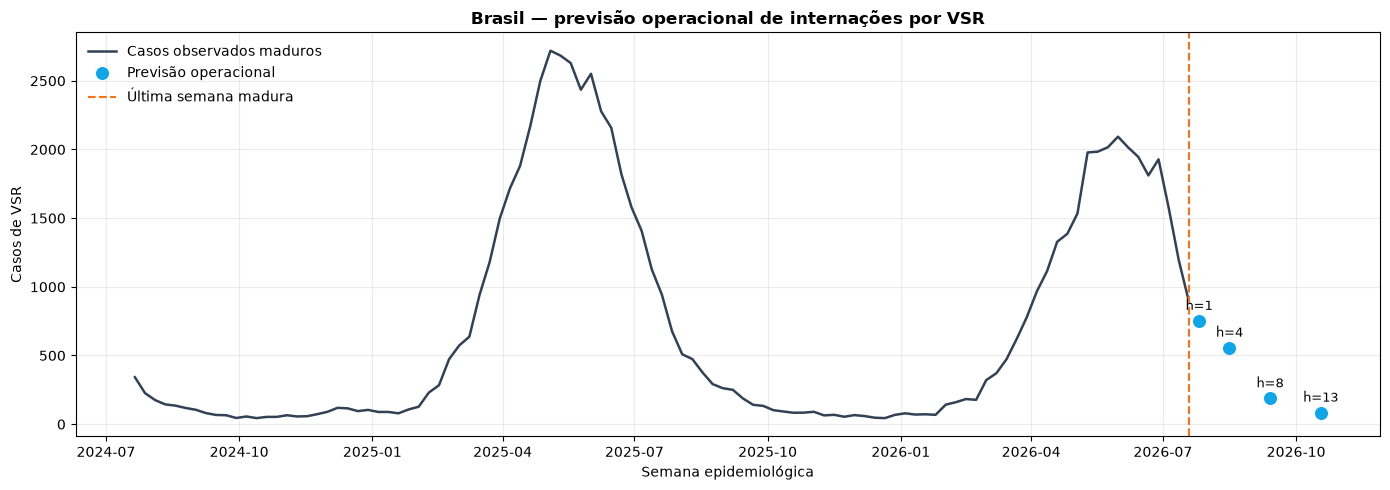

Etapa 38 concluída.
Última semana madura usada: 2026-07-19
Previsões operacionais geradas: 132
Período previsto: 2026-07-26 a 2026-10-18
Resultados: ..\..\execucao_local_vsr\saidas\etapa_38_previsao_operacional_final
Arquivo ZIP: ..\..\execucao_local_vsr\saidas\etapa_38_previsao_operacional_final.zip


,nivel_agregado,horizonte_semanas,comparacoes,diferenca_absoluta_maxima,coerente
0,BRASIL,1,1,1.136868e-13,True
1,BRASIL,4,1,1.136868e-13,True
2,BRASIL,8,1,0.000000e+00,True
3,BRASIL,13,1,0.000000e+00,True
4,REGIAO,1,5,2.842171e-14,True
5,REGIAO,4,5,0.000000e+00,True
6,REGIAO,8,5,0.000000e+00,True
7,REGIAO,13,5,0.000000e+00,True


,nivel,unidade,regiao,data_origem,data_alvo,horizonte_semanas,previsao_base_v2,previsao_final,modelo_base,politica_base,estrategia_final
0,BRASIL,BRASIL,BRASIL,2026-07-19,2026-07-26,1,621.992774,751.218584,ETS_TENDENCIA_AMORTECIDA_HEURISTICO,ETS_AMORTECIDO_AGREGADOS_CURTO,MINT_OAS_NAO_NEGATIVO
33,BRASIL,BRASIL,BRASIL,2026-07-19,2026-08-16,4,5.462647,556.409496,ETS_TENDENCIA_AMORTECIDA_HEURISTICO,ETS_AMORTECIDO_AGREGADOS_CURTO,MINT_OAS_NAO_NEGATIVO
66,BRASIL,BRASIL,BRASIL,2026-07-19,2026-09-13,8,187.000000,187.000000,INGENUO_SAZONAL,INGENUO_SAZONAL_LONGO,BASE_V2_SAZONAL
99,BRASIL,BRASIL,BRASIL,2026-07-19,2026-10-18,13,83.000000,83.000000,INGENUO_SAZONAL,INGENUO_SAZONAL_LONGO,BASE_V2_SAZONAL


In [15]:
# ETAPA 38 — Geração da previsão operacional hierárquica

from pathlib import Path
from zipfile import ZipFile
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import lsq_linear
from statsmodels.tools.sm_exceptions import ConvergenceWarning
from statsmodels.tsa.holtwinters import ExponentialSmoothing

BASE_DIR = Path(
    "../../execucao_local_vsr"
)

ARQUIVO_PAINEL = (
    BASE_DIR
    / "dados_tratados"
    / "painel_vsr_semanal_com_maturidade.parquet"
)

DIR_HIERARQUIA = (
    BASE_DIR
    / "saidas"
    / "etapa_27_estrutura_hierarquica"
)

ARQUIVO_ESTRUTURA = (
    DIR_HIERARQUIA
    / "estrutura_nos_hierarquia.csv"
)

ARQUIVO_MATRIZ_S = (
    DIR_HIERARQUIA
    / "matriz_somatoria_hierarquia.csv"
)

ARQUIVO_ERROS_CALIBRACAO = (
    BASE_DIR
    / "saidas"
    / "etapa_34_calibracao_temporal_mint"
    / "vetores_erros_calibracao_mint.csv"
)

DIR_RESULTADOS = (
    BASE_DIR
    / "saidas"
    / "etapa_38_previsao_operacional_final"
)

DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)

for arquivo in [
    ARQUIVO_PAINEL,
    ARQUIVO_ESTRUTURA,
    ARQUIVO_MATRIZ_S,
    ARQUIVO_ERROS_CALIBRACAO,
]:
    if not arquivo.exists():
        raise FileNotFoundError(
            f"Arquivo necessário não encontrado: {arquivo}"
        )

HORIZONTES = [1, 4, 8, 13]
PERIODO_SAZONAL = 52

painel = pd.read_parquet(ARQUIVO_PAINEL)
estrutura = pd.read_csv(ARQUIVO_ESTRUTURA)
matriz_s = pd.read_csv(ARQUIVO_MATRIZ_S)
erros_calibracao = pd.read_csv(ARQUIVO_ERROS_CALIBRACAO)

for base in [painel, estrutura, matriz_s]:
    for coluna in ["nivel", "unidade", "regiao"]:
        if coluna in base.columns:
            base[coluna] = (
                base[coluna]
                .astype("string")
                .str.strip()
                .str.upper()
            )

painel["semana"] = pd.to_datetime(
    painel["semana"],
    errors="coerce",
)

painel["casos_vsr"] = pd.to_numeric(
    painel["casos_vsr"],
    errors="coerce",
)

if painel["semana"].isna().any():
    raise ValueError("O painel possui semanas ausentes.")

mascara_madura = (
    painel["semana_madura_13s"]
    .fillna(False)
    .astype(bool)
)

painel_maduro = painel.loc[mascara_madura].copy()

if painel_maduro.empty:
    raise ValueError("Não foram encontradas semanas maduras.")

if painel_maduro[["semana", "casos_vsr"]].isna().any().any():
    raise ValueError(
        "O painel maduro possui semana ou quantidade de casos ausente."
    )

estrutura = (
    estrutura
    .sort_values("ordem_no")
    .reset_index(drop=True)
)

estrutura["no_hierarquico"] = (
    estrutura["nivel"]
    + "_"
    + estrutura["unidade"]
)

ordem_nos = estrutura["no_hierarquico"].tolist()

matriz_s["no_hierarquico"] = (
    matriz_s["nivel"]
    + "_"
    + matriz_s["unidade"]
)

matriz_s = (
    matriz_s
    .set_index("no_hierarquico")
    .reindex(ordem_nos)
)

if matriz_s.isna().any().any():
    raise ValueError(
        "A matriz de agregação não corresponde à estrutura."
    )

colunas_identificacao = ["nivel", "unidade"]
ufs = [
    coluna
    for coluna in matriz_s.columns
    if coluna not in colunas_identificacao
]

S = matriz_s[ufs].to_numpy(dtype=float)

if S.shape != (33, 27):
    raise ValueError(
        "A matriz S deveria possuir 33 nós e 27 UFs."
    )

if np.linalg.matrix_rank(S) != 27:
    raise ValueError(
        "A matriz S não possui posto completo."
    )

data_origem = painel_maduro.loc[
    (painel_maduro["nivel"] == "BRASIL")
    & (painel_maduro["unidade"] == "BRASIL"),
    "semana",
].max()

if pd.isna(data_origem):
    raise ValueError(
        "Não foi possível identificar a última semana madura do Brasil."
    )

for nivel, unidade in estrutura[
    ["nivel", "unidade"]
].itertuples(index=False):
    serie = painel_maduro.loc[
        (painel_maduro["nivel"] == nivel)
        & (painel_maduro["unidade"] == unidade)
        & (painel_maduro["semana"] <= data_origem)
    ].sort_values("semana")

    if len(serie) < 2 * PERIODO_SAZONAL:
        raise ValueError(
            f"Série insuficiente para sazonalidade anual: "
            f"{nivel} - {unidade}."
        )

    diferencas = serie["semana"].diff().dt.days.dropna()

    if not diferencas.eq(7).all():
        raise ValueError(
            f"Foram encontradas lacunas em {nivel} - {unidade}."
        )

colunas_erros = [
    coluna
    for coluna in erros_calibracao.columns
    if coluna not in ["data_origem", "horizonte_semanas"]
]

if colunas_erros != ordem_nos:
    raise ValueError(
        "A ordem dos erros de calibração não corresponde "
        "à ordem da hierarquia."
    )

def ajustar_ets_amortecido(valores_treino):
    tentativas = [
        {
            "nome": "PADRAO",
            "argumentos": {
                "optimized": True,
                "remove_bias": False,
                "use_brute": True,
            },
        },
        {
            "nome": "L_BFGS_B",
            "argumentos": {
                "optimized": True,
                "remove_bias": False,
                "use_brute": False,
                "method": "L-BFGS-B",
                "minimize_kwargs": {
                    "options": {"maxiter": 2000}
                },
            },
        },
    ]

    historico = []

    for tentativa in tentativas:
        try:
            modelo = ExponentialSmoothing(
                valores_treino,
                trend="add",
                damped_trend=True,
                seasonal="add",
                seasonal_periods=PERIODO_SAZONAL,
                initialization_method="heuristic",
            )

            with warnings.catch_warnings(record=True) as avisos:
                warnings.simplefilter("always")
                ajuste = modelo.fit(**tentativa["argumentos"])

            avisos_convergencia = [
                aviso
                for aviso in avisos
                if issubclass(
                    aviso.category,
                    ConvergenceWarning,
                )
            ]

            retorno = getattr(ajuste, "mle_retvals", {})
            sucesso_reportado = (
                retorno.get("success", np.nan)
                if isinstance(retorno, dict)
                else np.nan
            )

            convergiu = (
                len(avisos_convergencia) == 0
                and sucesso_reportado is not False
            )

            historico.append(
                {
                    "tentativa": tentativa["nome"],
                    "convergiu": convergiu,
                    "avisos_convergencia": len(
                        avisos_convergencia
                    ),
                    "sucesso_reportado": sucesso_reportado,
                    "mensagens_avisos": " | ".join(
                        sorted(
                            {
                                str(aviso.message)
                                for aviso in avisos
                            }
                        )
                    ),
                }
            )

            if convergiu:
                return ajuste, historico

        except Exception as erro:
            historico.append(
                {
                    "tentativa": tentativa["nome"],
                    "convergiu": False,
                    "avisos_convergencia": np.nan,
                    "sucesso_reportado": np.nan,
                    "mensagens_avisos": str(erro),
                }
            )

    return None, historico

def construir_matriz_lsq_mint(horizonte):
    erros_horizonte = erros_calibracao.loc[
        erros_calibracao["horizonte_semanas"] == horizonte,
        colunas_erros,
    ].to_numpy(dtype=float)

    n_vetores, n_nos = erros_horizonte.shape

    desvios_brutos = erros_horizonte.std(
        axis=0,
        ddof=1,
    )

    desvios_positivos = desvios_brutos[
        desvios_brutos > 1e-12
    ]

    piso_desvio = float(
        np.quantile(desvios_positivos, 0.10)
    )

    desvios_ajustados = np.maximum(
        desvios_brutos,
        piso_desvio,
    )

    erros_padronizados = (
        erros_horizonte / desvios_ajustados
    )

    erros_padronizados = (
        erros_padronizados
        - erros_padronizados.mean(
            axis=0,
            keepdims=True,
        )
    )

    covariancia_padronizada = (
        erros_padronizados.T
        @ erros_padronizados
        / n_vetores
    )

    media_diagonal = float(
        np.trace(covariancia_padronizada) / n_nos
    )

    media_quadrados = float(
        np.mean(covariancia_padronizada ** 2)
    )

    denominador_oas = (
        (n_vetores + 1)
        * (
            media_quadrados
            - (media_diagonal ** 2 / n_nos)
        )
    )

    shrinkage_oas = (
        1.0
        if denominador_oas <= 1e-15
        else float(
            np.clip(
                (
                    media_quadrados
                    + media_diagonal ** 2
                ) / denominador_oas,
                0.0,
                1.0,
            )
        )
    )

    covariancia_shrink = (
        (1.0 - shrinkage_oas)
        * covariancia_padronizada
        + shrinkage_oas
        * media_diagonal
        * np.eye(n_nos)
    )

    W = (
        np.diag(desvios_ajustados)
        @ covariancia_shrink
        @ np.diag(desvios_ajustados)
    )

    W = (W + W.T) / 2

    if np.linalg.eigvalsh(W).min() <= 0:
        raise ValueError(
            "A covariância MinT não ficou positiva definida."
        )

    W_inversa = np.linalg.inv(W)

    matriz_interna = S.T @ W_inversa @ S

    G = np.linalg.solve(
        matriz_interna,
        S.T @ W_inversa,
    )

    fator_cholesky = np.linalg.cholesky(W_inversa).T
    A_lsq = fator_cholesky @ S

    erro_projecao = float(
        np.max(np.abs((S @ G) @ S - S))
    )

    if erro_projecao > 1e-8:
        raise ValueError(
            "A projeção MinT não preservou a hierarquia."
        )

    return A_lsq, G, shrinkage_oas, piso_desvio

matrizes_mint = {
    horizonte: construir_matriz_lsq_mint(horizonte)
    for horizonte in [1, 4]
}

previsoes_base = []
auditoria_ets = []

for no in estrutura.itertuples(index=False):
    nivel = no.nivel
    unidade = no.unidade
    regiao = no.regiao

    serie = painel_maduro.loc[
        (painel_maduro["nivel"] == nivel)
        & (painel_maduro["unidade"] == unidade)
        & (painel_maduro["semana"] <= data_origem)
    ].sort_values("semana")

    valores = serie["casos_vsr"].to_numpy(dtype=float)

    previsao_ets = None
    historico_ets = []

    if nivel in ["BRASIL", "REGIAO"]:
        ajuste, historico_ets = ajustar_ets_amortecido(valores)

        if ajuste is None:
            raise RuntimeError(
                f"ETS não convergiu para {nivel} - {unidade}."
            )

        previsao_ets = np.asarray(
            ajuste.forecast(max(HORIZONTES)),
            dtype=float,
        )

        if (
            len(previsao_ets) != max(HORIZONTES)
            or not np.isfinite(previsao_ets).all()
        ):
            raise ValueError(
                f"ETS inválido para {nivel} - {unidade}."
            )

        for tentativa in historico_ets:
            auditoria_ets.append(
                {
                    "nivel": nivel,
                    "unidade": unidade,
                    "regiao": regiao,
                    "data_origem": data_origem,
                    **tentativa,
                }
            )

    for horizonte in HORIZONTES:
        data_alvo = (
            data_origem
            + pd.Timedelta(weeks=horizonte)
        )

        if nivel in ["BRASIL", "REGIAO"] and horizonte in [1, 4]:
            previsao = max(
                0.0,
                float(previsao_ets[horizonte - 1]),
            )
            modelo_base = (
                "ETS_TENDENCIA_AMORTECIDA_HEURISTICO"
            )
            politica_base = (
                "ETS_AMORTECIDO_AGREGADOS_CURTO"
            )

        elif horizonte in [8, 13]:
            previsao = float(
                valores[-PERIODO_SAZONAL + horizonte - 1]
            )
            modelo_base = "INGENUO_SAZONAL"
            politica_base = (
                "INGENUO_SAZONAL_LONGO"
            )

        else:
            previsao = float(valores[-1])
            modelo_base = "INGENUO"
            politica_base = "INGENUO_UFS_CURTO"

        previsoes_base.append(
            {
                "nivel": nivel,
                "unidade": unidade,
                "regiao": regiao,
                "no_hierarquico": (
                    f"{nivel}_{unidade}"
                ),
                "data_origem": data_origem,
                "data_alvo": data_alvo,
                "horizonte_semanas": horizonte,
                "previsao_base_v2": previsao,
                "modelo_base": modelo_base,
                "politica_base": politica_base,
            }
        )

previsoes_base = pd.DataFrame(previsoes_base)

if len(previsoes_base) != 33 * len(HORIZONTES):
    raise ValueError(
        "A Base V2 operacional deveria possuir 132 previsões."
    )

if previsoes_base["previsao_base_v2"].isna().any():
    raise ValueError(
        "Foram encontradas previsões-base ausentes."
    )

if (previsoes_base["previsao_base_v2"] < 0).any():
    raise ValueError(
        "Foram encontradas previsões-base negativas."
    )

previsoes_finais = []
auditoria_mint = []

for horizonte in HORIZONTES:
    grupo = previsoes_base.loc[
        previsoes_base["horizonte_semanas"] == horizonte
    ].copy()

    grupo = (
        grupo
        .set_index("no_hierarquico", drop=False)
        .reindex(ordem_nos)
    )

    vetor_base = grupo[
        "previsao_base_v2"
    ].to_numpy(dtype=float)

    if horizonte in [1, 4]:
        A_lsq, G, shrinkage_oas, piso_desvio = (
            matrizes_mint[horizonte]
        )

        folhas_sem_restricao = G @ vetor_base
        vetor_objetivo = A_lsq @ folhas_sem_restricao

        restricao_ativa = bool(
            folhas_sem_restricao.min() < -1e-8
        )

        if restricao_ativa:
            resultado = lsq_linear(
                A_lsq,
                vetor_objetivo,
                bounds=(0.0, np.inf),
                method="trf",
                tol=1e-10,
                max_iter=2000,
                lsmr_tol="auto",
                verbose=0,
            )

            if not resultado.success:
                raise RuntimeError(
                    f"MinT não negativo não convergiu "
                    f"no horizonte {horizonte}."
                )

            folhas_finais = resultado.x
            iteracoes = int(resultado.nit or 0)
            optimalidade = float(resultado.optimality)
            status = "RESTRICAO_ATIVA"

        else:
            folhas_finais = np.maximum(
                folhas_sem_restricao,
                0.0,
            )
            iteracoes = 0
            optimalidade = 0.0
            status = "SOLUCAO_SEM_RESTRICAO_VIAVEL"

        vetor_final = S @ folhas_finais
        estrategia = "MINT_OAS_NAO_NEGATIVO"

        auditoria_mint.append(
            {
                "data_origem": data_origem,
                "horizonte_semanas": horizonte,
                "restricao_ativa": restricao_ativa,
                "status_otimizacao": status,
                "sucesso_otimizacao": True,
                "iteracoes": iteracoes,
                "optimalidade": optimalidade,
                "menor_folha_sem_restricao": float(
                    folhas_sem_restricao.min()
                ),
                "menor_folha_final": float(
                    folhas_finais.min()
                ),
                "shrinkage_oas": shrinkage_oas,
                "piso_desvio_erro": piso_desvio,
            }
        )

    else:
        vetor_final = vetor_base.copy()
        estrategia = "BASE_V2_SAZONAL"

    grupo["previsao_final"] = vetor_final
    grupo["estrategia_final"] = estrategia

    previsoes_finais.append(
        grupo.reset_index(drop=True)
    )

previsoes_finais = pd.concat(
    previsoes_finais,
    ignore_index=True,
)

if len(previsoes_finais) != 132:
    raise ValueError(
        "A previsão final deveria possuir 132 linhas."
    )

if previsoes_finais["previsao_final"].isna().any():
    raise ValueError(
        "Há previsões finais ausentes."
    )

if (previsoes_finais["previsao_final"] < -1e-8).any():
    raise ValueError(
        "Há previsões finais negativas."
    )

previsoes_finais["previsao_final"] = (
    previsoes_finais["previsao_final"].clip(lower=0)
)

chave_agregacao = [
    "data_origem",
    "data_alvo",
    "horizonte_semanas",
]

soma_ufs = (
    previsoes_finais.loc[
        previsoes_finais["nivel"] == "UF"
    ]
    .groupby(
        chave_agregacao + ["regiao"],
        as_index=False,
    )["previsao_final"]
    .sum()
    .rename(columns={"previsao_final": "soma_ufs"})
)

previsoes_regiao = (
    previsoes_finais.loc[
        previsoes_finais["nivel"] == "REGIAO",
        chave_agregacao + [
            "unidade",
            "previsao_final",
        ],
    ]
    .rename(
        columns={
            "unidade": "regiao",
            "previsao_final": "previsao_regiao",
        }
    )
)

coerencia_regioes = soma_ufs.merge(
    previsoes_regiao,
    on=chave_agregacao + ["regiao"],
    how="inner",
    validate="one_to_one",
)

coerencia_regioes["diferenca"] = (
    coerencia_regioes["previsao_regiao"]
    - coerencia_regioes["soma_ufs"]
)

soma_brasil = (
    previsoes_finais.loc[
        previsoes_finais["nivel"] == "UF"
    ]
    .groupby(
        chave_agregacao,
        as_index=False,
    )["previsao_final"]
    .sum()
    .rename(columns={"previsao_final": "soma_ufs"})
)

previsao_brasil = (
    previsoes_finais.loc[
        previsoes_finais["nivel"] == "BRASIL",
        chave_agregacao + ["previsao_final"],
    ]
    .rename(
        columns={"previsao_final": "previsao_brasil"}
    )
)

coerencia_brasil = soma_brasil.merge(
    previsao_brasil,
    on=chave_agregacao,
    how="inner",
    validate="one_to_one",
)

coerencia_brasil["diferenca"] = (
    coerencia_brasil["previsao_brasil"]
    - coerencia_brasil["soma_ufs"]
)

validacao = pd.concat(
    [
        coerencia_brasil.assign(
            nivel_agregado="BRASIL",
            unidade="BRASIL",
        )[
            [
                "nivel_agregado",
                "unidade",
                *chave_agregacao,
                "diferenca",
            ]
        ],
        coerencia_regioes.assign(
            nivel_agregado="REGIAO",
            unidade=lambda x: x["regiao"],
        )[
            [
                "nivel_agregado",
                "unidade",
                *chave_agregacao,
                "diferenca",
            ]
        ],
    ],
    ignore_index=True,
)

validacao["diferenca_absoluta"] = (
    validacao["diferenca"].abs()
)

resumo_validacao = (
    validacao
    .groupby(
        ["nivel_agregado", "horizonte_semanas"],
        as_index=False,
    )
    .agg(
        comparacoes=("diferenca", "size"),
        diferenca_absoluta_maxima=(
            "diferenca_absoluta",
            "max",
        ),
        coerente=(
            "diferenca_absoluta",
            lambda x: bool(np.isclose(x, 0.0).all()),
        ),
    )
)

if not resumo_validacao["coerente"].all():
    raise ValueError(
        "A previsão operacional não ficou coerente."
    )

historico_brasil = painel_maduro.loc[
    (painel_maduro["nivel"] == "BRASIL")
    & (painel_maduro["unidade"] == "BRASIL")
    & (
        painel_maduro["semana"]
        >= data_origem - pd.Timedelta(weeks=104)
    )
    & (painel_maduro["semana"] <= data_origem)
].sort_values("semana")

previsao_brasil_final = previsoes_finais.loc[
    previsoes_finais["nivel"] == "BRASIL"
].sort_values("data_alvo")

fig, eixo = plt.subplots(figsize=(14, 5))

eixo.plot(
    historico_brasil["semana"],
    historico_brasil["casos_vsr"],
    color="#334155",
    linewidth=1.8,
    label="Casos observados maduros",
)

eixo.scatter(
    previsao_brasil_final["data_alvo"],
    previsao_brasil_final["previsao_final"],
    color="#0EA5E9",
    s=70,
    zorder=3,
    label="Previsão operacional",
)

for linha in previsao_brasil_final.itertuples():
    eixo.annotate(
        f"h={linha.horizonte_semanas}",
        (linha.data_alvo, linha.previsao_final),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=9,
    )

eixo.axvline(
    data_origem,
    color="#F97316",
    linestyle="--",
    linewidth=1.5,
    label="Última semana madura",
)

eixo.set_title(
    "Brasil — previsão operacional de internações por VSR",
    fontweight="bold",
)

eixo.set_xlabel("Semana epidemiológica")
eixo.set_ylabel("Casos de VSR")
eixo.grid(alpha=0.25)
eixo.legend(frameon=False)
fig.tight_layout()

fig.savefig(
    DIR_RESULTADOS
    / "previsao_operacional_brasil.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

colunas_saida = [
    "nivel",
    "unidade",
    "regiao",
    "data_origem",
    "data_alvo",
    "horizonte_semanas",
    "previsao_base_v2",
    "previsao_final",
    "modelo_base",
    "politica_base",
    "estrategia_final",
]

previsoes_finais = (
    previsoes_finais[colunas_saida]
    .sort_values(
        [
            "horizonte_semanas",
            "nivel",
            "unidade",
        ]
    )
    .reset_index(drop=True)
)

previsoes_finais.to_csv(
    DIR_RESULTADOS
    / "previsoes_operacionais_hierarquicas.csv",
    index=False,
)

pd.DataFrame(auditoria_ets).to_csv(
    DIR_RESULTADOS
    / "auditoria_ets_operacional.csv",
    index=False,
)

pd.DataFrame(auditoria_mint).to_csv(
    DIR_RESULTADOS
    / "auditoria_mint_operacional.csv",
    index=False,
)

validacao.to_csv(
    DIR_RESULTADOS
    / "validacao_coerencia_operacional.csv",
    index=False,
)

resumo_validacao.to_csv(
    DIR_RESULTADOS
    / "resumo_validacao_operacional.csv",
    index=False,
)

arquivo_zip = (
    BASE_DIR
    / "saidas"
    / "etapa_38_previsao_operacional_final.zip"
)

with ZipFile(arquivo_zip, "w") as arquivo:
    for item in DIR_RESULTADOS.iterdir():
        arquivo.write(item, arcname=item.name)

print("Etapa 38 concluída.")
print(f"Última semana madura usada: {data_origem.date()}")
print(
    "Previsões operacionais geradas: "
    f"{len(previsoes_finais):,}"
)
print(
    "Período previsto: "
    f"{previsoes_finais['data_alvo'].min().date()} "
    f"a {previsoes_finais['data_alvo'].max().date()}"
)
print(f"Resultados: {DIR_RESULTADOS}")
print(f"Arquivo ZIP: {arquivo_zip}")

display(resumo_validacao)
display(
    previsoes_finais.loc[
        previsoes_finais["nivel"] == "BRASIL"
    ]
)

## Etapa 38A — Diagnóstico de plausibilidade da previsão operacional

Nesta etapa verificaremos se os ajustes produzidos pela reconciliação MinT não negativa na previsão operacional estão dentro do comportamento observado durante a validação histórica.

O foco será comparar, para cada nível geográfico e horizonte curto, a diferença entre a previsão-base e a previsão reconciliada atual com a distribuição dessas mesmas diferenças nos 58 cortes temporais usados no estudo.

Esse diagnóstico não altera a previsão operacional. Seu objetivo é informar se a reconciliação está em uma faixa historicamente usual ou se merece interpretação cautelosa.

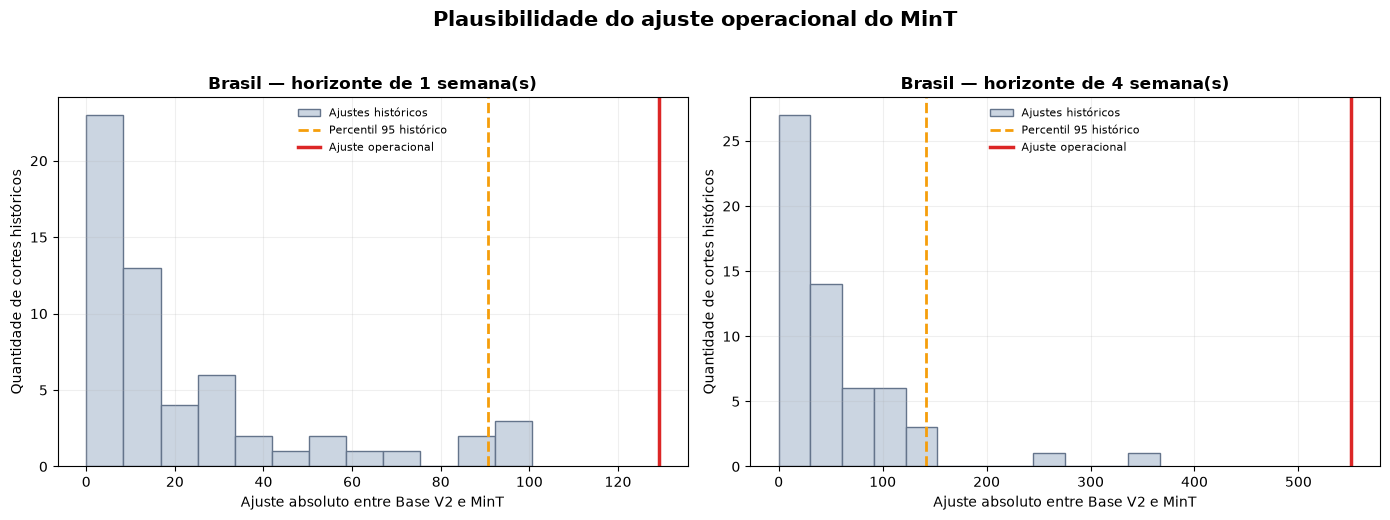

Etapa 38A concluída.
Nós com ajuste acima do percentil 95 histórico: 21
Nós com ajuste acima do máximo histórico: 7
Resultados: ..\..\execucao_local_vsr\saidas\etapa_38a_diagnostico_plausibilidade_operacional
Arquivo ZIP: ..\..\execucao_local_vsr\saidas\etapa_38a_diagnostico_plausibilidade_operacional.zip


,horizonte_semanas,previsao_base_v2,previsao_final,ajuste_operacional,ajuste_p95_historico,ajuste_maximo_historico,percentil_empirico_ajuste,interpretacao
0,1,621.992774,751.218584,129.225809,90.662928,100.563709,100.0,AJUSTE_ACIMA_DO_MAXIMO_HISTORICO
33,4,5.462647,556.409496,550.946849,141.748210,366.597599,100.0,AJUSTE_ACIMA_DO_MAXIMO_HISTORICO


,nivel,horizonte_semanas,nos,ajuste_absoluto_mediano,ajuste_absoluto_maximo,percentil_empirico_mediano,ajustes_acima_p95,ajustes_acima_maximo
0,BRASIL,1,1,129.225809,129.225809,100.000000,1,1
1,BRASIL,4,1,550.946849,550.946849,100.000000,1,1
2,REGIAO,1,5,12.388895,40.891829,84.482759,2,1
3,REGIAO,4,5,38.739553,166.721192,91.379310,1,1
4,UF,1,27,1.233141,70.215736,84.482759,8,2
5,UF,4,27,2.000000,179.000000,82.758621,8,1


In [16]:
# ETAPA 38A — Diagnóstico de plausibilidade dos ajustes operacionais

from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

BASE_DIR = Path(
    "../../execucao_local_vsr"
)

ARQUIVO_VALIDACAO_MINT = (
    BASE_DIR
    / "saidas"
    / "etapa_36_mint_nao_negativo"
    / "previsoes_mint_nao_negativo.csv"
)

ARQUIVO_OPERACIONAL = (
    BASE_DIR
    / "saidas"
    / "etapa_38_previsao_operacional_final"
    / "previsoes_operacionais_hierarquicas.csv"
)

DIR_RESULTADOS = (
    BASE_DIR
    / "saidas"
    / "etapa_38a_diagnostico_plausibilidade_operacional"
)

DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)

for arquivo in [
    ARQUIVO_VALIDACAO_MINT,
    ARQUIVO_OPERACIONAL,
]:
    if not arquivo.exists():
        raise FileNotFoundError(
            f"Arquivo necessário não encontrado: {arquivo}"
        )

HORIZONTES_CURTOS = [1, 4]

validacao_mint = pd.read_csv(
    ARQUIVO_VALIDACAO_MINT
)

operacional = pd.read_csv(
    ARQUIVO_OPERACIONAL
)

for base in [validacao_mint, operacional]:
    for coluna in ["nivel", "unidade", "regiao"]:
        if coluna in base.columns:
            base[coluna] = (
                base[coluna]
                .astype("string")
                .str.strip()
                .str.upper()
            )

    for coluna in [
        "horizonte_semanas",
        "previsao_base",
        "previsao_reconciliada",
        "previsao_base_v2",
        "previsao_final",
    ]:
        if coluna in base.columns:
            base[coluna] = pd.to_numeric(
                base[coluna],
                errors="coerce",
            )

chave_no = [
    "nivel",
    "unidade",
    "horizonte_semanas",
]

historico = validacao_mint.loc[
    validacao_mint["horizonte_semanas"]
    .isin(HORIZONTES_CURTOS)
].copy()

if historico.empty:
    raise ValueError(
        "Não foram encontradas previsões históricas "
        "MinT para os horizontes curtos."
    )

if historico[
    ["previsao_base", "previsao_reconciliada"]
].isna().any().any():
    raise ValueError(
        "Há previsões ausentes no histórico MinT."
    )

historico["ajuste_historico"] = (
    historico["previsao_reconciliada"]
    - historico["previsao_base"]
)

historico["ajuste_absoluto_historico"] = (
    historico["ajuste_historico"].abs()
)

operacional_curto = operacional.loc[
    operacional["horizonte_semanas"]
    .isin(HORIZONTES_CURTOS)
].copy()

if len(operacional_curto) != 66:
    raise ValueError(
        "A previsão operacional curta deveria possuir "
        "66 linhas: 33 nós vezes dois horizontes."
    )

if operacional_curto[
    ["previsao_base_v2", "previsao_final"]
].isna().any().any():
    raise ValueError(
        "Há previsões ausentes na saída operacional."
    )

operacional_curto["ajuste_operacional"] = (
    operacional_curto["previsao_final"]
    - operacional_curto["previsao_base_v2"]
)

operacional_curto["ajuste_absoluto_operacional"] = (
    operacional_curto["ajuste_operacional"].abs()
)

resumo_historico = (
    historico
    .groupby(chave_no, as_index=False)
    .agg(
        avaliacoes_historicas=(
            "ajuste_absoluto_historico",
            "size",
        ),
        ajuste_mediano_historico=(
            "ajuste_absoluto_historico",
            "median",
        ),
        ajuste_p90_historico=(
            "ajuste_absoluto_historico",
            lambda x: x.quantile(0.90),
        ),
        ajuste_p95_historico=(
            "ajuste_absoluto_historico",
            lambda x: x.quantile(0.95),
        ),
        ajuste_maximo_historico=(
            "ajuste_absoluto_historico",
            "max",
        ),
    )
)

diagnostico = operacional_curto.merge(
    resumo_historico,
    on=chave_no,
    how="left",
    validate="one_to_one",
)

if diagnostico.isna().any().any():
    colunas_ausentes = (
        diagnostico.columns[
            diagnostico.isna().any()
        ].tolist()
    )

    raise ValueError(
        "Não foi possível associar a previsão operacional "
        f"ao histórico: {colunas_ausentes}"
    )

percentis_empiricos = []

for linha in diagnostico.itertuples(index=False):
    distribuicao = historico.loc[
        (historico["nivel"] == linha.nivel)
        & (historico["unidade"] == linha.unidade)
        & (
            historico["horizonte_semanas"]
            == linha.horizonte_semanas
        ),
        "ajuste_absoluto_historico",
    ]

    percentil = 100 * (
        distribuicao
        .le(linha.ajuste_absoluto_operacional)
        .mean()
    )

    percentis_empiricos.append(percentil)

diagnostico["percentil_empirico_ajuste"] = (
    percentis_empiricos
)

diagnostico["acima_p95_historico"] = (
    diagnostico["ajuste_absoluto_operacional"]
    > diagnostico["ajuste_p95_historico"]
)

diagnostico["acima_maximo_historico"] = (
    diagnostico["ajuste_absoluto_operacional"]
    > diagnostico["ajuste_maximo_historico"]
)

diagnostico["interpretacao"] = np.select(
    [
        diagnostico["acima_maximo_historico"],
        diagnostico["acima_p95_historico"],
    ],
    [
        "AJUSTE_ACIMA_DO_MAXIMO_HISTORICO",
        "AJUSTE_ACIMA_DO_PERCENTIL_95",
    ],
    default="AJUSTE_DENTRO_DA_FAIXA_HISTORICA",
)

resumo = (
    diagnostico
    .groupby(
        ["nivel", "horizonte_semanas"],
        as_index=False,
    )
    .agg(
        nos=("unidade", "nunique"),
        ajuste_absoluto_mediano=(
            "ajuste_absoluto_operacional",
            "median",
        ),
        ajuste_absoluto_maximo=(
            "ajuste_absoluto_operacional",
            "max",
        ),
        percentil_empirico_mediano=(
            "percentil_empirico_ajuste",
            "median",
        ),
        ajustes_acima_p95=(
            "acima_p95_historico",
            "sum",
        ),
        ajustes_acima_maximo=(
            "acima_maximo_historico",
            "sum",
        ),
    )
)

alertas = diagnostico.loc[
    diagnostico["interpretacao"]
    != "AJUSTE_DENTRO_DA_FAIXA_HISTORICA"
].copy()

brasil = diagnostico.loc[
    diagnostico["nivel"] == "BRASIL"
].sort_values("horizonte_semanas")

fig, eixos = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(14, 5),
    sharey=False,
)

for eixo, horizonte in zip(
    eixos,
    HORIZONTES_CURTOS,
):
    distribuicao = historico.loc[
        (historico["nivel"] == "BRASIL")
        & (
            historico["horizonte_semanas"]
            == horizonte
        ),
        "ajuste_absoluto_historico",
    ]

    ajuste_atual = diagnostico.loc[
        (diagnostico["nivel"] == "BRASIL")
        & (
            diagnostico["horizonte_semanas"]
            == horizonte
        ),
        "ajuste_absoluto_operacional",
    ].iloc[0]

    eixo.hist(
        distribuicao,
        bins=12,
        color="#CBD5E1",
        edgecolor="#64748B",
        label="Ajustes históricos",
    )

    eixo.axvline(
        distribuicao.quantile(0.95),
        color="#F59E0B",
        linestyle="--",
        linewidth=2,
        label="Percentil 95 histórico",
    )

    eixo.axvline(
        ajuste_atual,
        color="#DC2626",
        linewidth=2.5,
        label="Ajuste operacional",
    )

    eixo.set_title(
        f"Brasil — horizonte de {horizonte} semana(s)",
        fontweight="bold",
    )

    eixo.set_xlabel(
        "Ajuste absoluto entre Base V2 e MinT"
    )

    eixo.set_ylabel("Quantidade de cortes históricos")
    eixo.grid(alpha=0.20)
    eixo.legend(frameon=False, fontsize=8)

fig.suptitle(
    "Plausibilidade do ajuste operacional do MinT",
    fontsize=15,
    fontweight="bold",
    y=1.03,
)

fig.tight_layout()

fig.savefig(
    DIR_RESULTADOS
    / "ajuste_operacional_vs_validacao_brasil.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

colunas_saida = [
    "nivel",
    "unidade",
    "regiao",
    "data_origem",
    "data_alvo",
    "horizonte_semanas",
    "previsao_base_v2",
    "previsao_final",
    "ajuste_operacional",
    "ajuste_absoluto_operacional",
    "avaliacoes_historicas",
    "ajuste_mediano_historico",
    "ajuste_p90_historico",
    "ajuste_p95_historico",
    "ajuste_maximo_historico",
    "percentil_empirico_ajuste",
    "acima_p95_historico",
    "acima_maximo_historico",
    "interpretacao",
]

diagnostico = (
    diagnostico[colunas_saida]
    .sort_values(
        [
            "horizonte_semanas",
            "nivel",
            "unidade",
        ]
    )
    .reset_index(drop=True)
)

diagnostico.to_csv(
    DIR_RESULTADOS
    / "diagnostico_ajustes_operacionais.csv",
    index=False,
)

resumo.to_csv(
    DIR_RESULTADOS
    / "resumo_plausibilidade_operacional.csv",
    index=False,
)

alertas.to_csv(
    DIR_RESULTADOS
    / "alertas_plausibilidade_operacional.csv",
    index=False,
)

arquivo_zip = (
    BASE_DIR
    / "saidas"
    / "etapa_38a_diagnostico_plausibilidade_operacional.zip"
)

with ZipFile(arquivo_zip, "w") as arquivo:
    for item in DIR_RESULTADOS.iterdir():
        arquivo.write(item, arcname=item.name)

print("Etapa 38A concluída.")
print(
    "Nós com ajuste acima do percentil 95 histórico: "
    f"{int(diagnostico['acima_p95_historico'].sum())}"
)
print(
    "Nós com ajuste acima do máximo histórico: "
    f"{int(diagnostico['acima_maximo_historico'].sum())}"
)
print(f"Resultados: {DIR_RESULTADOS}")
print(f"Arquivo ZIP: {arquivo_zip}")

display(brasil[
    [
        "horizonte_semanas",
        "previsao_base_v2",
        "previsao_final",
        "ajuste_operacional",
        "ajuste_p95_historico",
        "ajuste_maximo_historico",
        "percentil_empirico_ajuste",
        "interpretacao",
    ]
])

display(resumo)

## Etapa 39 — Faixas empíricas de incerteza das previsões

Nesta etapa construiremos faixas empíricas de incerteza para a política hierárquica final.

As faixas serão calculadas a partir dos erros observados nos 58 cortes temporais de validação. Para cada nó da hierarquia e horizonte, verificaremos quão distante a previsão ficou do valor observado no passado e aplicaremos essa variação à previsão operacional atual.

Serão apresentadas faixas de 80% e 95%. Elas não são intervalos de confiança paramétricos e não garantem coerência entre níveis geográficos; são faixas marginais de referência para comunicar a incerteza de cada previsão individual.

A previsão pontual permanece a mesma. Esta etapa apenas acrescenta informação sobre a amplitude plausível dos resultados.

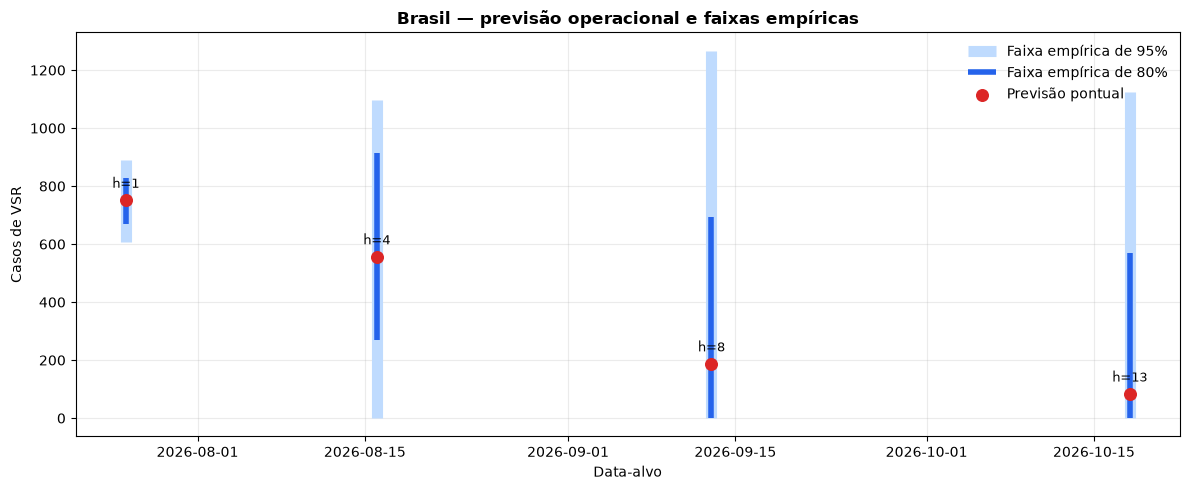

Etapa 39 concluída.
Intervalos gerados: 132
Nós avaliados em cada horizonte: {1: 33, 4: 33, 8: 33, 13: 33}
Resultados: ..\..\execucao_local_vsr\saidas\etapa_39_intervalos_incerteza
Arquivo ZIP: ..\..\execucao_local_vsr\saidas\etapa_39_intervalos_incerteza.zip


,nivel,horizonte_semanas,nos,cobertura_80_loo_media,cobertura_80_loo_minima,cobertura_95_loo_media,cobertura_95_loo_minima,largura_mediana_80,largura_mediana_95
0,BRASIL,1,1,77.586207,77.586207,93.103448,93.103448,161.079023,286.112908
1,BRASIL,4,1,77.586207,77.586207,89.655172,89.655172,645.665535,1097.113302
2,BRASIL,8,1,75.862069,75.862069,93.103448,93.103448,692.900000,1266.875000
3,BRASIL,13,1,77.586207,77.586207,93.103448,93.103448,569.200000,1126.150000
4,REGIAO,1,5,77.586207,77.586207,92.413793,91.379310,48.778120,94.281089
5,REGIAO,4,5,76.896552,75.862069,91.724138,89.655172,153.169278,186.035470
6,REGIAO,8,5,78.275862,77.586207,93.103448,93.103448,113.500000,301.075000
7,REGIAO,13,5,77.241379,75.862069,91.379310,89.655172,142.700000,267.025000
8,UF,1,27,77.586207,75.862069,92.081737,89.655172,7.200903,16.944762
9,UF,4,27,77.458493,75.862069,92.081737,89.655172,12.025164,29.980051


,horizonte_semanas,data_alvo,previsao_final,limite_inferior_80,limite_superior_80,limite_inferior_95,limite_superior_95,cobertura_80_loo,cobertura_95_loo
0,1,2026-07-26,751.218584,667.762219,828.841241,605.566414,891.679322,77.586207,93.103448
33,4,2026-08-16,556.409496,268.209623,913.875158,0.000000,1097.113302,77.586207,89.655172
66,8,2026-09-13,187.000000,0.000000,692.900000,0.000000,1266.875000,75.862069,93.103448
99,13,2026-10-18,83.000000,0.000000,569.200000,0.000000,1126.150000,77.586207,93.103448


In [17]:
# ETAPA 39 — Faixas empíricas de incerteza das previsões operacionais

from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

BASE_DIR = Path(
    "../../execucao_local_vsr"
)

ARQUIVO_VALIDACAO = (
    BASE_DIR
    / "saidas"
    / "etapa_37_comparacao_final_hierarquica"
    / "previsoes_politica_hierarquica_proposta.csv"
)

ARQUIVO_OPERACIONAL = (
    BASE_DIR
    / "saidas"
    / "etapa_38_previsao_operacional_final"
    / "previsoes_operacionais_hierarquicas.csv"
)

DIR_RESULTADOS = (
    BASE_DIR
    / "saidas"
    / "etapa_39_intervalos_incerteza"
)

DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)

for arquivo in [
    ARQUIVO_VALIDACAO,
    ARQUIVO_OPERACIONAL,
]:
    if not arquivo.exists():
        raise FileNotFoundError(
            f"Arquivo necessário não encontrado: {arquivo}"
        )

CHAVE_NO = [
    "nivel",
    "unidade",
    "horizonte_semanas",
]

validacao = pd.read_csv(ARQUIVO_VALIDACAO)
operacional = pd.read_csv(ARQUIVO_OPERACIONAL)

for base in [validacao, operacional]:
    for coluna in ["nivel", "unidade", "regiao"]:
        if coluna in base.columns:
            base[coluna] = (
                base[coluna]
                .astype("string")
                .str.strip()
                .str.upper()
            )

    for coluna in [
        "horizonte_semanas",
        "casos_observados",
        "previsao_final",
        "previsao_base_v2",
    ]:
        if coluna in base.columns:
            base[coluna] = pd.to_numeric(
                base[coluna],
                errors="coerce",
            )

validacao["data_origem"] = pd.to_datetime(
    validacao["data_origem"],
    errors="coerce",
)

operacional["data_origem"] = pd.to_datetime(
    operacional["data_origem"],
    errors="coerce",
)

operacional["data_alvo"] = pd.to_datetime(
    operacional["data_alvo"],
    errors="coerce",
)

colunas_validacao = [
    "nivel",
    "unidade",
    "horizonte_semanas",
    "casos_observados",
    "previsao_final",
]

if validacao[colunas_validacao].isna().any().any():
    raise ValueError(
        "A validação contém valores ausentes necessários "
        "para construir as faixas de incerteza."
    )

if len(validacao) != 7656:
    raise ValueError(
        "A política hierárquica validada deveria possuir "
        "7.656 previsões."
    )

if operacional["previsao_final"].isna().any():
    raise ValueError(
        "A previsão operacional contém valores ausentes."
    )

if len(operacional) != 132:
    raise ValueError(
        "A previsão operacional deveria possuir 132 linhas."
    )

validacao["residuo"] = (
    validacao["casos_observados"]
    - validacao["previsao_final"]
)

contagens = (
    validacao
    .groupby(CHAVE_NO)
    .size()
)

if not contagens.eq(58).all():
    raise ValueError(
        "Cada nó e horizonte deveriam possuir "
        "58 erros de validação."
    )

resumos = []
coberturas_loo = []

for chave, grupo in validacao.groupby(
    CHAVE_NO,
    sort=False,
):
    nivel, unidade, horizonte = chave

    residuos = grupo["residuo"].to_numpy(dtype=float)
    previsoes = grupo["previsao_final"].to_numpy(
        dtype=float
    )
    observados = grupo["casos_observados"].to_numpy(
        dtype=float
    )

    q025, q10, q90, q975 = np.quantile(
        residuos,
        [0.025, 0.10, 0.90, 0.975],
    )

    acertos_80 = []
    acertos_95 = []

    for indice in range(len(grupo)):
        residuos_treino = np.delete(residuos, indice)

        q10_loo, q90_loo = np.quantile(
            residuos_treino,
            [0.10, 0.90],
        )

        q025_loo, q975_loo = np.quantile(
            residuos_treino,
            [0.025, 0.975],
        )

        inferior_80 = max(
            0.0,
            previsoes[indice] + q10_loo,
        )

        superior_80 = previsoes[indice] + q90_loo

        inferior_95 = max(
            0.0,
            previsoes[indice] + q025_loo,
        )

        superior_95 = previsoes[indice] + q975_loo

        acertos_80.append(
            inferior_80
            <= observados[indice]
            <= superior_80
        )

        acertos_95.append(
            inferior_95
            <= observados[indice]
            <= superior_95
        )

    resumos.append(
        {
            "nivel": nivel,
            "unidade": unidade,
            "horizonte_semanas": horizonte,
            "avaliacoes_historicas": len(grupo),
            "quantil_residuo_2_5": q025,
            "quantil_residuo_10": q10,
            "quantil_residuo_90": q90,
            "quantil_residuo_97_5": q975,
        }
    )

    coberturas_loo.append(
        {
            "nivel": nivel,
            "unidade": unidade,
            "horizonte_semanas": horizonte,
            "cobertura_80_loo": 100 * np.mean(acertos_80),
            "cobertura_95_loo": 100 * np.mean(acertos_95),
        }
    )

resumos = pd.DataFrame(resumos)

coberturas_loo = pd.DataFrame(coberturas_loo)

intervalos = operacional.merge(
    resumos,
    on=CHAVE_NO,
    how="left",
    validate="one_to_one",
)

intervalos = intervalos.merge(
    coberturas_loo,
    on=CHAVE_NO,
    how="left",
    validate="one_to_one",
)

colunas_quantitativas = [
    "quantil_residuo_2_5",
    "quantil_residuo_10",
    "quantil_residuo_90",
    "quantil_residuo_97_5",
    "cobertura_80_loo",
    "cobertura_95_loo",
]

if intervalos[colunas_quantitativas].isna().any().any():
    raise ValueError(
        "Não foi possível associar a previsão operacional "
        "aos resíduos históricos."
    )

intervalos["limite_inferior_80"] = np.maximum(
    0.0,
    intervalos["previsao_final"]
    + intervalos["quantil_residuo_10"],
)

intervalos["limite_superior_80"] = np.maximum(
    intervalos["limite_inferior_80"],
    intervalos["previsao_final"]
    + intervalos["quantil_residuo_90"],
)

intervalos["limite_inferior_95"] = np.maximum(
    0.0,
    intervalos["previsao_final"]
    + intervalos["quantil_residuo_2_5"],
)

intervalos["limite_superior_95"] = np.maximum(
    intervalos["limite_inferior_95"],
    intervalos["previsao_final"]
    + intervalos["quantil_residuo_97_5"],
)

intervalos["tipo_intervalo"] = (
    "EMPIRICO_POR_NO_E_HORIZONTE"
)

intervalos["coerencia_dos_intervalos"] = (
    "NAO_GARANTIDA_INTERVALO_MARGINAL"
)

if (
    intervalos["limite_inferior_95"]
    > intervalos["limite_superior_95"]
).any():
    raise ValueError(
        "Foi encontrado intervalo de 95% inválido."
    )

if (
    intervalos["limite_inferior_80"]
    > intervalos["limite_superior_80"]
).any():
    raise ValueError(
        "Foi encontrado intervalo de 80% inválido."
    )

resumo_cobertura = (
    intervalos
    .groupby(
        ["nivel", "horizonte_semanas"],
        as_index=False,
    )
    .agg(
        nos=("unidade", "nunique"),
        cobertura_80_loo_media=(
            "cobertura_80_loo",
            "mean",
        ),
        cobertura_80_loo_minima=(
            "cobertura_80_loo",
            "min",
        ),
        cobertura_95_loo_media=(
            "cobertura_95_loo",
            "mean",
        ),
        cobertura_95_loo_minima=(
            "cobertura_95_loo",
            "min",
        ),
        largura_mediana_80=(
            "limite_superior_80",
            lambda x: np.nan,
        ),
    )
)

larguras = intervalos.assign(
    largura_80=(
        intervalos["limite_superior_80"]
        - intervalos["limite_inferior_80"]
    ),
    largura_95=(
        intervalos["limite_superior_95"]
        - intervalos["limite_inferior_95"]
    ),
)

larguras_resumo = (
    larguras
    .groupby(
        ["nivel", "horizonte_semanas"],
        as_index=False,
    )
    .agg(
        largura_mediana_80=("largura_80", "median"),
        largura_mediana_95=("largura_95", "median"),
    )
)

resumo_cobertura = (
    resumo_cobertura
    .drop(columns=["largura_mediana_80"])
    .merge(
        larguras_resumo,
        on=["nivel", "horizonte_semanas"],
        how="left",
        validate="one_to_one",
    )
)

brasil = intervalos.loc[
    intervalos["nivel"] == "BRASIL"
].sort_values("horizonte_semanas")

fig, eixo = plt.subplots(figsize=(12, 5))

for linha in brasil.itertuples(index=False):
    eixo.vlines(
        linha.data_alvo,
        linha.limite_inferior_95,
        linha.limite_superior_95,
        color="#BFDBFE",
        linewidth=8,
        label="Faixa empírica de 95%"
        if linha.horizonte_semanas == 1
        else None,
    )

    eixo.vlines(
        linha.data_alvo,
        linha.limite_inferior_80,
        linha.limite_superior_80,
        color="#2563EB",
        linewidth=4,
        label="Faixa empírica de 80%"
        if linha.horizonte_semanas == 1
        else None,
    )

eixo.scatter(
    brasil["data_alvo"],
    brasil["previsao_final"],
    color="#DC2626",
    s=70,
    zorder=3,
    label="Previsão pontual",
)

for linha in brasil.itertuples(index=False):
    eixo.annotate(
        f"h={linha.horizonte_semanas}",
        (linha.data_alvo, linha.previsao_final),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=9,
    )

eixo.set_title(
    "Brasil — previsão operacional e faixas empíricas",
    fontweight="bold",
)

eixo.set_xlabel("Data-alvo")
eixo.set_ylabel("Casos de VSR")
eixo.grid(alpha=0.25)
eixo.legend(frameon=False)
fig.tight_layout()

fig.savefig(
    DIR_RESULTADOS
    / "intervalos_incerteza_operacional_brasil.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

colunas_saida = [
    "nivel",
    "unidade",
    "regiao",
    "data_origem",
    "data_alvo",
    "horizonte_semanas",
    "previsao_final",
    "limite_inferior_80",
    "limite_superior_80",
    "limite_inferior_95",
    "limite_superior_95",
    "cobertura_80_loo",
    "cobertura_95_loo",
    "estrategia_final",
    "tipo_intervalo",
    "coerencia_dos_intervalos",
]

intervalos_saida = (
    intervalos[colunas_saida]
    .sort_values(
        [
            "horizonte_semanas",
            "nivel",
            "unidade",
        ]
    )
    .reset_index(drop=True)
)

intervalos_saida.to_csv(
    DIR_RESULTADOS
    / "intervalos_previsao_operacional.csv",
    index=False,
)

resumo_cobertura.to_csv(
    DIR_RESULTADOS
    / "resumo_cobertura_intervalos_loo.csv",
    index=False,
)

arquivo_zip = (
    BASE_DIR
    / "saidas"
    / "etapa_39_intervalos_incerteza.zip"
)

with ZipFile(arquivo_zip, "w") as arquivo:
    for item in DIR_RESULTADOS.iterdir():
        arquivo.write(item, arcname=item.name)

print("Etapa 39 concluída.")
print(
    "Intervalos gerados: "
    f"{len(intervalos_saida):,}"
)
print(
    "Nós avaliados em cada horizonte: "
    f"{intervalos_saida.groupby('horizonte_semanas').size().to_dict()}"
)
print(f"Resultados: {DIR_RESULTADOS}")
print(f"Arquivo ZIP: {arquivo_zip}")

display(resumo_cobertura)
display(brasil[
    [
        "horizonte_semanas",
        "data_alvo",
        "previsao_final",
        "limite_inferior_80",
        "limite_superior_80",
        "limite_inferior_95",
        "limite_superior_95",
        "cobertura_80_loo",
        "cobertura_95_loo",
    ]
])

## Etapa 40 — Consolidação final dos resultados

Nesta etapa reuniremos os resultados produzidos durante a modelagem e avaliação.

O objetivo é criar quadros finais para o relatório e a apresentação: comparação entre a Base V2 e a política hierárquica proposta, decisões por horizonte, previsão operacional do Brasil com faixas de incerteza, cobertura retrospectiva das faixas e alertas de plausibilidade operacional.

Nenhum modelo será ajustado ou alterado nesta etapa. A consolidação apenas organiza as evidências já produzidas e validadas.

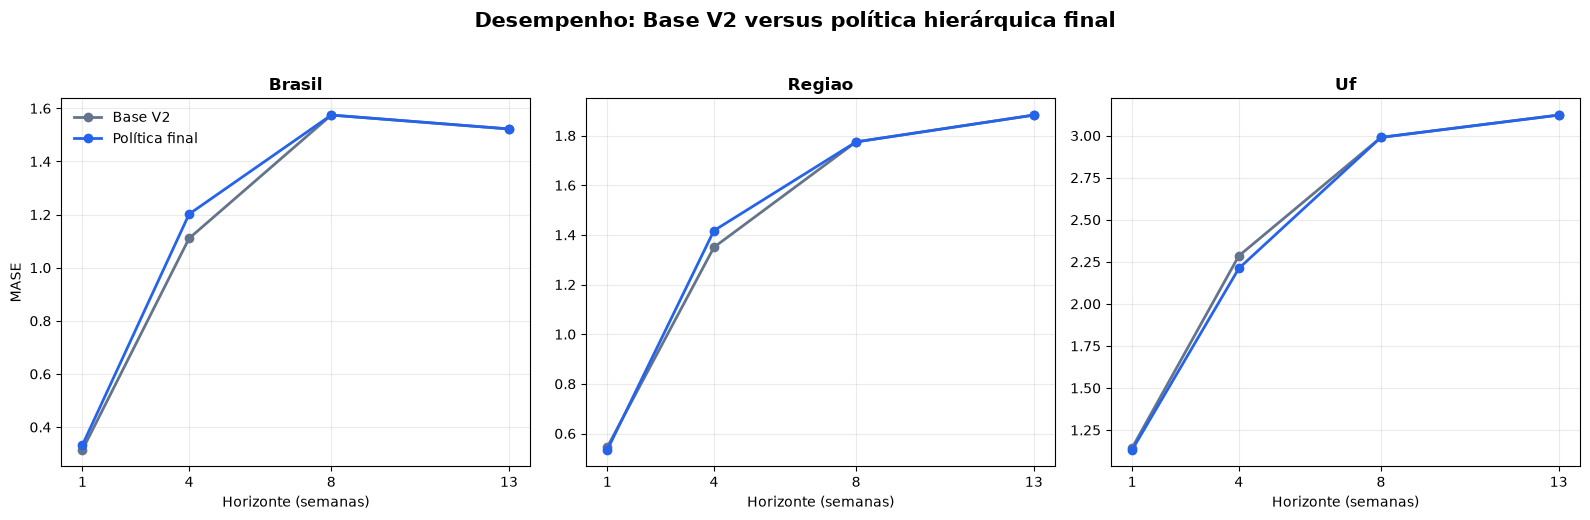

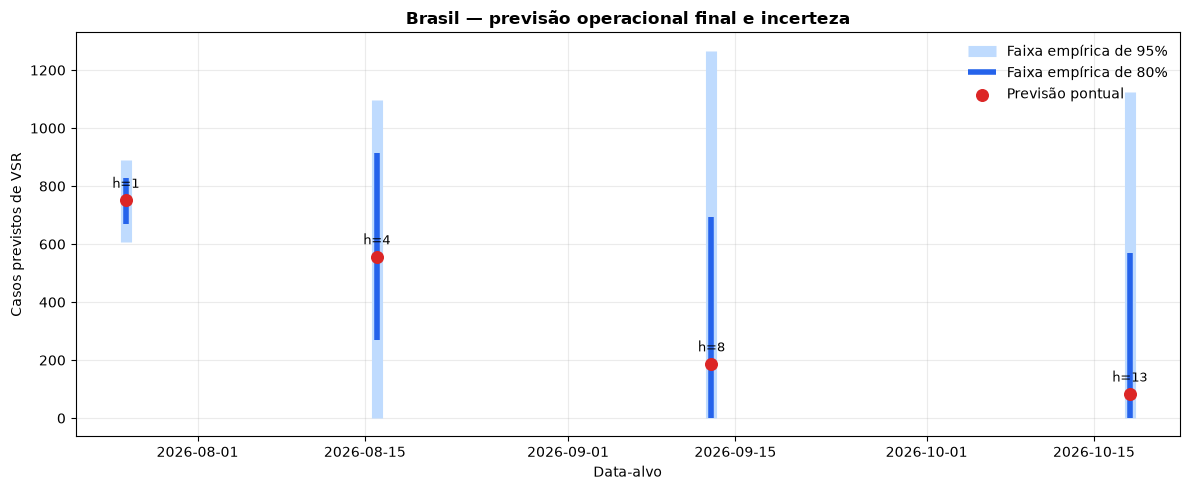

Etapa 40 concluída.
Quadro de desempenho: 12 linhas
Horizontes consolidados: [1, 4, 8, 13]
Alertas operacionais consolidados: 21
Resultados: ..\..\execucao_local_vsr\saidas\etapa_40_consolidacao_final
Arquivo ZIP: ..\..\execucao_local_vsr\saidas\etapa_40_consolidacao_final.zip


,horizonte_semanas,estrategia_adotada,objetivo,justificativa
0,1,MINT_OAS_NAO_NEGATIVO,"Previsão coerente entre UFs, regiões e Brasil","Melhorou o MASE das UFs, preservou não negativ..."
1,4,MINT_OAS_NAO_NEGATIVO,"Previsão coerente entre UFs, regiões e Brasil",Melhorou o MASE das UFs; perdas nos agregados ...
2,8,BASE_V2_SAZONAL,Previsão sazonal estável de médio prazo,Já era coerente e não negativa; reconciliação ...
3,13,BASE_V2_SAZONAL,Planejamento sazonal de prazo mais longo,Já era coerente e não negativa; reconciliação ...


,nivel,horizonte_semanas,mae_base_v2,rmse_base_v2,mase_base_v2,mae_politica,rmse_politica,mase_politica,delta_mae_politica_menos_base,delta_rmse_politica_menos_base,delta_mase_politica_menos_base,leitura
0,BRASIL,1,49.421366,76.061587,0.314634,52.154583,74.606449,0.332735,2.733217,-1.455137,0.018101,BASE_V2_MELHOR
1,BRASIL,4,176.102473,290.842676,1.110469,190.497413,299.065193,1.201840,14.394939,8.222518,0.091371,BASE_V2_MELHOR
2,BRASIL,8,247.896552,397.367111,1.574582,247.896552,397.367111,1.574582,0.000000,0.000000,0.000000,DESEMPENHO_EQUIVALENTE
3,BRASIL,13,236.741379,371.797614,1.522343,236.741379,371.797614,1.522343,0.000000,0.000000,0.000000,DESEMPENHO_EQUIVALENTE
4,REGIAO,1,15.994000,27.623395,0.545830,15.307056,26.766943,0.534567,-0.686944,-0.856452,-0.011262,POLITICA_MELHOR
5,REGIAO,4,43.379882,89.563897,1.350174,46.114476,92.135977,1.417267,2.734595,2.572081,0.067093,BASE_V2_MELHOR
6,REGIAO,8,58.165517,116.241900,1.774511,58.165517,116.241900,1.774511,0.000000,0.000000,0.000000,DESEMPENHO_EQUIVALENTE
7,REGIAO,13,59.589655,113.966556,1.882562,59.589655,113.966556,1.882562,0.000000,0.000000,0.000000,DESEMPENHO_EQUIVALENTE
8,UF,1,4.583653,9.533098,1.144810,4.410348,9.215682,1.132874,-0.173304,-0.317415,-0.011936,POLITICA_MELHOR
9,UF,4,12.086845,29.069521,2.285409,11.497610,30.790787,2.210773,-0.589236,1.721267,-0.074636,POLITICA_MELHOR


,horizonte_semanas,data_alvo,previsao_final,limite_inferior_80,limite_superior_80,limite_inferior_95,limite_superior_95
0,1,2026-07-26,751.218584,667.762219,828.841241,605.566414,891.679322
33,4,2026-08-16,556.409496,268.209623,913.875158,0.000000,1097.113302
66,8,2026-09-13,187.000000,0.000000,692.900000,0.000000,1266.875000
99,13,2026-10-18,83.000000,0.000000,569.200000,0.000000,1126.150000


,nivel,horizonte_semanas,nos,cobertura_80_loo_media,cobertura_80_loo_minima,cobertura_95_loo_media,cobertura_95_loo_minima,largura_mediana_80,largura_mediana_95
0,BRASIL,1,1,77.586207,77.586207,93.103448,93.103448,161.079023,286.112908
1,BRASIL,4,1,77.586207,77.586207,89.655172,89.655172,645.665535,1097.113302
2,BRASIL,8,1,75.862069,75.862069,93.103448,93.103448,692.900000,1266.875000
3,BRASIL,13,1,77.586207,77.586207,93.103448,93.103448,569.200000,1126.150000
4,REGIAO,1,5,77.586207,77.586207,92.413793,91.379310,48.778120,94.281089
5,REGIAO,4,5,76.896552,75.862069,91.724138,89.655172,153.169278,186.035470
6,REGIAO,8,5,78.275862,77.586207,93.103448,93.103448,113.500000,301.075000
7,REGIAO,13,5,77.241379,75.862069,91.379310,89.655172,142.700000,267.025000
8,UF,1,27,77.586207,75.862069,92.081737,89.655172,7.200903,16.944762
9,UF,4,27,77.458493,75.862069,92.081737,89.655172,12.025164,29.980051


,nivel,horizonte_semanas,nos_com_alerta
0,BRASIL,1,1
1,BRASIL,4,1
2,REGIAO,1,2
3,REGIAO,4,1
4,UF,1,8
5,UF,4,8


In [18]:
# ETAPA 40 — Consolidação final dos resultados

from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

BASE_DIR = Path(
    "../../execucao_local_vsr"
)

ARQUIVO_METRICAS_TODAS = (
    BASE_DIR
    / "saidas"
    / "etapa_37_comparacao_final_hierarquica"
    / "metricas_consolidadas_hierarquicas.csv"
)

ARQUIVO_METRICAS_POLITICA = (
    BASE_DIR
    / "saidas"
    / "etapa_37_comparacao_final_hierarquica"
    / "metricas_politica_hierarquica_proposta.csv"
)

ARQUIVO_INTERVALOS = (
    BASE_DIR
    / "saidas"
    / "etapa_39_intervalos_incerteza"
    / "intervalos_previsao_operacional.csv"
)

ARQUIVO_COBERTURA = (
    BASE_DIR
    / "saidas"
    / "etapa_39_intervalos_incerteza"
    / "resumo_cobertura_intervalos_loo.csv"
)

ARQUIVO_ALERTAS = (
    BASE_DIR
    / "saidas"
    / "etapa_38a_diagnostico_plausibilidade_operacional"
    / "alertas_plausibilidade_operacional.csv"
)

DIR_RESULTADOS = (
    BASE_DIR
    / "saidas"
    / "etapa_40_consolidacao_final"
)

DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)

for arquivo in [
    ARQUIVO_METRICAS_TODAS,
    ARQUIVO_METRICAS_POLITICA,
    ARQUIVO_INTERVALOS,
    ARQUIVO_COBERTURA,
    ARQUIVO_ALERTAS,
]:
    if not arquivo.exists():
        raise FileNotFoundError(
            f"Arquivo necessário não encontrado: {arquivo}"
        )

metricas_todas = pd.read_csv(
    ARQUIVO_METRICAS_TODAS
)

metricas_politica = pd.read_csv(
    ARQUIVO_METRICAS_POLITICA
)

intervalos = pd.read_csv(
    ARQUIVO_INTERVALOS
)

cobertura = pd.read_csv(
    ARQUIVO_COBERTURA
)

alertas = pd.read_csv(
    ARQUIVO_ALERTAS
)

for base in [
    metricas_todas,
    metricas_politica,
    intervalos,
    cobertura,
    alertas,
]:
    for coluna in [
        "nivel",
        "unidade",
        "regiao",
        "estrategia",
        "estrategia_final",
    ]:
        if coluna in base.columns:
            base[coluna] = (
                base[coluna]
                .astype("string")
                .str.strip()
                .str.upper()
            )

for base in [
    metricas_todas,
    metricas_politica,
    intervalos,
    cobertura,
    alertas,
]:
    for coluna in [
        "horizonte_semanas",
        "mae",
        "rmse",
        "mase",
        "previsao_final",
        "limite_inferior_80",
        "limite_superior_80",
        "limite_inferior_95",
        "limite_superior_95",
        "cobertura_80_loo",
        "cobertura_95_loo",
    ]:
        if coluna in base.columns:
            base[coluna] = pd.to_numeric(
                base[coluna],
                errors="coerce",
            )

intervalos["data_origem"] = pd.to_datetime(
    intervalos["data_origem"],
    errors="coerce",
)

intervalos["data_alvo"] = pd.to_datetime(
    intervalos["data_alvo"],
    errors="coerce",
)

CHAVE_METRICA = [
    "nivel",
    "horizonte_semanas",
]

base_v2 = metricas_todas.loc[
    metricas_todas["estrategia"] == "BASE_V2",
    CHAVE_METRICA + ["mae", "rmse", "mase"],
].rename(
    columns={
        "mae": "mae_base_v2",
        "rmse": "rmse_base_v2",
        "mase": "mase_base_v2",
    }
)

politica = metricas_politica[
    CHAVE_METRICA + ["mae", "rmse", "mase"]
].rename(
    columns={
        "mae": "mae_politica",
        "rmse": "rmse_politica",
        "mase": "mase_politica",
    }
)

quadro_desempenho = base_v2.merge(
    politica,
    on=CHAVE_METRICA,
    how="inner",
    validate="one_to_one",
)

if len(quadro_desempenho) != 12:
    raise ValueError(
        "O quadro de desempenho deveria possuir "
        "12 combinações de nível e horizonte."
    )

quadro_desempenho["delta_mae_politica_menos_base"] = (
    quadro_desempenho["mae_politica"]
    - quadro_desempenho["mae_base_v2"]
)

quadro_desempenho["delta_rmse_politica_menos_base"] = (
    quadro_desempenho["rmse_politica"]
    - quadro_desempenho["rmse_base_v2"]
)

quadro_desempenho["delta_mase_politica_menos_base"] = (
    quadro_desempenho["mase_politica"]
    - quadro_desempenho["mase_base_v2"]
)

quadro_desempenho["leitura"] = np.select(
    [
        quadro_desempenho[
            "delta_mase_politica_menos_base"
        ] < -1e-10,
        quadro_desempenho[
            "delta_mase_politica_menos_base"
        ] > 1e-10,
    ],
    [
        "POLITICA_MELHOR",
        "BASE_V2_MELHOR",
    ],
    default="DESEMPENHO_EQUIVALENTE",
)

decisoes = pd.DataFrame(
    [
        {
            "horizonte_semanas": 1,
            "estrategia_adotada": "MINT_OAS_NAO_NEGATIVO",
            "objetivo": (
                "Previsão coerente entre UFs, regiões e Brasil"
            ),
            "justificativa": (
                "Melhorou o MASE das UFs, preservou "
                "não negatividade e coerência."
            ),
        },
        {
            "horizonte_semanas": 4,
            "estrategia_adotada": "MINT_OAS_NAO_NEGATIVO",
            "objetivo": (
                "Previsão coerente entre UFs, regiões e Brasil"
            ),
            "justificativa": (
                "Melhorou o MASE das UFs; perdas nos "
                "agregados foram registradas explicitamente."
            ),
        },
        {
            "horizonte_semanas": 8,
            "estrategia_adotada": "BASE_V2_SAZONAL",
            "objetivo": (
                "Previsão sazonal estável de médio prazo"
            ),
            "justificativa": (
                "Já era coerente e não negativa; reconciliação "
                "adicional não trouxe ganho."
            ),
        },
        {
            "horizonte_semanas": 13,
            "estrategia_adotada": "BASE_V2_SAZONAL",
            "objetivo": (
                "Planejamento sazonal de prazo mais longo"
            ),
            "justificativa": (
                "Já era coerente e não negativa; reconciliação "
                "adicional não trouxe ganho."
            ),
        },
    ]
)

brasil_operacional = intervalos.loc[
    intervalos["nivel"] == "BRASIL"
].copy()

if len(brasil_operacional) != 4:
    raise ValueError(
        "A previsão operacional do Brasil deveria "
        "possuir quatro horizontes."
    )

brasil_operacional = brasil_operacional.sort_values(
    "horizonte_semanas"
)

resumo_alertas = (
    alertas
    .groupby(
        [
            "nivel",
            "horizonte_semanas",
            "interpretacao",
        ],
        as_index=False,
    )
    .agg(
        nos_com_alerta=("unidade", "nunique")
    )
)

resumo_alertas_total = (
    alertas
    .groupby(
        ["nivel", "horizonte_semanas"],
        as_index=False,
    )
    .agg(
        nos_com_alerta=("unidade", "nunique")
    )
)

limitacoes = pd.DataFrame(
    [
        {
            "tema": "Seleção da política",
            "descricao": (
                "Modelos e política foram escolhidos usando "
                "os mesmos 58 cortes formais de validação."
            ),
        },
        {
            "tema": "Calibração MinT",
            "descricao": (
                "A covariância dos erros foi calibrada em "
                "período que atravessa a pandemia de COVID-19."
            ),
        },
        {
            "tema": "Previsão operacional",
            "descricao": (
                "A aplicação de 19/07/2026 apresentou "
                "discordância excepcional entre níveis "
                "em uma e quatro semanas."
            ),
        },
        {
            "tema": "Faixas de incerteza",
            "descricao": (
                "As faixas são empíricas e marginais; "
                "seus limites não são necessariamente "
                "coerentes entre os níveis geográficos."
            ),
        },
    ]
)

fig, eixos = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(16, 5),
    sharex=True,
)

for eixo, nivel in zip(
    eixos,
    ["BRASIL", "REGIAO", "UF"],
):
    dados = quadro_desempenho.loc[
        quadro_desempenho["nivel"] == nivel
    ].sort_values("horizonte_semanas")

    eixo.plot(
        dados["horizonte_semanas"],
        dados["mase_base_v2"],
        marker="o",
        linewidth=2,
        color="#64748B",
        label="Base V2",
    )

    eixo.plot(
        dados["horizonte_semanas"],
        dados["mase_politica"],
        marker="o",
        linewidth=2,
        color="#2563EB",
        label="Política final",
    )

    eixo.set_title(
        nivel.title(),
        fontweight="bold",
    )

    eixo.set_xticks([1, 4, 8, 13])
    eixo.set_xlabel("Horizonte (semanas)")
    eixo.grid(alpha=0.25)

eixos[0].set_ylabel("MASE")
eixos[0].legend(frameon=False)

fig.suptitle(
    "Desempenho: Base V2 versus política hierárquica final",
    fontsize=15,
    fontweight="bold",
    y=1.03,
)

fig.tight_layout()

fig.savefig(
    DIR_RESULTADOS
    / "comparacao_mase_base_v2_politica_final.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

fig, eixo = plt.subplots(figsize=(12, 5))

for linha in brasil_operacional.itertuples(index=False):
    eixo.vlines(
        linha.data_alvo,
        linha.limite_inferior_95,
        linha.limite_superior_95,
        color="#BFDBFE",
        linewidth=8,
        label="Faixa empírica de 95%"
        if linha.horizonte_semanas == 1
        else None,
    )

    eixo.vlines(
        linha.data_alvo,
        linha.limite_inferior_80,
        linha.limite_superior_80,
        color="#2563EB",
        linewidth=4,
        label="Faixa empírica de 80%"
        if linha.horizonte_semanas == 1
        else None,
    )

eixo.scatter(
    brasil_operacional["data_alvo"],
    brasil_operacional["previsao_final"],
    color="#DC2626",
    s=70,
    zorder=3,
    label="Previsão pontual",
)

for linha in brasil_operacional.itertuples(index=False):
    eixo.annotate(
        f"h={linha.horizonte_semanas}",
        (linha.data_alvo, linha.previsao_final),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=9,
    )

eixo.set_title(
    "Brasil — previsão operacional final e incerteza",
    fontweight="bold",
)

eixo.set_xlabel("Data-alvo")
eixo.set_ylabel("Casos previstos de VSR")
eixo.grid(alpha=0.25)
eixo.legend(frameon=False)
fig.tight_layout()

fig.savefig(
    DIR_RESULTADOS
    / "previsao_operacional_final_brasil.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

quadro_desempenho = quadro_desempenho.sort_values(
    ["nivel", "horizonte_semanas"]
).reset_index(drop=True)

quadro_desempenho.to_csv(
    DIR_RESULTADOS
    / "quadro_desempenho_politica_final.csv",
    index=False,
)

decisoes.to_csv(
    DIR_RESULTADOS
    / "quadro_decisoes_por_horizonte.csv",
    index=False,
)

brasil_operacional.to_csv(
    DIR_RESULTADOS
    / "quadro_previsao_operacional_brasil.csv",
    index=False,
)

cobertura.to_csv(
    DIR_RESULTADOS
    / "quadro_cobertura_intervalos.csv",
    index=False,
)

resumo_alertas.to_csv(
    DIR_RESULTADOS
    / "quadro_alertas_operacionais.csv",
    index=False,
)

resumo_alertas_total.to_csv(
    DIR_RESULTADOS
    / "quadro_alertas_operacionais_resumo.csv",
    index=False,
)

limitacoes.to_csv(
    DIR_RESULTADOS
    / "quadro_limitacoes_finais.csv",
    index=False,
)

arquivo_zip = (
    BASE_DIR
    / "saidas"
    / "etapa_40_consolidacao_final.zip"
)

with ZipFile(arquivo_zip, "w") as arquivo:
    for item in DIR_RESULTADOS.iterdir():
        arquivo.write(item, arcname=item.name)

print("Etapa 40 concluída.")
print(
    "Quadro de desempenho: "
    f"{len(quadro_desempenho):,} linhas"
)
print(
    "Horizontes consolidados: "
    f"{decisoes['horizonte_semanas'].tolist()}"
)
print(
    "Alertas operacionais consolidados: "
    f"{int(resumo_alertas['nos_com_alerta'].sum())}"
)
print(f"Resultados: {DIR_RESULTADOS}")
print(f"Arquivo ZIP: {arquivo_zip}")

display(decisoes)
display(quadro_desempenho)
display(brasil_operacional[
    [
        "horizonte_semanas",
        "data_alvo",
        "previsao_final",
        "limite_inferior_80",
        "limite_superior_80",
        "limite_inferior_95",
        "limite_superior_95",
    ]
])
display(cobertura)
display(resumo_alertas_total)

## Continuação — política hierárquica final (etapas 41 a 43)

As etapas 37 a 40 deste notebook registram a **política V2** (MinT sobre a Base V2 com ingênuo nas UFs). Elas foram
superadas pelas etapas 41 a 43, em `MODELAGEM_AVALIACAO_3_ETAPA/notebook_politica_final/`:

* **Etapa 41** — modelos para séries intermitentes nas UFs (família Croston, TSB, ADIDA, IMAPA, GLM binomial negativo, LightGBM).
* **Etapa 42** — LightGBM global (33 nós) contra o ETS nos agregados e a Base V4.
* **Etapa 43** — política final, previsão operacional, plausibilidade, faixas de incerteza e quadros finais
  (substitui as saídas das etapas 37 a 40 para a política adotada).

Aquelas etapas usam somente os CSVs de `resultados_scripts/` e o ambiente descrito em `requirements.txt` na raiz.